# Notebook 18: Real Books

**References:** Nasdaq. *Nasdaq TotalView-ITCH 5.0*, data feed specification. Cont, R., Kukanov, A. and Stoikov, S. (2014). The price impact of order book events. *Journal of Financial Econometrics* 12(1), 47-88. Lee, C. M. C. and Ready, M. J. (1991). Inferring trade direction from intraday data. *Journal of Finance* 46(2), 733-746. Easley, D., Lopez de Prado, M. M. and O'Hara, M. (2012). Flow toxicity and liquidity in a high-frequency world. *Review of Financial Studies* 25(5), 1457-1493. Andersen, T. G. and Bondarenko, O. (2014). VPIN and the flash crash. *Journal of Financial Markets* 17, 1-46. Large, J. (2007). Measuring the resiliency of an electronic limit order book. *Journal of Financial Markets* 10(1), 1-25. Gould, M. D. and Bonart, J. (2016). Queue imbalance as a one-tick-ahead price predictor in a limit order book. *Market Microstructure and Liquidity* 2(2), 1650006. Cont, R. and de Larrard, A. (2013). Price dynamics in a Markovian limit order market. *SIAM Journal on Financial Mathematics* 4(1), 1-25. Avellaneda, M., Reed, J. and Stoikov, S. (2011). Forecasting prices from level-I quotes in the presence of hidden liquidity. *Algorithmic Finance* 1(1), 35-45. Gould, M. D., Porter, M. A., Williams, S., McDonald, M., Fenn, D. J. and Howison, S. D. (2013). Limit order books. *Quantitative Finance* 13(11), 1709-1742.

Notebooks 01 to 17 are simulated. Notebook 14 measured the signals that order books are said to carry (the queue imbalance and the next move of the mid, order flow imbalance, the rules that sign trades, VPIN, resilience, order-to-trade ratios) against truths that the simulator knows. This notebook makes the same measurements, with the same study classes, on real order books: five Nasdaq stocks on 2019-03-27, order by order, and again on a second day that nobody looked at until the code was frozen. It is a measurement and not a test of one hypothesis, and it has no strategy.

1. **Which of notebook 14's findings are the simulator's, and do they appear on real books?** The queue imbalance and the next move, the queue race, order flow imbalance, VPIN against its own null, order-to-trade ratios, resilience. Section 2, which leads.
2. **Which are the estimator's, true on any stream?** The quote rule at lag 0, bulk volume classification, the look-ahead trap of pairing a sample with the change that has just happened. Section 3.
3. **What does a price-level feed lose?** The same real stream, degraded to what a feed of price levels would give: one event a changed level, batches of 1, 50 and 100 ms, trades shifted in time. Section 4.
4. **What must the simulator's model be to look like a real day, and does it then?** Section 5: each stock's day calibrated, the fitted model simulated beside the day, fact by fact.

Section 0 comes first and is not about a market: the collectors of this notebook, fed the simulator's own stream through the path that real frames take, give the figures notebook 14 printed. Section 1 is the tape (what a day of each stock holds), sections 2 to 5 are the four questions, section 6 is the second day, and section 7 the conclusions and limitations.

**The data.** Nasdaq TotalView-ITCH 5.0 is Nasdaq's direct feed of its order books: one binary message for every order added, executed in full or in part, canceled, deleted or replaced, with a timestamp in nanoseconds, a reference number for the order and the stock's locate code, besides the trades against non-displayed orders, the opening and closing crosses and the system's events. A day is one gzipped file for all the stocks, about 13 GB. Two days are used: **2019-03-27**, which everything here was built on, and **2019-07-30**, the held-out day. The five stocks that are reported are **INTC, MSFT, CSCO, AAPL and AMZN**, named before any of their order flow was read; **NVDA** (a wide spread) and **CMCSA** (a spread of one cent almost all of the day) are the two exploration stocks, on which the code and its settings were built and which are never reported as results. No stock is labeled by regime. A figure that comes from NVDA or CMCSA says so.

**How a day becomes frames.** `lob.itch` reads the file and writes, for one stock, what LOBSTER, a service that does the same for Nasdaq's feed, writes: the messages (time, type, order, size, price, direction) and the book after each of them, ten levels deep, odd lots included; and, where LOBSTER's files leave something out, more: the nanosecond, the match number of an execution, whether a row is half of a replace, the aggressive order an execution belongs to (executions at one nanosecond with consecutive match numbers are one aggressive order), and a table of its own for the trades against non-displayed orders. `lob.feeds` turns the frames into the stream of events that the study classes of `lob.studies` take: one event for each add, cancel or aggressive order, with the touch before and after it, and the once-a-unit samples taken from the book before the event that opens the unit, as notebook 14 takes them. **The conversion was checked** against two decoders written separately from it (the scout's and the design review's, which did not read `lob.itch`): the touch after every message agrees across the three at every one of NVDA's 1,038,109 rows in trading hours, and across two at every one of CMCSA's 924,487 (exploration stocks); every invariant that has a required count of 0 is 0 (an execute, cancel or delete that names no live order, a crossed or locked book, a non-printing execution with no printed half); a round trip of ITCH bytes written by hand through `lob.itch` and `lob.feeds` gives the simulator's own events to 1e-9 for each of notebook 14's five models; and section 1 prints the conversion's counts for every stock and day it reads. These are checks of the exploration stocks and of the code; the reported stocks' counts are printed in section 1.

**The discipline, which stands in for held-out seeds.** The simulator's findings were measured on seeds 101 and up, which nothing was chosen on. A day of one stock has no seeds, so the notebook does the next thing it can:

- *The stocks and the settings were fixed before the reported stocks were read.* Every setting (the session, the tape, how a replace counts, the spread classes, the baselines, the intervals, VPIN's buckets and nulls, the half hours, the ladder's rungs, the calibration's burn-in) was chosen from NVDA, CMCSA and the simulator's seeds 1 to 8, and is a named constant of the setup cell.
- *The freeze.* When the code had passed its audit, a SHA-256 of every code cell and of `lob/itch.py`, `lob/feeds.py` and `lob/ladder.py` was recorded; only then were the five reported stocks converted and read. Any change to a code cell after that is listed in the notebook as a deviation, with its figures before and after.
- *The held-out day.* 2019-07-30 is read by nobody until the code is frozen, and then only for the five reported stocks. Section 6 runs the same frozen code on it, with no retuning, and judges every prediction on each stock and each day; a prediction **held on both days** only where its rule passes on both.
- *What one day can and cannot show.* Uncertainty within a day is shown as the thirteen half-hour values of each figure and as a block bootstrap, which is labeled as assuming exchangeable blocks (they are not: the first half hour has 1.3 to 1.8 times the day's message rate, in the design review's and the exploration's stocks). The five stocks share each day's market factor, so a spread across stocks is shown and never called a standard error, no two stocks are said to differ, and a figure is a figure of that stock on that day and nothing wider. Nothing here says the simulator matches a market.

**What real order flow has that the simulator's does not.** Each of these changes what is measured, and the notebook says which figure each touches.

- *Hidden executions.* A trade against a non-displayed order (ITCH's `P`) carries 'B' as its side whatever its aggressor, so its side is not a side. A hidden execution inside a run of displayed executions takes that run's aggressor; a run of hidden executions alone stays unsigned. Every flow figure names its tape: `signed` (the displayed executions and the hidden ones a run signs: the default), `none` (the displayed executions alone, beside it wherever the two differ) and `unknown` (each unsigned run as a trade of no side: for rates only). The hidden and the unsigned shares of executed shares are printed beside each stock, and no accuracy "against the true side" includes unsigned volume.
- *Priced executions.* An execution with a price (ITCH's `C`) is a cent off its order's displayed price. It is shown apart wherever a quote rule is scored, and the quote rule at lag 0 is checked at the resting price, where it must have no miss at all (100.00% to two decimals is not accepted: one miss in 20,000 fills rounds to it).
- *Replaces.* A replace is a deletion and a new order at one nanosecond. Counted as two events it gives the studies a state that never existed, so every study counts a replace as one change of the book, and an order-to-trade ratio counts it as one message with two beside it.
- *Odd lots.* The touch and the levels count every displayed order, an order of 1 to 99 shares included, and sizes are shares; the simulator's lot is 5.
- *The tick against the spread.* The tick is a cent whatever the stock. A stock whose spread is one cent nearly all day and one whose spread is many cents are different settings for every figure that depends on distance in ticks, so every figure that depends on the spread is split by the spread at the reading, and resilience's reach (3 ticks) is printed in spreads.

**How to read it.**

- *The unit* is one second, the only unit; unit 0 begins at 09:30:00. The studies run from the opening cross and reset at a cross or a halt only. **The session** is 09:40:00 to 15:50:00, ten minutes after the open (its burst, and VPIN's calibration fills) and ten before the close; the calibration of section 5 reads 09:30 to 16:00.
- *Half-hour strips.* Wherever a figure has a strip it is the thirteen half hours from 09:30 (the first and the last are twenty minutes of the session), and the figure's table says so. A strip is printed only where a half hour has enough to show: a resilience strip needs 30 episodes in a half hour.
- *The block bootstrap* resamples the half hours with replacement (1,000 draws, generator seed 1) and **assumes exchangeable blocks**, which the unequal blocks contradict: its standard error is printed with the strip's own beside it, and is never the uncertainty of the stock.
- *Spread classes.* The imbalance's hit rate, its reversal rate and its lifts are tabulated for a spread of one tick, two ticks and three or more **at the reading**, with the better of the reversal rate and 50% taken **within each class**, and a class with under 200 readings is shown as a count only. A pooled lift is never a figure of a stock.
- *Three rates beside every figure:* events, changes of the mid and aggressive orders a second, so that a reader can see what is being set beside what.
- *The simulator beside each real figure* is notebook 14's, quoted from its saved output with its seeds. A figure near the simulator's is a description; nothing is called a match.

**There is no backtest in this notebook, and so no scorecard and no signal chart** (the figures of notebooks that run strategies); the figures here are strips and tables of measurements.

**It does not run without the data.** The Nasdaq files are not in the repository (`data/itch/` is ignored by git). The setup cell sets a flag from whether the frames or the raw extracts are there, and with the data absent every cell that needs it prints one line saying so and the notebook finishes without error, so that `make notebooks-check` passes on a clone. Section 0 needs no market data and still runs, in full.

**What is run.** Section 0, reproducing notebook 14's figures on the feed. Section 1, the tape of each stock and day: events, aggressive orders, the hidden and unsigned shares, the time at each spread class, the three rates, the conversion's checks. Section 2, the simulator's findings on real books. Section 3, what is the estimator's. Section 4, the ladder. Section 5, the calibration. Section 6, the second day. Section 7, the conclusions: every prediction's verdict a stock and a day, and what the notebook cannot say.

**The predictions** are in the cell that follows the setup, written before any reported stock was read, from the two exploration stocks and the simulator; each is judged a stock and a day by a rule that the setup cell implements, and the conclusions count the stocks that pass on each day and on both.

**In short** (written after the run, from the figures the cells printed). Every line below is a placeholder, and each stays a line of its own until the run is read.

TODO(prose): Section 0. How many of notebook 14's printed figures the collectors reproduced to the digit on the simulator's own stream (the count the last line of section 0 prints), and the one-line statement of what that does and does not show.

TODO(prose): Section 1, the tape. For each stock and day: the hidden and unsigned shares of executed shares, the time at one, two and three or more ticks, the three rates, and whether the conversion's counts were all 0 (the table). Say what the day looks like and nothing about regimes.

TODO(prose): Section 2, the simulator's findings on real books. The imbalance by spread class with its binding baseline (hit rate, reversal rate and the lifts, stock by stock and day by day) beside notebook 14's figures; the queue race's amplitude by class; order flow imbalance's median half-hour R2 at four intervals with the pooled R2, the ten largest seconds and "beyond the last change"; VPIN against its fair-coin and shuffled nulls with the range over bucket origins and the first time it is defined; order-to-trade ratios by half hour; resilience with the reach in spreads and the abandoned share. Whether each finding's sign or ordering appeared, and nothing called a match.

TODO(prose): Section 3, what is the estimator's. Signing accuracy by rule, spread class and tape (priced and hidden executions apart); the lag-0 quote rule at the resting price (the check that must have no miss, with the misses printed); bulk volume classification's level beside the share of buckets whose mid did not change; the look-ahead trap of the imbalance pairing.

TODO(prose): Section 4, the ladder. On NVDA and CMCSA, labeled as the exploration the code was built on: the rates, the lift by class and the order flow imbalance on each rung, and the lift as a sweep over batch length. On the five reported stocks: the reference and three rungs, and whether the ladder's expectations in the predictions held. No direction claimed for feeds in general.

TODO(prose): Section 5, the calibration. For each reported stock, the parameters of the day with both half-hour strips, the variants, and the fitted model simulated beside the day, fact by fact; which facts it reproduces and which it cannot (one order size, one cancellation hazard, a symmetric price law, Poisson arrivals, no hidden orders or replaces, a stationary day). No fitted set is offered as a preset.

TODO(prose): Section 6, the second day. Every prediction's verdict a stock and a day, the number of stocks that pass on each day and on both. No retuning.

TODO(prose): The conclusions. Which predictions held, which did not, and what the notebook may say about these five stocks on these two days and may not say about a market.

In [1]:
import gc
import json
import math
import re
import resource
import sys
import textwrap
import time
import warnings
from array import array
from collections import deque
from pathlib import Path
from typing import Any, NamedTuple

sys.path.insert(0, '..')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy.optimize import minimize, minimize_scalar

from app.model_specs import MODEL_SPECS
from lob import itch
from lob.analysis.plotting import set_style
from lob.feeds import lobster_events, run
from lob.lobster import DAY_START, simulated_lobster
from lob.order import Side
from lob.studies import (
    ARRIVAL_LIMIT,
    CANCEL,
    VPIN,
    BookImbalance,
    OrderToTrade,
    Resilience,
    Study,
    StudySet,
    TradeDelta,
    ofi_increment,
)

set_style()
warnings.filterwarnings('ignore', message='Mean of empty slice')  # a half hour or a bucket with nothing in it
warnings.filterwarnings('ignore', message='All-NaN slice encountered')
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'  # notebook 13's colors

# =====================================================================================================================
# 1. What was chosen, and when. Every stock, day, window and count of draws in this notebook comes from a name below,
#    so that the smoke copy (smoke.py) can shrink them in one place, and so that the freeze covers them. smoke.py
#    rewrites the lines that start with SMOKE, STOCKS, SECOND_DAY, SESSION_END, DRAWS, NULL_DRAWS, RACE_DRAWS,
#    STRIP_NULL_DRAWS and WORKERS: do not change their form. Nothing below was chosen on a reported stock or on the
#    second day: each setting is fixed from the two exploration stocks (NVDA and CMCSA, on 2019-03-27) and the
#    simulator (seeds 1 to 8).
# =====================================================================================================================
SMOKE = False  # True in the smoke copy: two stocks, a half hour, few draws
DAY = 20190327  # the day everything was built on, as the paths name it: derived/03272019/
SECOND_DAY = 20190730  # the held-out day: derived/07302019/
STOCKS = ['INTC', 'MSFT', 'CSCO', 'AAPL', 'AMZN']  # the five reported stocks, named before any of their flow was read
EXPLORED = ['NVDA', 'CMCSA']  # the two exploration stocks: what the code was built on, never reported as results
SESSION_START = '09:40:00'  # the studies run from the opening cross; the session is what is counted
SESSION_END = '15:50:00'
CALIBRATION_START = '09:30:00'  # the calibration reads the whole day
CALIBRATION_END = '16:00:00'
WORKERS = 5  # worker processes of run_stocks (a worker on a full stock-day peaks near 2.2 GB)
DRAWS = 1_000  # draws of a block bootstrap
NULL_DRAWS = 200  # draws of each permutation null (VPIN)
STRIP_NULL_DRAWS = 100  # draws of the fair-coin null behind VPIN's half-hour strip
RACE_DRAWS = 200  # draws of the block bootstrap of the queue race's amplitude (a fit a draw)
S0_SEEDS = range(101, 109)  # notebook 14's own seeds, FEW: used by section 0 alone, to reproduce what it saved
SIM_SEEDS = range(1, 9)  # the simulator's seeds everywhere else (the calibration's, the exploration's)
S0_MODEL = 'smith_zi'  # section 0's model: notebook 14's zero-intelligence market, with the dashboard's defaults
S0_PARAMS = dict(mu=6.0, lam=1.0, delta=0.03, price_range=15, lot_size=5)  # notebook 14, cell 1 (PARAMS)
S0_MID, S0_WARMUP = 10_000, 10_000  # the initial mid, and the events of a run before anything is counted (notebook 14)
S0_EVENTS_PER_UNIT = 60.1  # events in a unit of simulation time, measured on seeds 1 to 8 (notebook 14, cell 1)
S0_UNITS = dict(
    imbalance=4_000, ofi=5_000, sides=4_000
)  # units of a run after the warm-up (notebook 14, cells 3, 8, 11)
assert S0_PARAMS == MODEL_SPECS[S0_MODEL].defaults(), 'the dashboard has changed the defaults of the model of section 0'
NB14_KEYS = ('smith_zi', 'hawkes_zi', 'mike_farmer_2008', 'parlour', 'informed_zi')  # its five models, as MODEL_SPECS
S0_RATE_EVENTS = 40_000  # events of a run, after the warm-up, that give a model's three rates a unit (SIM_SEEDS)

OPEN, CLOSE = 34_200.0, 57_600.0  # 09:30:00 and 16:00:00 in seconds after midnight: unit 0 begins at the open
UNIT = 1.0  # seconds: the only unit
BLOCK, N_BLOCKS = 1_800, 13  # a half hour of units, and the half hours from 09:30 to 16:00
T_MAX = 30.0  # the imbalance study's next change counts only within this many units of the last one
LEVELS, WEIGHTINGS = (1, 3, 5, 10), ('equal', 'touch')  # the imbalance's eight settings
MIN_READINGS = 200  # a spread class with fewer readings is shown as a count only
INTERVALS, OFI_MAIN, TOP_SECONDS = (1, 5, 10, 50), 10, 10  # OFI: intervals in units; the headline; the largest seconds
OFI_MIN_INTERVALS = 20  # a spread class has an R2 at the headline interval only with more intervals than this
BVC_WINDOW = 100  # buckets whose mid changes give bulk volume classification's sd (notebook 14, cell 11)
# hidden_mode of lob.feeds: the displayed executions and the hidden ones a run of displayed executions signs
TAPE = 'signed'
TAPES = (
    TAPE,
    'none',
)  # the tapes a flow figure is given on ('none': displayed executions alone); 'unknown' is for rates only
REPLACES_AS_ONE = True  # a replace is one change of the book to every study (its two messages are counted beside it)
LAGS = (0, 1, 5)  # the quote rule's lags in units
V_FILLS, V_MEDIANS, N_BUCKETS = 200, 50, 50  # VPIN: V is 50 times the median of the first 200 fills; 50 buckets
N_ORIGINS = 11  # bucket origins, each minute from 09:30 to 09:40 (V fixed): the range of the level is over these
NULL_SEED, BOOT_SEED = 1, 1  # generator seeds of the permutations and of the bootstraps
MERGE_WITHIN = 100e-6  # seconds: the grouping sensitivity (frames made with merge_within)
RESILIENCE_TICKS, RESILIENCE_STRIP_MIN = 3, 30  # resilience's reach in ticks; episodes a block for a strip
LADDER_BATCHES_MS, LADDER_SHIFTS_MS = (1, 50, 100), (-50, 50, 100)  # the ladder's rungs (section 4)
CALIBRATION_BURN, CALIBRATION_B_MAX, CALIBRATION_LOT = 1_800.0, 50, 100  # section 5: burn-in, B's bound, shares a lot
BATCH_TAIL = 3.0  # seconds a pass runs past the end of the session (the sample of the session's last unit)
TEXT_WIDTH = 120  # not a seed: the columns of a paragraph that a cell prints above a table


def seconds_of(text):
    # 'hh:mm:ss' as seconds after midnight
    hours, minutes, seconds = (int(part) for part in text.split(':'))
    return float(3_600 * hours + 60 * minutes + seconds)


U0, U1 = int(seconds_of(SESSION_START) - OPEN), int(seconds_of(SESSION_END) - OPEN)  # session units from 09:30:00
CAL0, CAL1 = int(seconds_of(CALIBRATION_START) - OPEN), int(seconds_of(CALIBRATION_END) - OPEN)
assert 0 <= U0 < U1 <= CAL1 and CAL0 == 0 and U0 % 60 == 0, 'the session is inside the day and starts on a minute'
SESSION_SECONDS = U1 - U0
BLOCK_SECONDS = [
    max(0, min(U1, (b + 1) * BLOCK) - max(U0, b * BLOCK)) for b in range(N_BLOCKS)
]  # 1,200 1,800 ... 1,200
CLASSES = ('one tick', 'two ticks', 'three or more')  # the spread at the reading, in ticks of a cent
EXPLORATION = 'exploration: this figure is from NVDA or CMCSA, which the code was built on'


def convention(tape=TAPE, replaces_as_one=REPLACES_AS_ONE):
    # the tape and the replace convention, which every flow figure names beside it
    return f'tape {tape}, a replace as {"one" if replaces_as_one else "two"}'


def clock(units):
    # a time in units from 09:30:00 as hh:mm:ss
    whole = int(round(units)) + int(OPEN)
    return f'{whole // 3_600:02d}:{whole % 3_600 // 60:02d}:{whole % 60:02d}'


BLOCK_LABELS = [clock(max(U0, b * BLOCK))[:5] for b in range(N_BLOCKS)]  # '09:40', '10:00', '10:30' ... '15:30'
HAVE_BLOCKS = [b for b in range(N_BLOCKS) if BLOCK_SECONDS[b] > 0]  # the half hours the session touches

# =====================================================================================================================
# 2. Where the data is, and whether it is there. The Nasdaq files are not in the repository (data/itch/ is ignored by
#    git); a clone has none, and then every cell that needs one prints a line and the notebook goes on (section 0,
#    which needs no market data, still runs). The paths are those the files have once they are in place.
# =====================================================================================================================
ROOT = (Path('..') / 'data' / 'itch').resolve()


def date_name(day):
    # 20190327 -> '03272019', the name the files carry
    return f'{day // 100 % 100:02d}{day % 100:02d}{day // 10_000}'


def raw_path(stock, day=DAY):
    return ROOT / 'derived' / date_name(day) / 'raw' / f'{stock}.itch'


def frames_dir(day=DAY):
    return ROOT / 'derived' / date_name(day) / 'frames'


def day_file(day=DAY):
    return ROOT / date_name(day) / f'{date_name(day)}.NASDAQ_ITCH50.gz'


def frames_present(stock, day=DAY):
    base = frames_dir(day)
    return all(
        (base / f'{stock}_{name}').exists()
        for name in ('messages.parquet', 'book.parquet', 'hidden.parquet', 'frames.json')
    )


def have_stock(stock, day=DAY):
    # frames, or the raw extract that makes them, or the day's file that the extract is taken from
    return frames_present(stock, day) or raw_path(stock, day).exists() or day_file(day).exists()


HAVE = {day: bool(STOCKS) and all(have_stock(stock, day) for stock in STOCKS) for day in (DAY, SECOND_DAY)}
HAVE_EXPLORED = all(have_stock(stock, DAY) for stock in EXPLORED)


def need(day=DAY, stocks=None):
    # True if the market data of `stocks` (the reported five unless given) on `day` is there; otherwise prints the one
    # line that says what is missing and returns False. Every cell that reads market data starts `if need(...):`.
    stocks = STOCKS if stocks is None else stocks
    missing = [stock for stock in stocks if not have_stock(stock, day)]
    if missing:
        print(
            f'no market data for {missing} on {day_text(day)}: the frames or raw extracts are not in data/itch/derived/'
            f'{date_name(day)}/ and the day\'s file is not in data/itch/{date_name(day)}/; this cell is skipped.'
        )
    return not missing


def ensure_raw(stocks, day=DAY, force=False):
    # The raw extracts of `stocks` that are not there (those with frames need none unless `force`: the grouping
    # sensitivity reads the extract), taken from the day's file in ONE pass (about two minutes), as lob.itch.extract
    # does; a no-op if they are all there. The file is untrusted input: lob.itch validates it.
    missing = [s for s in stocks if not raw_path(s, day).exists() and (force or not frames_present(s, day))]
    if missing:
        source = day_file(day)
        if not source.exists():
            raise FileNotFoundError(f'{source} is not there: cannot extract {missing}')
        itch.extract(source, missing, raw_path(missing[0], day).parent)


def frames_of(stock, day=DAY):
    # The three frames of a stock-day (messages, book, hidden): loaded if they are saved, else made from the raw extract
    # by lob.itch (extracted from the day's file first, if need be) and saved, so that the next call loads them.
    if frames_present(stock, day):
        return itch.load_frames(frames_dir(day), stock)
    ensure_raw([stock], day)
    frames = itch.lobster_frames(itch.read_messages(raw_path(stock, day)), start=OPEN, end=CLOSE)
    itch.save_frames(frames, frames_dir(day), stock)
    return frames


def conversion_checks(stock, day=DAY):
    # The conversion's counts that are required to be 0 (executes, cancels and deletes naming no live order, crossed or
    # locked books, unpaired non-printing executions, ...): from lob.itch's strict=False report, kept next to the
    # frames.
    path = frames_dir(day) / f'{stock}_checks.json'
    if path.exists():
        return json.loads(path.read_text())
    ensure_raw([stock], day)
    report = {}
    itch.lobster_frames(itch.read_messages(raw_path(stock, day)), start=OPEN, end=CLOSE, strict=False, report=report)
    path.write_text(json.dumps(report))
    return report


# =====================================================================================================================
# 3. The collectors: notebook 14's, ported to the stream of lob.feeds. Each is notebook 14's own code (the cell it
#    comes from is named at each) with the changes listed here and no others: a Reading keeps (time, |I|, hit,
#    reversal, spread) of every scored change, for all sixteen readings (the notebook keeps three numbers of the
#    first); Episodes keeps the spread before the starting event and the hidden and priced lots taken inside the reach;
#    the VPIN logs each bucket's change of the mid (LoggedVPIN); and each collector takes `end`, the unit from which it
#    counts nothing. Hook is what runs them under lob.feeds.run. On the simulator's stream, section 0 shows they give
#    notebook 14's own figures.
# =====================================================================================================================
def mid_of(quotes):
    # notebook 14, cell 1: quotes are (best bid, lots there, best ask, lots there), a price None for an empty side
    return None if quotes[0] is None or quotes[2] is None else (quotes[0] + quotes[2]) / 2.0


class Hook(Study):
    # A collector as a study of lob.feeds.run: sample() is the collector's on_pre and observe() its observe. `warm` is
    # notebook 14's: an event or a unit's sample is warm up to `warm_t` (units; the studies see the warm-up, the
    # recorders do not). The sample of a unit is warm if the unit began at or before warm_t. Nothing is given to the
    # collector after `last_t`: for a run that is a part of a longer stream.
    key = 'hook'
    needs_fills = False
    sees_events = True

    def __init__(self, collector, key, warm_t=U0 - 1e-9, last_t=math.inf):
        self.collector, self.key, self.warm_t, self.last_t = collector, key, warm_t, last_t
        self.resets = []  # (unit, time in units) of every reset: the first is the construction's
        super().__init__()

    def _clear(self):
        self.resets.append((self.unit, self.start))
        reset = getattr(self.collector, 'on_reset', None)
        if reset is not None:
            reset(self.unit, self.start)

    def observe(self, t, kind, side, price, size, fills, aggressor, quotes_before, quotes_after, book, own=False):
        if t <= self.last_t:
            warm = t <= self.warm_t
            # notebook 14 calls on_pre before each order (the collectors that begin counting at the first event after
            # the warm-up do it there); the unit samples of this event are already taken, so this opens no unit
            self.collector.on_pre(warm, t, book)
            self.collector.observe(
                warm, t, kind, side, price, size, fills, aggressor, quotes_before, quotes_after, book, own
            )

    def sample(self, index, book):
        if index <= self.last_t:
            self.unit = index
            self.collector.on_pre(index <= self.warm_t, float(index), book)


# ---- imbalance and the next move (notebook 14, cells 3 and 4) ----
CONFIGS = [(levels, weighting) for levels in LEVELS for weighting in WEIGHTINGS]  # L 1 equal ... L 10 touch
SETTINGS = [f'L {levels} {weighting}' for levels, weighting in CONFIGS]
L1, L10_TOUCH, L10_EQUAL = 0, 7, 6  # the settings the sections quote: L 1 (equal = touch at one level), touch L 10
COLUMNS = ('changes', 'late', 'no_reading', 'n', 'hits', 'reversals', 'n_one', 'hits_one', 'reversals_one')
COL = {name: i for i, name in enumerate(COLUMNS)}


class Reading:
    # Notebook 14's Reading (cell 3). After each change of the mid, the first event whose imbalance (the state after the
    # event) is not zero gives the reading, scored against the direction of the next change. By default only an event
    # that leaves the mid alone can give it; with `inclusive` the change event's own post-state can too. `scored` keeps
    # (t of the scored change, |I|, hit, reversal, spread at the reading in ticks) of every scored change, flat.
    def __init__(self, inclusive):
        self.inclusive = inclusive
        self.counts = dict.fromkeys(COLUMNS, 0)
        self.scored = array('d')
        self.armed = False
        self.reading = None
        self.t_change = 0.0
        self.last_move = 0

    def break_(self):
        self.armed, self.reading = False, None  # a side of the book is empty: no mid

    def wants(self, changed):
        return self.armed and self.reading is None and (self.inclusive or not changed)

    def read(self, value, spread):
        self.reading = (value, spread, self.t_change, self.last_move)
        self.armed = False

    def change(self, t, move):
        counts = self.counts
        counts['changes'] += 1
        if self.reading is not None:
            value, spread, t_change, previous = self.reading
            if t - t_change > T_MAX:
                counts['late'] += 1
            else:
                hit, reversal = (value > 0) == (move > 0), move == -previous
                counts['n'] += 1
                counts['hits'] += hit
                counts['reversals'] += reversal
                if spread == 1:
                    counts['n_one'] += 1
                    counts['hits_one'] += hit
                    counts['reversals_one'] += reversal
                self.scored.extend((t, abs(value), hit, reversal, spread))
        elif self.armed:
            counts['no_reading'] += 1
        self.armed, self.reading, self.t_change, self.last_move = True, None, t, move


class ImbalanceCollector:
    # Notebook 14's ImbalanceCollector (cell 3): eight settings of the imbalance study, a strict and an inclusive
    # Reading of each, and the once-a-unit samples (for the look-ahead pairing). Counts nothing from unit `end` on.
    def __init__(self, end=math.inf):
        self.end = end
        self.studies = [BookImbalance(levels=levels, weighting=weighting) for levels, weighting in CONFIGS]
        self.readings = [Reading(inclusive) for inclusive in (False, True) for _ in CONFIGS]
        self.unit = 0
        self.last_mid = None
        self.unit_imbalance, self.unit_mid = [], []

    def on_reset(self, unit, t):
        for study in self.studies:
            study.reset(unit, t)
        self.last_mid = None
        for reading in self.readings:
            reading.break_()

    def on_pre(self, warm, t, book):
        while self.unit < int(t):
            self.unit += 1
            values = [study.sample(self.unit, book) for study in self.studies]
            if not warm:
                self.unit_imbalance.append([np.nan if v is None else v for v in values])
                self.unit_mid.append(np.nan if book.mid_price is None else book.mid_price)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        mid = mid_of(after)
        if mid is None:
            self.last_mid = None
            for reading in self.readings:
                reading.break_()
            return
        previous, self.last_mid = self.last_mid, mid
        if warm or t >= self.end:
            return
        changed = previous is not None and mid != previous
        if changed:
            for reading in self.readings:
                reading.change(t, 1 if mid > previous else -1)
        spread = after[2] - after[0]
        for study, strict, inclusive in zip(self.studies, self.readings[:8], self.readings[8:], strict=True):
            if strict.wants(changed) or inclusive.wants(changed):
                value = study.compute(book)
                if value:
                    for reading in (strict, inclusive):
                        if reading.wants(changed):
                            reading.read(value, spread)

    def result(self):
        counts = np.array([[reading.counts[name] for name in COLUMNS] for reading in self.readings])
        scored = [np.frombuffer(reading.scored, dtype=np.float64).reshape(-1, 5).copy() for reading in self.readings]
        return {
            'counts': counts,
            'scored': scored,
            'unit_imbalance': np.array(self.unit_imbalance),
            'unit_mid': np.array(self.unit_mid),
        }


def pairing_counts(unit_imbalance, unit_mid):
    # Notebook 14's pairing (cell 3): the sample at the start of unit u against the change of the mid over the unit
    # before it (the look-ahead pairing) and over the unit after it (the causal one). Rows: the eight settings; columns:
    # n and agreements of the first pairing, then of the second.
    move = np.diff(unit_mid)
    out = np.zeros((len(CONFIGS), 4))
    for c in range(len(CONFIGS)):
        value = unit_imbalance[:, c]
        for j, (read, then) in enumerate(((value[1:], move), (value[1:-1], move[1:]))):
            ok = np.isfinite(read) & (read != 0) & np.isfinite(then) & (then != 0)
            out[c, 2 * j], out[c, 2 * j + 1] = ok.sum(), (np.sign(read[ok]) == np.sign(then[ok])).sum()
    return out


# ---- the queue race (notebook 14, cell 5) ----
def race_probability(x, a, c):
    # The queue race of independent queues: the chance that the mid moves toward the heavier queue is 1/2 + (2/pi)
    # arctan(|I|), which is VisualHFT's 1/2 + arctan(c |I|) / (2 arctan c) at c = 1. `a` scales what it adds.
    return 0.5 + a * np.arctan(c * x) / (2.0 * np.arctan(c))


def race_nll(x, hit, a, c):
    p = np.clip(race_probability(x, a, c), 1e-9, 1 - 1e-9)
    return -(hit * np.log(p) + (1 - hit) * np.log1p(-p)).sum()


def logistic(t):
    return 1.0 / (1.0 + math.exp(-t))


def race_fit(x, hit):
    # Notebook 14's race_fit (cell 5), unchanged: the log likelihood over a constant hit rate for the curve at c = 1,
    # with c fitted (a = 1), with a fitted (c = 1) and with both, and the fitted values.
    p = hit.mean()
    constant = -(hit.sum() * math.log(p) + (len(hit) - hit.sum()) * math.log(1 - p))
    c_only = minimize(lambda t: race_nll(x, hit, 1.0, math.exp(t[0])), [0.0], method='Nelder-Mead')
    a_only = minimize(lambda t: race_nll(x, hit, logistic(t[0]), 1.0), [0.0], method='Nelder-Mead')
    both = minimize(lambda t: race_nll(x, hit, logistic(t[0]), math.exp(t[1])), [0.0, 0.0], method='Nelder-Mead')
    return {
        'n': len(x),
        'hit': p,
        'gain c=1': constant - race_nll(x, hit, 1.0, 1.0),
        'gain c fitted': constant - c_only.fun,
        'gain a fitted': constant - a_only.fun,
        'gain both': constant - both.fun,
        'c (a = 1)': math.exp(c_only.x[0]),
        'a (c = 1)': logistic(a_only.x[0]),
        'a': logistic(both.x[0]),
        'c': math.exp(both.x[1]),
    }


def race_amplitude(x, hit):
    # The amplitude a at c = 1 (what a race_fit's 'a (c = 1)' finds), by a bounded one-dimensional search: what a
    # bootstrap of the amplitude repeats. a lies in (0, 1].
    return float(
        minimize_scalar(
            lambda a: race_nll(x, hit, a, 1.0), bounds=(1e-6, 1.0), method='bounded', options={'xatol': 1e-6}
        ).x
    )


# ---- order flow imbalance (notebook 14, cell 8) ----
class FlowCollector:
    # Notebook 14's FlowCollector (cell 8): the increment of each event summed in its unit, and the mid at the start of
    # each unit from the book before the event that opens it. Nothing from before the session; nothing from unit `end`
    # on, but the mid at the start of unit `end` (the session's last interval ends there).
    def __init__(self, end=math.inf):
        self.end = end
        self.unit = 0
        self.first = None
        self.mid = []
        self.flow = {}

    def on_reset(self, unit, t):
        pass

    def on_pre(self, warm, t, book):
        while self.unit < int(t):
            self.unit += 1
            if not warm:
                if self.first is None:
                    self.first = self.unit
                self.mid.append(np.nan if book.mid_price is None else book.mid_price)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if not warm and t < self.end:
            e = ofi_increment(before, after)
            if e:
                self.flow[int(t)] = self.flow.get(int(t), 0.0) + e

    def units(self):
        flow = np.zeros(len(self.mid))
        for unit, value in self.flow.items():
            if self.first <= unit < self.first + len(flow):
                flow[unit - self.first] = value
        return flow, np.array(self.mid)


def correlation(x, y):
    ok = np.isfinite(x) & np.isfinite(y)
    return np.corrcoef(x[ok], y[ok])[0, 1] if ok.sum() > 2 and x[ok].std() > 0 and y[ok].std() > 0 else np.nan


def partial_correlation(x, y, z):
    # of x and y, given z (notebook 14, cell 1)
    rxy, rxz, ryz = correlation(x, y), correlation(x, z), correlation(y, z)
    return (rxy - rxz * ryz) / math.sqrt((1 - rxz**2) * (1 - ryz**2))


def interval_fits(flow, mid, h):
    # Notebook 14's interval_fits (cell 8), unchanged: intervals of h units, the mid's change over the interval, its
    # OFI, and the same of the next interval.
    k = (len(mid) - 1) // h
    start = np.arange(k) * h
    ofi = np.add.reduceat(flow[: k * h], start)
    move = mid[start + h] - mid[start]
    now_ofi, now_move, next_move, next_ofi = ofi[:-1], move[:-1], move[1:], ofi[1:]
    ok = np.isfinite(ofi) & np.isfinite(move)
    return {
        'intervals': k,
        'same R2': correlation(ofi, move) ** 2,
        'slope': np.cov(ofi[ok], move[ok])[0, 1] / ofi[ok].var(ddof=1),
        'OFI against the next change': correlation(now_ofi, next_move),
        'the last change against the next': correlation(now_move, next_move),
        'OFI beyond the last change': partial_correlation(now_ofi, next_move, now_move),
        'OFI against the next OFI': correlation(now_ofi, next_ofi),
    }


# ---- who was the aggressor, and VPIN (notebook 14, cell 11) ----
DELTAS = {
    'tick rule': dict(side='tick'),
    **{f'quote rule, lag {lag}': dict(side='quote', quote_lag=lag) for lag in LAGS},
}
VPINS = {
    'true': dict(side='true'),
    'tick': dict(side='tick'),
    'mid, lag 0': dict(side='mid', quote_lag=0),
    'mid, lag 1': dict(side='mid', quote_lag=1),
    'bvc': dict(side='bvc'),
}


class LoggedVPIN(VPIN):
    # VPIN that also keeps each bucket's change of the mid when it is the BVC form (what _close computes).
    def __init__(self, **settings):
        self.changes_log = []
        super().__init__(**settings)

    def _clear(self):
        super()._clear()
        self.changes_log = []

    def _close(self, t, mid_end):
        if self.side == 'bvc':
            end = mid_end if mid_end is not None else self._last_mid
            start = self._open_mid
            self.changes_log.append(0.0 if end is None or start is None else end - start)
        super()._close(t, mid_end)


class SidesCollector:
    # Notebook 14's SidesCollector (cell 11): four delta-of-trades studies (reset at the end of the warm-up) and five
    # VPINs (they run through it), each with its own rule; the value of each VPIN at each unit is kept (None as NaN).
    def __init__(self, end=math.inf):
        self.end = end
        self.deltas = {name: TradeDelta(**settings) for name, settings in DELTAS.items()}
        self.vpins = {name: LoggedVPIN(log_buckets=True, **settings) for name, settings in VPINS.items()}
        self.unit = 0
        self.began = False
        self.t_warm = 0.0
        self.series = {name: array('d') for name in VPINS}  # VPIN at each unit's sample, from unit 1

    def on_reset(self, unit, t):
        for study in (*self.deltas.values(), *self.vpins.values()):
            study.reset(unit, t)

    def on_pre(self, warm, t, book):
        if not warm and not self.began:
            self.began = True
            for study in self.deltas.values():
                study.reset(self.unit, t)
        while self.unit < int(t):
            self.unit += 1
            for study in self.deltas.values():
                study.sample(self.unit, book)
            for name, study in self.vpins.items():
                value = study.sample(self.unit, book)
                self.series[name].append(math.nan if value is None else value)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if warm:
            self.t_warm = t
        if fills and t < self.end:
            for study in (*self.deltas.values(), *self.vpins.values()):
                study.observe(t, kind, side, price, size, fills, aggressor, before, after, book, own)

    def result(self):
        return {
            'delta': {name: study.values() for name, study in self.deltas.items()},
            'vpin_series': {name: np.frombuffer(a, dtype=np.float64).copy() for name, a in self.series.items()},
            'vpin_log': {
                name: np.array(
                    [(t, i, np.nan if s is None else s, share) for t, i, s, share in study.log], dtype=float
                ).reshape(-1, 4)
                for name, study in self.vpins.items()
            },
            'volume_in_use': {name: study.volume_in_use for name, study in self.vpins.items()},
            'bvc_changes': np.array(self.vpins['bvc'].changes_log, dtype=float),
            't_warm': self.t_warm,
        }


def trailing_mean(values, n=N_BUCKETS):
    # the mean of the last n values, NaN until there are n (notebook 14, cell 1)
    total = np.cumsum(np.insert(values, 0, 0.0))
    out = np.full(len(values), np.nan)
    out[n - 1 :] = (total[n:] - total[:-n]) / n
    return out


# ---- resilience (notebook 14, cells 20 and 21) ----
ROW = (
    'side',
    'start',
    'depth0',
    'baseline',
    'recovered',
    'duration',
    'arrived',
    'canceled',
    'taken',
    'depth1',
    'spread',
    'taken_hidden',
    'taken_priced',
)


class RestorationLog(deque):
    def __init__(self, study, maxlen):
        super().__init__(maxlen=maxlen)
        self.study = study

    def append(self, x):
        self.study.restoration_log.append((self.study._t, x))
        super().append(x)


class Episodes(Resilience):
    # Notebook 14's Episodes (cell 20), with the spread before the starting event and the hidden and priced lots taken.
    def _clear(self):
        super()._clear()
        self.episodes = []
        self.open = [None, None]
        self.restoration_log = []
        self._restorations = RestorationLog(self, self._restorations.maxlen)
        self._spread0 = None

    def _maybe_start(self, t, s, best, after, book, fills=(), canceled=0):
        started = self.started
        super()._maybe_start(t, s, best, after, book, fills, canceled)
        if self.started > started:
            depth = self._near(book, s, best)
            row = dict(
                side=s,
                start=t,
                anchor=best,
                depth0=depth,
                baseline=self._baseline[s],
                arrived=0,
                canceled=0,
                taken=0,
                recovered=np.nan,
                duration=np.nan,
                depth1=np.nan,
                spread=self._spread0,
                taken_hidden=0,
                taken_priced=0,
            )
            if self._episode[s] is None:
                row.update(recovered=0.0, duration=0.0, depth1=depth)
            else:
                self.open[s] = row
            self.episodes.append(row)

    def _follow(self, t, s, best, book, near=True):
        row, recovered = self.open[s], self.recovered_n
        super()._follow(t, s, best, book, near)
        if row is not None and self._episode[s] is None:
            row.update(
                recovered=float(self.recovered_n > recovered),
                duration=t - row['start'],
                depth1=self._near(book, s, row['anchor']),
            )
            self.open[s] = None

    def observe(self, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        self._spread0 = None if before[0] is None or before[2] is None else before[2] - before[0]
        for s, row in enumerate(self.open):
            if row is not None:
                anchor, step = row['anchor'], book.tick_size
                low, high = (
                    (anchor - (self.ticks - 1) * step, anchor) if s == 0 else (anchor, anchor + (self.ticks - 1) * step)
                )
                if (side == Side.BID) == (s == 0) and low <= price <= high:
                    if kind == ARRIVAL_LIMIT:
                        row['arrived'] += size - sum(fill.size for fill in fills)
                    elif kind == CANCEL:
                        row['canceled'] += size
                if fills and aggressor == (-1 if s == 0 else 1):
                    inside = [fill for fill in fills if low <= fill.price <= high]
                    row['taken'] += sum(fill.size for fill in inside)
                    row['taken_hidden'] += sum(fill.size for fill in inside if getattr(fill, 'hidden', False))
                    row['taken_priced'] += sum(fill.size for fill in inside if getattr(fill, 'priced', False))
        super().observe(t, kind, side, price, size, fills, aggressor, before, after, book, own)


class Shifting:
    # Notebook 14's Shifting (cell 20), unchanged: the shifting-window definition of an episode, beside the anchored
    # one.
    def __init__(self, reference, q=0.5, r=0.9):
        self.reference, self.q, self.r = reference, q, r
        self.open = [None, None]
        self.starts = 0
        self.causes = dict.fromkeys(('quote-improving arrival', 'take', 'cancel', 'other'), 0)
        self.durations = []

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if warm:
            return
        for s in (0, 1):
            baseline, best = self.reference._baseline[s], after[2 * s]
            if baseline is None or best is None:
                continue
            depth = self.reference._near(book, s, best)
            if self.open[s] is None:
                if depth < self.q * baseline:
                    self.open[s] = t
                    self.starts += 1
                    old = before[2 * s]
                    improved = old is not None and (best > old if s == 0 else best < old)
                    cause = (
                        'quote-improving arrival'
                        if improved and kind == ARRIVAL_LIMIT
                        else ('take' if fills else 'cancel' if kind == CANCEL else 'other')
                    )
                    self.causes[cause] += 1
            elif depth >= self.r * baseline:
                self.durations.append(t - self.open[s])
                self.open[s] = None


class ResilienceCollector:
    # Notebook 14's ResilienceCollector (cell 20): two onsets (below, crossing) of the anchored episode, and the
    # shifting window beside the first. Reach: RESILIENCE_TICKS ticks.
    def __init__(self, end=math.inf):
        self.end = end
        self.studies = {onset: Episodes(onset=onset, ticks=RESILIENCE_TICKS) for onset in ('below', 'crossing')}
        self.shifting = Shifting(self.studies['below'])
        self.unit, self.began, self.t_warm, self.t_end = 0, False, 0.0, 0.0
        self.snapshot = {}

    def on_reset(self, unit, t):
        for study in self.studies.values():
            study.reset(unit, t)

    def on_pre(self, warm, t, book):
        if not warm and not self.began:
            self.began = True
            self.snapshot = {k: (s.quote_moves, s.restored, s.unrestored) for k, s in self.studies.items()}
        while self.unit < int(t):
            self.unit += 1
            for study in self.studies.values():
                study.sample(self.unit, book)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if warm:
            self.t_warm = t
        if t >= self.end:
            return
        self.t_end = t
        for study in self.studies.values():
            study.observe(t, kind, side, price, size, fills, aggressor, before, after, book, own)
        self.shifting.observe(warm, t, kind, side, price, size, fills, aggressor, before, after, book, own)

    def result(self):
        out = {'units': self.t_end - self.t_warm}
        for onset, study in self.studies.items():
            episodes = [r for r in study.episodes if r['start'] > self.t_warm]
            moves, restored, unrestored = (
                a - b
                for a, b in zip(
                    (study.quote_moves, study.restored, study.unrestored), self.snapshot[onset], strict=True
                )
            )
            out[onset] = {
                'episodes': np.array([[r[name] for name in ROW] for r in episodes], dtype=float).reshape(-1, len(ROW)),
                'quote moves': moves,
                'restored': restored,
                'unrestored': unrestored,
                'restoration': np.array(
                    [(when, x) for when, x in study.restoration_log if when > self.t_warm], dtype=float
                ).reshape(-1, 2),
            }
        shifting = self.shifting
        out['shifting'] = {
            'starts': shifting.starts,
            'causes': shifting.causes,
            'durations': np.array(shifting.durations),
        }
        below = self.studies['below']
        baselines = [b for b in below._baseline if b is not None]
        out['baseline'] = np.mean(baselines) if baselines else np.nan
        return out


# ---- order-to-trade ratios (notebook 14, cell 24) ----
OTR_WINDOWS = (1, 5, 10, 30)  # units: the notebook's windows, for the simulator comparison only


class OTRCollector:
    # Notebook 14's OTRCollector (cell 24): an order-to-trade study for each window, read at each unit sample.
    def __init__(self, end=math.inf):
        self.end = end
        self.studies = {w: OrderToTrade(window=float(w), scope='model') for w in OTR_WINDOWS}
        self.unit = 0
        self.rows = []

    def on_reset(self, unit, t):
        for study in self.studies.values():
            study.reset(unit, t)

    def on_pre(self, warm, t, book):
        while self.unit < int(t):
            self.unit += 1
            if not warm:
                row = [np.nan if book.mid_price is None else book.mid_price]
                for study in self.studies.values():
                    values = study.values(float(self.unit))
                    row += [
                        np.nan if values['otr'] is None else values['otr'],
                        np.nan if values['tto'] is None else values['tto'],
                    ]
                self.rows.append(row)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if t >= self.end:
            return
        for study in self.studies.values():
            study.observe(t, kind, side, price, size, fills, aggressor, before, after, book, own)


# ---- a recorder of what the studies are given (not in notebook 14) ----
EVENT_FIELDS = (
    't',
    'ns',
    'kind',
    'side',
    'price',
    'size',
    'nfills',
    'hidden',
    'aggressor',
    'own',
    'bb',
    'bbq',
    'ba',
    'baq',
    'ab',
    'abq',
    'aa',
    'aaq',
)  # before: bb.., after: ab..
FILL_FIELDS = ('event', 'price', 'size', 'hidden', 'priced')


class Recorder:
    # Every event the studies are given, from the start of the stream to its end, and each unit's book sample, as flat
    # arrays. The listener sees the stream's own event (the touch the stream gave a replace's deletion, which the
    # studies are not given under replaces_as_one): `raw` keeps the bid and ask after it, so a replace can be counted as
    # two.
    def __init__(self):
        self.events, self.fills = array('d'), array('d')
        self.flags, self.raw = (
            array('b'),
            array('d'),
        )  # flags: 0 plain, 1 a replace's deletion, 2 its new order, +4 paired
        self.n_events = 0
        self.unit_mid, self.unit_spread = array('d'), array('d')
        self.unit = 0

    def on_reset(self, unit, t):
        pass

    def on_pre(self, warm, t, book):
        while self.unit < int(t):
            self.unit += 1
            self.unit_mid.append(np.nan if book.mid_price is None else book.mid_price)
            self.unit_spread.append(np.nan if book.spread is None else book.spread // book.tick_size)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        def q(x):
            return (np.nan if x[0] is None else x[0], x[1], np.nan if x[2] is None else x[2], x[3])

        hidden = 0
        for fill in fills:
            is_hidden = bool(getattr(fill, 'hidden', False))
            hidden += is_hidden
            self.fills.extend((self.n_events, fill.price, fill.size, is_hidden, bool(getattr(fill, 'priced', False))))
        self.events.extend(
            (
                t,
                0,
                kind,
                1 if side is Side.BID else -1,
                price,
                size,
                len(fills),
                hidden,
                aggressor,
                1 if own else 0,
                *q(before),
                *q(after),
            )
        )
        self.n_events += 1

    def listener(self, item):
        # called by run() after the studies have seen the event: the stream's own flags of it and its own touch after
        self.flags.append(
            (item.replace if getattr(item, 'replace', 0) else 0) + (4 if getattr(item, 'paired', 0) else 0)
        )
        self.events[(self.n_events - 1) * len(EVENT_FIELDS) + 1] = float(item.ns) if item.ns is not None else np.nan
        after = item.quotes_after
        self.raw.extend((np.nan if after[0] is None else after[0], np.nan if after[2] is None else after[2]))

    def result(self):
        return {
            'events': np.frombuffer(self.events, dtype=np.float64).reshape(-1, len(EVENT_FIELDS)).copy(),
            'fills': np.frombuffer(self.fills, dtype=np.float64).reshape(-1, len(FILL_FIELDS)).copy(),
            'flags': np.frombuffer(self.flags, dtype=np.int8).copy(),
            'raw': np.frombuffer(self.raw, dtype=np.float64).reshape(-1, 2).copy(),
            'unit_mid': np.frombuffer(self.unit_mid, dtype=np.float64).copy(),
            'unit_spread': np.frombuffer(self.unit_spread, dtype=np.float64).copy(),
        }


# =====================================================================================================================
# 4. A pass over one stock-day: the frames, through lob.feeds, into every collector; then what is computed from it.
# =====================================================================================================================
def collect(events, studies=True, replaces_as_one=REPLACES_AS_ONE):
    # The collectors run over a stream of events (lob.feeds' Event and Break items, in time order, from the open): every
    # collector of section 3 above, through lob.feeds.run, from the first item to BATCH_TAIL seconds past the end of the
    # session (the collectors count nothing from the session's end on, but take the sample of its last unit). With
    # studies=False only the recorder runs (what a sensitivity of the grouping needs). Returns what the collectors hold,
    # by name: a "pass result", which every analysis below reads. A stream that a section makes itself (a degraded feed:
    # the ladder) goes through here and so is measured by the same code. If `events` has the counts of an EventStream
    # they are kept.
    from itertools import takewhile

    started = time.time()
    collectors = {'recorder': Recorder()}
    if studies:
        collectors.update(
            imbalance=ImbalanceCollector(U1),
            flow=FlowCollector(U1),
            sides=SidesCollector(U1),
            resilience=ResilienceCollector(U1),
            otr=OTRCollector(U1),
        )
    hooks = [Hook(collector, name) for name, collector in collectors.items()]
    end_t = OPEN + U1 + BATCH_TAIL
    result = run(
        takewhile(lambda event: event.t < end_t, events),
        StudySet(hooks, auto_sample=False),
        unit=UNIT,
        origin=OPEN,
        listeners=[collectors['recorder'].listener],
        replaces_as_one=replaces_as_one,
    )
    out = {
        'replaces': 'one' if replaces_as_one else 'two',
        'run counts': dict(result.counts),
        'stream counts': dict(getattr(events, 'counts', {})),
        'resets': hooks[0].resets,
        'recorder': collectors['recorder'].result(),
    }
    if studies:
        imbalance = collectors['imbalance'].result()
        imbalance['pairing'] = pairing_counts(imbalance['unit_imbalance'], imbalance['unit_mid'])
        flow, mid = collectors['flow'].units()
        out |= {
            'imbalance': imbalance,
            'flow': {'flow': flow, 'mid': mid, 'first': collectors['flow'].first},
            'sides': collectors['sides'].result(),
            'resilience': collectors['resilience'].result(),
            'otr': {'rows': np.array(collectors['otr'].rows, dtype=float)},
        }
    out['seconds'] = time.time() - started
    return out


def stream_pass(frames, tape=TAPE, replaces_as_one=REPLACES_AS_ONE, studies=True):
    # One pass of the collectors over a stock's frames (messages, book, hidden), on the stream of lob.feeds with the
    # hidden executions as `tape` says: collect() of lobster_events.
    messages, book, hidden = frames
    out = collect(lobster_events(messages, book, hidden, hidden_mode=tape), studies, replaces_as_one)
    return {'tape': tape} | out


def frames_info(frames):
    # What the frames say of the session, apart from the stream: rows by type, the aggressive orders with a displayed
    # execution, hidden trades and shares (signed by a run, unsigned) and executed shares.
    messages, _, hidden = frames
    t_lo, t_hi = OPEN + U0, OPEN + U1
    time_s = messages['time'].to_numpy()
    inside = (time_s >= t_lo) & (time_s < t_hi)
    kinds = messages['type'].to_numpy()[inside]
    groups = messages['group'].to_numpy()[inside][kinds == 4]
    hidden_time = hidden['time'].to_numpy()
    h = hidden[(hidden_time >= t_lo) & (hidden_time < t_hi)]
    signed, unsigned = h['aggressor'] != 0, h['aggressor'] == 0
    displayed = int(messages['size'].to_numpy()[inside][kinds == 4].sum())
    info = {
        'rows by type': {int(k): int((kinds == k).sum()) for k in np.unique(kinds)},
        'aggressive orders with a displayed execution': int(len(np.unique(groups[groups >= 0]))),
        'replace rows': int(messages['replace'].to_numpy()[inside].sum()),
        'hidden trades': int(len(h)),
        'hidden shares': int(h['size'].sum()),
        'hidden signed trades': int(signed.sum()),
        'hidden signed shares': int(h.loc[signed, 'size'].sum()),
        'hidden unsigned trades': int(unsigned.sum()),
        'hidden unsigned runs': int(h.loc[unsigned, 'group'].nunique()),
        'hidden unsigned shares': int(h.loc[unsigned, 'size'].sum()),
        'displayed executed shares': displayed,
        'merge_within': messages.attrs.get('merge_within'),
    }
    executed = displayed + info['hidden shares']
    info['hidden share of executed shares'] = info['hidden shares'] / executed
    info['unsigned share of executed shares'] = info['hidden unsigned shares'] / executed
    return info


# ---- blocks, the bootstrap over them, spread classes ----
def block_of(t):
    return np.floor(np.asarray(t, dtype=float) / BLOCK).astype(int)


def block_bootstrap(per_block, stat, draws=None, seed=BOOT_SEED):
    # The standard error of `stat` when the half hours are resampled with replacement, ASSUMING EXCHANGEABLE BLOCKS
    # (they are not: the first half hour has 1.3 to 1.8 times the day's message rate). per_block is a list with an item
    # for each half hour (None for one the session does not touch: it is left out); stat maps a list of items to a
    # number. Returns (se, 2.5th percentile, 97.5th percentile) of the resampled statistics.
    items = [item for item in per_block if item is not None]
    rng = np.random.default_rng(seed)
    k = len(items)
    values = np.array(
        [stat([items[i] for i in rng.integers(0, k, size=k)]) for _ in range(DRAWS if draws is None else draws)],
        dtype=float,
    )
    values = values[np.isfinite(values)]
    if len(values) < 10:
        return math.nan, math.nan, math.nan
    return float(values.std(ddof=1)), float(np.percentile(values, 2.5)), float(np.percentile(values, 97.5))


def strip_se(values):
    # the standard deviation of the half-hour values over the root of how many there are
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    return float(v.std(ddof=1) / math.sqrt(len(v))) if len(v) > 1 else math.nan


def spread_class(spread):
    # 0 one tick, 1 two ticks, 2 three or more (the spread at the reading, in ticks of a cent)
    return np.where(spread == 1, 0, np.where(spread == 2, 1, 2))


def block_values(values, blocks=None):
    # the values of the blocks the session touches only, as a list in block order (NaN where nothing was counted)
    return [float(values[b]) for b in (HAVE_BLOCKS if blocks is None else blocks)]


def events_of(res):
    ev = res['recorder']['events']
    out = {name: ev[:, i] for i, name in enumerate(EVENT_FIELDS)}
    out['flags'] = res['recorder']['flags']
    return out


def fills_of(res):
    f = res['recorder']['fills']
    return {name: f[:, i] for i, name in enumerate(FILL_FIELDS)}


# ---- the tape, the three rates, the unequal blocks ----
def rates_of(res, frames_summary):
    # Events, mid changes and aggressive orders a second (and fills), the session: a replace as one and as two, on the
    # signed, none and unknown tapes. The pass ran with replaces as one: its recorder holds the replace's two events,
    # the new order flagged `own`, so "as two" counts both and the stream's own touch (`raw`) gives the mid between
    # them.
    e = events_of(res)
    t = e['t']
    sess = (t >= U0) & (t < U1)
    as_one = sess & (e['own'] == 0)
    mid_one = (e['ab'] + e['aa']) / 2.0
    mid_two = (res['recorder']['raw'][:, 0] + res['recorder']['raw'][:, 1]) / 2.0

    def changes(mid):
        previous = np.r_[np.nan, mid[:-1]]
        return np.isfinite(mid) & np.isfinite(previous) & (mid != previous)

    aggressive = (e['nfills'] > 0) & (e['aggressor'] != 0)
    blk = block_of(t)
    f = fills_of(res)
    fill_event = f['event'].astype(int)
    in_session = sess[fill_event]
    hidden_fills = int(((f['hidden'] > 0) & in_session).sum())
    all_fills = int(in_session.sum())
    counts = res['stream counts']
    unsigned_runs, unsigned_trades = frames_summary['hidden unsigned runs'], frames_summary['hidden unsigned trades']

    def per_second(n):
        return n / SESSION_SECONDS

    def by_block(mask):
        return [mask[(blk == b)].sum() / BLOCK_SECONDS[b] if BLOCK_SECONDS[b] else math.nan for b in range(N_BLOCKS)]

    out = {
        'seconds': SESSION_SECONDS,
        'events as one': int(as_one.sum()),
        'events as two': int(sess.sum()),
        'mid changes as one': int((changes(mid_one) & sess).sum()),
        'mid changes as two': int((changes(mid_two) & sess).sum()),
        'aggressive orders': int((aggressive & sess).sum()),
        'fills, signed tape': all_fills,
        'fills, none tape': all_fills - hidden_fills,
        'fills, unknown tape': all_fills + unsigned_trades,
        'unsigned hidden runs': unsigned_runs,
        'limit arrivals': int((as_one & (e['kind'] == 0)).sum()),
        'market arrivals': int((as_one & (e['kind'] == 1)).sum()),
        'cancels': int((as_one & (e['kind'] == 2)).sum()),
        'events by block, as one': block_values(by_block(as_one)),
        'mid changes by block, as one': block_values(by_block(changes(mid_one) & sess)),
        'aggressive orders by block': block_values(by_block(aggressive & sess)),
    }
    for name in (
        'events as one',
        'events as two',
        'mid changes as one',
        'mid changes as two',
        'aggressive orders',
        'fills, signed tape',
        'fills, none tape',
        'fills, unknown tape',
    ):
        out[name + ' a second'] = per_second(out[name])
    out['events, unknown tape, as one a second'] = per_second(out['events as one'] + unsigned_runs)
    out['events, unknown tape, as two a second'] = per_second(out['events as two'] + unsigned_runs)
    spread = res['recorder']['unit_spread'][U0 - 1 : U1 - 1]
    out['time at a spread of one tick, two, three or more'] = [
        float((spread == 1).mean()),
        float((spread == 2).mean()),
        float((spread >= 3).mean()),
    ]
    out['median spread (ticks, unit samples)'] = float(np.nanmedian(spread))
    out['mean spread (ticks)'] = float(np.nanmean(spread))
    block_events = np.array(out['events by block, as one'])
    out['events a second, first block over the median block'] = float(block_events[0] / np.median(block_events))
    out['events a second, largest over smallest block'] = float(block_events.max() / block_events.min())
    aggressive_blocks = np.array(out['aggressive orders by block'])
    out['aggressive orders a second, largest over smallest block'] = (
        float(aggressive_blocks.max() / aggressive_blocks.min()) if aggressive_blocks.min() > 0 else math.nan
    )
    out['stream counts'] = {
        k: counts[k]
        for k in (
            'breaks',
            'break_cross',
            'break_cross_execution',
            'break_halt',
            'crossed_quotes',
            'interleaved_rows',
            'paired_rows',
            'paired_events',
            'hidden_orphans',
            'unknown_before',
        )
        if k in counts
    }
    return out


# ---- imbalance and the next move: per spread class, the baseline within each class ----
def class_row(arr, mask):
    # hit rate, reversal rate and three lifts of the readings `mask` selects: over 50%, over the reversal rate, and over
    # the better of the two, the binding baseline of that class
    a = arr[mask]
    if len(a) == 0:
        return {'n': 0}
    hit, reversal = float(a[:, 2].mean()), float(a[:, 3].mean())
    return {
        'n': len(a),
        'hit': hit,
        'reversal': reversal,
        'lift over 50%': hit - 0.5,
        'lift over reversal': hit - reversal,
        'lift over the better': hit - max(0.5, reversal),
        'binds': 'reversal rate' if reversal > 0.5 else '50%',
        # At a scored reading each call (the imbalance's, the reversal's) is right or wrong, and the next change of the
        # mid is up or down: two calls in the same direction are both right or both wrong, in opposite directions one
        # of each. So hit != reversal exactly where the calls point in different directions, and |hit - reversal|
        # cannot exceed this share: a class where it is small has one measurement read twice.
        'calls differ': float((a[:, 2] != a[:, 3]).mean()),
    }


def imbalance_classes(res, design=0):
    # A frame, a line for each of the eight settings and each spread class (and the pooled readings, which is not a
    # figure of the stock: its baseline mixes the classes'): n, hit, reversal and the lifts. A class with under
    # MIN_READINGS readings has `shown` False: its count only is to be printed.
    scored = res['imbalance']['scored']
    rows = []
    for c, (levels, weighting) in enumerate(CONFIGS):
        arr = scored[c + 8 * design]
        classes = spread_class(arr[:, 4]) if len(arr) else np.array([], int)
        for name, mask in [('pooled', np.ones(len(arr), bool))] + [
            (name, classes == k) for k, name in enumerate(CLASSES)
        ]:
            row = class_row(arr, mask)
            rows.append(
                {
                    'setting': SETTINGS[c],
                    'levels': levels,
                    'weighting': weighting,
                    'class': name,
                    **row,
                    'shown': row['n'] >= MIN_READINGS,
                }
            )
    return pd.DataFrame(rows)


def imbalance_dropped(res, design=0):
    # the share of the changes of the mid dropped: no reading before the next change; and the next change coming more
    # than T_MAX units after the last (late), by setting
    counts = res['imbalance']['counts'][8 * design : 8 * design + 8]
    changes = np.maximum(counts[:, COL['changes']], 1)
    return pd.DataFrame(
        {
            'setting': SETTINGS,
            'changes': counts[:, COL['changes']],
            'no reading': counts[:, COL['no_reading']] / changes,
            'late': counts[:, COL['late']] / changes,
        }
    )


def imbalance_blocks(res, c=L1, design=0):
    # For a setting, per half hour: (n, hits, reversals) of each spread class, and pooled
    arr = res['imbalance']['scored'][c + 8 * design]
    blk, cls = block_of(arr[:, 0]), spread_class(arr[:, 4])
    out = []
    for b in range(N_BLOCKS):
        m = blk == b
        row = {'pooled': (int(m.sum()), float(arr[m, 2].sum()), float(arr[m, 3].sum()))}
        for k, name in enumerate(CLASSES):
            mk = m & (cls == k)
            row[name] = (int(mk.sum()), float(arr[mk, 2].sum()), float(arr[mk, 3].sum()))
        out.append(row)
    return out


def imbalance_strip(res, c=L1, design=0, subset='one tick'):
    # Hit, reversal and the lift over the better baseline of a spread class, in each half hour (a strip), and the
    # class's own figures with their block-bootstrap standard errors (ASSUMING EXCHANGEABLE BLOCKS) and the strip's.
    blocks = imbalance_blocks(res, c, design)
    series = [blocks[b][subset] for b in HAVE_BLOCKS]

    def rates(items):
        n = sum(i[0] for i in items)
        return (math.nan, math.nan) if n == 0 else (sum(i[1] for i in items) / n, sum(i[2] for i in items) / n)

    def lift(items):
        hit, reversal = rates(items)
        return hit - max(0.5, reversal)

    def over_reversal(items):
        hit, reversal = rates(items)
        return hit - reversal

    hit, reversal = rates(series)
    n = [item[0] for item in series]
    strip = {
        'n': n,
        'hit': [i[1] / i[0] if i[0] else math.nan for i in series],
        'reversal': [i[2] / i[0] if i[0] else math.nan for i in series],
    }
    # The lift over the better baseline in a half hour is taken against the class's baseline for the day (the one the
    # table above the strip gives), so that "k of 13 half hours above 0" counts against the same line as the class's
    # own lift. The same figure against each half hour's own baseline (the better of 50% and that half hour's own
    # reversal rate: on average a higher baseline, so a lower lift) is kept beside it.
    day_baseline = max(0.5, reversal)
    strip['lift'] = [h - day_baseline for h in strip['hit']]
    strip['lift, own baseline'] = [h - max(0.5, r) for h, r in zip(strip['hit'], strip['reversal'], strict=True)]
    strip['lift over reversal'] = [h - r for h, r in zip(strip['hit'], strip['reversal'], strict=True)]
    out = {
        'strip': strip,
        'n': sum(n),
        'hit': hit,
        'reversal': reversal,
        'lift': hit - max(0.5, reversal),
        'lift over reversal': hit - reversal,
    }
    for name, fn in (
        ('hit', lambda it: rates(it)[0]),
        ('reversal', lambda it: rates(it)[1]),
        ('lift', lift),
        ('lift over reversal', over_reversal),
    ):
        boot = block_bootstrap(series, fn)
        out[name + ' se'] = boot[0]
        out[name + ' strip se'] = strip_se(strip[name])
        if name == 'lift over reversal':
            # the 95% interval of the one-tick lift that the one-tick lift's rule reads: the 2.5th and the 97.5th
            # percentile of the same resamples as the standard error (BOOT_SEED, DRAWS draws of the half hours)
            out['lift over reversal 95%'] = (boot[1], boot[2])
    return out


def race_by_class(res, c=L1, design=0):
    # The queue-race fit of a setting's readings by spread class, for the classes with MIN_READINGS or more readings,
    # with the amplitude a (c = 1) block-bootstrapped (RACE_DRAWS draws, ASSUMING EXCHANGEABLE BLOCKS): se, and the 95th
    # percentile as its upper bound. c is not given a standard error: it runs to a bound in most resamples.
    arr = res['imbalance']['scored'][c + 8 * design]
    cls = spread_class(arr[:, 4]) if len(arr) else np.array([], int)
    blk = block_of(arr[:, 0]) if len(arr) else np.array([], int)
    out = {}
    for k, name in enumerate(CLASSES):
        a = arr[cls == k]
        if len(a) < MIN_READINGS:
            continue
        fit = race_fit(a[:, 1], a[:, 2])
        per_block = [a[blk[cls == k] == b] for b in HAVE_BLOCKS]

        def amplitude(items):
            # a draw that picks only half hours with none of the class's readings (a class confined to a few half
            # hours) has no amplitude: NaN, left out below
            parts = [i for i in items if len(i)]
            if not parts:
                return math.nan
            d = np.concatenate(parts)
            return race_amplitude(d[:, 1], d[:, 2])

        draws = np.array(
            [
                amplitude([per_block[i] for i in pick])
                for pick in np.random.default_rng(BOOT_SEED).integers(
                    0, len(per_block), size=(RACE_DRAWS, len(per_block))
                )
            ]
        )
        draws = draws[np.isfinite(draws)]
        fit['a (c = 1) se'] = float(draws.std(ddof=1)) if len(draws) > 1 else math.nan
        fit['a (c = 1) upper 95%'] = float(np.percentile(draws, 95)) if len(draws) else math.nan
        fit['a (c = 1) block draws'] = RACE_DRAWS
        fit['a (c = 1) draws used'] = int(len(draws))
        out[name] = fit
    return out


def pairing_table(res):
    # The look-ahead pairing (notebook 14, cell 3): sign agreement of the once-a-unit sample with the change over the
    # same unit (the join on a bucket's open time) and over the next one (the causal pairing), by setting.
    p = pairing_counts(res['imbalance']['unit_imbalance'][: U1 - U0 + 1], res['imbalance']['unit_mid'][: U1 - U0 + 1])
    return {
        SETTINGS[c]: {
            'same unit': p[c, 1] / p[c, 0] if p[c, 0] else math.nan,
            'next unit': p[c, 3] / p[c, 2] if p[c, 2] else math.nan,
            'n same': int(p[c, 0]),
            'n next': int(p[c, 2]),
        }
        for c in range(len(CONFIGS))
    }


def imbalance_summary(res):
    # Everything section 2's imbalance tables read, for one stock-day
    out = {
        'classes': imbalance_classes(res),
        'inclusive': imbalance_classes(res, design=1),
        'dropped': imbalance_dropped(res),
        'dropped, inclusive': imbalance_dropped(res, design=1),
        'pairing': pairing_table(res),
        'race': race_by_class(res),
        'strips': {},
    }
    table = out['classes']
    for c in (L1, L10_TOUCH, L10_EQUAL):
        for name in CLASSES:
            if table[(table.setting == SETTINGS[c]) & (table['class'] == name)].n.iloc[0] >= MIN_READINGS:
                out['strips'][(SETTINGS[c], name)] = imbalance_strip(res, c, 0, name)
    return out


# ---- order flow imbalance ----
def interval_arrays(flow, mid, h):
    k = (len(mid) - 1) // h
    start = np.arange(k) * h
    return np.add.reduceat(flow[: k * h], start), mid[start + h] - mid[start]


def ofi_stats(items):
    # R2 and the forecast statistics from a list of (ofi, move) interval arrays; pairs of intervals are inside each item
    ofi = np.concatenate([i[0] for i in items])
    move = np.concatenate([i[1] for i in items])
    now_o = np.concatenate([i[0][:-1] for i in items])
    now_m = np.concatenate([i[1][:-1] for i in items])
    next_m = np.concatenate([i[1][1:] for i in items])
    return {
        'R2': correlation(ofi, move) ** 2,
        'OFI against the next change': correlation(now_o, next_m),
        'the last change against the next': correlation(now_m, next_m),
        'OFI beyond the last change': partial_correlation(now_o, next_m, now_m),
    }


def ofi_summary(res):
    # Order flow imbalance at each interval: the median half-hour R2 is the figure, with the pooled R2 (the share of the
    # flow's sum of squares in its ten largest seconds, and the R2 without them) beside it; the half-hour strips of R2
    # and of "beyond the last change", their block-bootstrap standard errors (ASSUMING EXCHANGEABLE BLOCKS).
    flow, mid = res['flow']['flow'][: U1 - U0], res['flow']['mid'][: U1 - U0 + 1]  # the pass runs a few units past U1
    out = {}
    for h in INTERVALS:
        whole = interval_fits(flow, mid, h)
        blocks = []
        for b in range(N_BLOCKS):
            lo, hi = max(U0, b * BLOCK) - U0, min(U1, (b + 1) * BLOCK) - U0
            blocks.append(interval_arrays(flow[lo:hi], mid[lo : hi + 1], h) if hi - lo >= 2 * h else None)
        present = [b for b in blocks if b is not None]
        r2 = [ofi_stats([b])['R2'] if b is not None else math.nan for b in blocks]
        beyond = [ofi_stats([b])['OFI beyond the last change'] if b is not None else math.nan for b in blocks]
        row = {
            'intervals': whole['intervals'],
            'pooled R2': whole['same R2'],
            'slope': whole['slope'],
            'OFI against the next change': whole['OFI against the next change'],
            'the last change against the next': whole['the last change against the next'],
            'OFI beyond the last change': whole['OFI beyond the last change'],
            'OFI against the next OFI': whole['OFI against the next OFI'],
            'median half-hour R2': float(np.nanmedian(r2)),
            'R2 strip': block_values(r2),
            'beyond strip': block_values(beyond),
            'blocks with beyond above 0': int(np.sum(np.array(beyond)[np.isfinite(beyond)] > 0)),
            'blocks with R2': int(np.isfinite(r2).sum()),
            'median half-hour R2 se': block_bootstrap(
                [x for x in r2 if np.isfinite(x)], lambda it: float(np.median(it))
            )[0],
            'pooled R2 se': block_bootstrap(present, lambda it: ofi_stats(it)['R2'])[0],
            'beyond se': block_bootstrap(present, lambda it: ofi_stats(it)['OFI beyond the last change'])[0],
        }
        out[h] = row
    # what the pooled 1 s R2 is made of
    move = np.diff(mid)
    ok = np.isfinite(flow) & np.isfinite(move)
    sq = flow**2
    top = np.argsort(-np.abs(flow))[:TOP_SECONDS]
    keep = ok.copy()
    keep[top] = False
    out['largest seconds'] = {
        'share of the sum of squares of the flow in the ten largest seconds': float(
            np.sort(sq)[-TOP_SECONDS:].sum() / sq.sum()
        )
        if sq.sum() > 0
        else math.nan,
        'pooled R2 at 1 s': correlation(flow, move) ** 2,
        'R2 at 1 s without the ten largest seconds': correlation(flow[keep], move[keep]) ** 2,
        'largest |flow| in a second (shares)': float(np.abs(flow).max()),
    }
    # R2 at the headline interval by the spread at the start of the interval
    spread = res['recorder']['unit_spread'][U0 - 1 : U1]
    ofi, move_h = interval_arrays(flow, mid, OFI_MAIN)
    cls = spread_class(spread[np.arange(len(ofi)) * OFI_MAIN])
    known = np.isfinite(spread[np.arange(len(ofi)) * OFI_MAIN])
    out['by spread'] = {
        name: {
            'intervals': int(((cls == k) & known).sum()),
            'R2': correlation(ofi[(cls == k) & known], move_h[(cls == k) & known]) ** 2
            if ((cls == k) & known).sum() > OFI_MIN_INTERVALS
            else math.nan,
        }
        for k, name in enumerate(CLASSES)
    }
    return out


# ---- trade signing ----
def tick_signs(price):
    # The tick rule on a sequence of fill prices as TradeDelta applies it: NaN until the first change of price.
    n = len(price)
    sign = np.full(n, np.nan)
    if n < 2:
        return sign
    d = np.sign(np.diff(price))
    index = np.where(d != 0, np.arange(1, n), 0)
    np.maximum.accumulate(index, out=index)
    sign[1:] = np.where(index > 0, d[np.maximum(index - 1, 0)], np.nan)
    return sign


class Tape:
    # The fills of a pass in order, with what each rule and each tally needs. `tape` is 'signed' (the stream's:
    # displayed fills and the hidden ones a run of displayed executions signs) or 'none' (the displayed fills alone,
    # which is the signed tape with its hidden fills taken out: an event keeps its displayed ones and its quotes).
    def __init__(self, res, tape='signed'):
        e, f = events_of(res), fills_of(res)
        keep = np.ones(len(f['event']), bool) if tape == 'signed' else f['hidden'] == 0
        ev = f['event'].astype(int)[keep]
        self.t, self.agg, self.event = e['t'][ev], e['aggressor'][ev], ev
        self.price, self.size = f['price'][keep], f['size'][keep]
        self.hidden, self.priced = f['hidden'][keep] > 0, f['priced'][keep] > 0
        self.mid0 = (e['bb'][ev] + e['ba'][ev]) / 2.0
        self.spread0 = e['ba'][ev] - e['bb'][ev]
        self.unit_mid = res['recorder']['unit_mid']  # unit_mid[u - 1]: the sample of unit u
        self.mid_after = (e['ab'] + e['aa']) / 2.0  # by event
        self.tape = tape

    def lagged_mid(self, lag, first_unit):
        # the mid the quote rule reads: the sample of unit floor(t) - lag + 1 if that unit was sampled since first_unit
        u = np.floor(self.t).astype(int) - lag + 1
        ok = (u >= max(first_unit, 1)) & (u - 1 < len(self.unit_mid))
        out = np.full(len(self.t), np.nan)
        out[ok] = self.unit_mid[u[ok] - 1]
        return out

    def rule_signs(self, rule, first_unit=U0):
        # the sign of each fill by a rule ('tick', 'quote0', 'quote1', 'quote5') as TradeDelta signs it; the studies of
        # the deltas started at the first unit of the session
        selected = self.t >= first_unit
        sign = np.full(len(self.t), np.nan)
        idx = np.flatnonzero(selected)
        tick = tick_signs(self.price[idx])
        if rule == 'tick':
            sign[idx] = tick
            return sign
        lag = int(rule[-1])
        ref = self.mid0 if lag == 0 else self.lagged_mid(lag, first_unit)
        p = self.price
        s = np.where(p > ref, 1.0, np.where(p < ref, -1.0, np.nan))
        at = np.isfinite(ref) & (p == ref)
        s_full, t_full = np.full(len(self.t), np.nan), np.full(len(self.t), np.nan)
        s_full[idx], t_full[idx] = s[idx], tick
        out = np.where(np.isfinite(ref) & (p != ref), s_full, np.where(at, t_full, np.nan))
        out[~selected] = np.nan
        return out


def rule_accuracy(sign, agg, size, mask):
    # Per fill, per lot and the coverage of a rule's signs against the true aggressor, over the fills in `mask` that
    # have a known aggressor
    m = mask & (agg != 0)
    scored = m & np.isfinite(sign)
    if m.sum() == 0:
        return {'fills': 0}
    right = scored & (sign == agg)
    return {
        'fills': int(m.sum()),
        'scored': int(scored.sum()),
        'per fill': right.sum() / scored.sum() if scored.sum() else math.nan,
        'per lot': size[right].sum() / size[scored].sum() if scored.sum() else math.nan,
        'coverage by lots': size[scored].sum() / size[m].sum(),
    }


def per_order_accuracy(tape, sign, mask_fill):
    # Per aggressive order: the rule's sign at the order's first fill in `mask_fill` against its aggressor
    idx = np.flatnonzero(mask_fill & (tape.agg != 0))
    if len(idx) == 0:
        return {'orders': 0}
    ev = tape.event[idx]
    first = np.r_[True, ev[1:] != ev[:-1]]
    sel = idx[first]
    s = sign[sel]
    scored = np.isfinite(s)
    right = scored & (s == tape.agg[sel])
    return {
        'orders': int(len(sel)),
        'orders scored': int(scored.sum()),  # not 'scored', which rule_accuracy's fills are under: the two are merged
        'per order': float(right.sum() / scored.sum()) if scored.sum() else math.nan,
        'coverage': float(scored.mean()),
    }


RULES = ('tick', *(f'quote{lag}' for lag in LAGS))
RULE_NAMES = {'tick': 'tick rule', **{f'quote{lag}': f'quote rule, lag {lag}' for lag in LAGS}}


def lag0_exact(check):
    # The check of the conversion: the quote rule at lag 0 on displayed executions at their resting price cannot miss
    # (it reads the mid just before the event, and the fill is at the maker's quote). `check` is that rule's row
    # (rule_accuracy, and per_order_accuracy where the table has per-order figures: a ladder rung's has none). Returns
    # (exact, the misses as text). Exact means NO miss: each ratio is of two equal sums when there is none, so it is
    # exactly 1.0, and rounding to two decimals in percent is not enough (one miss in 20,000 fills reads 100.00).
    fills, orders = check.get('scored', 0), check.get('orders scored', 0)
    if not fills:
        return False, 'no fill was scored'
    miss_fills = fills - int(round(check['per fill'] * fills))
    exact = check['per fill'] == 1.0 and check['per lot'] == 1.0
    text = f'{miss_fills} of {fills:,} fills'
    if orders:
        miss_orders = orders - int(round(check['per order'] * orders))
        exact = exact and check['per order'] == 1.0
        text += f', {miss_orders} of {orders:,} orders'
    return exact, text + f' and {100 * (1 - check["per lot"]):.4f}% of the lots missed'


def signing_table(res, tape='signed'):
    # The tick and quote rules against the true aggressor on a tape: per lot, per fill and per aggressive order, on the
    # displayed fills at the resting price (where the quote rule at lag 0 must be exact: the check), the priced ones
    # (printable C) apart, both together, and the hidden signed ones apart; by the spread at the fill and by half hour;
    # and, on the signed tape, against TradeDelta's own accuracy. Priced and hidden fills are never mixed into the
    # check.
    tp = Tape(res, tape)
    sess = (tp.t >= U0) & (tp.t < U1)
    cats = {
        'displayed, at the resting price': sess & ~tp.hidden & ~tp.priced,
        'displayed, priced (C)': sess & ~tp.hidden & tp.priced,
        'displayed (both)': sess & ~tp.hidden,
        'hidden, signed': sess & tp.hidden,
        'all signed fills': sess,
    }
    sp, blk = spread_class(tp.spread0), block_of(tp.t)
    out, check = {}, {}
    for rule in RULES:
        sign = tp.rule_signs(rule)
        out[rule] = {
            name: rule_accuracy(sign, tp.agg, tp.size, mask) | per_order_accuracy(tp, sign, mask)
            for name, mask in cats.items()
        }
        for k, label in enumerate(CLASSES):
            mask = cats['displayed (both)'] & (sp == k) & np.isfinite(tp.spread0)
            out[rule]['displayed, spread ' + label] = rule_accuracy(sign, tp.agg, tp.size, mask) | per_order_accuracy(
                tp, sign, mask
            )
        out[rule]['blocks, per order'] = block_values(
            [
                per_order_accuracy(tp, sign, cats['displayed (both)'] & (blk == b)).get('per order', math.nan)
                for b in range(N_BLOCKS)
            ]
        )
        out[rule]['blocks, per lot'] = block_values(
            [
                rule_accuracy(sign, tp.agg, tp.size, cats['displayed (both)'] & (blk == b)).get('per lot', math.nan)
                for b in range(N_BLOCKS)
            ]
        )
        if tape == 'signed' and 'sides' in res:
            cls = res['sides']['delta'][RULE_NAMES[rule]]
            mine = rule_accuracy(
                sign, np.where(tp.agg == 0, 1e9, tp.agg), tp.size, sess
            )  # unsigned fills are never right
            check[RULE_NAMES[rule]] = {
                'class accuracy': cls['accuracy'],
                'mine': mine.get('per lot'),
                'class coverage': cls['coverage'],
                'mine coverage': mine.get('coverage by lots'),
            }
    out['check against TradeDelta'] = check
    out['lots'] = {k: int(tp.size[m].sum()) for k, m in cats.items()}
    out['fill counts'] = {k: int(m.sum()) for k, m in cats.items()}
    return out


# ---- VPIN ----
def vpin_inputs(res, tape='signed'):
    # The fills VPIN saw (after the studies' reset at the opening cross, before the end of the session), with the signs
    # of its four sign rules
    tp = Tape(res, tape)
    start = max(s for _, s in res['resets'])  # the reset time of the studies, in units
    keep = (tp.t >= start) & (tp.t < U1)
    d = {
        't': tp.t[keep],
        'size': tp.size[keep],
        'agg': tp.agg[keep],
        'event': tp.event[keep],
        'price': tp.price[keep],
        'start': start,
        'mid_after': tp.mid_after,
    }
    tick = tick_signs(d['price'])
    ref0 = tp.mid0[keep]
    u = np.floor(d['t']).astype(int)
    um = tp.unit_mid
    ok1 = (u >= 1) & (u - 1 < len(um))
    ref1 = np.full(len(u), np.nan)
    ref1[ok1] = um[u[ok1] - 1]
    d['sign'] = {
        'true': d['agg'].astype(float),
        'tick': tick,
        'mid, lag 0': np.where(np.isfinite(ref0), np.where(d['price'] >= ref0, 1.0, -1.0), np.nan),
        'mid, lag 1': np.where(np.isfinite(ref1), np.where(d['price'] >= ref1, 1.0, -1.0), np.nan),
    }
    return d


def bucket_edges(size_after, v):
    c = np.cumsum(size_after)
    nb = int(c[-1] // v)
    x = v * np.arange(1, nb + 1)
    idx = np.searchsorted(c, x, side='left')
    prev_c = np.r_[0.0, c][idx]  # cumulative volume before fill idx
    return idx, prev_c, x


def bucket_imbalance(size_after, sign_after, v, edges=None):
    # |V_buy - V_sell| / V of each full bucket (a fill that crosses a boundary is split), and the closing fill
    idx, prev_c, x = edges if edges is not None else bucket_edges(size_after, v)
    s = np.nan_to_num(sign_after, nan=0.0)
    cs = np.r_[0.0, np.cumsum(size_after * s)]
    at = cs[idx] + s[idx] * (x - prev_c)
    return np.abs(np.diff(np.r_[0.0, at])) / v, idx


def vpin_level(imb, close_t, lo=U0, hi=U1, n=N_BUCKETS):
    # trailing mean of the last n buckets at each bucket; the mean over the buckets closed in [lo, hi) (bucket-weighted)
    trail = trailing_mean(imb, n)
    keep = (close_t >= lo) & (close_t < hi) & np.isfinite(trail)
    return (float(trail[keep].mean()) if keep.any() else math.nan), trail, keep


def level_time(trail, close_t, lo=U0, hi=U1):
    # the mean over the session's unit samples of the trailing VPIN as of the sample (the value at the last bucket
    # closed before the unit began, which is what the class reads each unit), over the samples where it is defined
    units = np.arange(lo, hi)
    k = np.searchsorted(close_t, units, side='left')
    values = np.full(len(units), np.nan)
    values[k >= 1] = trail[k[k >= 1] - 1]
    return float(np.nanmean(values)) if np.isfinite(values).any() else math.nan


def bvc_imbalance(changes):
    sd = pd.Series(changes).rolling(BVC_WINDOW, min_periods=2).std(ddof=1).to_numpy()
    x = np.where(np.isfinite(sd) & (sd > 0), changes / np.where(sd > 0, sd, 1.0), 0.0)
    return np.abs(np.vectorize(math.erf)(x / math.sqrt(2.0)))


def bvc_changes(d, idx):
    # The change of the mid over each bucket, as LoggedVPIN logs it: from the mid after the event of the fill that
    # completed the calibration to the mid after the event that closed the bucket (forward-filled where a side was
    # empty), each bucket opening where the one before ended.
    mid = d['mid_after'][d['event']]
    last = np.maximum.accumulate(np.where(np.isfinite(mid), np.arange(len(mid)), -1))
    filled = np.where(last >= 0, mid[np.maximum(last, 0)], np.nan)
    ends = filled[V_FILLS:][idx]
    return np.diff(np.r_[filled[V_FILLS - 1], ends])


def vpin_summary(
    res, tape='signed', draws=None, strip_draws=None, rules=('true', 'tick', 'mid, lag 0', 'mid, lag 1'), full=True
):
    # VPIN's levels against their own permutation nulls on the same fills (DRAWS of NULL_DRAWS, generator seed
    # NULL_SEED). V is V_MEDIANS times the median of the first V_FILLS fills after the opening cross; the level is the
    # mean, over the buckets closed in the session, of the trailing mean of the last N_BUCKETS buckets
    # (bucket-weighted), with the time-weighted one beside it. Nulls: a fair-coin sign for each aggressive order (its
    # fills share it), and the rule's own signs permuted among orders (the true signs permuted among all signed orders;
    # the other rules' among orders with the same number of fills). Bulk volume classification's null is its bucket
    # changes permuted. The range of the level over N_ORIGINS bucket origins (each minute from 09:30, V fixed, buckets
    # from the first fill at or after it) is in `origins`.
    draws = NULL_DRAWS if draws is None else draws
    strip_draws = min(draws, STRIP_NULL_DRAWS) if strip_draws is None else strip_draws
    d = vpin_inputs(res, tape)
    sizes = d['size']
    v = max(1.0, V_MEDIANS * float(np.median(sizes[:V_FILLS])))
    size_after, t_after = sizes[V_FILLS:], d['t'][V_FILLS:]
    edges = bucket_edges(size_after, v)
    close_t = t_after[edges[0]]
    nb = len(close_t)
    out = {
        'tape': tape,
        'V': v,
        'fills after the calibration': len(size_after),
        'buckets': nb,
        'first bucket closed at': float(close_t[0]) if nb else math.nan,
        'fill median': float(np.median(sizes)),
        'fill mean': float(sizes.mean()),
        'fills a bucket': float(len(size_after) / max(nb, 1)),
        'unsigned fills (aggressor 0)': int((d['agg'] == 0).sum()),
        'draws': draws,
    }
    ev = d['event'][V_FILLS:]
    new_order = np.r_[True, ev[1:] != ev[:-1]]
    order_id = np.cumsum(new_order) - 1
    n_orders = int(order_id[-1]) + 1
    first_fill = np.flatnonzero(new_order)
    fills_in_order = np.bincount(order_id)
    agg_order = d['agg'][V_FILLS:][first_fill].astype(float)
    signed_order = agg_order != 0
    rng = np.random.default_rng(NULL_SEED)
    results = {}

    def level_of(sign_after):
        imb, _ = bucket_imbalance(size_after, sign_after, v, edges)
        level, trail, _ = vpin_level(imb, close_t)
        return level, level_time(trail, close_t), imb

    for rule in rules:
        s = d['sign'][rule][V_FILLS:]
        level, level_t, imb = level_of(s)
        row = {'level': level, 'level, time-weighted': level_t}
        coin, coin_t = np.empty(draws), np.empty(draws)
        shuffled, shuffled_t = np.empty(draws), np.empty(draws)
        for p in range(draws):
            c = np.where(signed_order, rng.choice([-1.0, 1.0], size=n_orders), 0.0)
            coin[p], coin_t[p], _ = level_of(c[order_id])
            if rule == 'true':  # the true signs shuffled among every signed order
                sh = agg_order.copy()
                where = np.flatnonzero(signed_order)
                sh[where] = agg_order[rng.permutation(where)]
                shuffled[p], shuffled_t[p], _ = level_of(sh[order_id])
            else:  # the rule's own signs, order by order, permuted among orders with as many fills
                perm = np.arange(n_orders)
                for k in np.unique(fills_in_order):
                    where = np.flatnonzero(fills_in_order == k)
                    perm[where] = rng.permutation(where)
                src = first_fill[perm[order_id]] + (np.arange(len(s)) - first_fill[order_id])
                shuffled[p], shuffled_t[p], _ = level_of(s[src])
        row['fair coin per order'] = (float(coin.mean()), float(coin.std(ddof=1)))
        row['own signs permuted'] = (float(shuffled.mean()), float(shuffled.std(ddof=1)))
        row['fair coin per order, time-weighted'] = (float(coin_t.mean()), float(coin_t.std(ddof=1)))
        row['own signs permuted, time-weighted'] = (float(shuffled_t.mean()), float(shuffled_t.std(ddof=1)))
        row['excess over fair coin'] = level - row['fair coin per order'][0]
        row['excess over fair coin (null sds)'] = row['excess over fair coin'] / row['fair coin per order'][1]
        row['excess over permuted'] = level - row['own signs permuted'][0]
        row['excess over permuted (null sds)'] = row['excess over permuted'] / row['own signs permuted'][1]
        row['excess, time-weighted, over fair coin'] = level_t - row['fair coin per order, time-weighted'][0]
        results[rule] = row
    out['rules'] = results
    signed_sides = agg_order[signed_order]
    out['share of orders that bought'] = float((signed_sides > 0).mean())
    out['same side as the order before'] = float((signed_sides[1:] == signed_sides[:-1]).mean())
    out['first defined at'] = float(t_after[edges[0][N_BUCKETS - 1]]) if nb >= N_BUCKETS else math.nan
    if not full:
        return out
    # bulk volume classification: the buckets' changes of the mid, and the null that permutes them
    changes = bvc_changes(d, edges[0])
    imb_b = bvc_imbalance(changes)
    level_b, _, _ = vpin_level(imb_b, close_t)
    perm = np.array([vpin_level(bvc_imbalance(rng.permutation(changes)), close_t)[0] for _ in range(draws)])
    in_session = (close_t >= U0) & (close_t < U1)
    results['bvc'] = {
        'level': level_b,
        'changes permuted': (float(perm.mean()), float(perm.std(ddof=1))),
        'excess over changes permuted': level_b - float(perm.mean()),
        'excess over changes permuted (null sds)': (level_b - float(perm.mean())) / float(perm.std(ddof=1)),
        'share of buckets with the mid unchanged (session)': float((changes[in_session] == 0).mean()),
        'mean |2 Phi(x) - 1| over buckets with a change': float(imb_b[in_session & (changes != 0)].mean()),
    }
    # by half hour: the true-side level and the fair-coin null's mean over the buckets closed in the half hour
    imb_true, _ = bucket_imbalance(size_after, d['sign']['true'][V_FILLS:], v, edges)
    trail_true = trailing_mean(imb_true)
    blk = block_of(close_t)
    coin_trails = [
        trailing_mean(
            bucket_imbalance(
                size_after, np.where(signed_order, rng.choice([-1.0, 1.0], size=n_orders), 0.0)[order_id], v, edges
            )[0]
        )
        for _ in range(strip_draws)
    ]
    with warnings.catch_warnings():  # the first buckets have no trailing mean in any draw
        warnings.simplefilter('ignore', RuntimeWarning)
        coin_trail = np.nanmean(coin_trails, axis=0)

    def by_block(trail):
        return [
            float(np.nanmean(trail[(blk == b) & in_session & np.isfinite(trail)]))
            if ((blk == b) & in_session & np.isfinite(trail)).any()
            else math.nan
            for b in range(N_BLOCKS)
        ]

    out['blocks: true'] = block_values(by_block(trail_true))
    out['blocks: fair coin mean'] = block_values(by_block(coin_trail))
    out['blocks: buckets closed'] = block_values([int(((blk == b) & in_session).sum()) for b in range(N_BLOCKS)])
    out['blocks: excess'] = [a - b for a, b in zip(out['blocks: true'], out['blocks: fair coin mean'], strict=True)]
    out['blocks: excess strip se'] = strip_se(out['blocks: excess'])
    # the range of the level over bucket origins: V fixed, the buckets begin at the first fill at or after each minute
    ids_all = d['event']
    new_all = np.r_[True, ids_all[1:] != ids_all[:-1]]
    order_all = np.cumsum(new_all) - 1
    n_all = int(order_all[-1]) + 1
    signed_all = d['agg'][np.flatnonzero(new_all)] != 0
    origins = []
    for minute in range(N_ORIGINS):
        first = int(np.searchsorted(d['t'], 60.0 * minute))
        size_o, t_o = sizes[first:], d['t'][first:]
        if len(size_o) < 2 or size_o.sum() < v * (N_BUCKETS + 1):
            origins.append({'minute': minute, 'level': math.nan})
            continue
        edges_o = bucket_edges(size_o, v)
        close_o = t_o[edges_o[0]]
        level_o = vpin_level(bucket_imbalance(size_o, d['sign']['true'][first:], v, edges_o)[0], close_o)[0]
        g = np.random.default_rng(NULL_SEED)
        null = np.array(
            [
                vpin_level(
                    bucket_imbalance(
                        size_o,
                        np.where(signed_all, g.choice([-1.0, 1.0], size=n_all), 0.0)[order_all][first:],
                        v,
                        edges_o,
                    )[0],
                    close_o,
                )[0]
                for _ in range(draws)
            ]
        )
        origins.append(
            {
                'minute': minute,
                'level': level_o,
                'null': float(np.nanmean(null)),
                'null sd': float(np.nanstd(null, ddof=1)),
                'excess': level_o - float(np.nanmean(null)),
                'excess (null sds)': (level_o - float(np.nanmean(null))) / float(np.nanstd(null, ddof=1)),
                'buckets': len(close_o),
            }
        )
    out['origins'] = origins
    excess = np.array([o.get('excess', math.nan) for o in origins])
    out['origin range of the excess'] = (
        (float(np.nanmin(excess)), float(np.nanmax(excess))) if np.isfinite(excess).any() else (math.nan, math.nan)
    )
    out['origins with an excess above 0'] = int(np.sum(excess[np.isfinite(excess)] > 0))
    out['origins computed'] = int(np.isfinite(excess).sum())
    out['_arrays'] = {'imb_true': imb_true, 'close_t': close_t, 'trail_true': trail_true}
    return out


def vpin_defined(res):
    # When the class's VPIN is first defined (the sample of that unit) and the share of the session's units at which it
    # is
    first_defined, defined = {}, {}
    for name, s in res['sides']['vpin_series'].items():
        first_defined[name] = int(np.argmax(np.isfinite(s))) + 1 if np.isfinite(s).any() else None
        defined[name] = float(np.isfinite(s[U0 - 1 : U1 - 1]).mean())
    return {'first defined (unit)': first_defined, 'defined share of the session': defined}


def bucket_agreement(res):
    # Notebook 14's per-bucket comparison (cell 11): the inferred buy share against the true one over the buckets closed
    # in the session (correlation and mean absolute error), and the correlation of each rule's trailing VPIN with the
    # true side's
    logs = res['sides']['vpin_log']
    true = logs['true']
    out = {}
    for rule in ('tick', 'mid, lag 1', 'bvc'):
        log = logs[rule]
        keep = (log[:, 0] >= U0) & (log[:, 0] < U1) & np.isfinite(log[:, 2])
        trail, trail_true = trailing_mean(log[:, 1]), trailing_mean(true[:, 1])
        both = (log[:, 0] >= U0) & (log[:, 0] < U1)
        out[rule] = {
            'buckets': int(keep.sum()),
            'share correlation': correlation(log[keep, 2], log[keep, 3]),
            'share mean absolute error': float(np.abs(log[keep, 2] - log[keep, 3]).mean()),
            'VPIN correlation with the true side\'s': correlation(trail[both], trail_true[both]),
        }
    return out


# ---- resilience ----
def resilience_tables(res, onset='below'):
    # Episodes of depleted depth near the touch (reach RESILIENCE_TICKS ticks; depleted below 0.5 of the baseline,
    # recovered at 0.9, restoration window 30 units), their recovery and the identity arrived - canceled - taken =
    # change in depth, counted and never asserted: a hidden or priced lot taken breaks it. The reach in median spreads
    # and the abandoned share are to be printed beside every figure; the strips are blank where a half hour has under
    # RESILIENCE_STRIP_MIN episodes.
    data = res['resilience'][onset]
    ep = data['episodes']
    ix = {name: i for i, name in enumerate(ROW)}
    units = res['resilience']['units']
    ended = ep[np.isfinite(ep[:, ix['recovered']])]
    done = ended[ended[:, ix['recovered']] == 1]
    timed = done[done[:, ix['duration']] > 0]
    abandoned = ended[ended[:, ix['recovered']] == 0]
    out = {
        'episodes': len(ep),
        'started a unit': len(ep) / units,
        'ended': len(ended),
        'recovered share': len(done) / len(ended) if len(ended) else math.nan,
        'abandoned share': 1 - len(done) / len(ended) if len(ended) else math.nan,
        'abandoned at once (zero length) share': float((abandoned[:, ix['duration']] == 0).mean())
        if len(abandoned)
        else math.nan,
        'median recovery': float(np.median(done[:, ix['duration']])) if len(done) else math.nan,
        'p90 recovery': float(np.percentile(done[:, ix['duration']], 90)) if len(done) else math.nan,
        'quote-moving takes a unit': data['quote moves'] / units,
        'restored share': data['restored'] / (data['restored'] + data['unrestored'])
        if data['restored'] + data['unrestored']
        else math.nan,
        'median restoration': float(np.median(data['restoration'][:, 1])) if len(data['restoration']) else math.nan,
        'restorations': len(data['restoration']),
        'baseline depth (shares)': float(res['resilience']['baseline']),
    }
    seconds = timed[:, ix['duration']].sum()
    for name in ('arrived', 'taken', 'canceled'):
        out[name + ' a unit of episode time'] = timed[:, ix[name]].sum() / seconds if seconds else math.nan
    out['net a unit'] = (
        out['arrived a unit of episode time']
        - out['taken a unit of episode time']
        - out['canceled a unit of episode time']
    )
    out['median deficit'] = (
        float(np.median(0.9 * done[:, ix['baseline']] - done[:, ix['depth0']])) if len(done) else math.nan
    )
    out['median depth gained'] = (
        float(np.median(done[:, ix['depth1']] - done[:, ix['depth0']])) if len(done) else math.nan
    )
    gap = np.abs(
        ended[:, ix['arrived']]
        - ended[:, ix['canceled']]
        - ended[:, ix['taken']]
        - (ended[:, ix['depth1']] - ended[:, ix['depth0']])
    )
    out['identity: episodes with a gap'] = int((gap > 0).sum())
    out['identity: share of ended episodes with a gap'] = float((gap > 0).mean()) if len(gap) else math.nan
    out['identity: largest gap (shares)'] = float(gap.max()) if len(gap) else math.nan
    out['identity: median gap where there is one'] = float(np.median(gap[gap > 0])) if (gap > 0).any() else 0.0
    explained = (gap > 0) & ((ended[:, ix['taken_hidden']] > 0) | (ended[:, ix['taken_priced']] > 0))
    out['identity: gaps in episodes that took a hidden or priced lot'] = int(explained.sum())
    sp = ended[:, ix['spread']]
    for k, label in enumerate(CLASSES):
        m = (spread_class(sp) == k) & np.isfinite(sp)
        e2 = ended[m]
        d2 = e2[e2[:, ix['recovered']] == 1]
        out['by spread: ' + label] = {
            'episodes': int(m.sum()),
            'recovered share': float(len(d2) / len(e2)) if len(e2) else math.nan,
            'median recovery': float(np.median(d2[:, ix['duration']])) if len(d2) else math.nan,
        }
    out['spread before the starting event (ticks): median, 25th, 75th'] = (
        [float(np.nanpercentile(sp, q)) for q in (50, 25, 75)] if np.isfinite(sp).any() else [math.nan] * 3
    )
    blk = block_of(ep[:, ix['start']])
    ended_blk = block_of(ended[:, ix['start']])
    counts = np.array([int((ended_blk == b).sum()) for b in range(N_BLOCKS)])
    enough = counts >= RESILIENCE_STRIP_MIN
    abandoned_blocks, median_blocks = [], []
    for b in range(N_BLOCKS):
        e2 = ended[ended_blk == b]
        d2 = e2[e2[:, ix['recovered']] == 1]
        abandoned_blocks.append(float(1 - len(d2) / len(e2)) if len(e2) >= RESILIENCE_STRIP_MIN else math.nan)
        median_blocks.append(
            float(np.median(d2[:, ix['duration']])) if len(e2) >= RESILIENCE_STRIP_MIN and len(d2) else math.nan
        )
    out['blocks: episodes a unit'] = block_values(
        [(blk == b).sum() / BLOCK_SECONDS[b] if BLOCK_SECONDS[b] else math.nan for b in range(N_BLOCKS)]
    )
    out['blocks: ended episodes'] = block_values(counts)
    out['blocks: abandoned share'] = block_values(abandoned_blocks)
    out['blocks: median recovery'] = block_values(median_blocks)
    out['blocks with a strip'] = int(enough.sum())
    out['strip shown'] = bool(enough.any())
    rest = data['restoration']
    rest_blk = block_of(rest[:, 0]) if len(rest) else np.array([], int)
    out['blocks: median restoration'] = block_values(
        [
            float(np.median(rest[rest_blk == b, 1])) if (rest_blk == b).sum() >= RESILIENCE_STRIP_MIN else math.nan
            for b in range(N_BLOCKS)
        ]
    )
    unit_spread = res['recorder']['unit_spread'][U0 - 1 : U1 - 1]
    out['median spread (ticks)'] = float(np.nanmedian(unit_spread))
    out['reach: ticks in median spreads (unit samples)'] = RESILIENCE_TICKS / out['median spread (ticks)']
    out['reach: ticks over the spread at the start of each episode, median'] = (
        float(np.nanmedian(RESILIENCE_TICKS / sp)) if np.isfinite(sp).any() else math.nan
    )
    s = res['resilience']['shifting']
    out['shifting-window episodes a unit'] = s['starts'] / units
    out['shifting times as many'] = s['starts'] / units / out['started a unit'] if out['started a unit'] else math.nan
    out['shifting: share started by a quote-improving arrival'] = s['causes']['quote-improving arrival'] / max(
        s['starts'], 1
    )
    out['shifting: median duration'] = float(np.median(s['durations'])) if len(s['durations']) else math.nan
    return out


def resilience_bootstrap(res, onset='below'):
    # block-bootstrap standard errors (ASSUMING EXCHANGEABLE BLOCKS) of the median recovery and the abandoned share
    ep = res['resilience'][onset]['episodes']
    ix = {name: i for i, name in enumerate(ROW)}
    ep = ep[np.isfinite(ep[:, ix['recovered']])]
    blk = block_of(ep[:, ix['start']])
    per_block = [ep[blk == b] for b in HAVE_BLOCKS if (blk == b).any()]

    def median(items):
        d = np.concatenate(items)
        d = d[d[:, ix['recovered']] == 1]
        return float(np.median(d[:, ix['duration']])) if len(d) else math.nan

    def abandoned(items):
        d = np.concatenate(items)
        return float(1 - (d[:, ix['recovered']] == 1).mean()) if len(d) else math.nan

    return {
        'median recovery se': block_bootstrap(per_block, median)[0],
        'abandoned share se': block_bootstrap(per_block, abandoned)[0],
    }


# ---- order-to-trade ratios ----
def otr_blocks(res, as_one=True):
    # Messages per aggressive order, by half hour and for the session (ratio of sums), with the lots traded per lot
    # ordered (TTO). A message is an event of the stream (a replace is one message when as_one: its new order is the
    # event flagged `own`, and two otherwise); the deletions and paired reductions inside an aggressive order are no
    # messages of their own (they are in its event). A trade is an aggressive order.
    e, f = events_of(res), fills_of(res)
    t = e['t']
    sess = (t >= U0) & (t < U1)
    counted = sess & (e['own'] == 0) if as_one else sess
    trade = counted & (e['nfills'] > 0)
    arrived = np.where(e['kind'] == 2, 0.0, e['size'])
    traded = np.zeros(len(t))
    np.add.at(traded, f['event'].astype(int), f['size'])
    blk = block_of(t)
    out = {'messages': [], 'trades': [], 'otr': [], 'tto': []}
    for b in range(N_BLOCKS):
        m = counted & (blk == b)
        msgs, trades = int(m.sum()), int((trade & (blk == b)).sum())
        out['messages'].append(msgs)
        out['trades'].append(trades)
        out['otr'].append(msgs / trades if trades else math.nan)
        out['tto'].append(float(traded[m].sum() / arrived[m].sum()) if arrived[m].sum() else math.nan)
    msgs, trades = int(counted.sum()), int(trade.sum())
    out['session'] = {
        'messages': msgs,
        'trades': trades,
        'otr': msgs / trades if trades else math.nan,
        'tto': float(traded[counted].sum() / arrived[counted].sum()),
    }
    per_block = [(out['messages'][b], out['trades'][b]) for b in HAVE_BLOCKS]
    out['otr se'] = block_bootstrap(per_block, lambda it: sum(i[0] for i in it) / max(sum(i[1] for i in it), 1))[0]
    for name in ('messages', 'trades', 'otr', 'tto'):
        out[name] = block_values(out[name])
    out['otr strip se'] = strip_se(out['otr'])
    return out


def otr_window(res, w=10):
    # The notebook's own window figure (notebook 14, cell 24): OrderToTrade over w units, the mean over the units where
    # a trade is in the window, with the share of units undefined. For the comparison with the simulator only: a mean of
    # window ratios is not the ratio of the sums.
    rows = res['otr']['rows'][: U1 - U0 + 1]
    j = OTR_WINDOWS.index(w)
    mid, otr, tto = rows[:, 0], rows[:, 1 + 2 * j], rows[:, 2 + 2 * j]
    move = np.abs(np.diff(mid))
    n = len(move)
    now_otr, last, nxt = otr[1:n], move[: n - 1], move[1:n]
    return {
        'units': len(rows),
        'undefined share': float(np.mean(~np.isfinite(otr))),
        'OTR': float(np.nanmean(otr)),
        'TTO': float(np.nanmean(tto)),
        'OTR against the next |change|': correlation(now_otr, nxt),
        'OTR against the last |change|': correlation(now_otr, last),
        '|last change| against the next': correlation(last, nxt),
        'OTR against the next, given the last': partial_correlation(now_otr, nxt, last),
    }


# =====================================================================================================================
# 5. measure(stock, day): everything the sections tabulate for one stock-day, and run_stocks, which runs a function
#    over stocks in worker processes.
# =====================================================================================================================
def merged_frames_of(stock, day=DAY):
    # The frames made with merge_within (successive same-side runs of executions within MERGE_WITHIN seconds are one
    # aggressive order): the sensitivity of every figure per aggressive order. They need the raw extract; None if that
    # is not there and cannot be made.
    if not raw_path(stock, day).exists():
        if not day_file(day).exists():
            return None
        ensure_raw([stock], day, force=True)
    return itch.lobster_frames(
        itch.read_messages(raw_path(stock, day)), start=OPEN, end=OPEN + U1 + 2 * BATCH_TAIL, merge_within=MERGE_WITHIN
    )


def merged_summary(frames, draws):
    # The figures per aggressive order under the merged grouping, from a recorder-only pass
    res = stream_pass(frames, TAPE, REPLACES_AS_ONE, studies=False)
    signing = signing_table(res, TAPE)
    vpin = vpin_summary(res, TAPE, draws, rules=('true',), full=False)
    return {
        'aggressive orders': int(
            sum(
                (events_of(res)['nfills'] > 0)
                & (events_of(res)['aggressor'] != 0)
                & (events_of(res)['t'] >= U0)
                & (events_of(res)['t'] < U1)
            )
        ),
        'otr as one': otr_blocks(res, True),
        'otr as two': otr_blocks(res, False),
        'signing, per order': {rule: signing[rule]['displayed (both)'].get('per order') for rule in RULES},
        'vpin true': vpin['rules']['true'],
        'vpin buckets': vpin['buckets'],
        'seconds': res['seconds'],
    }


def measure(stock, day=DAY, draws=None):
    # Everything the sections tabulate for one stock-day, from the stream of lob.feeds on the stock's frames: the signed
    # tape, replaces as one for every study (a replace is one change of the book; two messages are counted beside it
    # where messages are counted), and the sensitivities derived or run apart (the none tape from the same fills; the
    # unknown tape's rates from the unsigned runs; the grouping with merge_within in a second, recorder-only pass).
    # Returns a dict (see BUILDERS.md): its figures, and compact arrays for the figures a section draws. The big
    # per-event arrays stay in the worker.
    started = time.time()
    frames = frames_of(stock, day)
    clock_in = {'frames': time.time() - started}
    info = frames_info(frames)
    main = stream_pass(frames, TAPE, REPLACES_AS_ONE)
    del frames  # the analyses below read the pass result and not the frames
    gc.collect()
    clock_in['pass'] = main['seconds']
    peaks = {'pass': peak_mb()}
    out = {
        'stock': stock,
        'day': day,
        'session': (U0, U1),
        'frames': info,
        'run counts': main['run counts'],
        'stream counts': main['stream counts'],
        'resets': main['resets'],
    }
    t = time.time()
    out['tape'] = rates_of(main, info)
    out['imbalance'] = imbalance_summary(main)
    out['ofi'] = ofi_summary(main)
    clock_in['imbalance, ofi'] = time.time() - t
    t = time.time()
    out['signing'] = {tape: signing_table(main, tape) for tape in TAPES}
    clock_in['signing'] = time.time() - t
    t = time.time()
    out['vpin'] = {tape: vpin_summary(main, tape, draws) for tape in TAPES}
    out['vpin defined'] = vpin_defined(main)
    out['bucket agreement'] = bucket_agreement(main)
    clock_in['vpin'] = time.time() - t
    t = time.time()
    out['resilience'] = {onset: resilience_tables(main, onset) for onset in ('below', 'crossing')}
    out['resilience bootstrap'] = resilience_bootstrap(main)
    out['otr'] = {'as one': otr_blocks(main, True), 'as two': otr_blocks(main, False), 'window': otr_window(main)}
    unsigned = info['hidden unsigned runs']
    out['otr']['unknown tape, as one'] = {  # each unsigned run of hidden trades counted as a message and as a trade
        'otr': (out['otr']['as one']['session']['messages'] + unsigned)
        / (out['otr']['as one']['session']['trades'] + unsigned)
    }
    clock_in['resilience, otr'] = time.time() - t
    out['arrays'] = arrays_of(main)
    del main  # the grouping sensitivity below needs the memory
    gc.collect()
    peaks['analyses'] = peak_mb()
    t = time.time()
    merged = merged_frames_of(stock, day)
    out['merged'] = merged_summary(merged, draws if draws is not None else NULL_DRAWS) if merged is not None else None
    clock_in['merged'] = time.time() - t
    out['seconds'] = clock_in | {'all': time.time() - started}
    peaks['merged'] = out['peak memory (MB)'] = peak_mb()
    out['peak memory by part (MB)'] = peaks  # the peak so far, after each part
    return out


def arrays_of(res):
    # The compact arrays a section may draw from, one stock-day: the unit samples, the flow, the readings of L 1 and
    # touch L 10 (t, |I|, hit, reversal, spread), the aggressive orders (time, aggressor, fills, lots), the resilience
    # episodes
    e, f = events_of(res), fills_of(res)
    order = (e['nfills'] > 0) & (e['aggressor'] != 0) & (e['t'] >= U0) & (e['t'] < U1)
    lots = np.zeros(len(e['t']))
    np.add.at(lots, f['event'].astype(int), f['size'])
    return {
        'unit_mid': res['recorder']['unit_mid'][U0 - 1 : U1],
        'unit_spread': res['recorder']['unit_spread'][U0 - 1 : U1],
        'flow': res['flow']['flow'][: U1 - U0],
        'scored L1': res['imbalance']['scored'][L1],
        'scored touch L10': res['imbalance']['scored'][L10_TOUCH],
        'orders': np.column_stack([e['t'][order], e['aggressor'][order], e['nfills'][order], lots[order]]),
        'episodes below': res['resilience']['below']['episodes'],
    }


def peak_mb():
    # this process's peak resident memory, in MB (macOS counts bytes, Linux kilobytes)
    peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return peak / 1e6 if sys.platform == 'darwin' else peak / 1e3


RUN_LOG = []  # one (function, stock, day, seconds, peak MB) per call that run_stocks made, for ran()
WALL_LOG = []  # one (function, day, stocks, workers, wall seconds) per call of run_stocks, for the conclusions
FAILED_RUNS = {}  # (function name, day, stock) -> 'refused: reason' or 'failed: reason': a stock-day with no result


def timed_call(function, stock, day):
    # One stock-day in a worker. A stock-day that lob.itch refuses (a halt, a broken trade, an unpaired non-printing
    # execution, a touch off the cent grid: itch.ItchError) comes back as {'refused': reason}, and in the notebook's own
    # run any other error as {'failed': 'Type: message'}, so that one stock-day does not take the run's other
    # stock-days with it (joblib raises on the first failed worker and drops the results of the rest). The smoke runs
    # with SMOKE and raises such an error: a traceback is what a builder needs. run_stocks reports the note and does
    # not replace the stock-day.
    started = time.time()
    try:
        result = function(stock, day)
    except itch.ItchError as error:
        result = {'refused': str(error)[:400]}
    except Exception as error:
        if SMOKE:
            raise
        result = {'failed': f'{type(error).__name__}: {str(error)[:400]}'}
    return stock, result, time.time() - started, peak_mb()


def run_failure(result):
    # 'refused: reason' or 'failed: reason' if `result` is what timed_call returns for a stock-day that did not run
    if isinstance(result, dict) and len(result) == 1:
        for kind in ('refused', 'failed'):
            if kind in result:
                return f'{kind}: {result[kind]}'
    return None


def stock_day_failure(day, stock):
    # why a stock-day has no result ('measure refused: reason'), from the first part that run_stocks could not run on
    # it; None if none failed
    for (name, failed_day, failed_stock), text in FAILED_RUNS.items():
        if failed_day == day and failed_stock == stock:
            return f'{name} {text}'
    return None


def unrun_lines(day, results):
    # a line for each stock-day of `day` that a run_stocks part could not run (a refusal or a failure) and that is not
    # in `results`: printed under every table, so that a stock-day that is missing is said to be, and is never replaced
    failed = dict.fromkeys(stock for _, d, stock in FAILED_RUNS if d == day)
    stocks = [stock for stock in failed if stock not in results]
    return [f'  {stock}: {stock_day_failure(day, stock)}; not in this table and not replaced' for stock in stocks]


def run_stocks(function, day=DAY, stocks=None, workers=None):
    # function(stock, day) for each stock, in worker processes (at most WORKERS, one for a single stock: then it runs
    # here), the results kept in a dict by stock. The raw extracts that are missing are taken from the day's file first,
    # in ONE pass. Only for a function that returns what it needs: a result is pickled back. A stock-day that lob.itch
    # refuses, or that fails (see timed_call), is left out of the dict, noted in FAILED_RUNS and printed: it is reported
    # as that and never replaced.
    started = time.time()
    name = getattr(function, '__name__', str(function))
    stocks, before = list(STOCKS if stocks is None else stocks), set(FAILED_RUNS)
    try:
        ensure_raw(stocks, day, force=day_file(day).exists())
    except itch.ItchError:
        # the one pass over the day's file was refused (a symbol the day's directory lacks, a damaged file): one pass a
        # stock, so that a refusal is a stock's and not the day's
        for stock in stocks:
            try:
                ensure_raw([stock], day, force=day_file(day).exists())
            except itch.ItchError as error:
                FAILED_RUNS[name, day, stock] = f'refused: {str(error)[:400]}'
    stocks = [stock for stock in stocks if (name, day, stock) not in FAILED_RUNS]
    workers = min(len(stocks), WORKERS if workers is None else workers)
    if workers <= 1:
        done = [timed_call(function, stock, day) for stock in stocks]
    else:
        done = Parallel(n_jobs=workers)(delayed(timed_call)(function, stock, day) for stock in stocks)
    out = {}
    for stock, result, seconds, peak in done:
        if run_failure(result):
            FAILED_RUNS[name, day, stock] = run_failure(result)
            continue
        RUN_LOG.append((name, stock, day, seconds, peak))
        out[stock] = result
    WALL_LOG.append((name, day, len(stocks), workers, time.time() - started))
    for key in FAILED_RUNS.keys() - before:
        print(f'{key[2]}, {day_text(day)}: {name} {FAILED_RUNS[key]}. Reported as that; the stock-day is not replaced.')
    return out


MEASURED = {}  # (day, stock) -> measure's result, filled by measured()


def measured(day=DAY, stocks=None):
    # measure() of each stock on a day, once: the first call runs the stocks (run_stocks) and later calls read what it
    # kept. A stock-day that was refused or failed is not in the dict (FAILED_RUNS says why) and is not run again.
    stocks = list(STOCKS if stocks is None else stocks)
    todo = [
        stock
        for stock in stocks
        if (day, stock) not in MEASURED
        and ('measure', day, stock) not in FAILED_RUNS
        and ('checks', day, stock) not in FAILED_RUNS
    ]
    if todo:
        for stock, result in run_stocks(measure, day, todo).items():
            MEASURED[day, stock] = result
    return {stock: MEASURED[day, stock] for stock in stocks if (day, stock) in MEASURED}


def reject_stock_day(day, stock, why):
    # A stock-day whose conversion checks failed (a count that must be 0 is not): reported as refused, left out of
    # measured() from here on (the tables that were printed before it stand, with the line that says so) and never
    # replaced. The frames are not a book that follows the file's own rules, and nothing read from them means anything.
    FAILED_RUNS['checks', day, stock] = f'refused: {why}'
    MEASURED.pop((day, stock), None)
    print(f'{stock}, {day_text(day)}: checks refused: {why}. Reported as that; the stock-day is not replaced.')


# =====================================================================================================================
# 6. Tables and strips. A figure of a stock is printed with its half-hour strip: thirteen values (fewer in the smoke
#    copy) from 09:40 (the first and the last half hour are twenty minutes). No figure is printed as "the market's": a
#    table is a row a stock, for the day it is of.
# =====================================================================================================================
def fmt(x, digits=3, scale=1.0, sign=False):
    # a number as text: NaN and None as '-'; `scale` 100 for percent; sign=True puts a + on a positive one
    if x is None or (isinstance(x, (float, np.floating)) and not math.isfinite(x)):
        return '-'
    return f'{float(x) * scale:{"+" if sign else ""},.{digits}f}'


def said(values, digits=3, scale=1.0):
    # 'mean (se)': notebook 14's, the mean over seeds (of the simulator) and its standard error across them
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    if len(v) == 0:
        return '-'
    se = v.std(ddof=1) / math.sqrt(len(v)) if len(v) > 1 else math.nan
    return f'{v.mean() * scale:.{digits}f} ({se * scale:.{digits}f})'


def strip_text(values, digits=3, scale=1.0, width=None):
    # the half-hour values of a strip as one line of right-aligned columns, '-' where a half hour has none
    width = digits + 4 if width is None else width
    return ' '.join(f'{fmt(v, digits, scale):>{width}}' for v in values)


def strip_header(width=7):
    # the half hours' start times, over the strip's columns
    return ' '.join(f'{BLOCK_LABELS[b]:>{width}}' for b in HAVE_BLOCKS)


def stock_strips(results, getter, digits=3, scale=1.0, width=7, label=''):
    # A line a stock with its half-hour strip: getter(result) returns the strip (a list, one value a half hour of the
    # session). The header gives the half hours' start times.
    lines = [f'{label:<8}{strip_header(width)}']
    for stock, result in results.items():
        lines.append(f'{stock:<8}{strip_text(getter(result), digits, scale, width)}')
    return '\n'.join(lines)


def stock_table(results, columns, formats=None):
    # A frame, a row a stock (the day's results of measure(), a dict by stock) and a column for each item of `columns`,
    # a dict from a heading to a function of one result. `formats` maps a heading to a format function or a spec
    # ('.2f').
    table = pd.DataFrame(
        {heading: {stock: getter(result) for stock, result in results.items()} for heading, getter in columns.items()}
    )
    return table


def shown(table, formats=None, index=True):
    # A frame as text, each column in its own format: a spec such as ',.0f' or '.1%', or a function of the value; with
    # none a number is ',' for an integer and ',.3f' for a float. None and NaN are '-'. (pandas fills a missing value
    # with its na_rep before it calls a column's formatter, so a formatter cannot print one: each cell is made text
    # here, and a column of text is printed as it is.)
    formats = formats or {}

    def text(value, spec):
        if value is None or (isinstance(value, (float, np.floating)) and not math.isfinite(value)):
            return '-'
        if callable(spec):
            return spec(value)
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.integer, np.floating)):
            return str(value)
        return format(value, spec or (',' if isinstance(value, (int, np.integer)) else ',.3f'))

    cells = {c: [text(v, formats.get(c)) for v in table[c]] for c in table.columns}
    return pd.DataFrame(cells, index=table.index).to_string(index=index)


def count_line(n, what='readings'):
    # a class with too few readings is shown as its count only
    return f'{n:,} {what}: under {MIN_READINGS}, not shown'


def plot_strips(results, getter, ylabel, title='', scale=1.0, ax=None, zero=False):
    # One line a stock over the half hours of the session, one y-axis (colors as notebook 13's); `getter(result)` is the
    # strip. Returns the axes. Blocks the session does not touch are not drawn.
    colors = [BLUE, ORANGE, AQUA, GRAY, '#9b59b6', '#c0392b', '#8c6d1f']
    if ax is None:
        _, ax = plt.subplots(figsize=(10.0, 3.6))
    x = np.arange(len(HAVE_BLOCKS))
    for color, (stock, result) in zip(colors, results.items(), strict=False):
        ax.plot(
            x,
            np.asarray(getter(result), dtype=float) * scale,
            marker='o',
            markersize=3.5,
            linewidth=1.3,
            color=color,
            label=stock,
        )
    if zero:
        ax.axhline(0, color='black', linewidth=0.6)
    ax.set_xticks(x, [BLOCK_LABELS[b] for b in HAVE_BLOCKS], fontsize=8)
    ax.set_xlabel('half hour (start)')
    ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, ncols=min(len(results), 5))
    return ax


def ran(label=''):
    # what run_stocks has run: stock-days, core-minutes and the peak memory of the largest worker
    if not RUN_LOG:
        print(f'{label}nothing has been run by run_stocks.')
        return
    seconds = sum(row[3] for row in RUN_LOG)
    print(
        f'{label}{len(RUN_LOG)} stock-days run by run_stocks, {seconds / 60:.1f} core-minutes, '
        f'peak memory of a worker {max(row[4] for row in RUN_LOG):,.0f} MB.'
    )


# ---- what every section prints the same way: a paragraph, a heading, the figures beside, a strip's axes ----
RATE_FORMATS = {'events a second': '.2f', 'mid changes a second': '.3f', 'aggressive orders a second': '.3f'}
SHARE_FORMATS = {'hidden % of shares': '.2f', 'unsigned % of shares': '.2f'}


def say(text, width=TEXT_WIDTH):
    # a paragraph wrapped to the page (a leading newline stays a blank line)
    print(('\n' if text.startswith('\n') else '') + textwrap.fill(text.strip(), width=width))


def day_text(day):
    # 20190327 as '2019-03-27'
    return f'{day // 10_000}-{day // 100 % 100:02d}-{day % 100:02d}'


def exploration_label(results):
    # the label wherever a stock of a table is one the code was built on (never a result): '' for the reported stocks
    return EXPLORATION if set(results) & set(EXPLORED) else ''


def heading(title, results, day=DAY, how=None, window=None):
    # The line over a table: what it is, the day, the window (the session unless a table reads another) and the tape
    # and the replace convention (`how`, which is convention() unless a section names its own, as the calibration does);
    # the exploration label on a line of its own where it applies. A table names all of these, whichever section prints
    # it.
    window = f'session {SESSION_START} to {SESSION_END}' if window is None else window
    say(f'\n{title}: {day_text(day)}, {window}, {convention() if how is None else how}.')
    if exploration_label(results):
        print(f'[{exploration_label(results)}]')
    if unrun_lines(day, results):
        print('Not run (refused by lob.itch, or failed), reported as that and not replaced:')
        print('\n'.join(unrun_lines(day, results)))


def figure_title(what, results, day=DAY, tape=TAPE):
    # a figure's title: what it is, the day, the tape and the replace convention, and on a second line the exploration
    # label where it applies
    label = exploration_label(results)
    return f'{what}, {day_text(day)}, {convention(tape)}' + (f'\n{label}' if label else '')


def rates_beside(results):
    # the three rates beside every figure of a stock: events (a replace as one), changes of the mid and aggressive
    # orders a second, in the session
    return stock_table(
        results,
        {
            'events a second': lambda r: r['tape']['events as one a second'],
            'mid changes a second': lambda r: r['tape']['mid changes as one a second'],
            'aggressive orders a second': lambda r: r['tape']['aggressive orders a second'],
        },
    )


def shares_beside(results):
    # what share of the executed shares a flow figure leaves out: the hidden executions (all of them on the none tape)
    # and the ones no displayed run signs (the unsigned: never in a signed figure), in percent
    return stock_table(
        results,
        {
            'hidden % of shares': lambda r: 100 * r['frames']['hidden share of executed shares'],
            'unsigned % of shares': lambda r: 100 * r['frames']['unsigned share of executed shares'],
        },
    )


def tidy_axes(ax):
    # a strip's axes in a panel of a third of a page: the half hours' start times slanted, the labels small
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right', fontsize=7)
    ax.xaxis.label.set_size(9)
    ax.yaxis.label.set_size(9)


# =====================================================================================================================
# 7. Notebook 14's saved output: a printed cell of one of its tables, read from the notebook (the kernel starts in
#    notebooks/). The simulator's figure beside each real one is quoted from here, as printed, with its seeds.
# =====================================================================================================================
NB14_PATH = '14_microstructure_signals.ipynb'
NB14_SEEDS = 'notebook 14, seeds 101 to 108'
NB14_MODELS = ('ZI', 'Hawkes ZI', 'MF 2008', 'Parlour', 'Informed ZI')  # its five models, as its tables name them


def notebook_14_printed(row, column, block=None, after=None, path=NB14_PATH):
    # The text notebook 14 printed in a cell of a table of its saved output: the line that starts with `row` (a model's
    # name, such as 'ZI'; after `block`, the first line of a group, such as '10 units', for a table with two index
    # levels), in the column headed exactly `column`. Pandas right-aligns each column under its heading, so a heading is
    # the text of the heading line between the right ends of the cells of the row. None if the notebook, its output or
    # the cell is not there; ValueError if two tables print different text for it. A table is chosen among several of
    # one heading by `after`, a phrase of the note it was printed after (the stream output before it in the same cell).
    try:
        notebook = json.load(open(path))
    except FileNotFoundError:
        return None
    found = set()
    start_of = re.compile(
        rf'^{re.escape(block)}\s+{re.escape(row)}(?=\s|$)' if block else rf'^{re.escape(row)}(?=\s|$)'
    )
    cell_of = re.compile(r'\s+([+-]?[\d,]*\.?\d+(?: \([\d.]+\))?(?: \*)?)')
    for cell in notebook['cells']:
        active = after is None
        for out in cell.get('outputs', []):
            text = (
                ''.join(out.get('text', ''))
                if out.get('output_type') == 'stream'
                else ''.join(out.get('data', {}).get('text/plain', ''))
            )
            if out.get('output_type') == 'stream' and after is not None:
                active = after in ' '.join(text.split())
            if not active:
                continue
            lines = [line.rstrip().removesuffix('\\').rstrip() for line in text.splitlines()]
            for i, line in enumerate(lines):
                match = start_of.match(line)
                if not match:
                    continue
                cells, position = [], match.end()
                while (part := cell_of.match(line, position)) is not None:
                    cells.append((part.group(1), position, part.end()))
                    position = part.end()
                for j in range(
                    i - 1, -1, -1
                ):  # the headings: the nearest line above, in this block, that names the column
                    if not lines[j].strip():
                        break
                    for value, left, right in cells:
                        if lines[j][left:right].strip() == column:
                            found.add(value.removesuffix('*').strip())
                    if any(lines[j][left:right].strip() == column for _, left, right in cells):
                        break
    if len(found) > 1:
        raise ValueError(f'{path} prints {row!r} / {column!r} as {sorted(found)}')
    return found.pop() if found else None


def printed_value(text):
    # '71.1 (0.1)' as (71.1, 0.1); '13,014' as (13014.0, None); '100.0 (0.0) *' as (100.0, 0.0)
    match = re.match(r'^\s*([+-]?[\d,]*\.?\d+)\s*(?:\(([\d.]+)\))?', text or '')
    if not match:
        return None
    return float(match.group(1).replace(',', '')), (float(match.group(2)) if match.group(2) else None)


def nb14_table(columns, models=NB14_MODELS, **where):
    # Notebook 14's printed cells for its models (the mean over seeds 101 to 108 and, in parentheses, the standard error
    # across them), read from its saved output as printed: a row a model and a column for each item of `columns`, a dict
    # from a label to the heading notebook 14 printed over it (or a list of headings, which label themselves). `where`
    # is notebook_14_printed's `block` and `after`. '-' where the notebook does not print it.
    columns = columns if isinstance(columns, dict) else {title: title for title in columns}
    frame = pd.DataFrame(
        {label: {m: notebook_14_printed(m, title, **where) for m in models} for label, title in columns.items()}
    )
    return frame.fillna('-')


NB14_RATES = {}  # label of a model of notebook 14 -> its three rates a unit of simulation time (section 0's rates cell)


def show_nb14(columns, what, **where):
    # nb14_table printed under a heading that names notebook 14's seeds and what it counts; returns the frame. Under it
    # the simulator's three rates a unit (events, changes of the mid, aggressive orders), which notebook 14 does not
    # print: a figure of the simulator is read over very different amounts of change of the mid in a unit than a
    # real stock's second holds, so the two are set side by side with their rates.
    frame = nb14_table(columns, **where)
    print(f'\n{NB14_SEEDS}, the simulator ({what}):')
    print('not in this checkout: notebook 14 has no saved output.' if (frame == '-').all().all() else shown(frame))
    if NB14_RATES:
        print(
            f'its three rates a unit of simulation time (seeds {SIM_SEEDS[0]} to {SIM_SEEDS[-1]}, the models\' '
            'defaults; a real stock\'s are a second):'
        )
        print(shown(pd.DataFrame(NB14_RATES).T, {name: ',.2f' for name in next(iter(NB14_RATES.values()))}))
    return frame


def check_notebook_14_reader():
    # the reader against notebook 14's saved output on figures that its prose also quotes (the ZI row of the imbalance
    # table: 13,014 changes scored a run, hit 71.1 (0.1), reversal 63.9 (0.1), lift 7.2 (0.1)): None if it is not there
    got = notebook_14_printed('ZI', 'L 1: hit %')
    if got is None:
        return None
    assert printed_value(got) == (71.1, 0.1), f'notebook 14 prints ZI L 1 hit as {got!r}'
    scored = notebook_14_printed('ZI', 'scored a run')
    assert printed_value(scored)[0] == 13014.0, f'notebook 14 prints ZI scored a run as {scored!r}'
    lift = notebook_14_printed('ZI', 'L 1: lift pp')
    assert printed_value(lift) == (7.2, 0.1), f'notebook 14 prints ZI L 1 lift as {lift!r}'
    return True


# A change to notebook 14's saved digits must not stop the setup cell, and with it every cell: the reader's check says
# so and the notebook goes on (section 0 asserts its own lines against what notebook 14 printed, and stops there).
try:
    check_notebook_14_reader()
except AssertionError as error:
    print(f'WARNING: the reader of notebook 14\'s saved output does not find the figures it was written for: {error}')


# =====================================================================================================================
# 8. The predictions, written before any reported stock was read: each test of the plan's table as a rule that judges
#    one stock-day from its results. `results` is what measure() returned for it; section 4 adds `results['ladder']`
#    and section 5 `results['calibration']` (BUILDERS.md says with what keys). A verdict is 'passed', 'not passed' or
#    'not judged' (a spread class with too few readings, a rule that does not apply to the stock, or a result that is
#    not there). The second-day section and the conclusions judge every stock-day through judge_all, in one way.
# =====================================================================================================================
PASSED, FAILED, UNJUDGED = 'passed', 'not passed', 'not judged'


class Verdict(NamedTuple):
    status: str
    detail: str  # the figures the rule read


class Prediction(NamedTuple):
    rule: str  # the rule as written in the predictions cell
    judge: Any  # judge(results) -> Verdict


PREDICTIONS = {}


def predicts(test, rule):
    # registers a rule under the test's name, in the plan's order
    def register(function):
        PREDICTIONS[test] = Prediction(rule, function)
        return function

    return register


def class_rows(results, setting='L 1 equal'):
    # the strict-design rows of a setting by spread class (the three classes), with their counts
    table = results['imbalance']['classes']
    return {row['class']: row for _, row in table[(table.setting == setting) & table['class'].isin(CLASSES)].iterrows()}


def is_number(x):
    # a real, finite number (not None, not NaN, not infinite, not a bool)
    return isinstance(x, (int, float, np.integer, np.floating)) and not isinstance(x, bool) and math.isfinite(x)


def number(table, key):
    # a figure of a result as a float: NaN where it is not there or is not a number, so that a rule that reads it
    # says 'not judged' and does not raise
    try:
        return float(table[key])
    except (KeyError, TypeError, ValueError):
        return math.nan


def count_of(row):
    # the readings of a spread class as an integer: 0 for a class that is not in the table or has no count
    n = None if row is None else row.get('n')
    return int(n) if is_number(n) else 0


def one_tick_share(results):
    # the share of the session's unit samples at one tick: NaN where the result has none (a rule that reads it is not
    # judged on that stock-day)
    try:
        return float(results['tape']['time at a spread of one tick, two, three or more'][0])
    except (KeyError, IndexError, TypeError, ValueError):
        return math.nan


def at_one_tick(results):
    # the share of the session's unit samples at one tick, printed in every verdict that reads the one-tick class: a
    # one-tick figure of a stock that is at one tick for little of the time describes those states only
    return f'one tick holds {fmt(one_tick_share(results), 1, 100)}% of the time'


def not_applicable(results):
    # the verdict of a rule that applies only where one tick holds more than half of the time, on a stock-day where it
    # does not (or where the share is not there); None where it applies
    if one_tick_share(results) > 0.5:
        return None
    return Verdict(UNJUDGED, f'not applicable: {at_one_tick(results)}')


def not_met(clauses):
    # '; not met: a; b' naming the clauses of a rule (name, held) that did not hold, '' where all did: so that a
    # 'not passed' of a rule with two clauses says which
    failed = [name for name, held in clauses if not held]
    return f'; not met: {"; ".join(failed)}' if failed else ''


@predicts(
    'hit rate',
    'in every spread class with 200 readings or more in which the reversal rate is 50% or less, the hit rate is '
    'above 50%; not judged if no class qualifies',
)
def judge_hit_rate(results):
    # where the reversal rate is above 50% it, and not 50%, is the baseline of the class, so that class is left to the
    # one-tick lift (at one tick the imbalance's call and the reversal call are one measurement)
    rows = class_rows(results)
    detail, clauses = [], []
    for name in CLASSES:
        row = rows.get(name)
        if count_of(row) < MIN_READINGS:
            continue
        hit, reversal = row['hit'], row['reversal']
        text = f'{name} {fmt(hit, 1, 100)}% of {count_of(row):,} (reversal rate {fmt(reversal, 1, 100)}%'
        if not (is_number(hit) and is_number(reversal)):
            text += ', not a number: not judged'
        elif reversal > 0.5:
            text += ', above 50%: not judged'
        else:
            clauses.append((f'{name} above 50%', hit > 0.5))
        detail.append(text + ')')
    where = '; '.join(detail + [at_one_tick(results)])
    if not clauses:
        return Verdict(
            UNJUDGED, f'no spread class has {MIN_READINGS} readings and a reversal rate of 50% or less; {where}'
        )
    return Verdict(PASSED if all(held for _, held in clauses) else FAILED, f'{where}{not_met(clauses)}')


@predicts(
    'reversal rate',
    'where one tick holds more than half of the session\'s unit samples, the reversal rate is above 50% at one tick '
    'and below 50% at two ticks (a class under 200 readings: that part is not judged, and the rule is then not '
    'judged unless the other part has failed); otherwise not judged',
)
def judge_reversal_rate(results):
    not_here = not_applicable(results)
    if not_here:
        return not_here
    rows = class_rows(results)
    parts, undone, detail = [], [], []
    for name, label, held in (
        ('one tick', 'one tick above 50%', lambda reversal: reversal > 0.5),
        ('two ticks', 'two ticks below 50%', lambda reversal: reversal < 0.5),
    ):
        row = rows.get(name)
        if count_of(row) < MIN_READINGS:
            undone.append(f'{name} has {count_of(row)} readings, so that part is not judged')
        elif not is_number(row['reversal']):
            undone.append(f'{name}: the reversal rate is not a number, so that part is not judged')
        else:
            parts.append((label, held(row['reversal'])))
            detail.append(f'{name} {100 * row["reversal"]:.1f}% of {count_of(row):,}')
    text = '; '.join(detail + undone + [at_one_tick(results)])
    if not all(held for _, held in parts):  # a part that has failed is not undone by one not judged
        return Verdict(FAILED, text + not_met(parts))
    return Verdict(UNJUDGED if undone else PASSED, text)


ONE_TICK_LIFT_BAND = 0.01  # the lift over the reversal rate: its 95% interval must lie inside -1 to +1 point


@predicts(
    'one-tick lift',
    'where one tick holds more than half of the time, the 95% block-bootstrap interval of the lift over the reversal '
    f'rate at one tick (the half hours resampled with replacement, {DRAWS:,} draws, generator seed {BOOT_SEED}) lies '
    'strictly inside -1 to +1 point',
)
def judge_one_tick_lift(results):
    not_here = not_applicable(results)
    if not_here:
        return not_here
    one = class_rows(results).get('one tick')
    if count_of(one) < MIN_READINGS:
        return Verdict(UNJUDGED, f'one tick has {count_of(one)} readings')
    strip = results['imbalance'].get('strips', {}).get(('L 1 equal', 'one tick')) or {}
    interval = strip.get('lift over reversal 95%')
    if interval is None or not all(is_number(end) for end in interval):
        return Verdict(
            UNJUDGED, f'the block bootstrap has no 95% interval (under 10 usable draws); {at_one_tick(results)}'
        )
    low, high = interval
    differ = number(one, 'calls differ')
    # the imbalance's call and the reversal call are one measurement where they agree: |lift| cannot exceed the share
    # of readings where they point in different directions
    calls = f'; the two calls differ at {100 * differ:.1f}%' if is_number(differ) else ''
    clauses = [('the 95% interval lies inside -1 to +1 point', -ONE_TICK_LIFT_BAND < low and high < ONE_TICK_LIFT_BAND)]
    return Verdict(
        PASSED if all(held for _, held in clauses) else FAILED,
        f'lift over the reversal rate {fmt(one["lift over reversal"], 2, 100, True)} points of {count_of(one):,}, 95% '
        f'interval {100 * low:+.2f} to {100 * high:+.2f}{calls}; {at_one_tick(results)}{not_met(clauses)}',
    )


RACE_LIMIT = 0.999  # race_amplitude's search ends at 1 - 5e-7: an upper bound within 0.001 of 1 is at its limit, as the
# simulator's a = 1.00 is, and not under 1


@predicts(
    'queue race',
    'where one tick holds more than half of the time, the upper 95% bound of the queue race amplitude a at one tick '
    'is under 1 (a bound within 0.001 of 1 counts as the limit of the fit, not as under it); otherwise not judged',
)
def judge_queue_race(results):
    not_here = not_applicable(results)
    if not_here:
        return not_here
    fit = results['imbalance']['race'].get('one tick')
    if fit is None:
        return Verdict(UNJUDGED, f'one tick has under {MIN_READINGS} readings; {at_one_tick(results)}')
    bound = number(fit, 'a (c = 1) upper 95%')
    if not is_number(bound):
        return Verdict(UNJUDGED, f'no draw of the bootstrap had a one-tick reading; {at_one_tick(results)}')
    return Verdict(
        PASSED if bound < RACE_LIMIT else FAILED,
        f'a {fmt(number(fit, "a (c = 1)"))}, upper 95% bound {bound:.4f}, n {count_of(fit):,}; {at_one_tick(results)}',
    )


@predicts(
    'order flow imbalance',
    'the median half-hour R2 at 10 s is above 0.50, and the partial correlation beyond the '
    'last change at 1 s is positive in 10 of the 13 half hours or more',
)
def judge_order_flow(results):
    ten, one = results['ofi'][OFI_MAIN], results['ofi'][1]
    if one['blocks with R2'] < N_BLOCKS:
        return Verdict(UNJUDGED, f'{one["blocks with R2"]} half hours, not {N_BLOCKS}')
    clauses = [
        (f'median half-hour R2 at {OFI_MAIN} s above 0.50', ten['median half-hour R2'] > 0.5),
        ('beyond the last change positive in 10 half hours or more', one['blocks with beyond above 0'] >= 10),
    ]
    return Verdict(
        PASSED if all(held for _, held in clauses) else FAILED,
        f'median half-hour R2 at {OFI_MAIN} s {ten["median half-hour R2"]:.3f}; beyond the '
        f'last change positive in {one["blocks with beyond above 0"]} of {one["blocks with R2"]}{not_met(clauses)}',
    )


@predicts(
    'VPIN',
    'the excess of VPIN with true sides over its fair-coin null is above 0 at all 11 bucket origins, and '
    'more than 60% of aggressive orders are on the side of the one before',
)
def judge_vpin(results):
    v = results['vpin']['signed']
    if v['origins computed'] < N_ORIGINS:
        return Verdict(UNJUDGED, f'{v["origins computed"]} of {N_ORIGINS} bucket origins have a level')
    low, high = v['origin range of the excess']
    same = v['same side as the order before']
    # the lowest origin's excess in standard deviations of its own null: "above 0" alone would pass at 0.1 of one
    origins = [o for o in v['origins'] if math.isfinite(o.get('excess', math.nan))]
    lowest = min(origins, key=lambda o: o['excess'])['excess (null sds)']
    clauses = [
        (f'excess above 0 at all {N_ORIGINS} origins', v['origins with an excess above 0'] == N_ORIGINS),
        ('same side as the order before above 60%', same > 0.6),
    ]
    return Verdict(
        PASSED if all(held for _, held in clauses) else FAILED,
        f'excess {low:+.3f} to {high:+.3f} over {N_ORIGINS} origins ({v["origins with an excess above 0"]} '
        f'above 0; the lowest is {lowest:+.1f} null standard deviations); same side as the order before '
        f'{100 * same:.1f}%{not_met(clauses)}',
    )


@predicts(
    'signing',
    'the quote rule at lag 0 is exact (no miss at all: 100.00% is not enough) on displayed executions at their '
    'resting price, and the quote rule at lag 1 is at least as accurate per aggressive order as the tick rule',
)
def judge_signing(results):
    table = results['signing']['signed']
    check = table['quote0']['displayed, at the resting price']
    if not check.get('fills'):
        return Verdict(UNJUDGED, 'no displayed execution at its resting price')
    exact, misses = lag0_exact(check)
    tick, quote = table['tick']['displayed (both)']['per order'], table['quote1']['displayed (both)']['per order']
    clauses = [
        ('lag 0 at the resting price exact', exact),
        ('quote lag 1 at least as accurate as the tick rule', quote >= tick),
    ]
    return Verdict(
        PASSED if exact and quote >= tick else FAILED,
        f'lag 0 at the resting price: {misses}; per order quote lag 1 {100 * quote:.2f}%, tick '
        f'{100 * tick:.2f}%{not_met(clauses)}',
    )


@predicts(
    'calibration',
    'the fitted B is at its bound, and the fitted model has 3 times the aggressive orders of the real day or more '
    'and 5 times its depth at the touch or more',
)
def judge_calibration(results):
    # the cancel-rate ratio is not read: it measures the estimator's window (a half hour fitted as a file of its own
    # against the day's fit) and not the stock; section 5 prints it, labeled as that
    cal = results.get('calibration')
    if not cal:
        return Verdict(UNJUDGED, 'no calibration result')
    if not cal.get('profile_agrees', True):
        return Verdict(UNJUDGED, 'the likelihood profile of B on its grid does not agree with the fitted B')
    aggressive, depth = number(cal, 'aggressive_ratio'), number(cal, 'depth_ratio')
    missing = [
        name for name, x in (('aggressive orders', aggressive), ('depth at the touch', depth)) if not is_number(x)
    ]
    if missing:
        return Verdict(
            UNJUDGED, f'the ratio of the model\'s {" and ".join(missing)} to the real day\'s is not a number'
        )
    clauses = [
        ('B at its bound', bool(cal.get('b_at_bound'))),
        ('aggressive orders 3 times the day\'s or more', aggressive >= 3),
        ('depth at the touch 5 times the day\'s or more', depth >= 5),
    ]
    return Verdict(
        PASSED if all(held for _, held in clauses) else FAILED,
        f'B at its bound {bool(cal.get("b_at_bound"))}; aggressive orders x{aggressive:.1f}, depth at the touch '
        f'x{depth:.1f}{not_met(clauses)}',
    )


MECHANISM_MID_CHANGES = 0.1  # where one tick holds more than half the time: the model's mid changes a second under this
MECHANISM_SPREAD = 0.2  # otherwise: the model's mean spread within this share of the real day's (both as multiples)


@predicts(
    'calibration\'s mechanism',
    'where one tick holds more than half the time, the fitted model\'s mid changes a second are under 0.1 of the real '
    'day\'s; otherwise its mean spread is within 20% of the real day\'s',
)
def judge_calibration_mechanism(results):
    # The calibration's ratios are near-certain; these two are not. `mid_changes_ratio` and `spread_ratio` are the
    # fitted model's mean over the simulator's seeds, as multiples of the real session's (cal_summary).
    cal = results.get('calibration')
    if not cal:
        return Verdict(UNJUDGED, 'no calibration result')
    share = one_tick_share(results)
    if not is_number(share):
        return Verdict(UNJUDGED, 'the share of the time at one tick is not there')
    flag = '' if cal.get('profile_agrees', True) else '; the likelihood profile of B does not agree with the fitted B'
    if share > 0.5:
        fact, ratio = 'mid changes a second', number(cal, 'mid_changes_ratio')
        clause = ('mid changes a second under 0.1 of the real day\'s', ratio < MECHANISM_MID_CHANGES)
        what = f'the fitted model\'s mid changes a second x{ratio:.3f} the real day\'s (line 0.1)'
    else:
        fact, ratio = 'mean spread', number(cal, 'spread_ratio')
        clause = ('mean spread within 20% of the real day\'s', abs(ratio - 1.0) <= MECHANISM_SPREAD)
        what = f'the fitted model\'s mean spread x{ratio:.3f} the real day\'s (line 1 within 0.2)'
    if not is_number(ratio):
        return Verdict(
            UNJUDGED,
            f'no ratio of the model\'s {fact} to the real day\'s (the real day\'s is 0 or not there); '
            f'{at_one_tick(results)}',
        )
    return Verdict(PASSED if clause[1] else FAILED, f'{what}; {at_one_tick(results)}{flag}{not_met([clause])}')


LADDER_QUOTE_DROP = 0.02  # the lag-0 quote rule per lot must fall by this much from the reference to 100 ms


@predicts(
    'ladder',
    'the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already '
    'at 1 ms, and the quote rule at lag 0, per lot, is lower at 100 ms than on the reference by 2 points or more',
)
def judge_ladder(results):
    ladder = results.get('ladder')
    if not ladder:
        return Verdict(UNJUDGED, 'no ladder result')
    keys = (
        ('the median R2 on the reference', 'median_r2_reference'),
        ('at 1 ms', 'median_r2_1ms'),
        ('at 100 ms', 'median_r2_100ms'),
        ('the quote rule on the reference', 'quote0_reference'),
        ('the quote rule at 100 ms', 'quote0_100ms'),
    )
    ref, one, hundred, quote_ref, quote = (number(ladder, key) for _, key in keys)
    missing = [
        name for (name, _), x in zip(keys, (ref, one, hundred, quote_ref, quote), strict=True) if not is_number(x)
    ]
    if missing:
        return Verdict(UNJUDGED, f'not a number: {"; ".join(missing)}')
    drop = 100 * (quote_ref - quote)  # in points
    clauses = [
        ('R2 lower at 100 ms than on the reference', hundred < ref),
        ('half the drop or more already at 1 ms', (ref - one) >= 0.5 * (ref - hundred)),
        (
            'quote rule at lag 0, per lot, lower at 100 ms than on the reference by 2 points or more',
            drop >= 100 * LADDER_QUOTE_DROP - 1e-9,  # 1e-9: a drop of 2.0 that floating point gives as 1.99999999
        ),
    ]
    return Verdict(
        PASSED if all(held for _, held in clauses) else FAILED,
        f'median R2: reference {ref:.3f}, 1 ms {one:.3f}, 100 ms {hundred:.3f}; quote rule at lag 0, per lot: '
        f'reference {100 * quote_ref:.1f}%, 100 ms {100 * quote:.1f}% (a drop of {drop:.1f} points){not_met(clauses)}',
    )


assert len(PREDICTIONS) == 10, f'the plan has ten tests, and this setup registers {len(PREDICTIONS)}'


def judge_all(results):
    # every prediction's verdict for one stock-day, by test
    return {test: prediction.judge(results) for test, prediction in PREDICTIONS.items()}


def day_verdicts(judged, day, stocks=None):
    # {stock: {test: Verdict}} for each of `stocks` (the reported five unless given) on a day: judge_all of a stock that
    # has results (`judged`, a dict by stock) and, for a stock-day that has none, every test 'not judged' with what
    # run_stocks recorded of it ('refused: reason' from lob.itch, or 'failed: reason'): reported as that, never replaced
    out = {}
    for stock in STOCKS if stocks is None else stocks:
        if stock in judged:
            out[stock] = judge_all(judged[stock])
        else:
            why = stock_day_failure(day, stock) or 'no result'
            out[stock] = {test: Verdict(UNJUDGED, why) for test in PREDICTIONS}
    return out


def verdict_table(by_stock):
    # a frame: a row a test, a column a stock, the status of each; `by_stock` is {stock: judge_all(results)}
    return pd.DataFrame(
        {stock: {test: v.status for test, v in verdicts.items()} for stock, verdicts in by_stock.items()}
    )


def counts_of(table):
    # passed, judged and all stocks, for each test of a verdict_table
    return pd.DataFrame(
        {
            'passed': (table == PASSED).sum(axis=1),
            'judged': (table != UNJUDGED).sum(axis=1),
            'stocks': len(table.columns),
        }
    )


def held_on_both_days(first, second):
    # A test is held on both days by a stock only if its rule passes on both: 'passed' in both verdict tables (a stock
    # that is not judged on either day, or fails on one, does not hold it). Returns a frame by test: stocks that passed
    # on day 1, on day 2, on both, the stocks judged on both days, and which stocks held it on both.
    second = second.reindex(index=first.index, columns=first.columns)
    both = (first == PASSED) & (second == PASSED)
    judged = (first != UNJUDGED) & (second != UNJUDGED)
    return pd.DataFrame(
        {
            'passed day 1': (first == PASSED).sum(axis=1),
            'passed day 2': (second == PASSED).sum(axis=1),
            'passed on both': both.sum(axis=1),
            'judged on both': judged.sum(axis=1),
            'held on both days': [', '.join(both.columns[both.loc[test].to_numpy()]) for test in both.index],
        }
    )


# =====================================================================================================================
# 9. The names above are shared by every cell. A cell that assigns to one of them (a function `rule_accuracy`, a
#    constant `DRAWS`, a module `np`) breaks the helpers that read it, and the workers that are sent them:
#    check_namespace() lists any that changed. smoke.py ends every smoke run with it; the conclusions call it before
#    they say anything.
# =====================================================================================================================
SETUP_NAMES = {
    name: id(value)
    for name, value in list(globals().items())
    if not name.startswith('_') and (callable(value) or name.isupper() or isinstance(value, type(math)))
}


def check_namespace():
    gone = sorted(name for name, ident in SETUP_NAMES.items() if name not in globals() or id(globals()[name]) != ident)
    assert not gone, f'a cell has assigned to names that the setup cell defines: {gone}'
    return f'{len(SETUP_NAMES)} names of the setup cell are as it defined them.'

## Predictions, written before any reported stock was read

What follows is **what the two exploration stocks and the simulator gave**, on which the code and its settings were built: NVDA and CMCSA on 2019-03-27 (neither is ever reported as a result here, and neither is read on the second day), and notebook 14's simulator (its seeds 101 to 108) and seeds 1 to 8. It is not this notebook's: no cell of it had run on a reported stock when it was written, nothing in it was chosen on the five reported stocks, and the second day (2019-07-30) was unread. There are **ten tests**. The `PREDICTIONS` mapping of the setup cell holds each rule as a function that judges one stock-day from its results, and the rules below are those functions' own text. The last column is what each function returns for the two exploration stocks, computed from their frames through the notebook's own functions with its own settings (the real session, 09:40 to 15:50, and the setup's `DRAWS`).

| Test | Rule (as `PREDICTIONS` implements it) | What the exploration stocks and the simulator gave (exploration: NVDA and CMCSA, 2019-03-27) | Returned for the exploration stocks |
|---|---|---|---|
| hit rate | in every spread class with 200 readings or more in which the reversal rate is 50% or less, the hit rate is above 50%; not judged if no class qualifies | NVDA, L 1: 66.0% of 909 at one tick (reversal rate 55.8%, above 50%, so the class is not judged), 60.6% of 1,804 at two ticks (reversal rate 49.1%), 56.3% of 49,760 at three or more (reversal rate 48.1%). CMCSA, L 1: 70.2% of 3,488 at one tick (reversal rate 70.5%, above 50%, so the class is not judged), 59.7% of 2,991 at two ticks (reversal rate 27.2%), 7 readings at three or more: a count only. Notebook 14's simulator: 66.9 to 71.8% over every spread. | NVDA passed; CMCSA passed |
| reversal rate | where one tick holds more than half of the session's unit samples, the reversal rate is above 50% at one tick and below 50% at two ticks (a class under 200 readings: that part is not judged, and the rule is then not judged unless the other part has failed); otherwise not judged | NVDA: 55.8% at one tick and 49.1% at two, one tick holds 0.3% of the time (so the rule does not apply). CMCSA: 70.5% at one tick and 27.2% at two, one tick holds 99.8% of the time. The simulator: 57.8 to 64.3% pooled in every model, and 71.9 to 88.5% at one tick. | NVDA not judged; CMCSA passed |
| one-tick lift | where one tick holds more than half of the time, the 95% block-bootstrap interval of the lift over the reversal rate at one tick (the half hours resampled with replacement, 1,000 draws, generator seed 1) lies strictly inside -1 to +1 point | CMCSA: -0.26 points at one tick (n 3,488), 95% block-bootstrap interval -0.49 to -0.03, the two calls differ at 0.72% of readings, one tick holds 99.8% of the time. NVDA: +10.23 points at one tick (n 909), 95% block-bootstrap interval +4.36 to +16.14, the two calls differ at 42.79% of readings, one tick holds 0.3% of the time (the rule does not apply). The simulator: 1.9 to 2.3 points at one tick (Parlour 8.3) against 6.9 to 11.5 wider. | NVDA not judged; CMCSA passed |
| queue race | where one tick holds more than half of the time, the upper 95% bound of the queue race amplitude a at one tick is under 1 (a bound within 0.001 of 1 counts as the limit of the fit, not as under it); otherwise not judged | NVDA: a (c = 1) 0.47, upper 95% bound 0.58, n 909, one tick holds 0.3% of the time (the rule does not apply). CMCSA: a (c = 1) 0.50, upper 95% bound 0.56, n 3,488, one tick holds 99.8% of the time. The simulator: a reaches 1.00 at one tick in all five models. | NVDA not judged; CMCSA passed |
| order flow imbalance | the median half-hour R2 at 10 s is above 0.50, and the partial correlation beyond the last change at 1 s is positive in 10 of the 13 half hours or more | median half-hour R2 at 10 s: 0.675 (NVDA) and 0.822 (CMCSA), against a pooled R2 of 0.234 on NVDA, which ten seconds hold 64% of; "beyond the last change" at 1 s positive in 13 of 13 half hours on both. The simulator: R2 at 10 units 0.24 to 0.50 (ZI 0.322). | NVDA passed; CMCSA passed |
| VPIN | the excess of VPIN with true sides over its fair-coin null is above 0 at all 11 bucket origins, and more than 60% of aggressive orders are on the side of the one before | NVDA: excess +0.147 to +0.157 over the 11 origins (20 to 24 null standard deviations); same side as the order before 77.6%. CMCSA: +0.025 to +0.043 (2.3 to 4.0 null standard deviations); same side 65.7%. VPIN is first defined at 09:48:20 (NVDA) and 09:43:40 (CMCSA). The simulator: VPIN with true sides sits at the fair-coin level, sqrt(2 / (pi n)). | NVDA passed; CMCSA passed |
| signing | the quote rule at lag 0 is exact (no miss at all: 100.00% is not enough) on displayed executions at their resting price, and the quote rule at lag 1 is at least as accurate per aggressive order as the tick rule | lag 0 at the resting price: no miss in 20,637 fills (NVDA) and 15,909 (CMCSA). Per aggressive order, quote lag 1 against the tick rule: 89.69% against 87.46% (NVDA), 83.20% against 64.14% (CMCSA). The simulator says the opposite: the tick rule above the quote rule at lag 1 in four of its five models (per fill 90.5 to 94.7%, against 86.8 to 95.4%). | NVDA passed; CMCSA passed |
| calibration | the fitted B is at its bound, and the fitted model has 3 times the aggressive orders of the real day or more and 5 times its depth at the touch or more | The day's fit puts B at its bound of 50 on both stocks and in nearly every half hour (the dashboard's range ends at 5). NVDA: B at its bound True, aggressive orders x7.6, depth at the touch x17.0; CMCSA: B at its bound True, aggressive orders x8.6, depth at the touch x44.7. The median half-hour cancel rate, each half hour fitted as a file, over the day's: x40.1 (NVDA), x7.6 (CMCSA): the estimator's window effect, in no verdict. | NVDA passed; CMCSA passed |
| calibration's mechanism | where one tick holds more than half the time, the fitted model's mid changes a second are under 0.1 of the real day's; otherwise its mean spread is within 20% of the real day's | NVDA: one tick holds 0.3% of the time, the fitted model's mean spread x0.821 the real day's (5.48 against 6.67 ticks; within 0.8 to 1.2). CMCSA: one tick holds 99.8% of the time, the fitted model's mid changes a second x0.000 the real day's (0.000 against 0.095 a second; line 0.1). | NVDA passed; CMCSA passed |
| ladder | the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already at 1 ms, and the quote rule at lag 0, per lot, is lower at 100 ms than on the reference by 2 points or more | NVDA: the median half-hour R2 at 10 s falls from 0.675 on the reference to 0.612 at 1 ms and 0.637 at 100 ms (the drop at 1 ms is 1.67 of the drop at 100 ms); the quote rule at lag 0, per lot, falls from 99.8% to 92.4% at 100 ms, a drop of 7.4 points. CMCSA: the median half-hour R2 at 10 s falls from 0.822 on the reference to 0.756 at 1 ms and 0.736 at 100 ms (the drop at 1 ms is 0.77 of the drop at 100 ms); the quote rule at lag 0, per lot, falls from 98.3% to 85.0% at 100 ms, a drop of 13.4 points. | NVDA passed; CMCSA passed |

**What each function returns on the two exploration stocks, with the figures it prints** (exploration, 2019-03-27; neither stock is a result):

- *hit rate, NVDA:* `passed`. one tick 66.0% of 909 (reversal rate 55.8%, above 50%: not judged); two ticks 60.6% of 1,804 (reversal rate 49.1%); three or more 56.3% of 49,760 (reversal rate 48.1%); one tick holds 0.3% of the time
- *hit rate, CMCSA:* `passed`. one tick 70.2% of 3,488 (reversal rate 70.5%, above 50%: not judged); two ticks 59.7% of 2,991 (reversal rate 27.2%); one tick holds 99.8% of the time
- *reversal rate, NVDA:* `not judged`. not applicable: one tick holds 0.3% of the time
- *reversal rate, CMCSA:* `passed`. one tick 70.5% of 3,488; two ticks 27.2% of 2,991; one tick holds 99.8% of the time
- *one-tick lift, NVDA:* `not judged`. not applicable: one tick holds 0.3% of the time
- *one-tick lift, CMCSA:* `passed`. lift over the reversal rate -0.26 points of 3,488, 95% interval -0.49 to -0.03; the two calls differ at 0.7%; one tick holds 99.8% of the time
- *queue race, NVDA:* `not judged`. not applicable: one tick holds 0.3% of the time
- *queue race, CMCSA:* `passed`. a 0.499, upper 95% bound 0.5576, n 3,488; one tick holds 99.8% of the time
- *order flow imbalance, NVDA:* `passed`. median half-hour R2 at 10 s 0.675; beyond the last change positive in 13 of 13
- *order flow imbalance, CMCSA:* `passed`. median half-hour R2 at 10 s 0.822; beyond the last change positive in 13 of 13
- *VPIN, NVDA:* `passed`. excess +0.147 to +0.157 over 11 origins (11 above 0; the lowest is +20.1 null standard deviations); same side as the order before 77.6%
- *VPIN, CMCSA:* `passed`. excess +0.025 to +0.043 over 11 origins (11 above 0; the lowest is +2.3 null standard deviations); same side as the order before 65.7%
- *signing, NVDA:* `passed`. lag 0 at the resting price: 0 of 20,637 fills, 0 of 15,520 orders and 0.0000% of the lots missed; per order quote lag 1 89.69%, tick 87.46%
- *signing, CMCSA:* `passed`. lag 0 at the resting price: 0 of 15,909 fills, 0 of 5,564 orders and 0.0000% of the lots missed; per order quote lag 1 83.20%, tick 64.14%
- *calibration, NVDA:* `passed`. B at its bound True; aggressive orders x7.6, depth at the touch x17.0
- *calibration, CMCSA:* `passed`. B at its bound True; aggressive orders x8.6, depth at the touch x44.7
- *calibration's mechanism, NVDA:* `passed`. the fitted model's mean spread x0.821 the real day's (line 1 within 0.2); one tick holds 0.3% of the time
- *calibration's mechanism, CMCSA:* `passed`. the fitted model's mid changes a second x0.000 the real day's (line 0.1); one tick holds 99.8% of the time
- *ladder, NVDA:* `passed`. median R2: reference 0.675, 1 ms 0.612, 100 ms 0.637; quote rule at lag 0, per lot: reference 99.8%, 100 ms 92.4% (a drop of 7.4 points)
- *ladder, CMCSA:* `passed`. median R2: reference 0.822, 1 ms 0.756, 100 ms 0.736; quote rule at lag 0, per lot: reference 98.3%, 100 ms 85.0% (a drop of 13.4 points)

**What each rule reads, exactly.** A test is judged for one stock on one day, and returns `passed`, `not passed` (naming the clause not met) or `not judged` (with the reason). A figure that is not a number, or a class with no readings, is never read as a pass or a failure: the class or part that has it is left out and printed as not judged, a rule with nothing left is `not judged`, and no such figure stops the notebook.

- *Hit rate, reversal rate, one-tick lift* read the imbalance at the touch (L 1, strict design, a replace counted as one), by the spread at the reading (one tick, two ticks, three or more). A class with fewer than 200 readings is not judged for them. The reversal rate is the share of scored changes that undo the last change; the lift is the hit rate less the reversal rate. The hit rate is judged in the classes with 200 readings or more whose reversal rate is 50% or less (above 50% the reversal rate, and not 50%, is the baseline of the class, and the class is printed as left out), and is `not judged` where no class qualifies. The reversal rate, the one-tick lift and the queue race apply to a stock-day only where one tick holds more than half of the session's unit samples, and are `not judged` where it does not. The reversal rate is above 50% at one tick and below 50% at two; a part whose class has under 200 readings is not judged, and then the rule is `not judged` unless the other part has already failed. The one-tick lift reads the 95% interval of the lift over the reversal rate at one tick (L 1, strict design) from the setup's block bootstrap (the half hours resampled with replacement, assuming exchangeable half hours, `DRAWS` draws, generator seed 1: the 2.5th and 97.5th percentiles of the same resamples as the standard error the table prints), and passes where both ends lie strictly inside -1 to +1 point; the point lift is printed and is not read.
- *Queue race* reads the amplitude a of the queue-race curve at c = 1 fitted to the one-tick readings. Its upper 95% bound is the 95th percentile of its block-bootstrap draws (the half hours resampled with replacement, assuming exchangeable blocks). The fit's search ends at 1 (at 0.9999995), so a bound within 0.001 of 1 is at the limit, as the simulator's a = 1.00 is, and is `not passed`. Not judged where one tick holds half the time or less, nor with fewer than 200 one-tick readings.
- *Order flow imbalance* reads the same-interval R2 of the change of the mid on the order flow imbalance, in each half hour of the session separately (the median of the thirteen is the figure, not the pooled R2), at 10 s; and the partial correlation of a half hour's order flow imbalance at 1 s with the next second's change of the mid, given the last second's change, positive in each half hour that has one. Both must hold; not judged unless all thirteen half hours are there.
- *VPIN* reads VPIN with true sides on the signed tape (V is 50 times the median of the first 200 fills after the opening cross, 50 buckets, a bucket-weighted level over the buckets closed in the session) against the mean of its fair-coin null (a fair-coin side for each aggressive order, 200 draws, generator seed 1), at each of eleven bucket origins (each minute from 09:30 to 09:40, V fixed, buckets from the first fill at or after it). The share of aggressive orders on the side of the order before is over the signed orders after the calibration fills, counted from the opening cross at 09:30 and not from 09:40 (restricted to the session, the exploration stocks' shares moved by 0.03 point at most).
- *Signing* reads the signed tape's displayed executions: the quote rule at lag 0 scored on those at their resting price (not the priced ones), per fill, per lot and per aggressive order, with no miss at all (the ratios are of equal sums when nothing is missed, so each is exactly 1; rounding to 100.00% would let one miss in 20,000 fills through, and the misses are printed); and, per aggressive order on all displayed executions, the quote rule at lag 1 against the tick rule. If the lag-0 check has a miss the notebook stops and says so, and the check is evidence of the conversion and of nothing else.
- *Calibration*, *calibration's mechanism* and *ladder* read what sections 5 and 4 add to a stock-day's results, under `results['calibration']` and `results['ladder']`. The calibration reads B at its bound and the fitted model's aggressive orders and depth at the touch as multiples of the real day's. Its median half-hour cancel rate as a multiple of the day's is computed and printed in section 5 as the estimator's window effect (a half hour fitted as a file of its own against the day's fit), and is in no verdict. The calibration's mechanism reads the fitted model's mid changes a second and its mean spread (each the mean over the simulator's seeds 1 to 8, as a multiple of the real session's) and the stock-day's share of the time at one tick; a stock-day whose real mid changes a second or spread is 0 has no ratio and is `not judged`. The ladder reads the median half-hour R2 at 10 s on the reference and at rungs of 1 ms and 100 ms, and the quote rule's accuracy per lot at lag 0 on the reference and at 100 ms (the drop is the reference's less the 100 ms rung's, in points). Not judged where a section did not run, or where its likelihood profile of B disagrees with the fitted B (the calibration only: the mechanism prints it as a flag and is judged).

**How "held on both days" is counted.** Section 6 runs the same frozen code on the five reported stocks on 2019-07-30 and judges every test on each stock and each day with the same rules, with no retuning. For each test the notebook counts the stocks that pass on the first day and on the second, and a test is **held on both days** by a stock only where its rule passes on both: a `not passed` or a `not judged` on either day means it is not held. A stock on which a test does not apply (the reversal rate, the one-tick lift and the queue race on a stock that spends half its time or less at one tick) is `not judged` and is not counted as held; every count is printed with how many stocks were judged. Nothing is counted across tests and no stock is ranked.

**What the rules cannot do.** They are thresholds chosen on two stocks, and where a figure lies near its threshold on a reported stock the verdict is as much a statement about the threshold as about the stock; the conclusions print each stock's figure beside its verdict for that reason. A pass on both days is a repetition of one measurement on two days, whose five stocks share each day's market factor, and is not five independent confirmations.

**What a verdict prints.** Every verdict is printed with the figures it read, and a `not passed` of a rule with more than one clause says which clause was not met. The reversal rate is printed beside every hit rate, the share of readings at which the imbalance's call and the reversal call differ beside every one-tick lift, and the share of the time at one tick in every verdict that reads the one-tick class. A stock-day that `lob.itch` refuses (a halt, a broken trade, an unpaired non-printing execution, a touch off the cent grid), or that fails in the notebook's own run, is reported as refused or failed with the reason, is every test `not judged` for that stock and day, and is never replaced by another stock or day; nothing is lost with it, and the others are judged as written. A stock-day whose likelihood profile of B disagrees with the fitted B (a flag, printed) is `not judged` on the calibration, and is flagged on the calibration's mechanism.

**Near-certain, and the real bets** (written now, before any outcome). On liquid stocks that sit at one tick most of the time these will very likely pass, and a pass is not a test of notebook 14's finding: the queue race's a under 1; order flow imbalance (the median half-hour R2 above 0.50 and "beyond the last change" positive); the VPIN excess over its fair-coin null; the signing rules; and the calibration's ratios (the exploration sits far past every line of the calibration's rule, by a mechanism already known, so that rule describes the model's structure and does not predict beyond it). The real bets are order flow imbalance and signing on a stock whose spread is mostly three ticks or more (a prediction from its price, made before its flow was read: the notebook labels no stock by regime, and its verdicts show which stocks sit at one tick), the same-side share on the stocks that sit at one tick, the ladder, and the calibration's mechanism, which can fail. The reversal rate, the one-tick lift and the queue race apply only where one tick holds more than half the time, so they will be judged on fewer than five stocks if any stock does not sit there; the hit rate is judged only where a class has a reversal rate of 50% or less; every other test is judged on all five unless a stock-day is refused. (The counts are left for the notebook to print.)

**Changes made before the freeze, on the judgment reader's advice.** The judgment reader of the design measured, on the two exploration stocks and the simulator, why some of the rules as first written would say less than a reader would take them to say. The rules were changed on that advice, **before any reported stock or anything of the second day had been read**, and stand as follows from the freeze on. One item a changed rule, with what it was, what it is and the measured reason (the figures are the exploration's, NVDA and CMCSA on 2019-03-27, and the simulator's):

- *Hit rate.* Was: "the hit rate is above 50% in every spread class with 200 readings or more". Is: "in every spread class with 200 readings or more in which the reversal rate is 50% or less, the hit rate is above 50%; not judged if no class qualifies". Why: where the reversal rate is above 50% it, and not 50%, is the baseline of the class, and at one tick the imbalance's call and the reversal call are one measurement (exploration, CMCSA: the two calls point the same way at 99.28% of its 3,488 one-tick readings, so a hit rate of 70.2% beside a reversal rate of 70.5% is one figure read twice).
- *Reversal rate.* Was: "the reversal rate is above 50% at one tick; and below 50% at two ticks where the stock spends more than half its time at one tick". Is: "where one tick holds more than half of the session's unit samples, the reversal rate is above 50% at one tick and below 50% at two ticks (a class under 200 readings: that part is not judged, and the rule is then not judged unless the other part has failed); otherwise not judged". Why: a class of fleeting states passed the one-tick part (exploration, NVDA: 909 one-tick readings from 0.27% of its seconds).
- *One-tick lift.* Was: "where one tick holds most of the time, the lift over the reversal rate at one tick is within 3 points of 0". Is: "where one tick holds more than half of the time, the 95% block-bootstrap interval of the lift over the reversal rate at one tick (the half hours resampled with replacement, 1,000 draws, generator seed 1) lies strictly inside -1 to +1 point". Why: "within 3 points" was a band of 25.6 standard errors (exploration, CMCSA: the lift's block standard error at one tick is 0.117 points) that also held the simulator's own 1.9 to 2.3 points at one tick, so a pass would not have separated a real book from the simulator.
- *Queue race.* Was: "the upper 95% bound of the queue race amplitude a at one tick is under 1 (a bound within 0.001 of 1 counts as the limit of the fit, not as under it)". Is: "where one tick holds more than half of the time, the upper 95% bound of the queue race amplitude a at one tick is under 1 (a bound within 0.001 of 1 counts as the limit of the fit, not as under it); otherwise not judged". Why: as the reversal rate: a bound over a class of fleeting states says nothing about a stock that is mostly not at one tick (exploration, NVDA: an upper 95% bound of 0.58 from 909 one-tick readings, 0.27% of its seconds).
- *Calibration.* Was: "the fitted B is at its bound, the fitted model has 3 times the aggressive orders of the real day or more and 5 times its depth at the touch or more, and its median half-hour cancel rate is 5 times the day's or more". Is: "the fitted B is at its bound, and the fitted model has 3 times the aggressive orders of the real day or more and 5 times its depth at the touch or more". Why: the cancel-rate clause is out, because it measures the estimator's window (a half hour fitted as a file of its own against the day's fit) and not the stock; the notebook still computes the ratio and prints it in section 5, labeled as the estimator's window effect, and it is in no verdict.
- *Calibration's mechanism.* Was: not a test. Is: "where one tick holds more than half the time, the fitted model's mid changes a second are under 0.1 of the real day's; otherwise its mean spread is within 20% of the real day's". This test is new, the tenth. Why: the calibration's ratios are near-certain and these two can fail; they were first written as two bets that were never to be counted, and are now a test like the others, judged through `PREDICTIONS` and counted (exploration: on NVDA, one tick holds 0.27% of the time and the fitted model's mean spread was x0.821 the real day's, within 20%; on CMCSA the fitted model's mid changes a second were x0.000 the real day's, its mid did not move in any of the eight seeds).
- *Ladder.* Was: "the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already at 1 ms, and the quote rule at lag 0 is under 95% per lot at 100 ms". Is: "the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already at 1 ms, and the quote rule at lag 0, per lot, is lower at 100 ms than on the reference by 2 points or more". Why: a level of 95% depends on the spreads at which a stock trades (exploration, NVDA at 100 ms, per lot: 65.2% at one tick, 80.8% at two, 96.5% at three or more); 2 points is about half the smallest drop either exploration stock shows in any spread class (3.5 points).

**Cautions that changed no rule.** Each is for the reader of the verdicts.

- *Signing against the simulator.* A simulator unit holds about 1.5 to 5 changes of the mid (section 0 prints them for notebook 14's five models) and a second of a one-tick stock holds a fraction of one (exploration, CMCSA: 0.32), so on such a stock the lag-1 quote is almost the lag-0 quote and "the simulator says the opposite" measures how fast the mid moves per unit more than anything about signing. The contrast is like for like only where a stock's mid changes a second fall within the simulator's range (exploration, NVDA: 3.08 a second: there quote lag 1 less the tick rule was +2.2 points for the day and negative in 2 of 13 half hours; on CMCSA it was +13.7 to +26.4 points in every half hour).
- *VPIN.* The excess clause and the same-side clause are one fact. A half hour's same-side share runs wide around its day's (exploration, CMCSA: 60.4% to 71.5% against the 60% line, and its lowest origin's excess 2.3 null standard deviations above 0, where "above 0" would pass at 0.1 of one), so a pass is printed with the lowest origin's excess in null standard deviations.
- *Held on both days.* Five stocks share each day's market factor: "5 of 5 on both days" is one measurement twice and not ten confirmations, and nothing is counted across tests. VPIN's V comes from each stock-day's own first 200 fills, so its levels are not comparable across the two days (the sign of the excess is, because the null uses the same fills): V and the fills a bucket are printed beside them.

## Section 0: Reproducing before extending

Every figure of this notebook comes out of collectors that were written for the simulator (notebook 14's: the queue imbalance and the next move, order flow imbalance, trade signing and VPIN, resilience, order-to-trade ratios) and run here on a stream that `lob.feeds` makes from frames in LOBSTER's format. Before they are pointed at a Nasdaq day, three of them (the queue imbalance and the next move, order flow imbalance, and trade signing) are shown to give notebook 14's own figures, on the stream that real frames take. The other three (VPIN, resilience and order-to-trade ratios) are not compared with notebook 14's saved lines in this section: they run the library's study classes (`lob.studies`) on the same stream, and what shows that the feed gives them the simulator's own events and unit samples is `tests/test_feeds.py`, not this section.

**The path.** Notebook 14 ran each model through `Simulation` and fed the collectors from its observer. Here the same model on the same seed is written out by `lob.lobster.simulated_lobster` as the two files a LOBSTER-format feed is (messages, and the book after each), and `lob.feeds.lobster_events` and `lob.feeds.run` turn those files into the stream of `observe` calls and unit samples that the collectors take. That is the route a real day goes (ITCH bytes, `lob.itch`, frames, `lob.feeds`), and the only route that differs between a simulated run and a real one is the first half of it, so a collector that gives notebook 14's figure here is not wrong in how it is fed. `tests/test_feeds.py` shows the two routes give the same events and the same unit samples to 1e-9 for each of notebook 14's five models; this section shows the collectors of the setup cell for the three it reproduces, as a notebook uses them, give the figures notebook 14 printed.

**What is reproduced.** One model, the zero-intelligence market (`smith_zi`, the dashboard's defaults), on notebook 14's own eight seeds (its `FEW`, seeds 101 to 108: this section is the only place they are used again), in the lengths notebook 14 used (4,000 units for the imbalance and for the trade signing, 5,000 for order flow imbalance, after a warm-up of 10,000 events). The lines are read from notebook 14's saved output, in the figures as printed: the imbalance (changes scored a run, the L 1 hit rate, reversal rate and lift, the one-tick and wider lifts, touch-weighted L 10), order flow imbalance's same-interval R2 at 1, 10 and 50 units, and each signing rule's accuracy per fill, with the quote rule at lag 0 that is exact by construction. Each is asserted equal to the printed digits, mean and standard error across the seeds.

**What the stream gives that notebook 14's route does not, and the other way round.** The warm-up is notebook 14's, in events: the collectors see the first 10,000 events and count nothing from them. A limit order that crosses the spread and fills in full leaves only its executions in a file, so the stream calls it a market order; the ZI model sends none. The first call of the model on an empty book returns no order (notebook 14 counts it in the warm-up, and so does the mark below).

In [2]:
from lob.book import OrderBook
from lob.order import reset_order_id_counter
from lob.simulation import Simulation, SimulationConfig


class Marked:
    # A model that notes the time of the last order before each of some loop positions (a position is a call of the
    # model, as Simulation counts them: the first call, on an empty book, returns no order). Notebook 14's warm-up and
    # the length of each of its runs are in calls; the stream of a file has times, so a position becomes the time of the
    # order before it.
    def __init__(self, model, positions):
        self.model, self.positions, self.calls, self.last, self.before = model, set(positions), 0, 0.0, {}

    def generate_event(self, book, t, rng):
        if self.calls in self.positions:
            self.before[self.calls] = self.last
        order = self.model.generate_event(book, t, rng)
        self.calls += 1
        if order is not None:
            self.last = order.timestamp
        return order

    def __getattr__(self, name):
        return getattr(self.model, name)


def s0_totals(units):
    # calls of the model in a run: the warm-up and the run's units in events, as notebook 14's simulate() counts them
    return {name: S0_WARMUP + int(length * S0_EVENTS_PER_UNIT) for name, length in units.items()}


def s0_collectors():
    return {'imbalance': ImbalanceCollector(), 'ofi': FlowCollector(), 'sides': SidesCollector()}


def s0_results(collectors):
    # what section 0 compares: notebook 14's counts, intervals and accuracies, from the collectors of one run (or of
    # each of three runs, when only some are given)
    out = {}
    if 'imbalance' in collectors:
        out['counts'] = collectors['imbalance'].result()['counts']
    if 'ofi' in collectors:
        flow, mid = collectors['ofi'].units()
        out['ofi'] = {h: interval_fits(flow, mid, h) for h in INTERVALS}
    if 'sides' in collectors:
        out['delta'] = {
            name: (v['coverage'], v['accuracy']) for name, v in collectors['sides'].result()['delta'].items()
        }
    return out


def s0_feed(seed, units=None):
    # One run of the model on a seed, through the path real frames take: simulated_lobster writes its LOBSTER-format
    # messages and book, lobster_events and run feed the collectors. One stream serves the three runs (the longest);
    # each collector is given the events up to the end of its own run, and counts nothing through the warm-up. Only
    # notebook 14's own seeds.
    assert seed in S0_SEEDS, f'seed {seed} is none of the seeds section 0 reproduces notebook 14 on'
    units = S0_UNITS if units is None else units
    totals = s0_totals(units)
    held = {}

    def make():
        held['model'] = Marked(MODEL_SPECS[S0_MODEL].build(S0_PARAMS, S0_MID), [S0_WARMUP, *totals.values()])
        return held['model']

    reset_order_id_counter()
    messages, book = simulated_lobster(
        make, max(totals.values()) + 100, seed
    )  # past the longest run: its end is a mark
    before, margin = (
        held['model'].before,
        1e-7,
    )  # a time is DAY_START + t - DAY_START in the stream: a margin of rounding
    collectors = s0_collectors()
    hooks = [
        Hook(collector, name, warm_t=before[S0_WARMUP] + margin, last_t=before[totals[name]] + margin)
        for name, collector in collectors.items()
    ]
    run(
        lobster_events(messages, book, from_empty=True), StudySet(hooks, auto_sample=False), unit=UNIT, origin=DAY_START
    )
    return s0_results(collectors)


class Tap:
    # Notebook 14's Tap (cell 1): a model seen through Simulation's observer, the unit samples taken from the book
    # before the event that opens the unit; `warm` is True through the warm-up, whose events the collectors see and do
    # not count.
    def __init__(self, model, collectors):
        self.model, self.collectors, self.calls, self.warm = model, collectors, 0, True

    def generate_event(self, book, t, rng):
        order = self.model.generate_event(book, t, rng)
        self.warm = self.calls < S0_WARMUP  # the call's index is Simulation's loop index
        self.calls += 1
        if order is not None:
            for collector in self.collectors.values():
                collector.on_pre(self.warm, order.timestamp, book)
        return order

    def observe(self, *event):
        for collector in self.collectors.values():
            collector.observe(self.warm, *event)

    def __getattr__(self, name):
        return getattr(self.model, name)


def s0_direct(seed, units):
    # The same run the way notebook 14 ran it: Simulation with its own observer, one run for each collector (`units`:
    # units a run). The route that the feed is shown to give the same figures as.
    assert seed in S0_SEEDS, f'seed {seed} is none of the seeds section 0 reproduces notebook 14 on'
    made = {}
    for name, length in units.items():
        reset_order_id_counter()
        collectors = {name: s0_collectors()[name]}
        tap = Tap(MODEL_SPECS[S0_MODEL].build(S0_PARAMS, S0_MID), collectors)
        Simulation(
            model=tap,
            book=OrderBook(tick_size=1, lot_size=1),
            observer=tap.observe,
            config=SimulationConfig(n_events=int(length * S0_EVENTS_PER_UNIT), warmup_events=S0_WARMUP, seed=seed),
        ).run(progress=False)
        made[name] = collectors[name]
    return s0_results(made)

In [3]:
# Names a cell of this section makes are prefixed s0_ (the setup's are shared by every cell).
# 1. The collectors on the feed against notebook 14's own route (Simulation's observer), on one of its seeds in a short
# run: the counts, the order flow intervals and the signing accuracies must be equal, not close.
SHORT = {name: 300 for name in S0_UNITS}  # units a run, for this check only
direct, fed = s0_direct(S0_SEEDS[0], SHORT), s0_feed(S0_SEEDS[0], SHORT)
assert (direct['counts'] == fed['counts']).all(), 'the imbalance counts of the two routes differ'
for s0_h in INTERVALS:
    for s0_name, s0_value in direct['ofi'][s0_h].items():
        assert math.isclose(s0_value, fed['ofi'][s0_h][s0_name], rel_tol=1e-9, abs_tol=1e-9), (s0_h, s0_name, s0_value)
for s0_name, (s0_coverage, s0_accuracy) in direct['delta'].items():
    assert (
        math.isclose(s0_accuracy, fed['delta'][s0_name][1], rel_tol=1e-9) and s0_coverage == fed['delta'][s0_name][0]
    ), s0_name
s0_n = int(fed['counts'][L1][COL['n']])
print(
    f'seed {S0_SEEDS[0]}, {SHORT["imbalance"]:,} units: the feed and notebook 14\'s route give the same imbalance '
    f'counts ({s0_n:,} L 1 changes scored), the same order flow fits at {len(INTERVALS)} intervals '
    'and the same signing accuracies.'
)

# 2. Notebook 14's own seeds, in its own lengths, on the feed.
started = time.time()
s0_runs = Parallel(n_jobs=min(WORKERS, len(S0_SEEDS)))(delayed(s0_feed)(seed) for seed in S0_SEEDS)
print(
    f'{len(s0_runs)} runs of {S0_MODEL} on seeds {S0_SEEDS[0]} to {S0_SEEDS[-1]} ({NB14_SEEDS}), '
    f'{time.time() - started:.0f} s on {min(WORKERS, len(S0_SEEDS))} workers.'
)

seed 101, 300 units: the feed and notebook 14's route give the same imbalance counts (986 L 1 changes scored), the same order flow fits at 4 intervals and the same signing accuracies.


8 runs of smith_zi on seeds 101 to 108 (notebook 14, seeds 101 to 108), 16 s on 5 workers.


In [4]:
# What notebook 14 printed, read from its saved output (14_microstructure_signals.ipynb), against the same figures from
# the runs above, in notebook 14's own format: the mean over the eight seeds and, in parentheses, its standard error
# across them.
s0_counts = np.array([s0_run['counts'] for s0_run in s0_runs])  # seeds x 16 readings x 9 counts


def s0_scored(c, spread='all'):
    # per seed: changes scored, hit rate, reversal rate and lift over the better of it and 50% (notebook 14, cell 4)
    cells = s0_counts[:, c, :]
    n, hits, reversals = cells[:, COL['n']], cells[:, COL['hits']], cells[:, COL['reversals']]
    if spread == 'one':
        n, hits, reversals = cells[:, COL['n_one']], cells[:, COL['hits_one']], cells[:, COL['reversals_one']]
    elif spread == 'wider':
        n, hits = n - cells[:, COL['n_one']], hits - cells[:, COL['hits_one']]
        reversals = reversals - cells[:, COL['reversals_one']]
    hit, reversal = hits / n, reversals / n
    return n, hit, reversal, hit - np.maximum(0.5, reversal)


def s0_percent(values):
    return said(values, 1, 100)


s0_lines = []  # (what, this notebook's, notebook 14's printed)


def s0_compare(what, ours, row, column, **where):
    s0_lines.append((what, ours, notebook_14_printed(row, column, **where)))


s0_n, s0_hit, s0_reversal, s0_lift = s0_scored(L1)
s0_compare('imbalance L 1: changes scored a run', f'{s0_n.mean():,.0f}', 'ZI', 'scored a run')
s0_compare('imbalance L 1: hit %', s0_percent(s0_hit), 'ZI', 'L 1: hit %')
s0_compare('imbalance L 1: reversal %', s0_percent(s0_reversal), 'ZI', 'L 1: reversal %')
s0_compare('imbalance L 1: lift pp', s0_percent(s0_lift), 'ZI', 'L 1: lift pp')
s0_n, s0_hit, s0_reversal, s0_lift = s0_scored(L10_TOUCH)
s0_compare('imbalance touch L 10: hit %', s0_percent(s0_hit), 'ZI', 'touch L 10: hit %')
s0_compare('imbalance touch L 10: reversal %', s0_percent(s0_reversal), 'ZI', 'touch L 10: reversal %')
s0_compare('imbalance touch L 10: lift pp', s0_percent(s0_lift), 'ZI', 'touch L 10: lift pp')
for s0_spread in ('one', 'wider'):
    s0_label = 'one tick' if s0_spread == 'one' else 'wider'
    s0_n, s0_hit, s0_reversal, s0_lift = s0_scored(L1, s0_spread)
    s0_where = dict(after='By the spread at the reading, L 1:')
    s0_compare(
        f'imbalance L 1, {s0_label}: scored a run', f'{s0_n.mean():,.0f}', 'ZI', f'{s0_label}: scored a run', **s0_where
    )
    s0_compare(f'imbalance L 1, {s0_label}: hit %', s0_percent(s0_hit), 'ZI', f'{s0_label}: hit %', **s0_where)
    s0_compare(
        f'imbalance L 1, {s0_label}: reversal %', s0_percent(s0_reversal), 'ZI', f'{s0_label}: reversal %', **s0_where
    )
    s0_compare(f'imbalance L 1, {s0_label}: lift pp', s0_percent(s0_lift), 'ZI', f'{s0_label}: lift pp', **s0_where)
for s0_h in (1, 10, 50):
    s0_fits = [s0_run['ofi'][s0_h] for s0_run in s0_runs]
    s0_block = dict(block=f'{s0_h} units')
    s0_compare(
        f'order flow, {s0_h} units: intervals a run',
        f'{np.mean([f["intervals"] for f in s0_fits]):,.0f}',
        'ZI',
        'intervals a run',
        **s0_block,
    )
    s0_compare(
        f'order flow, {s0_h} units: same-interval R2',
        said([f['same R2'] for f in s0_fits]),
        'ZI',
        'same-interval R2',
        **s0_block,
    )
    s0_compare(
        f'order flow, {s0_h} units: OFI beyond the last change',
        said([f['OFI beyond the last change'] for f in s0_fits], 2),
        'ZI',
        'OFI beyond the last change',
        **s0_block,
    )
for s0_rule in DELTAS:
    s0_compare(
        f'signing, {s0_rule}: accuracy per fill %',
        said([s0_run['delta'][s0_rule][1] for s0_run in s0_runs], 1, 100),
        'ZI',
        s0_rule,
        after='Per fill: the share of the fills classified',
    )

s0_table = pd.DataFrame(s0_lines, columns=['figure', 'this notebook', 'notebook 14 (saved)'])
s0_table['equal'] = s0_table['this notebook'] == s0_table['notebook 14 (saved)']
print(s0_table.to_string(index=False))
if s0_table['notebook 14 (saved)'].isna().all():
    print("notebook 14's saved output is not in this checkout: nothing to compare.")
else:
    assert s0_table['notebook 14 (saved)'].notna().all(), 'a line of notebook 14 was not found'
    assert s0_table['equal'].all(), (
        f'a figure differs from the digits notebook 14 printed:\n{s0_table[~s0_table.equal]}'
    )
    print(f'\n{len(s0_table)} figures equal to the digits notebook 14 printed.')

                                          figure this notebook notebook 14 (saved)  equal
             imbalance L 1: changes scored a run        13,014              13,014   True
                            imbalance L 1: hit %    71.1 (0.1)          71.1 (0.1)   True
                       imbalance L 1: reversal %    63.9 (0.1)          63.9 (0.1)   True
                          imbalance L 1: lift pp     7.2 (0.1)           7.2 (0.1)   True
                     imbalance touch L 10: hit %    64.0 (0.1)          64.0 (0.1)   True
                imbalance touch L 10: reversal %    62.5 (0.1)          62.5 (0.1)   True
                   imbalance touch L 10: lift pp     1.4 (0.1)           1.4 (0.1)   True
           imbalance L 1, one tick: scored a run         3,476               3,476   True
                  imbalance L 1, one tick: hit %    89.1 (0.2)          89.1 (0.2)   True
             imbalance L 1, one tick: reversal %    87.0 (0.3)          87.0 (0.3)   True
          

In [5]:
# The simulator's three rates: events, changes of the mid and aggressive orders in a unit of simulation time, for
# each of notebook 14's five models (its defaults, the collectors' warm-up of S0_WARMUP events, SIM_SEEDS: not notebook
# 14's own seeds, which the lines above reproduce). Notebook 14 does not print them. Wherever a figure of notebook 14 is
# set beside a real one (the signing accuracies above all) these are printed under it: a unit of the simulator holds a
# different amount of change of the mid than a real second does, and a rule that reads the mid one unit back is read
# over that amount. Names of this cell are prefixed s0_. No market data is needed.
class S0RateCount:
    # counts after the warm-up, through the collector interface Tap calls: the events, those that change the mid (both
    # sides quoted before and after) and the aggressive orders (an event with a fill and an aggressor)
    def __init__(self):
        self.events = self.changes = self.aggressive = 0
        self.first = self.last = None

    def on_pre(self, warm, t, book):
        pass

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if warm:
            return
        self.first = t if self.first is None else self.first
        self.last = t
        self.events += 1
        self.aggressive += bool(fills) and aggressor != 0
        mid = [None if q[0] is None or q[2] is None else (q[0] + q[2]) / 2.0 for q in (before, after)]
        self.changes += mid[0] is not None and mid[1] is not None and mid[0] != mid[1]

    def rates(self):
        span = self.last - self.first  # the simulation time the counted events cover
        return {
            'events a unit': self.events / span,
            'mid changes a unit': self.changes / span,
            'aggressive orders a unit': self.aggressive / span,
        }


def s0_rates(key, seed):
    # One run of a model of notebook 14 as it ran them (Simulation, an empty book, S0_WARMUP events before anything is
    # counted), S0_RATE_EVENTS events counted after: its three rates a unit.
    spec = MODEL_SPECS[key]
    reset_order_id_counter()
    count = S0RateCount()
    tap = Tap(spec.build(spec.defaults(), S0_MID), {'rates': count})
    Simulation(
        model=tap,
        book=OrderBook(tick_size=1, lot_size=1),
        observer=tap.observe,
        config=SimulationConfig(n_events=S0_RATE_EVENTS, warmup_events=S0_WARMUP, seed=seed),
    ).run(progress=False)
    return count.rates()


started = time.time()
s0_rate_runs = Parallel(n_jobs=min(WORKERS, len(NB14_KEYS) * len(SIM_SEEDS)))(
    delayed(s0_rates)(key, seed) for key in NB14_KEYS for seed in SIM_SEEDS
)
for s0_i, s0_label in enumerate(NB14_MODELS):
    s0_mine = s0_rate_runs[s0_i * len(SIM_SEEDS) : (s0_i + 1) * len(SIM_SEEDS)]
    NB14_RATES[s0_label] = {name: float(np.mean([run[name] for run in s0_mine])) for name in s0_mine[0]}
print(
    f'The simulator\'s three rates a unit of simulation time, {len(NB14_KEYS)} models x {len(SIM_SEEDS)} seeds '
    f'({SIM_SEEDS[0]} to {SIM_SEEDS[-1]}), {S0_RATE_EVENTS:,} events after the warm-up of {S0_WARMUP:,}, '
    f'{time.time() - started:.0f} s:'
)
print(shown(pd.DataFrame(NB14_RATES).T, {name: ',.2f' for name in NB14_RATES[NB14_MODELS[0]]}))
print(
    'A real stock\'s rates are a second (sections 1 to 3 print them beside every figure). The simulator\'s unit holds '
    'the mid changes of that table, so a rule that reads the mid one unit back is read over that much change of the '
    'mid; a stock whose mid changes a second are far outside the table\'s range is not read over the same amount.'
)

The simulator's three rates a unit of simulation time, 5 models x 8 seeds (1 to 8), 40,000 events after the warm-up of 10,000, 3 s:
            events a unit mid changes a unit aggressive orders a unit
ZI                  59.80               4.06                     6.01
Hawkes ZI           59.84               3.90                     6.20
MF 2008             14.57               1.48                     2.75
Parlour             13.27               4.83                     5.38
Informed ZI         59.73               5.06                     6.94
A real stock's rates are a second (sections 1 to 3 print them beside every figure). The simulator's unit holds the mid changes of that table, so a rule that reads the mid one unit back is read over that much change of the mid; a stock whose mid changes a second are far outside the table's range is not read over the same amount.


TODO(prose): after the run, the sentence that closes section 0: the number of lines of notebook 14's saved output that this notebook's collectors reproduced to the printed digit (the last line of the cell above), on notebook 14's seeds 101 to 108, through `simulated_lobster`, `lobster_events` and `run`; that the identity of the two routes held on seed 101 to 1e-9 in a short run; and what this does and does not show (the collectors and the feed give the simulator's figures; nothing about a market); and the simulator's three rates a unit of simulation time that the cell before prints for notebook 14's five models (events, changes of the mid, aggressive orders), which the rest of the notebook sets beside a real stock's rates a second.

## Section 1: The tape

**The question.** What does a day of each stock hold, before anything is measured on it? Every later figure is set beside the simulator's, and a reader can only tell what is being set beside what from the tape: how many events a second, how often the mid changes, how many aggressive orders, how much of the executed volume is hidden and how much of it has no side, and how much of the day the spread is one tick. Section 2's tables print the three rates beside each stock, and this section is where they are made.

**What notebook 14 had.** The simulator's tape was not printed as a table. Notebook 14 gives the events in a unit of simulation time in its setup (60.1 in ZI, 21.5 in MF 2008 and 13.3 in Parlour), and its models have one order size, no hidden executions and no replaces. The design review counted 14.5 observed events a unit in MF 2008, not 21.5, which is why this notebook prints the three rates beside every figure and assumes none of them.

**What the exploration stocks showed** (exploration: NVDA and CMCSA on the first day, the stocks the code was built on, never reported as results). NVDA's spread was three ticks or more for 97.9% of the session and CMCSA's was one tick for 99.8% of it. With a replace counted as one, NVDA had 38.9 events, 3.04 changes of the mid and 0.70 aggressive orders a second, and CMCSA 36.3, 0.32 and 0.26. Of the shares executed in the session, 16.6% (NVDA) and 9.4% (CMCSA) were executed against hidden orders, and 11.4% and 6.5% had no side at all (a run of hidden executions with no displayed one beside it). The half hours were unequal: the busiest half hour had about 2.2 times the events a second of the quietest on NVDA and about 2.3 times on CMCSA, so the block bootstrap of the later sections, which resamples half hours as if they were exchangeable, is labeled where it is printed.

**What is run.** `measure` of each reported stock on the first day, in worker processes: the stream of `lob.feeds` through the collectors of the setup cell, a replace counted as one change of the book for every study (and the order-to-trade counts of messages with both conventions), the signed tape with the displayed executions and the hidden ones a run of displayed executions signs, and the `none` tape from the same fills. The same call is what every later section reads (`measured()`), so it is paid for once here. Beside it, the conversion's checks of each stock: the counts that `lob.itch` keeps while it replays the day into a book, which are required to be 0.

**What the tables are.** One row a stock, for the day named in the heading. Nothing is pooled across stocks and no stock is labeled by regime. The time at each spread class is the share of the session's once-a-second samples; the hidden share and the unsigned share are shares of executed shares; the rates are counts over the session's seconds, with a replace counted as one and as two (a replace is a deletion and a new order at one nanosecond, so counting it as two gives the studies a state that never existed).

In [6]:
# Section 1, the notebook's first run on market data. measure() of each reported stock on the first day, in worker
# processes (run_stocks), kept in tape_results, a dict by stock: the dict that measured(DAY) gives, which every later
# section reads. And the conversion's checks of each stock (tape_checks), counted by lob.itch as it replays the day.
# Names of this section are prefixed tape_. With the data absent this cell prints one line and goes on.
def tape_checks_of(stock, day):
    # the conversion's counts of one stock-day (lob.itch's strict=False report), for run_stocks
    return conversion_checks(stock, day)


tape_results, tape_checks = {}, {}
if need(DAY):
    tape_results = measured(DAY)
    tape_checks = run_stocks(tape_checks_of, DAY)
    ran('Section 1: ')
    for tape_stock, tape_one in tape_results.items():
        print(
            f'  {tape_stock}: measure {tape_one["seconds"]["all"]:.0f} s (pass {tape_one["seconds"]["pass"]:.0f} s), '
            f'worker peak {tape_one["peak memory (MB)"]:,.0f} MB'
        )
    print(
        f'{day_text(DAY)}: {", ".join(tape_results)}; session {SESSION_START} to {SESSION_END}, '
        f'{SESSION_SECONDS:,} seconds in {len(HAVE_BLOCKS)} half hours; {convention()}.'
    )
    if exploration_label(tape_results):
        print(exploration_label(tape_results))
    for tape_stock, tape_one in tape_results.items():
        assert tape_one['stock'] == tape_stock and tape_one['day'] == DAY, (
            f'{tape_stock}: a result of another stock-day'
        )
        assert tape_one['session'] == (U0, U1), f'{tape_stock}: measured over {tape_one["session"]}, not the session'
        assert len(tape_one['tape']['events by block, as one']) == len(HAVE_BLOCKS), f'{tape_stock}: blocks differ'

Section 1: 10 stock-days run by run_stocks, 5.8 core-minutes, peak memory of a worker 6,170 MB.
  INTC: measure 55 s (pass 21 s), worker peak 4,287 MB
  MSFT: measure 79 s (pass 35 s), worker peak 6,170 MB
  CSCO: measure 42 s (pass 16 s), worker peak 3,605 MB
  AAPL: measure 83 s (pass 36 s), worker peak 5,803 MB
  AMZN: measure 54 s (pass 22 s), worker peak 3,811 MB
2019-03-27: INTC, MSFT, CSCO, AAPL, AMZN; session 09:40:00 to 15:50:00, 22,200 seconds in 13 half hours; tape signed, a replace as one.


In [7]:
# Section 1: what each stock-day holds, as tables. Each is a function of a dict of measure() results by stock (a day's),
# so that section 6 prints the second day's with the same code.
TAPE_SPREAD = 'time at a spread of one tick, two, three or more'


def tape_get(section, key):
    # a getter of one entry of a measure() result's section ('tape' or 'frames'), for stock_table
    return lambda r: r[section][key]


def tape_rows(r, kind):
    # message rows of one type in the session: 1 an add, 2 a cancel of part, 3 a deletion, 4 an execution of a displayed
    # order
    return r['frames']['rows by type'].get(kind, 0)


def tape_ratio(strip):
    # the busiest half hour's rate over the quietest's (NaN if the quietest has none)
    low = min(strip)
    return max(strip) / low if low > 0 else math.nan


def tape_tables(results):
    # The tape of each stock as frames, a row a stock: what the session holds; the shares of executed shares that are
    # hidden and unsigned; the time at each spread class; the three rates, a replace as one and as two; the unequal half
    # hours.
    return {
        'holds': stock_table(
            results,
            {
                'rows': lambda r: sum(r['frames']['rows by type'].values()),
                'adds': lambda r: tape_rows(r, 1),
                'part cancels': lambda r: tape_rows(r, 2),
                'deletions': lambda r: tape_rows(r, 3),
                'executions': lambda r: tape_rows(r, 4),
                'replace rows': tape_get('frames', 'replace rows'),
                'events, as one': tape_get('tape', 'events as one'),
                'events, as two': tape_get('tape', 'events as two'),
                'aggressive orders': tape_get('tape', 'aggressive orders'),
                'hidden trades': tape_get('frames', 'hidden trades'),
                'unsigned runs': tape_get('tape', 'unsigned hidden runs'),
            },
        ),
        'shares': stock_table(
            results,
            {
                'displayed': tape_get('frames', 'displayed executed shares'),
                'hidden': tape_get('frames', 'hidden shares'),
                'hidden, signed by a run': tape_get('frames', 'hidden signed shares'),
                'hidden, unsigned': tape_get('frames', 'hidden unsigned shares'),
                'hidden share of executed': tape_get('frames', 'hidden share of executed shares'),
                'unsigned share of executed': tape_get('frames', 'unsigned share of executed shares'),
            },
        ),
        'spread': stock_table(
            results,
            {
                **{name: (lambda r, k=k: r['tape'][TAPE_SPREAD][k]) for k, name in enumerate(CLASSES)},
                'median spread (ticks)': tape_get('tape', 'median spread (ticks, unit samples)'),
                'mean spread (ticks)': tape_get('tape', 'mean spread (ticks)'),
            },
        ),
        'rates': stock_table(
            results,
            {
                'events, as one': tape_get('tape', 'events as one a second'),
                'events, as two': tape_get('tape', 'events as two a second'),
                'mid changes, as one': tape_get('tape', 'mid changes as one a second'),
                'mid changes, as two': tape_get('tape', 'mid changes as two a second'),
                'aggressive orders': tape_get('tape', 'aggressive orders a second'),
                'fills, signed': tape_get('tape', 'fills, signed tape a second'),
                'fills, none': tape_get('tape', 'fills, none tape a second'),
                'fills, unknown': tape_get('tape', 'fills, unknown tape a second'),
            },
        ),
        'blocks': stock_table(
            results,
            {
                'events: first over median': tape_get('tape', 'events a second, first block over the median block'),
                'events: busiest over quietest': lambda r: tape_ratio(r['tape']['events by block, as one']),
                'mid changes: busiest over quietest': lambda r: tape_ratio(r['tape']['mid changes by block, as one']),
                'aggressive: busiest over quietest': lambda r: tape_ratio(r['tape']['aggressive orders by block']),
            },
        ),
    }


def tape_check(results):
    # What must hold for the tables to mean anything. Asserted: the half hours' rates add to the session's count, the
    # hidden shares add up, shares are shares, the spread classes are the session's. Printed (they hold on the stocks
    # the code was built on, and are data's, not identities of the code): a replace's two rows are one more event as two
    # than as one; the stream's aggressive orders are the frames' groups with a displayed execution.
    soft = []
    for stock, r in results.items():
        t, f = r['tape'], r['frames']
        seconds = np.array([BLOCK_SECONDS[b] for b in HAVE_BLOCKS])
        assert math.isclose(
            float((np.array(t['events by block, as one']) * seconds).sum()), t['events as one'], rel_tol=1e-9
        ), f'{stock}: the half hours\' events a second do not add up to the session\'s events'
        assert f['hidden signed shares'] + f['hidden unsigned shares'] == f['hidden shares'], f'{stock}: hidden shares'
        assert 0 <= f['unsigned share of executed shares'] <= f['hidden share of executed shares'] <= 1, stock
        assert t['events as one'] <= t['events as two'], f'{stock}: fewer events as two than as one'
        assert sum(t[TAPE_SPREAD]) <= 1 + 1e-9, f'{stock}: the spread classes hold more than the session'
        assert t['seconds'] == SESSION_SECONDS == r['session'][1] - r['session'][0], f'{stock}: the session\'s length'
        soft.append(
            (
                stock,
                t['events as two'] - t['events as one'] == f['replace rows'] // 2,
                t['aggressive orders'] == f['aggressive orders with a displayed execution'],
            )
        )
    return soft


def tape_show(results, day=DAY):
    # prints the tape tables of a day's results, the half-hour strip of events a second, and the checks
    tables = tape_tables(results)
    heading(
        'What each stock-day holds',
        results,
        day,
        how='a replace counted as one and as two, and three tapes, as each column says',
    )
    print('\nWhat the session holds (rows of the frames; events of the stream, a replace counted as one and as two):')
    print(shown(tables['holds']))
    print(
        '\nExecuted shares: the hidden and the unsigned shares of them (unsigned: no displayed execution in the run).'
    )
    print(shown(tables['shares'], {'hidden share of executed': '.1%', 'unsigned share of executed': '.1%'}))
    print('\nTime at each spread (share of the session\'s once-a-second samples):')
    print(
        shown(
            tables['spread'],
            {name: '.1%' for name in CLASSES} | {'median spread (ticks)': '.0f', 'mean spread (ticks)': '.2f'},
        )
    )
    print(
        '\nThree rates a second, session (events and mid changes with a replace as one and as two; fills on three '
        'tapes):'
    )
    print(shown(tables['rates'], {name: '.3f' for name in tables['rates'].columns}))
    print('\nHow unequal the half hours are (the busiest half hour\'s rate over the quietest\'s):')
    print(shown(tables['blocks'], {name: '.2f' for name in tables['blocks'].columns}))
    print('\nEvents a second by half hour (a replace as one), from the half hour that starts at:')
    print(stock_strips(results, lambda r: r['tape']['events by block, as one'], 1, width=6, label=''))
    for stock, replaces_ok, orders_ok in tape_check(results):
        print(
            f'check {stock}: replace rows / 2 = events as two - events as one: {"yes" if replaces_ok else "NO"}; '
            f'aggressive orders = the frames\' groups with a displayed execution: {"yes" if orders_ok else "NO"}'
        )


if need(DAY):
    tape_show(tape_results)


What each stock-day holds: 2019-03-27, session 09:40:00 to 15:50:00, a replace counted as one and as two, and three
tapes, as each column says.

What the session holds (rows of the frames; events of the stream, a replace counted as one and as two):
           rows       adds part cancels deletions executions replace rows events, as one events, as two aggressive orders hidden trades unsigned runs
INTC  1,374,258    683,705        3,240   664,955     22,358      167,042      1,277,381      1,360,902             9,445         1,917         1,391
MSFT  2,082,351  1,035,996        2,706   999,551     44,098      289,510      1,917,347      2,062,102            24,879         4,229         2,944
CSCO  1,082,148    537,711        2,988   520,118     21,331      148,236        995,995      1,070,113             9,632         2,620         1,951
AAPL  1,889,747    940,420        2,539   898,839     47,949      251,174      1,747,872      1,873,459            32,884         5,381         4,099


In [8]:
# Section 1: the conversion's checks. lob.itch replays the day's messages into
# a book and counts, as it goes, what a day of ITCH messages must not contain (an execute, cancel or delete that names
# no live order, a crossed or locked book, a non-printing execution with no printed half, ...): the counts that are
# REQUIRED to be 0 are itch.PROBLEMS. What the file holds that is not an error (a stub quote under a dollar, a cancel
# that leaves nothing) and the premises the reading rests on (a hidden trade's side byte, a printed execution a cent
# from its order) are counted beside them.
TAPE_PREMISES = ('p_side_not_b', 'p_with_reference', 'c_price_over_a_cent')
TAPE_REPORTED = (
    'adds_under_a_dollar',
    'adds_off_the_cent_grid',
    'cancels_to_zero',
    'live_orders_at_end',
    'rows',
    'groups',
)
TAPE_STREAM = ('breaks', 'break_cross', 'break_cross_execution', 'break_halt', 'crossed_quotes', 'interleaved_rows')
TAPE_STREAM += ('paired_rows', 'paired_events', 'hidden_orphans', 'unknown_before')


def tape_check_table(checks, names):
    # a frame, a row a count and a column a stock; None where lob.itch's report has no such count
    return pd.DataFrame({stock: {name: report.get(name) for name in names} for stock, report in checks.items()})


def tape_conversion(checks, results, day=DAY):
    # Prints the conversion's required counts (all 0), the premise and the reported counts, and what the stream did with
    # the same frames (its counts are in measure()'s tape). Stops if a required count is not 0: the frames are then not
    # a book that follows the file's own rules, and nothing below means anything.
    required = tape_check_table(checks, itch.PROBLEMS)
    heading(
        f'The conversion\'s counts that are REQUIRED to be 0 ({len(required)} checks)',
        results,
        day,
        how='as lob.itch counts them while it replays the day\'s messages into a book',
        window=f'frames {clock(CAL0)} to {clock(CAL1)}',
    )
    print(shown(required))
    say(
        '\nThe premises of the reading, counted over the whole file (a hidden trade says \'B\' as its side whatever '
        'its aggressor):'
    )
    print(shown(tape_check_table(checks, TAPE_PREMISES)))
    print('\nWhat the file holds that is not an error:')
    print(shown(tape_check_table(checks, TAPE_REPORTED)))
    stream = tape_check_table({stock: r['tape']['stream counts'] for stock, r in results.items()}, TAPE_STREAM)
    say(
        f'\nWhat the stream of lob.feeds did with the same frames, over the whole pass (from the opening cross at '
        f'{clock(0)} to {BATCH_TAIL:g} s past the session\'s end at {SESSION_END}, not the session alone). A cross or '
        'a halt is a break that resets the studies; a cross execution (a displayed order executed at the nanosecond '
        'of a cross trade) is a break that does not; crossed_quotes is required to be 0:'
    )
    print(shown(stream))
    bad = {
        stock: {name: report[name] for name in itch.PROBLEMS if report.get(name) != 0}
        for stock, report in checks.items()
        if any(report.get(name) != 0 for name in itch.PROBLEMS)
    }
    crossed = {stock: r['tape']['stream counts'].get('crossed_quotes') for stock, r in results.items()}
    # a stock-day with a count that is not 0 is reported as refused and left out of what follows (reject_stock_day), and
    # never replaced: the others are not lost with it
    for stock, counts in bad.items():
        reject_stock_day(day, stock, f'the conversion counted what must be 0: {counts}')
    for stock, count in crossed.items():
        if count != 0 and stock not in bad:
            reject_stock_day(day, stock, f'the stream saw {count} crossed quotes')
    total = int(required.to_numpy().sum())
    if bad or any(count != 0 for count in crossed.values()):
        print(f'\nNot every required count is 0 (their sum is {total}): see the stock-days refused above.')
    else:
        checked = len(required) * len(required.columns)
        print(f'\nEvery one of the {checked} required counts is 0 (their sum is {total}).')
    return total


if need(DAY):
    tape_conversion(tape_checks, tape_results)


The conversion's counts that are REQUIRED to be 0 (16 checks): 2019-03-27, frames 09:30:00 to 16:00:00, as lob.itch
counts them while it replays the day's messages into a book.
                                      INTC MSFT CSCO AAPL AMZN
not_live_execute                         0    0    0    0    0
not_live_cancel                          0    0    0    0    0
not_live_delete                          0    0    0    0    0
not_live_replace                         0    0    0    0    0
over_execution                           0    0    0    0    0
over_cancel                              0    0    0    0    0
duplicate_reference                      0    0    0    0    0
empty_add                                0    0    0    0    0
empty_execution                          0    0    0    0    0
empty_cancel                             0    0    0    0    0
unpaired_non_printable_execution         0    0    0    0    0
crossed_or_locked                        0    0    0    0    0
tou

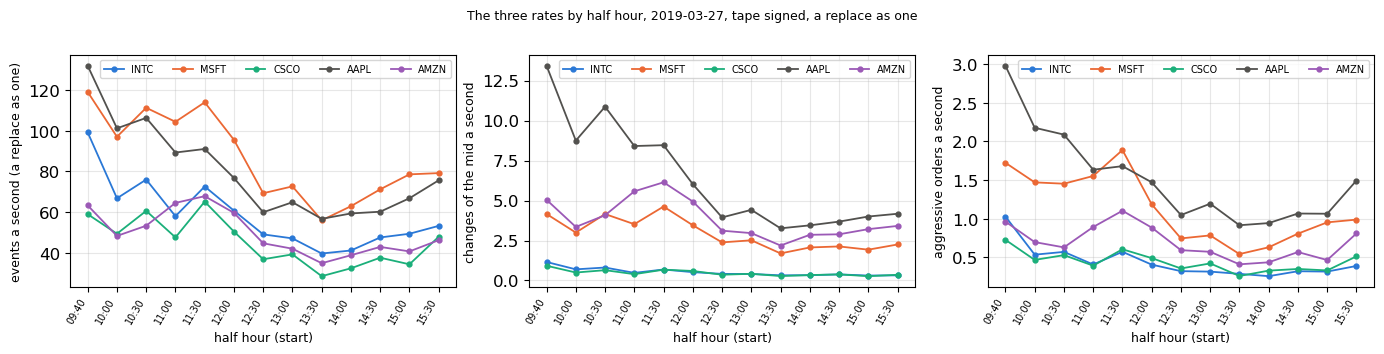

In [9]:
# Section 1: the three rates by half hour, a panel a rate, a line a stock, one y-axis a panel. The half hours are
# unequal: the first and the last are twenty minutes of the session, and the first holds the open's burst.
TAPE_PANELS = (
    ('events by block, as one', 'events a second (a replace as one)'),
    ('mid changes by block, as one', 'changes of the mid a second'),
    ('aggressive orders by block', 'aggressive orders a second'),
)


def tape_figure(results, day=DAY):
    fig, axes = plt.subplots(1, len(TAPE_PANELS), figsize=(14, 3.6))
    for ax, (key, ylabel) in zip(axes, TAPE_PANELS, strict=True):
        plot_strips(results, lambda r, key=key: r['tape'][key], ylabel, ax=ax)
        tidy_axes(ax)  # thirteen start times in a third of a page
    fig.suptitle(figure_title('The three rates by half hour', results, day), fontsize=9)
    plt.tight_layout()
    plt.show()


if need(DAY):
    tape_figure(tape_results)

TODO(prose): The tape table ("What each stock-day holds"). For each reported stock, from the printed table and for the day it is of: quote the hidden share of executed shares and the unsigned share (the two percentages), the time at one tick, two ticks and three or more ticks, and the three rates a second with a replace as one and as two (events, mid changes, aggressive orders). Say what the day looked like in those terms and nothing about regimes; do not say that two stocks differ, and do not set a stock's rate beside another's as if the one explained the other. Say that NVDA and CMCSA are not in this table (they are the exploration stocks).

TODO(prose): The unequal half hours (the last table of "What each stock-day holds" and the figure of "The three rates by half hour"). Quote, for each stock, the busiest half hour's events a second over the quietest's, and the first half hour's over the median half hour's, and say what that means for the block bootstrap of the later sections: it resamples half hours as if they were exchangeable, and these ratios say they are not, so its standard error is printed beside the strip's own and neither is the uncertainty of the stock.

TODO(prose): The conversion's checks ("The conversion's counts that are REQUIRED to be 0"). Quote the number of required counts and their sum (the last line of the cell; the cell stops if it is not 0), and the counts that are not errors (stub quotes under a dollar and off the cent grid, from the second table), the premise counts (a hidden trade's side byte, a printed execution a cent from its order), and what the stream did (breaks, cross executions, interleaved rows, paired reductions). Say that a count of 0 is what the file's own rules require of a replayed book, and that it does not say the frames equal the exchange's book.

TODO(prose): One sentence on what the tape is not a measure of: the rates depend on how a replace is counted (one or two) and on how executions are grouped into aggressive orders (adjacent executions at one nanosecond with consecutive match numbers), and the printed rates are for these conventions.

**What this cannot show.**

- *One day of each stock.* The table describes a stock on the day named in its heading. It does not say what the stock is like on other days, labels no stock as a regime, and does not say that any two of the five stocks differ: they share the day's market factor.
- *Hidden volume is counted and not signed.* The hidden share of executed shares is the shares executed against non-displayed orders; the unsigned share is the part of it in runs with no displayed execution beside it, whose aggressor is not known. Nothing here says who the aggressor of that volume was, and no accuracy later in the notebook "against the true side" includes it.
- *Rates are for conventions.* A replace counted as one gives fewer events than as two, and a different grouping of executions (adjacent at one nanosecond, or merged within 100 microseconds) gives other counts of aggressive orders (the code review found moves of up to 11%). Events a second of a real stream and events a unit of the simulator are not the same count: a unit here is a second, a unit there is the simulator's own.
- *The checks are the file's own.* A count of 0 means the replayed book followed ITCH's rules at every message (every execute, cancel and delete named a live order; no crossed or locked book). It does not mean that the frames are the exchange's book: that was checked against two independent decoders on the exploration stocks only, which is not a check of these stocks.

## Section 2: The simulator's findings, on real books

**The question.** Notebook 14 measured six signals that order books are said to carry in the simulator, against truths that the simulator knows. This section asks of each finding: **does it appear on real books?** Every finding is set out the same way. The figure is a stock's on the day it is of, with its half-hour strip, the three rates beside it (events, changes of the mid and aggressive orders a second) and the convention named (the tape, and a replace counted as one). Beside it is notebook 14's figure for the simulator, quoted from its saved output with its seeds. A figure near the simulator's is a description: nothing here is called a match, and nothing says that the simulator matches a market. Where a prediction was written before any reported stock was read, its verdict for each stock is printed under the table (the rules are in the predictions cell, and the conclusions count the stocks that pass on each day). The first half of the section, which follows, is the queue imbalance and the next move, the queue race and order flow imbalance; the second half is VPIN, order-to-trade ratios and resilience.

### The queue imbalance and the next move

**What notebook 14 found** (its seeds 101 to 108). The imbalance of the top `levels` price levels of each side, (B - A) / (B + A), positive when the bid side is heavier, is read after each change of the mid at the first event that leaves the mid alone and gives a nonzero value, and its sign is scored against the direction of the next change. It is scored against two baselines, 50% and the reversal rate (predict minus the last change), and the lift is the hit rate less the better of the two. In ZI the L 1 imbalance (the queue imbalance at the touch) hit 71.1% (se 0.1) on 13,014 changes scored a run, against a reversal rate of 63.9% (se 0.1), a lift of 7.2 points (se 0.1); the lifts over the better baseline were 5.6 to 11.1 points in the five models, and 50% alone flattered them (16.9 to 21.8 points). By the spread at the reading, the one-tick hit rate was high (89.1% in ZI) but so was the reversal rate (87.0%), so the one-tick lift was small (2.2 points in ZI; 1.9 to 2.3 in the four models other than Parlour; 8.3 in Parlour) against 6.9 to 11.5 points wider. Beyond the touch, equal weights lost to the reversal baseline (below 0 in 13 of 15 cells, down to -7.5 points at L 10) and touch weights repaired that only in part (0.5 to 4.3 points).

**The reading and the baseline.** The same reading is taken from the real book, a replace counted as one change of the book, a next change within 30 seconds, sizes in shares with odd lots counted. The baseline is **taken within each spread class at the reading**, never before the classes are pooled: the reversal rate at a spread of one tick is not the reversal rate at two ticks, and a pooled lift is a mixture of the two (in the exploration, with a replace counted as one, CMCSA's pooled lift was 14.8 points where its lift over the better baseline was -0.3 points at one tick and +9.7 at two ticks), so no pooled lift is printed here as a stock's figure. A class with fewer than 200 readings is a count only.

**What the exploration stocks showed** (exploration: NVDA and CMCSA on the first day, which the code was built on, never reported as results; a replace counted as one). NVDA at L 1: 909 readings at one tick (the spread was one tick for 0.3% of the session), hit 66.0%, reversal rate 55.8%; 1,804 at two ticks, 60.6% and 49.1%; 49,760 at three ticks or more, 56.3% and 48.1%. CMCSA: 3,488 readings at one tick (99.8% of the session), 70.2% and 70.5%; 2,991 at two ticks, 59.7% and 27.2%; 7 at three or more, a count only. In the ladder exploration (section 4) the one-tick figures changed when the stream was cut to one state a millisecond, because the states they read can last under a millisecond: that is a statement about these two stocks on that day, and it is not carried over to feeds in general.

**What is run.** Nothing new: the readings are in each stock's `measure` result from section 1's run. The tables are L 1 by spread class with its binding baseline and the three rates beside it, the imbalance beyond the touch (levels 3, 5 and 10, equal and touch weights) with the share of changes dropped, and the half-hour strips with the figure that draws them. The predictions that read these tables are the hit rate, the reversal rate and the one-tick lift.

In [10]:
# Section 2, the first half (the imbalance and the next move, the queue race, order flow imbalance): what its cells
# share. Everything here is a function of a dict of measure() results by stock (a day's: measured(DAY), or
# SECOND_DAY's), so that section 6 prints the second day with the same code. Names are prefixed imb_ (the queue race's
# too) and ofi_. This cell needs the setup only; it prints one line.
IMB_SPLIT_NOTE = {  # the note notebook 14 printed before its table of a setting by the spread at the reading
    'L 1 equal': 'By the spread at the reading, L 1',
    'L 10 touch': 'By the spread at the reading, touch L 10',
}
IMB_NUMBER = re.compile(r'[+-]?[\d,]*\.?\d+(?: \([\d.]+\))?')
IMB_MODEL_ROW = re.compile(r'^(?:(\d+) units)?\s+(ZI|Hawkes ZI|MF 2008|Parlour|Informed ZI)\s+(.*)$')
IMB_RACE_ROW = re.compile(
    r'^(?:(ZI|Hawkes ZI|MF 2008|Parlour|Informed ZI)\s+)?\s*(all|one tick|two ticks|three or more)\s+(.*)$'
)
IMB_OFI_BLOCKS = (  # the heading of each block of columns of notebook 14's order-flow table, and what its cells are
    ('intervals a run', ('intervals a run', 'same-interval R2')),
    ('OFI against the next change', ('OFI against the next change',)),
    ('the last change against the next', ('the last change against the next',)),
    ('OFI beyond the last change', ('OFI beyond the last change', 'OFI against the next OFI')),
)


def imb_rates(results):
    # the three rates beside every figure of a stock (rates_beside) and the share of the session at one tick: what each
    # figure below is set beside
    one_tick = {'time at one tick': lambda r: r['tape']['time at a spread of one tick, two, three or more'][0]}
    return rates_beside(results).join(stock_table(results, one_tick))


def imb_judge(results, tests):
    # the verdict of each of the predictions `tests` on each stock, as PREDICTIONS judges it (rules written before the
    # run)
    lines = []
    for stock, r in results.items():
        for test in tests:
            verdict = PREDICTIONS[test].judge(r)
            lines.append(f'  {stock:<6} {test:<22} {verdict.status:<11} {verdict.detail}')
    if results:  # a stock-day that was refused or failed is not judged, and is said to be
        lines += [f'{line} (not judged)' for line in unrun_lines(next(iter(results.values()))['day'], results)]
    return '\n'.join(lines)


IMB_COLUMNS = (
    'n',
    'hit %',
    'reversal %',
    'lift over 50% pp',
    'lift over reversal pp',
    'lift over the better pp',
    'binds',
    'calls differ %',
    'se, blocks',
    'se, strip',
)
IMB_FORMATS = {
    'n': ',.0f',
    'hit %': '.1f',
    'reversal %': '.1f',
    'lift over 50% pp': '+.1f',
    'lift over reversal pp': '+.1f',
    'lift over the better pp': '+.1f',
    'calls differ %': '.1f',
    'se, blocks': '.1f',
    'se, strip': '.1f',
}


def imb_class_table(results, setting='L 1 equal'):
    # A frame, a row for each stock and spread class: the readings, the hit rate and the reversal rate (percent), the
    # lift over 50%, over the reversal rate and over the better of the two (percentage points), and which baseline binds
    # IN THE CLASS; the share of readings at which the imbalance's call and the reversal call point in different
    # directions (the hit rate and the reversal rate differ by at most that much: where it is small they are one
    # measurement read twice); where the setting has a half-hour strip, the lift's block-bootstrap standard error
    # (ASSUMING EXCHANGEABLE BLOCKS) and its strip's. A class with under MIN_READINGS readings is its count only. The
    # pooled row is not a figure of a stock and is not here.
    rows = {}
    for stock, r in results.items():
        classes = r['imbalance']['classes']
        for name in CLASSES:
            row = classes[(classes.setting == setting) & (classes['class'] == name)].iloc[0]
            n, strip = int(row['n']), r['imbalance']['strips'].get((setting, name))
            if n < MIN_READINGS:
                rows[stock, name] = {'n': n, 'binds': 'count only'}
                continue
            rows[stock, name] = {
                'n': n,
                'hit %': 100 * row['hit'],
                'reversal %': 100 * row['reversal'],
                'lift over 50% pp': 100 * row['lift over 50%'],
                'lift over reversal pp': 100 * row['lift over reversal'],
                'lift over the better pp': 100 * row['lift over the better'],
                'binds': row['binds'],
                'calls differ %': 100 * row['calls differ'],
                'se, blocks': 100 * strip['lift se'] if strip else math.nan,
                'se, strip': 100 * strip['lift strip se'] if strip else math.nan,
            }
    return pd.DataFrame.from_dict(rows, orient='index', columns=list(IMB_COLUMNS))


def imb_check_classes(results, setting='L 1 equal'):
    # What must hold for the class table to mean anything: the classes' readings add up to the pooled row's and their
    # hits too; the lift over the better baseline is the smaller of the lifts over each (the baseline taken in the
    # class), and 'binds' names it; each half-hour strip's readings add up to its class's.
    for stock, r in results.items():
        classes = r['imbalance']['classes']
        sub = classes[classes.setting == setting].set_index('class')
        parts = sub.loc[list(CLASSES)]
        pooled = sub.loc['pooled']
        assert parts.n.sum() == pooled['n'], f'{stock} {setting}: the classes do not add up to the readings'
        if pooled['n'] > 0:
            for key in ('hit', 'reversal'):
                total = float((parts.n * parts[key]).fillna(0).sum())  # a class with no reading has no rate
                assert math.isclose(total, pooled['n'] * pooled[key], rel_tol=1e-9), f'{stock} {setting}: {key}'
        for name, row in parts[parts.n > 0].iterrows():
            better = min(row['lift over 50%'], row['lift over reversal'])
            assert math.isclose(row['lift over the better'], better, abs_tol=1e-12), f'{stock} {name}: baseline'
            assert row['binds'] == ('reversal rate' if row['reversal'] > 0.5 else '50%'), f'{stock} {name}: binds'
        for name in CLASSES:
            strip = r['imbalance']['strips'].get((setting, name))
            if strip is not None:
                assert sum(strip['strip']['n']) == parts.loc[name, 'n'], f'{stock} {setting} {name}: strip n'


# ---- notebook 14's saved output, read as printed (the simulator's figure beside each real one) ----
def imb_nb14_outputs(path=NB14_PATH):
    # the text of each output of notebook 14's saved cells, in order; None if the notebook or its outputs are not there
    try:
        notebook = json.loads(Path(path).read_text())
    except FileNotFoundError:
        return None
    texts = []
    for cell in notebook['cells']:
        for out in cell.get('outputs', []):
            if out.get('output_type') == 'stream':
                texts.append(''.join(out.get('text', '')))
            else:
                texts.append(''.join(out.get('data', {}).get('text/plain', '')))
    return texts or None


def imb_nb14_split(setting):
    # Notebook 14's table of a setting by the spread at the reading (one tick, wider), a row a model, as printed (mean
    # over seeds 101 to 108 and, in brackets, its standard error across them); '-' where its saved output is not there.
    note = IMB_SPLIT_NOTE[setting]
    names = ('scored a run', 'hit %', 'reversal %', 'lift pp')
    columns = pd.MultiIndex.from_tuples([(label, name) for label in ('one tick', 'wider') for name in names])
    table = pd.DataFrame(
        {m: [notebook_14_printed(m, f'{label}: {name}', after=note) for label, name in columns] for m in NB14_MODELS},
        index=columns,
    ).T
    return table.fillna('-')


def imb_nb14_ofi(texts=None):
    # Notebook 14's order-flow table, {(interval in units, model): {column: text as printed}}: the setup's reader reads
    # the first model of a group only (the interval's name is on that row alone), so each row is read here with the
    # group's.
    texts = imb_nb14_outputs() if texts is None else texts
    out = {}
    for text in texts or []:
        if 'intervals a run' not in text:
            continue
        names, interval = None, None
        for line in text.splitlines():
            line = line.rstrip().removesuffix('\\').rstrip()
            for heading, columns in IMB_OFI_BLOCKS:
                if heading in line:
                    names = columns
            row = IMB_MODEL_ROW.match(line)
            if row and names:
                interval = int(row.group(1)) if row.group(1) else interval
                values = [m.group(0) for m in IMB_NUMBER.finditer(row.group(3))]
                if len(values) == len(names):
                    out.setdefault((interval, row.group(2)), {}).update(zip(names, values, strict=True))
    return out


def imb_nb14_race(texts=None):
    # Notebook 14's queue-race table, {(model, spread class): {column: text as printed}}, pooled over its eight seeds:
    # the readings, the hit rate, the log-likelihood gain over a constant for the curve at c = 1, the gain with a fitted
    # (and a), and the fit of both (a, c). Rows are read across the three blocks of columns it printed.
    texts = imb_nb14_outputs() if texts is None else texts
    out = {}
    for text in texts or []:
        if 'scored (all seeds)' not in text:
            continue
        model = None
        for line in text.splitlines():
            row = IMB_RACE_ROW.match(line.rstrip().removesuffix('\\').rstrip())
            if not row:
                continue
            model = row.group(1) or model
            rest, cells = row.group(3), out.setdefault((model, row.group(2)), {})
            both = re.match(r'(-?[\d,]+) \(a = ([\d.]+), c = ([\d.]+)\)$', rest)
            fitted = re.match(r'(-?[\d,]+) \(c = ([\d.e+-]+)\)\s+(-?[\d,]+) \(a = ([\d.]+)\)$', rest)
            if both:
                cells.update({'both: a': both.group(2), 'both: c': both.group(3)})
            elif fitted:
                cells.update({'gain, a fitted (c = 1)': fitted.group(3), 'a (c = 1)': fitted.group(4)})
            elif len(rest.split()) == 3:
                cells.update(zip(('scored (all seeds)', 'hit %', 'gain, c = 1'), rest.split(), strict=True))
    return out


print(
    'notebook 14\'s saved output: '
    + (
        f'{len(imb_nb14_ofi())} order-flow rows and {len(imb_nb14_race())} queue-race rows read.'
        if imb_nb14_outputs()
        else 'not in this checkout (the simulator\'s figures beside each real one are left out).'
    )
)

notebook 14's saved output: 20 order-flow rows and 20 queue-race rows read.


In [11]:
# Section 2, the imbalance and the next move: the touch (L 1) by the spread at the reading, the baseline within each
# class. Needs the imb_ helpers. With the data absent it prints one line.
def imb_show_split(results, setting='L 1 equal', day=DAY, what='L 1, the queue imbalance at the touch'):
    # a setting by the spread at the reading: the stocks' table, the three rates beside it and notebook 14's table of
    # the simulator beside that
    imb_check_classes(results, setting)
    heading(
        f'{what}: the next change of the mid against the sign of the first nonzero imbalance after the last',
        results,
        day,
    )
    say(
        f'Strict design (the first event that leaves the mid alone gives the reading), a next change within '
        f'{T_MAX:.0f} '
        's, by the spread at the reading. Lifts in points over 50%, over the reversal rate (predict minus the last '
        f'change) and over the better of the two, which binds IN THE CLASS; a class under {MIN_READINGS} readings is a '
        'count only. calls differ: the share of readings at which the imbalance\'s call and the reversal call point '
        'in different directions; the hit rate and the reversal rate cannot differ by more than that, so where it is '
        'small they are one measurement read twice and the lift over the reversal rate is bounded by it. se: the '
        f'lift\'s block-bootstrap standard error ({DRAWS:,} draws, ASSUMING EXCHANGEABLE BLOCKS) and the strip\'s own.'
    )
    table = imb_class_table(results, setting)
    print(shown(table, IMB_FORMATS))
    for (stock, name), n in table.n.items():
        if n < MIN_READINGS:
            print(f'  {stock}, {name}: {count_line(n)}')
    print('\nThe three rates beside (a replace as one), session:')
    print(shown(imb_rates(results), RATE_FORMATS | {'time at one tick': '.1%'}))
    say(
        f'\n{NB14_SEEDS}, {setting} by the spread at the reading, the simulator (mean over seeds, se across seeds in '
        'brackets):'
    )
    print(imb_nb14_split(setting).to_string())
    return table


if need(DAY):
    imb_results = measured(DAY)
    imb_l1 = imb_show_split(imb_results)
    print('\nThe predictions that read this table (written before the run), by stock:')
    print(imb_judge(imb_results, ('hit rate', 'reversal rate', 'one-tick lift')))


L 1, the queue imbalance at the touch: the next change of the mid against the sign of the first nonzero imbalance after
the last: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
Strict design (the first event that leaves the mid alone gives the reading), a next change within 30 s, by the spread at
the reading. Lifts in points over 50%, over the reversal rate (predict minus the last change) and over the better of the
two, which binds IN THE CLASS; a class under 200 readings is a count only. calls differ: the share of readings at which
the imbalance's call and the reversal call point in different directions; the hit rate and the reversal rate cannot
differ by more than that, so where it is small they are one measurement read twice and the lift over the reversal rate
is bounded by it. se: the lift's block-bootstrap standard error (1,000 draws, ASSUMING EXCHANGEABLE BLOCKS) and the
strip's own.
                         n hit % reversal % lift over 50% pp lift over

     events a second mid changes a second aggressive orders a second time at one tick
INTC           57.54                0.515                      0.425            99.8%
MSFT           86.37                2.899                      1.121            89.8%
CSCO           44.86                0.463                      0.434            99.6%
AAPL           78.73                6.246                      1.481            20.7%
AMZN           49.51                3.808                      0.684             0.0%

notebook 14, seeds 101 to 108, L 1 equal by the spread at the reading, the simulator (mean over seeds, se across seeds
in brackets):
                one tick                                           wider                                    
            scored a run       hit %  reversal %    lift pp scored a run       hit %  reversal %     lift pp
ZI                 3,476  89.1 (0.2)  87.0 (0.3)  2.2 (0.1)        9,538  64.5 (0.1)  55.5 (0.1)   9.0 (0.2)
Hawkes ZI          2,93

TODO(prose): L 1 by spread class ("L 1, the queue imbalance at the touch"). For each reported stock and each spread class with 200 readings or more, quote the readings, the hit rate, the reversal rate and the lift over the better baseline with the baseline that binds ("reversal rate" or "50%", column `binds`), and for a class under 200 readings quote the count only (the line under the table). Say that the baseline is the class's own, and what that changed: a class whose reversal rate is above 50% is judged against the reversal rate, and where the reversal rate is above the hit rate the lift is below 0. Do not quote a pooled figure and do not say that two stocks differ.

TODO(prose): The simulator beside L 1 (the last table of "L 1, the queue imbalance at the touch"). Quote notebook 14's one-tick and wider lifts for ZI (2.2 and 9.0 points) and the range over its five models, and say, for each reported stock, whether the simulator's ordering (a small one-tick lift and a larger lift at two ticks or more, with a one-tick reversal rate above the wider classes') appeared in that stock's table: stock by stock, one tick against two ticks and against three or more where the class has 200 readings. A figure near the simulator's is a description: say "near" or "far from", never "matches", and say what is not comparable (its reversal rates at one tick are 71.9 to 88.5%, and every stock's classes are those of its own spread).

TODO(prose): The predictions that read this table (printed under it). For each of the three (hit rate above 50% in every class with 200 readings in which the reversal rate is 50% or less; reversal rate above 50% at one tick and below 50% at two, where one tick holds more than half the time; the one-tick lift's 95% block-bootstrap interval inside -1 to +1 point, where one tick holds more than half the time) count the stocks that passed of those judged, name the stocks that did not pass or were not judged and why (the detail printed beside each verdict), and give each stock's figure beside its verdict, since a figure near a threshold says as much about the threshold.

In [12]:
# Section 2, the imbalance beyond the touch (levels 3, 5 and 10, equal and touch weights), and the changes of the mid
# that are dropped (no reading before the next change, or a next change more than T_MAX later). Needs the imb_ helpers.
# With the data absent it prints one line.
IMB_BEYOND = [setting for setting in SETTINGS if not setting.startswith('L 1 ')]  # L 1 equal and touch are one number
IMB_LIFT_NOTE = 'The lift in pp (over the better of the reversal rate and 50%) at every setting'
IMB_DROPPED_NOTE = 'The share of the changes of the mid dropped'


def imb_beyond_table(results):
    # A frame, a row for each stock and setting beyond L 1 and a column for each spread class: the lift over the better
    # baseline in points, and in brackets the baseline that binds in the class (rev: the reversal rate, 50: 50%) and the
    # readings; a class under MIN_READINGS readings is its count only.
    rows = {}
    for stock, r in results.items():
        classes = r['imbalance']['classes']
        for setting in IMB_BEYOND:
            cells = {}
            for name in CLASSES:
                row = classes[(classes.setting == setting) & (classes['class'] == name)].iloc[0]
                n = int(row['n'])
                if n < MIN_READINGS:
                    cells[name] = f'n = {n:,}'
                else:
                    baseline = 'rev' if row['binds'] == 'reversal rate' else '50'
                    cells[name] = f'{100 * row["lift over the better"]:+.1f} ({baseline}, {n:,})'
            rows[stock, setting] = cells
    return pd.DataFrame.from_dict(rows, orient='index', columns=list(CLASSES))


def imb_dropped_table(results):
    # A frame, a row a stock: the share (percent) of the changes of the mid with no reading before the next change at
    # each setting (strict design), those whose next change came more than T_MAX later at L 1, and the share with no
    # reading in the inclusive design (where the change event's own state can give the reading), at L 1 and touch L 10
    rows = {}
    for stock, r in results.items():
        strict = r['imbalance']['dropped'].set_index('setting')
        inclusive = r['imbalance']['dropped, inclusive'].set_index('setting')
        row = {setting: 100 * strict.loc[setting, 'no reading'] for setting in SETTINGS}
        row[f'late (T {T_MAX:.0f}), L 1'] = 100 * strict.loc['L 1 equal', 'late']
        row['inclusive L 1'] = 100 * inclusive.loc['L 1 equal', 'no reading']
        row['inclusive touch L 10'] = 100 * inclusive.loc['L 10 touch', 'no reading']
        rows[stock] = row
    return pd.DataFrame.from_dict(rows, orient='index')


def imb_show_beyond(results, day=DAY):
    for setting in IMB_BEYOND:
        imb_check_classes(results, setting)
    heading(
        'The imbalance beyond the touch: the lift over the better baseline, by the spread at the reading', results, day
    )
    say(
        'Levels 3, 5 and 10 with equal and touch weights (L 1 equal and touch are one number: the first level\'s '
        'weight is 1). Points; in brackets the baseline that binds in the class (rev: the reversal rate, 50: 50%) and '
        f'the readings; a class under {MIN_READINGS} readings is a count only.'
    )
    print(imb_beyond_table(results).to_string())
    print('\nThe changes of the mid that are dropped (percent of the changes), by setting and design, session:')
    dropped = imb_dropped_table(results)
    print(shown(dropped, {column: '.1f' for column in dropped.columns}))
    say(
        f'\n{NB14_SEEDS}, the simulator: the lift over the better baseline at every setting, EVERY SPREAD POOLED as '
        'notebook 14 printed it (no pooled lift is printed for a stock here), and the share dropped (mean over seeds, '
        'se in brackets):'
    )
    print(nb14_table(SETTINGS, after=IMB_LIFT_NOTE).to_string())
    print(nb14_table(list(dropped.columns), after=IMB_DROPPED_NOTE).to_string())
    say(f'\n{NB14_SEEDS}, touch L 10 by the spread at the reading (the split it printed for L 1 and touch L 10 only):')
    print(imb_nb14_split('L 10 touch').to_string())


if need(DAY):
    imb_results = measured(DAY)
    imb_show_beyond(imb_results)


The imbalance beyond the touch: the lift over the better baseline, by the spread at the reading: 2019-03-27, session
09:40:00 to 15:50:00, tape signed, a replace as one.
Levels 3, 5 and 10 with equal and touch weights (L 1 equal and touch are one number: the first level's weight is 1).
Points; in brackets the baseline that binds in the class (rev: the reversal rate, 50: 50%) and the readings; a class
under 200 readings is a count only.


                            one tick          two ticks      three or more
INTC L 3 equal     -4.9 (rev, 5,780)   +9.1 (50, 4,855)              n = 1
     L 3 touch     -1.9 (rev, 5,780)  +10.6 (50, 4,855)              n = 1
     L 5 equal     -7.8 (rev, 5,780)   +9.8 (50, 4,855)              n = 1
     L 5 touch     -2.0 (rev, 5,780)  +10.8 (50, 4,855)              n = 1
     L 10 equal   -10.6 (rev, 5,780)   +7.2 (50, 4,855)              n = 1
     L 10 touch    -2.1 (rev, 5,780)  +10.7 (50, 4,855)              n = 1
MSFT L 3 equal    -4.2 (rev, 31,998)  +4.3 (50, 25,215)            n = 149
     L 3 touch    +0.2 (rev, 31,999)  +6.8 (50, 25,217)            n = 149
     L 5 equal    -9.1 (rev, 31,999)  +3.3 (50, 25,217)            n = 149
     L 5 touch    +0.0 (rev, 31,999)  +6.8 (50, 25,217)            n = 149
     L 10 equal  -15.5 (rev, 31,999)  +3.3 (50, 25,217)            n = 149
     L 10 touch   +0.0 (rev, 31,999)  +6.9 (50, 25,217)            n = 149
CSCO L 3 equal     -7.1 (

              L 1 equal   L 1 touch   L 3 equal   L 3 touch   L 5 equal   L 5 touch  L 10 equal  L 10 touch late (T 30), L 1 inclusive L 1 inclusive touch L 10
ZI           17.3 (0.1)  17.3 (0.1)   8.4 (0.1)   8.2 (0.1)   8.3 (0.1)   8.2 (0.1)   8.2 (0.1)   8.2 (0.1)    0.000 (0.000)    10.2 (0.1)            0.0 (0.0)
Hawkes ZI    19.8 (0.3)  19.8 (0.3)  10.8 (0.2)  10.6 (0.2)  10.8 (0.2)  10.6 (0.2)  10.7 (0.2)  10.6 (0.2)    0.000 (0.000)    10.9 (0.2)            0.0 (0.0)
MF 2008      18.1 (0.2)  18.1 (0.2)  12.3 (0.2)  12.0 (0.1)  12.3 (0.1)  12.0 (0.1)  12.2 (0.1)  12.0 (0.1)    0.000 (0.000)     7.7 (0.1)            0.0 (0.0)
Parlour      52.8 (0.1)  52.8 (0.1)  40.8 (0.1)  39.5 (0.1)  40.3 (0.1)  39.4 (0.1)  40.3 (0.1)  39.4 (0.1)    0.000 (0.000)    25.9 (0.1)            0.0 (0.0)
Informed ZI  20.8 (0.2)  20.8 (0.2)  10.6 (0.1)  10.4 (0.1)  10.5 (0.1)  10.4 (0.1)  10.5 (0.1)  10.4 (0.1)    0.000 (0.000)    12.0 (0.1)            0.0 (0.0)

notebook 14, seeds 101 to 108, touch L 


L 1 equal: the lift by half hour and spread class, its standard errors: 2019-03-27, session 09:40:00 to 15:50:00, tape
signed, a replace as one.
Points; the lift is the hit rate less the better of 50% and the class's reversal rate for the day, in each half hour too
(so "half hours above 0" counts against the line of the class's own lift; "above 0, own baseline" counts against each
half hour's own better baseline, a higher line on average); se, blocks: block bootstrap ASSUMING EXCHANGEABLE BLOCKS;
se, strip: the strip's sd over the root of the half hours with readings.
                         n lift pp se, blocks se, strip half hours above 0 above 0, own baseline half hours lowest pp highest pp
INTC one tick        5,780    -1.5        0.4       0.9                  6                     2         13      -6.1       +3.9
     two ticks       4,855   +10.7        1.3       1.5                 13                    13         13      +5.1      +23.1
MSFT one tick       31,996    +0.0   

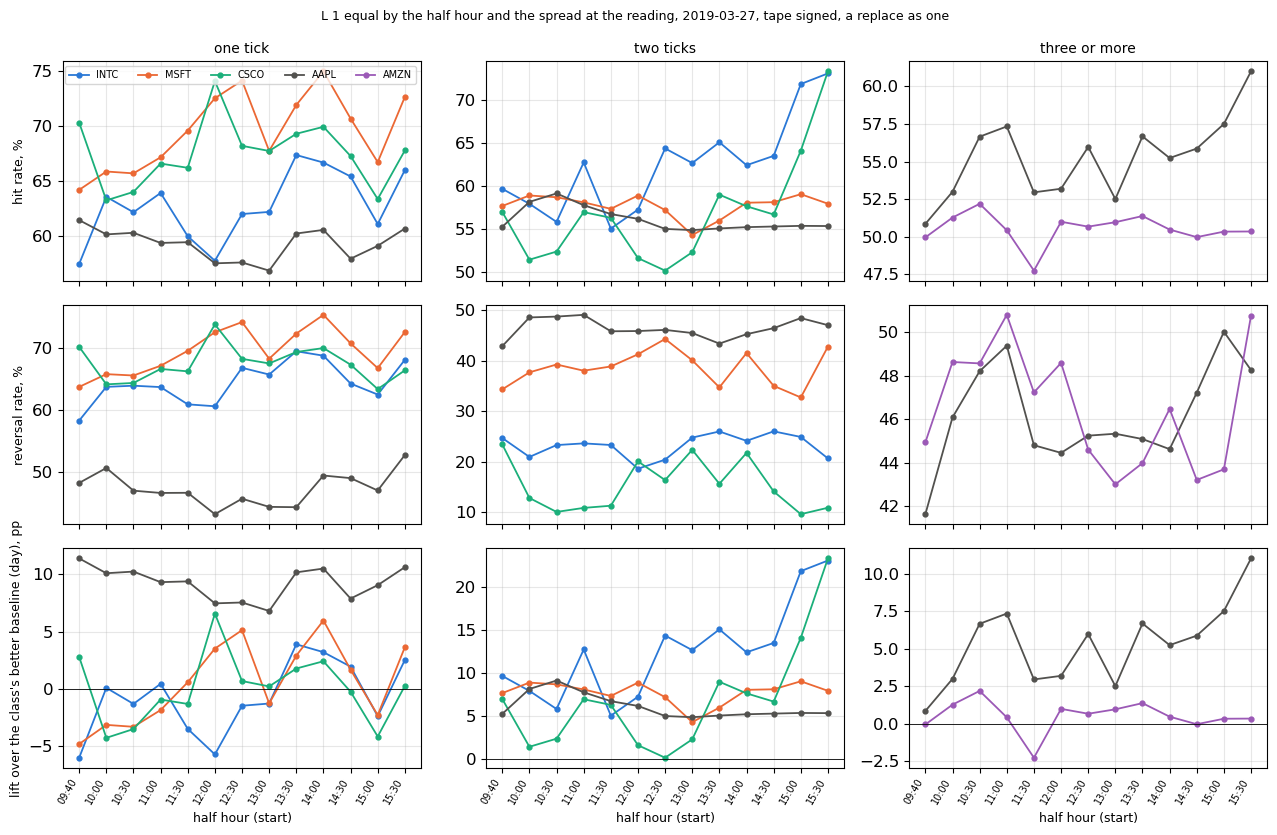

In [13]:
# Section 2, the imbalance in the half hours of the session: the strips of hit rate, reversal rate and lift, by spread
# class, with the lift's standard errors; and the figure. Needs the imb_ helpers. With the data absent it prints one
# line.
IMB_STRIPS = (  # the strip's key, its label, scale and decimals
    ('n', 'n', 1.0, 0),
    ('hit', 'hit %', 100.0, 1),
    ('reversal', 'reversal %', 100.0, 1),
    ('lift', 'lift pp', 100.0, 1),
)
IMB_STRIP_SETTINGS = ('L 1 equal', 'L 10 touch', 'L 10 equal')  # the settings that have a half-hour strip


def imb_strip(r, setting, name, key):
    # the half-hour strip of one class (n, hit, reversal, lift or lift over reversal); NaN for a class under
    # MIN_READINGS
    strip = r['imbalance']['strips'].get((setting, name))
    return strip['strip'][key] if strip else [math.nan] * len(HAVE_BLOCKS)


def imb_strip_summary(results, setting):
    # A frame, a row for each stock and class that has a strip: the class's readings and lift (points), the lift's
    # block-bootstrap standard error (ASSUMING EXCHANGEABLE BLOCKS) and its strip's, and in how many of the half hours
    # that have readings the lift is above 0: against the class's baseline for the day (the table's), and, beside it,
    # against each half hour's own baseline.
    rows = {}
    for stock, r in results.items():
        for name in CLASSES:
            strip = r['imbalance']['strips'].get((setting, name))
            if strip is None:
                continue
            lifts = np.array(strip['strip']['lift'], dtype=float)
            lifts = lifts[np.isfinite(lifts)]
            own = np.array(strip['strip']['lift, own baseline'], dtype=float)
            own = own[np.isfinite(own)]
            rows[stock, name] = {
                'n': strip['n'],
                'lift pp': 100 * strip['lift'],
                'se, blocks': 100 * strip['lift se'],
                'se, strip': 100 * strip['lift strip se'],
                'half hours above 0': int((lifts > 0).sum()),
                'above 0, own baseline': int((own > 0).sum()),
                'half hours': len(lifts),
                'lowest pp': 100 * lifts.min() if len(lifts) else math.nan,
                'highest pp': 100 * lifts.max() if len(lifts) else math.nan,
            }
    return pd.DataFrame.from_dict(rows, orient='index')


def imb_strip_lines(results, setting, name):
    # the half-hour strips of one class, a line for each stock and measure, under the half hours' start times
    lines = [f'{setting}, {name}', f'{"":<15}{strip_header(6)}']
    for stock, r in results.items():
        if (setting, name) in r['imbalance']['strips']:
            for key, label, scale, digits in IMB_STRIPS:
                lines.append(f'{stock:<6}{label:<9}{strip_text(imb_strip(r, setting, name, key), digits, scale, 6)}')
    return lines if len(lines) > 2 else [f'{setting}, {name}: no stock has {MIN_READINGS} readings']


def imb_figure(results, setting='L 1 equal', day=DAY):
    # hit rate, reversal rate and the lift over the better baseline, by half hour (rows), for each spread class
    # (columns): a line a stock, one y-axis a panel; a stock with under MIN_READINGS readings in a class is not drawn
    # there
    rows = (
        ('hit', 'hit rate, %', 100.0),
        ('reversal', 'reversal rate, %', 100.0),
        ('lift', 'lift over the class\'s better baseline (day), pp', 100.0),
    )
    fig, axes = plt.subplots(len(rows), len(CLASSES), figsize=(13, 8.5), sharex=True)
    for i, (key, ylabel, scale) in enumerate(rows):
        for j, name in enumerate(CLASSES):
            ax = axes[i, j]
            if any((setting, name) in r['imbalance']['strips'] for r in results.values()):
                plot_strips(
                    results,
                    lambda r, key=key, name=name: imb_strip(r, setting, name, key),
                    ylabel if j == 0 else '',
                    scale=scale,
                    ax=ax,
                    zero=(key == 'lift'),
                )
                if i or j:
                    ax.get_legend().remove()
            else:
                ax.text(
                    0.5, 0.5, f'no stock has {MIN_READINGS} readings', ha='center', transform=ax.transAxes, fontsize=8
                )
            if i == 0:
                ax.set_title(name, fontsize=10)
            if i < len(rows) - 1:
                ax.set_xlabel('')
            tidy_axes(ax)
    fig.suptitle(figure_title(f'{setting} by the half hour and the spread at the reading', results, day), fontsize=9)
    plt.tight_layout()
    plt.show()


def imb_show_strips(results, day=DAY):
    # the strips' summary for each setting that has one, then the half-hour strips of L 1 by spread class (the figure is
    # imb_figure's)
    for setting in IMB_STRIP_SETTINGS:
        heading(f'{setting}: the lift by half hour and spread class, its standard errors', results, day)
        say(
            'Points; the lift is the hit rate less the better of 50% and the class\'s reversal rate for the day, in '
            'each half hour too (so "half hours above 0" counts against the line of the class\'s own lift; "above 0, '
            'own baseline" counts against each half hour\'s own better baseline, a higher line on average); se, '
            'blocks: block bootstrap ASSUMING EXCHANGEABLE BLOCKS; se, strip: the strip\'s sd over the root of the '
            'half hours with readings.'
        )
        summary = imb_strip_summary(results, setting)
        formats = {'n': ',.0f', 'lift pp': '+.1f', 'se, blocks': '.1f', 'se, strip': '.1f'}
        print(shown(summary, formats | {'lowest pp': '+.1f', 'highest pp': '+.1f'}))
    print()
    for name in CLASSES:
        print('\n'.join(imb_strip_lines(results, 'L 1 equal', name)))


if need(DAY):
    imb_results = measured(DAY)
    imb_show_strips(imb_results)
    imb_figure(imb_results)

TODO(prose): The imbalance beyond the touch ("The imbalance beyond the touch"). For each reported stock quote the lift over the better baseline at L 3, L 5 and L 10 with equal and with touch weights, by spread class with 200 readings or more (the printed brackets give the binding baseline and the readings), and say whether the simulator's two orderings appeared: equal weights below touch weights beyond L 1, and equal weights below 0 where the reversal rate binds. Quote notebook 14's pooled lifts (ZI: -1.2 at L 3 equal, 1.4 at L 3 touch, -2.1 at L 10 equal, 1.4 at L 10 touch) as notebook 14's, with its seeds, and say that they are pooled over spreads and that no pooled lift is printed for a stock here; and the touch L 10 split by spread (ZI: -6.0 at one tick, 4.7 wider).

TODO(prose): The changes dropped (the second table of "The imbalance beyond the touch"). Quote, for each reported stock, the share of changes of the mid with no reading before the next change at L 1 and at L 10, the share whose next change came later than the limit, and the inclusive design's share, beside notebook 14's (ZI: 17.3% at L 1 strict, 10.2% inclusive). Say how much of what is scored the strict design leaves out, and that the stock's classes are scored on the changes that are left.

TODO(prose): The half-hour strips ("the lift by half hour and spread class" and its figure). For L 1, for each stock and class with a strip, quote the number of half hours in which the lift is above 0 of the half hours with readings, the lowest and the highest half-hour lift, and the lift's two standard errors (the block bootstrap's, which assumes exchangeable blocks, and the strip's own), and say which of the lifts stand more than twice their strip's standard error from 0 and which do not. Say how few readings some half hours of the one-tick class hold (the `n` lines of the strip) before reading any single half hour.

**What this cannot show.**

- *One day of each stock, and the five stocks share the day's market factor.* The tables are a stock's figures on the day they are of. Nothing here says that two stocks differ, that a stock is of a kind (no regime labels), or what the figure is on another day; the second-day section runs the same code on the held-out day.
- *A lift within a class is a statement about that class's readings.* A change of the mid is often a change of the spread, so the classes are not independent samples of one book: a reading's class is decided by the move that preceded it. The baseline taken within the class is the better of two named baselines (50% and the reversal rate); it is not shown to be the right one, and no other baseline was tried.
- *The one-tick figures depend on states that last very little.* In the ladder exploration of the two stocks the code was built on, the one-tick imbalance readings changed when the stream was cut to one state a millisecond: they rest on states that can last under a millisecond, so a figure at one tick describes the full stream of events and is not a statement about what a feed that shows less would give.
- *A hit rate is of the next change of the mid, not of a fill.* The study says nothing about trading on the imbalance: it has no costs, no P&L and no queue position, and a next change within 30 seconds is the only horizon.
- *A strip's half hours are not exchangeable.* The first half hour holds more events a second than the median half hour, and the block bootstrap's standard error assumes they are interchangeable; it is printed beside the strip's own and neither is the uncertainty of the stock.
- *Notebook 14's figures are of a simulator.* They are set beside the real figures to show what is being compared and with what spread of its own (seeds 101 to 108). Nothing in the section says the simulator matches a market.

### The queue race

**The question.** The curve for independent queues says that the chance the mid moves toward the heavier queue is 1/2 + (2/pi) arctan |I|, which is VisualHFT's 1/2 + arctan(c |I|) / (2 arctan c) at c = 1 (Cont and de Larrard, 2013; Avellaneda, Reed and Stoikov, 2011), where |I| is the imbalance at the touch at the reading. Does it fit the real readings, and how steep is the real hit rate in |I| in each spread class compared with the curve? The amplitude a scales what the curve adds to 1/2, so a = 1 is the curve itself and a below 1 is a flatter one.

**What notebook 14 found** (its seeds 101 to 108, fits pooled over the eight seeds). The curve at c = 1 beat a constant hit rate at one-tick spreads, by a log-likelihood of 1,391 in ZI (1,195, 468, 228 and 1,148 in the other four models), and lost to it over every spread (-8,946 in ZI). With a and c fitted, a reached its upper limit of 1.00 at one tick in all five models (c at 2.19, 2.19, 0.79, 1.86 and 2.68), and the fit with a alone gained exactly what the curve at c = 1 did, so the simulator's data at one tick are at least as steep as the curve for independent queues. At wider spreads a was an interior estimate that fell with the spread (in ZI 0.54 at two ticks and 0.31 at three or more).

**What the exploration stocks showed** (exploration: NVDA and CMCSA on the first day, never reported as results; a replace counted as one). At one tick the amplitude at c = 1 was 0.47 on NVDA (block-bootstrap upper 95% bound 0.58, 909 readings) and 0.50 on CMCSA (0.56, 3,488 readings), and the curve at c = 1 lost to a constant hit rate on both; at two ticks, 0.31 and 0.69; at three or more ticks on NVDA, 0.19. CMCSA's fit of c ran to a bound.

**What is run.** The fit of the setup cell (`race_by_class`, in each stock's `measure` result) by spread class, for the classes with 200 readings or more: the amplitude a at c = 1 by a bounded search, with its standard error and its 95th percentile (the upper bound the prediction reads) from a block bootstrap of the half hours (a fit a draw), a and c fitted together beside them with **no standard error on c** (it runs to a bound in most resamples), and the log-likelihood each version gains over a constant hit rate. The figure bins the hit rate by |I| with the curve for independent queues and the fitted amplitude. The prediction that reads this table is that the upper 95% bound of a at one tick is under 1 (the simulator's value at one tick is 1.00).


The queue race: the curve for independent queues fitted to the touch imbalance, by spread class: 2019-03-27, session
09:40:00 to 15:50:00, tape signed, a replace as one.
gain: the log-likelihood the curve gains over a constant hit rate (negative: it does worse). a (c = 1): the amplitude of
1/2 + a arctan(|I|) / (2 arctan 1); se and upper 95%: its block bootstrap (200 draws, ASSUMING EXCHANGEABLE BLOCKS), the
upper bound being the 95th percentile of the draws; a, c, both: a and c fitted together (c has no standard error: it
runs to a bound in most resamples). A class under 200 readings is a count only.
                         n hit % gain, c = 1 a (c = 1)    se upper 95% gain, a fitted a, both  c, both
INTC one tick        5,780  62.0      -1,845      0.35  0.02      0.39             60    0.38     0.00
     two ticks       4,855  60.7          29      0.72  0.06      0.83             69    0.82     0.36
     three or more       1     -           -         -     -         -           

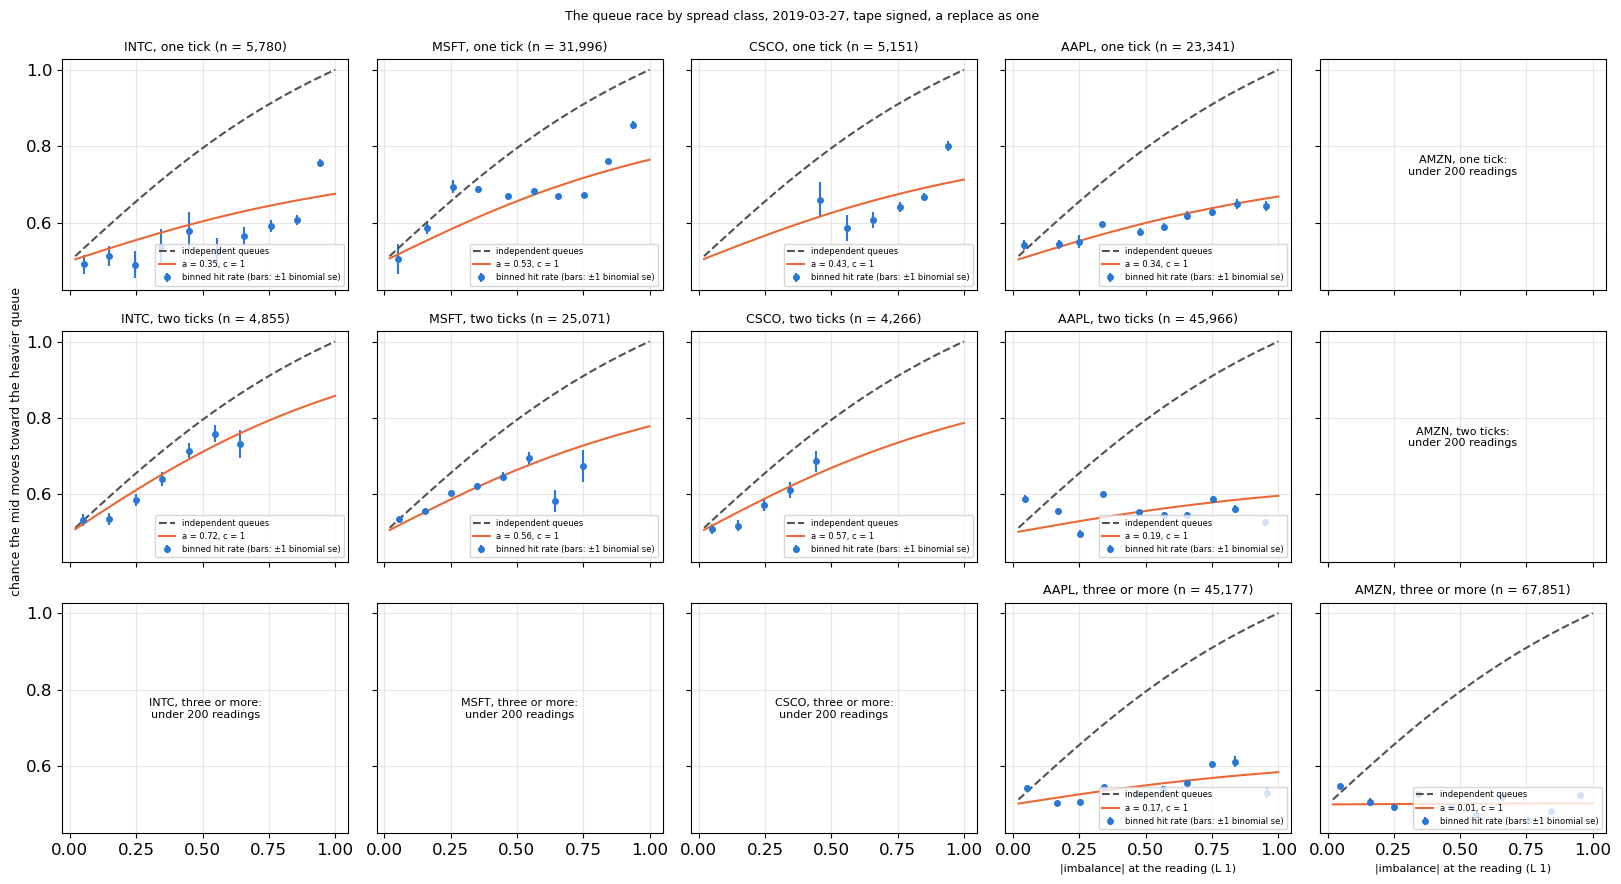

In [14]:
# Section 2, the queue race: the curve for independent queues, 1/2 + a arctan(c |I|) / (2 arctan c), fitted to the
# touch imbalance's readings by spread class; the amplitude a at c = 1 with a standard error (a block bootstrap of
# RACE_DRAWS draws, ASSUMING EXCHANGEABLE BLOCKS), c with none (it runs to a bound in most resamples). Needs the imb_
# helpers. With the data absent it prints one line.
IMB_RACE_COLUMNS = ('n', 'hit %', 'gain, c = 1', 'a (c = 1)', 'se', 'upper 95%', 'gain, a fitted', 'a, both', 'c, both')
IMB_RACE_FORMATS = {
    'n': ',.0f',
    'hit %': '.1f',
    'gain, c = 1': ',.0f',
    'a (c = 1)': '.2f',
    'se': '.2f',
    'upper 95%': '.2f',
    'gain, a fitted': ',.0f',
    'a, both': '.2f',
    'c, both': '.2f',
}
IMB_BINS = np.linspace(0, 1, 11)  # bins of |imbalance| for the figure, as notebook 14's
IMB_BIN_MIN = 100  # readings a bin needs to be drawn, as notebook 14's


def imb_race_table(results, setting='L 1 equal'):
    # A frame, a row for each stock and spread class: the readings, the hit rate, the log-likelihood the curve at c = 1
    # gains over a constant hit rate, the amplitude a with c = 1 (its block-bootstrap standard error and 95th
    # percentile, the upper bound the prediction reads), the gain with a fitted, and the fit of both (a and c, no
    # standard error for c). A class under MIN_READINGS readings is its count only.
    rows = {}
    for stock, r in results.items():
        classes = r['imbalance']['classes']
        for name in CLASSES:
            fit = r['imbalance']['race'].get(name)
            if fit is None:
                n = int(classes[(classes.setting == setting) & (classes['class'] == name)].n.iloc[0])
                rows[stock, name] = {'n': n}
                continue
            rows[stock, name] = {
                'n': fit['n'],
                'hit %': 100 * fit['hit'],
                'gain, c = 1': fit['gain c=1'],
                'a (c = 1)': fit['a (c = 1)'],
                'se': fit['a (c = 1) se'],
                'upper 95%': fit['a (c = 1) upper 95%'],
                'gain, a fitted': fit['gain a fitted'],
                'a, both': fit['a'],
                'c, both': fit['c'],
            }
    return pd.DataFrame.from_dict(rows, orient='index', columns=list(IMB_RACE_COLUMNS))


def imb_check_race(results, setting='L 1 equal'):
    # What must hold: a class has a fit exactly where it has MIN_READINGS readings, its readings are the class table's,
    # the amplitude is in (0, 1], and a standard error is not negative
    for stock, r in results.items():
        classes = r['imbalance']['classes']
        for name in CLASSES:
            n = int(classes[(classes.setting == setting) & (classes['class'] == name)].n.iloc[0])
            fit = r['imbalance']['race'].get(name)
            assert (fit is not None) == (n >= MIN_READINGS), f'{stock} {name}: a fit and the readings disagree'
            if fit is not None:
                assert fit['n'] == n, f'{stock} {name}: the fit\'s readings are not the class\'s'
                assert 0 < fit['a (c = 1)'] <= 1 and 0 < fit['a'] <= 1, f'{stock} {name}: an amplitude outside (0, 1]'
                assert fit['a (c = 1) se'] >= 0, f'{stock} {name}: a negative standard error'


def imb_nb14_race_table(names=CLASSES):
    # notebook 14's queue-race fits of the simulator (pooled over its eight seeds, as printed), a row for each model and
    # class
    read = imb_nb14_race()
    columns = ('scored (all seeds)', 'hit %', 'gain, c = 1', 'a (c = 1)', 'both: a', 'both: c')
    rows = {
        (model, name): [read.get((model, name), {}).get(c, '-') for c in columns]
        for model in NB14_MODELS
        for name in names
    }
    return pd.DataFrame.from_dict(rows, orient='index', columns=list(columns))


def imb_race_figure(results, day=DAY, setting='L 1 equal'):
    # The hit rate against |imbalance| at the reading, binned (bins with IMB_BIN_MIN readings or more, a standard error
    # each), with the curve for independent queues (a = 1, c = 1) and the fitted amplitude at c = 1; a panel for each
    # stock and spread class that has a fit
    stocks = list(results)
    names = [name for name in CLASSES if any(name in r['imbalance']['race'] for r in results.values())]
    if not names:
        print(f'no stock has {MIN_READINGS} readings in any spread class: no figure.')
        return
    fig, axes = plt.subplots(
        len(names), len(stocks), figsize=(3.3 * len(stocks), 3.0 * len(names)), sharex=True, sharey=True, squeeze=False
    )
    grid = np.linspace(0.02, 1, 50)
    for j, stock in enumerate(stocks):
        arr = results[stock]['arrays']['scored L1']
        cls = spread_class(arr[:, 4]) if len(arr) else np.array([], int)
        for i, name in enumerate(names):
            ax = axes[i, j]
            fit = results[stock]['imbalance']['race'].get(name)
            if fit is None:
                ax.text(
                    0.5,
                    0.5,
                    f'{stock}, {name}:\nunder {MIN_READINGS} readings',
                    ha='center',
                    transform=ax.transAxes,
                    fontsize=8,
                )
                continue
            data = arr[cls == CLASSES.index(name)]
            x, hit = data[:, 1], data[:, 2]
            centers, rates, errors = [], [], []
            for low, high in zip(IMB_BINS[:-1], IMB_BINS[1:], strict=True):
                inside = (x > low) & (x <= high)
                if inside.sum() >= IMB_BIN_MIN:
                    centers.append(x[inside].mean())
                    rates.append(hit[inside].mean())
                    errors.append(math.sqrt(hit[inside].mean() * (1 - hit[inside].mean()) / inside.sum()))
            ax.errorbar(
                centers,
                rates,
                yerr=errors,
                fmt='o',
                color=BLUE,
                markersize=4,
                label='binned hit rate (bars: ±1 binomial se)',
            )
            ax.plot(grid, race_probability(grid, 1.0, 1.0), color=GRAY, linestyle='--', label='independent queues')
            ax.plot(
                grid,
                race_probability(grid, fit['a (c = 1)'], 1.0),
                color=ORANGE,
                label=f'a = {fit["a (c = 1)"]:.2f}, c = 1',
            )
            ax.set_title(f'{stock}, {name} (n = {fit["n"]:,})', fontsize=9)
            ax.legend(fontsize=6, loc='lower right')
            if i == len(names) - 1:
                ax.set_xlabel('|imbalance| at the reading (L 1)', fontsize=8)
    fig.suptitle(figure_title('The queue race by spread class', results, day), fontsize=9)
    fig.supylabel('chance the mid moves toward the heavier queue', fontsize=9)
    plt.tight_layout()
    plt.show()


def imb_show_race(results, day=DAY):
    imb_check_race(results)
    heading(
        'The queue race: the curve for independent queues fitted to the touch imbalance, by spread class', results, day
    )
    say(
        'gain: the log-likelihood the curve gains over a constant hit rate (negative: it does worse). a (c = 1): the '
        f'amplitude of 1/2 + a arctan(|I|) / (2 arctan 1); se and upper 95%: its block bootstrap ({RACE_DRAWS} draws, '
        'ASSUMING EXCHANGEABLE BLOCKS), the upper bound being the 95th percentile of the draws; a, c, both: a and c '
        f'fitted together (c has no standard error: it runs to a bound in most resamples). A class under '
        f'{MIN_READINGS} '
        'readings is a count only.'
    )
    table = imb_race_table(results)
    print(shown(table, IMB_RACE_FORMATS))
    say(
        f'\n{NB14_SEEDS}, the simulator: the fits it printed, pooled over its eight seeds (readings, hit rate, '
        'the gain '
        'at c = 1, a with c = 1, and a and c fitted together; an amplitude of 1.00 is the fit\'s upper limit):'
    )
    print(imb_nb14_race_table().to_string())
    print('\nThe prediction that reads this table (written before the run), by stock:')
    print(imb_judge(results, ('queue race',)))
    return table


if need(DAY):
    imb_results = measured(DAY)
    imb_race = imb_show_race(imb_results)
    imb_race_figure(imb_results)

TODO(prose): The queue-race table ("The queue race"). For each reported stock and class with 200 readings or more, quote the amplitude a at c = 1 with its standard error and its upper 95% bound, and the gain over a constant hit rate at c = 1 (negative: the curve does worse than a constant). Say, class by class, whether the simulator's amplitude at one tick (1.00 in all five of its models, which is the fit's upper limit) was reached or the stock's amplitude lies below it, and by how much in standard errors of its block bootstrap; say that c is not given a standard error and quote the fitted c only as a fit.

TODO(prose): The prediction (printed under the table): the upper 95% bound of a at one tick under 1, where one tick holds more than half the time. Count the stocks that passed of those judged (a stock at one tick for half the time or less, or with under 200 readings at one tick, is not judged), and quote each stock's a and bound beside its verdict. A bound just under 1 is as much a statement about the threshold as about the stock.

TODO(prose): The figure of the binned hit rate. Say, for each stock and class drawn, where the binned hit rates lie against the curve for independent queues and against the fitted curve (above, below, or crossing it), and whether the hit rate rises with |I| at all in that class. Do not say that the queues are or are not independent: the fit measures how steeply the hit rate rises with |I|.

**What this cannot show.**

- *The amplitude is a steepness and not a test of independence.* A fitted a below 1 says the hit rate rises less steeply with |I| than the curve for independent queues does in that class, in that stock, on that day; it does not say why (a limit order inside the spread moves the mid whatever the queues say, and that is the mechanism notebook 14 offers for the wider spreads, not one tested here).
- *The standard error and the upper bound assume exchangeable half hours.* The bootstrap resamples the half hours with replacement, and they are not exchangeable (the first holds more events a second than the median half hour); the 95th percentile is the upper end of the resampled amplitudes and is not a confidence level for the stock.
- *c has no standard error.* It runs to a bound in most resamples, so a fitted c is a fit's value and not an estimate with an uncertainty.
- *The readings are those of the imbalance table.* The strict design, a next change within 30 seconds, sizes in shares with odd lots counted, a replace as one: a different reading would be a different fit. A class with fewer than 200 readings has no fit.
- *One day of each stock; no two stocks are said to differ.*

### Order flow imbalance

**The question.** How much of the change of the mid over an interval does the interval's order flow imbalance (OFI) explain, and does an interval's flow say anything about the next interval's change that the last change does not? OFI is Cont, Kukanov and Stoikov's best-quote rule: each event that moves the touch adds or removes the shares that the best bid and ask gain or lose, summed over an interval; the fit is of the mid's change on it, and the forecast is its partial correlation with the next interval's change given the last change.

**What notebook 14 found** (its seeds 101 to 108; a pooled R2 over each run of 5,000 units). The same-interval R2 at 10 units was 0.322 (se 0.013) in ZI, 0.238, 0.495, 0.474 and 0.308 in Hawkes ZI, MF 2008, Parlour and Informed ZI, and across the five 0.250 to 0.410 at 1 unit and 0.363 to 0.768 at 50. Scored against the last change, OFI forecast almost nothing in ZI, Hawkes ZI and Parlour: its partial correlation beyond the last change at 10 units was -0.04 (se 0.01) in ZI, -0.01 in Hawkes ZI and +0.04 in Parlour, and +0.12 in MF 2008 and +0.28 in Informed ZI, where the notebook traced it to the persistence of the flow and to the informed orders; at 50 units it was positive in every model (0.07 to 0.23).

**What the exploration stocks showed** (exploration: NVDA and CMCSA on the first day, never reported as results; one increment an event). NVDA's R2 pooled over the session at 1 s was 0.234, and ten of its 22,200 seconds hold 64% of the flow's sum of squares: with them set aside the R2 was 0.550, and the median half-hour R2 was 0.549 at 1 s, 0.674 at 5 s, 0.675 at 10 s and 0.644 at 50 s (CMCSA: 0.728, 0.800, 0.822 and 0.848, with a pooled R2 of 0.693 at 1 s, ten seconds holding 8% of its sum of squares). The partial correlation beyond the last change at 1 s was positive in 13 of 13 half hours on both. So the figure of this notebook is the **median half-hour R2**, with the pooled R2, the share of the flow's sum of squares in the ten largest seconds and the R2 without them beside it, and the partial correlation beyond the last change **by half hour**.

**What is run.** Nothing new: the flow is in each stock's `measure` result. The tables are the median half-hour R2 at 1, 5, 10 and 50 s with its block-bootstrap standard error, the pooled R2 beside it, the ten largest seconds, the partial correlation beyond the last change by half hour and the R2 at 10 s by the spread at the start of the interval; the figure draws the half hours. OFI is the same on every tape (a hidden execution moves no quote), so the tape does not change it, and the table names the convention all the same. The prediction that reads these tables is that the median half-hour R2 at 10 s is above 0.50 and the partial correlation beyond the last change at 1 s is positive in 10 of the half hours or more.

In [15]:
# Section 2, order flow imbalance: the same-interval R2 of the mid's change on the interval's flow at 1, 5, 10 and 50 s.
# The FIGURE is the median of the half-hour R2s; the pooled R2, the share of the flow's sum of squares in its ten
# largest seconds and the R2 without them are beside it, because a pooled R2 can be a few seconds of the day. Needs cell
# 21. With the data absent it prints one line.
def ofi_check(results):
    # What must hold for the tables to mean anything: the median of a strip is the median half-hour R2 and its half
    # hours are the session's; the intervals fill the session; shares are shares; the 1 s pooled R2 is the same number
    # in the interval table and in the ten-largest-seconds table; "beyond" is counted in half hours that have one.
    for stock, r in results.items():
        ofi = r['ofi']
        for h in INTERVALS:
            row = ofi[h]
            assert len(row['R2 strip']) == len(row['beyond strip']) == len(HAVE_BLOCKS), f'{stock} {h} s: strips'
            assert row['intervals'] == SESSION_SECONDS // h, (
                f'{stock} {h} s: {row["intervals"]} intervals fill no session'
            )
            if np.isfinite(row['R2 strip']).any():
                assert math.isclose(float(np.nanmedian(row['R2 strip'])), row['median half-hour R2'], rel_tol=1e-9), (
                    stock
                )
            assert row['blocks with R2'] == int(np.isfinite(row['R2 strip']).sum()), (
                f'{stock} {h} s: half hours with R2'
            )
            assert row['blocks with beyond above 0'] <= int(np.isfinite(row['beyond strip']).sum()), f'{stock} {h} s'
            assert not np.isfinite(row['pooled R2']) or 0 <= row['pooled R2'] <= 1, f'{stock} {h} s: pooled R2'
        top = ofi['largest seconds']
        share = top['share of the sum of squares of the flow in the ten largest seconds']
        assert not np.isfinite(share) or 0 <= share <= 1, f'{stock}: the share of the sum of squares'
        assert math.isclose(top['pooled R2 at 1 s'], ofi[1]['pooled R2'], rel_tol=1e-9, abs_tol=1e-12), (
            f'{stock}: pooled R2'
        )


def ofi_table(results, getter, digits=3):
    # a frame of text, a row a stock and a column for each interval: getter(row of one interval) gives (value, se) or a
    # value
    def cell(row):
        got = getter(row)
        value, se = got if isinstance(got, tuple) else (got, None)
        return fmt(value, digits) if se is None else f'{fmt(value, digits)} ({fmt(se, digits)})'

    return pd.DataFrame({f'{h} s': {stock: cell(r['ofi'][h]) for stock, r in results.items()} for h in INTERVALS})


def ofi_nb14_table(column, intervals=INTERVALS):
    # notebook 14's figure for each model and interval, as printed (a pooled figure of a run of simulation time; mean
    # over seeds 101 to 108 and, in brackets, its standard error across them)
    read = imb_nb14_ofi()
    return pd.DataFrame(
        {f'{h} units': {m: read.get((h, m), {}).get(column, '-') for m in NB14_MODELS} for h in intervals}
    )


def ofi_show(results, day=DAY):
    ofi_check(results)
    heading('Order flow imbalance: the same-interval R2 of the mid\'s change on the interval\'s flow', results, day)
    say(
        'One increment an event (the best-quote rule of Cont, Kukanov and Stoikov, summed in each interval). THE '
        f'FIGURE is the median of the half-hour R2s ({len(HAVE_BLOCKS)} half hours of the session, from '
        f'{SESSION_START}), with its block-bootstrap standard error ({DRAWS:,} draws, ASSUMING EXCHANGEABLE BLOCKS) in '
        'brackets.'
    )
    print(shown(ofi_table(results, lambda o: (o['median half-hour R2'], o['median half-hour R2 se']))))
    print('\nHalf hours with an R2 (of those the session touches):')
    print(shown(ofi_table(results, lambda o: o['blocks with R2'], 0)))
    say(
        '\nBeside it, NOT a stock\'s figure: the R2 pooled over the whole session (its block-bootstrap standard error '
        'in brackets), which a few seconds of the day can make:'
    )
    print(shown(ofi_table(results, lambda o: (o['pooled R2'], o['pooled R2 se']))))
    top = stock_table(
        results,
        {
            'share of the flow\'s sum of squares in the ten largest seconds': lambda r: r['ofi']['largest seconds'][
                'share of the sum of squares of the flow in the ten largest seconds'
            ],
            'pooled R2 at 1 s': lambda r: r['ofi']['largest seconds']['pooled R2 at 1 s'],
            'R2 at 1 s without them': lambda r: r['ofi']['largest seconds'][
                'R2 at 1 s without the ten largest seconds'
            ],
            'largest |flow| in a second (shares)': lambda r: r['ofi']['largest seconds'][
                'largest |flow| in a second (shares)'
            ],
        },
    )
    print('\nThe ten largest seconds of order flow imbalance (1 s intervals, the session):')
    print(
        shown(
            top,
            {top.columns[0]: '.1%', 'pooled R2 at 1 s': '.3f', 'R2 at 1 s without them': '.3f', top.columns[3]: ',.0f'},
        )
    )
    print('\nThe three rates beside (a replace as one), session:')
    print(shown(imb_rates(results), RATE_FORMATS | {'time at one tick': '.1%'}))
    say(
        f'\n{NB14_SEEDS}, the simulator: the same-interval R2 of a run ({S0_UNITS["ofi"]:,} units after the warm-up, a '
        'pooled R2 of one run, mean over seeds with the standard error across them in brackets), by interval in units '
        'of simulation time; it is not a median of half hours:'
    )
    print(ofi_nb14_table('same-interval R2').to_string())
    print('\nThe prediction that reads these tables (written before the run), by stock:')
    print(imb_judge(results, ('order flow imbalance',)))


if need(DAY):
    imb_results = measured(DAY)
    ofi_show(imb_results)


Order flow imbalance: the same-interval R2 of the mid's change on the interval's flow: 2019-03-27, session 09:40:00 to
15:50:00, tape signed, a replace as one.
One increment an event (the best-quote rule of Cont, Kukanov and Stoikov, summed in each interval). THE FIGURE is the
median of the half-hour R2s (13 half hours of the session, from 09:40:00), with its block-bootstrap standard error
(1,000 draws, ASSUMING EXCHANGEABLE BLOCKS) in brackets.
                1 s            5 s           10 s           50 s
INTC  0.795 (0.012)  0.855 (0.008)  0.867 (0.008)  0.861 (0.033)
MSFT  0.807 (0.017)  0.896 (0.009)  0.909 (0.006)  0.911 (0.013)
CSCO  0.784 (0.016)  0.836 (0.012)  0.861 (0.013)  0.869 (0.014)
AAPL  0.783 (0.008)  0.826 (0.012)  0.828 (0.017)  0.806 (0.020)
AMZN  0.387 (0.018)  0.449 (0.028)  0.473 (0.019)  0.460 (0.045)

Half hours with an R2 (of those the session touches):
     1 s 5 s 10 s 50 s
INTC  13  13   13   13
MSFT  13  13   13   13
CSCO  13  13   13   13
AAPL  13  13

In [16]:
# Section 2, order flow imbalance beyond the last change: does an interval's flow tell the next interval's change of
# the mid anything that the interval's own change does not? The partial correlation of the flow with the next change
# given the last change, BY BLOCK (the figure is the half hours' above 0 and their values; the pooled value is beside
# it, not a stock's figure); and the R2 at the headline interval by the spread at the start of the interval. Needs the
# imb_ helpers and ofi_table. With the data absent it prints one line.
def ofi_beyond_lines(results, h):
    # the half-hour strip of "beyond the last change" at an interval, a line a stock, under the half hours' start times
    return stock_strips(results, lambda r: r['ofi'][h]['beyond strip'], 2, width=6, label=f'{h} s')


def ofi_above_zero(results, h):
    # for each stock, "k of m": the half hours at an interval with the partial correlation above 0, of those with one
    out = {}
    for stock, r in results.items():
        row = r['ofi'][h]
        out[stock] = f'{row["blocks with beyond above 0"]} of {int(np.isfinite(row["beyond strip"]).sum())}'
    return out


def ofi_spread_table(results):
    # a frame, a row a stock: R2 at the headline interval by the spread at the start of the interval, with the intervals
    # in brackets (an R2 only where there are more than 20); the class with few intervals is its count
    return pd.DataFrame(
        {
            name: {
                stock: f'{fmt(r["ofi"]["by spread"][name]["R2"], 3)} ({r["ofi"]["by spread"][name]["intervals"]:,})'
                for stock, r in results.items()
            }
            for name in CLASSES
        }
    )


def ofi_show_beyond(results, day=DAY):
    heading('Order flow imbalance beyond the last change', results, day)
    say(
        'The partial correlation of an interval\'s flow with the next interval\'s change of the mid, given the last '
        'change. The pooled value (its block-bootstrap standard error in brackets, ASSUMING EXCHANGEABLE BLOCKS) is '
        'NOT a stock\'s figure; the figure is how many half hours it is above 0, and the strip.'
    )
    print(shown(ofi_table(results, lambda o: (o['OFI beyond the last change'], o['beyond se']))))
    print('\nHalf hours with it above 0, of the half hours that have one:')
    print(shown(pd.DataFrame({f'{h} s': ofi_above_zero(results, h) for h in INTERVALS})))
    print('\nBy half hour (from the half hour that starts at):')
    for h in INTERVALS:
        print(ofi_beyond_lines(results, h))
        print()
    print('Beside it: the correlation of the flow with the next change, and of the last change with the next, pooled:')
    print(shown(ofi_table(results, lambda o: o['OFI against the next change'], 2)))
    print(shown(ofi_table(results, lambda o: o['the last change against the next'], 2)))
    print(
        f'\nR2 at {OFI_MAIN} s by the spread at the start of the interval (the intervals in brackets; no R2 for 20 or '
        'fewer):'
    )
    print(ofi_spread_table(results).to_string())
    say(
        f'\n{NB14_SEEDS}, the simulator: the partial correlation beyond the last change, a pooled figure of a run '
        '(mean '
        'over seeds, se across seeds in brackets), by interval in units of simulation time:'
    )
    print(ofi_nb14_table('OFI beyond the last change').to_string())
    print(
        '\nBeside it, notebook 14\'s forecast scored against the last change (the correlation of the flow with the '
        'next change):'
    )
    print(ofi_nb14_table('OFI against the next change').to_string())


if need(DAY):
    imb_results = measured(DAY)
    ofi_show_beyond(imb_results)


Order flow imbalance beyond the last change: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
The partial correlation of an interval's flow with the next interval's change of the mid, given the last change. The
pooled value (its block-bootstrap standard error in brackets, ASSUMING EXCHANGEABLE BLOCKS) is NOT a stock's figure; the
figure is how many half hours it is above 0, and the strip.
                1 s            5 s            10 s            50 s
INTC  0.116 (0.010)  0.101 (0.018)   0.056 (0.015)  -0.033 (0.050)
MSFT  0.138 (0.008)  0.064 (0.020)   0.043 (0.027)   0.069 (0.057)
CSCO  0.172 (0.009)  0.128 (0.012)   0.039 (0.020)  -0.052 (0.036)
AAPL  0.038 (0.010)  0.015 (0.016)  -0.004 (0.022)   0.022 (0.058)
AMZN  0.050 (0.006)  0.033 (0.029)   0.028 (0.021)   0.071 (0.042)

Half hours with it above 0, of the half hours that have one:
           1 s       5 s      10 s     50 s
INTC  13 of 13  12 of 13  12 of 13  5 of 13
MSFT  13 of 13  11 of 13  10 of

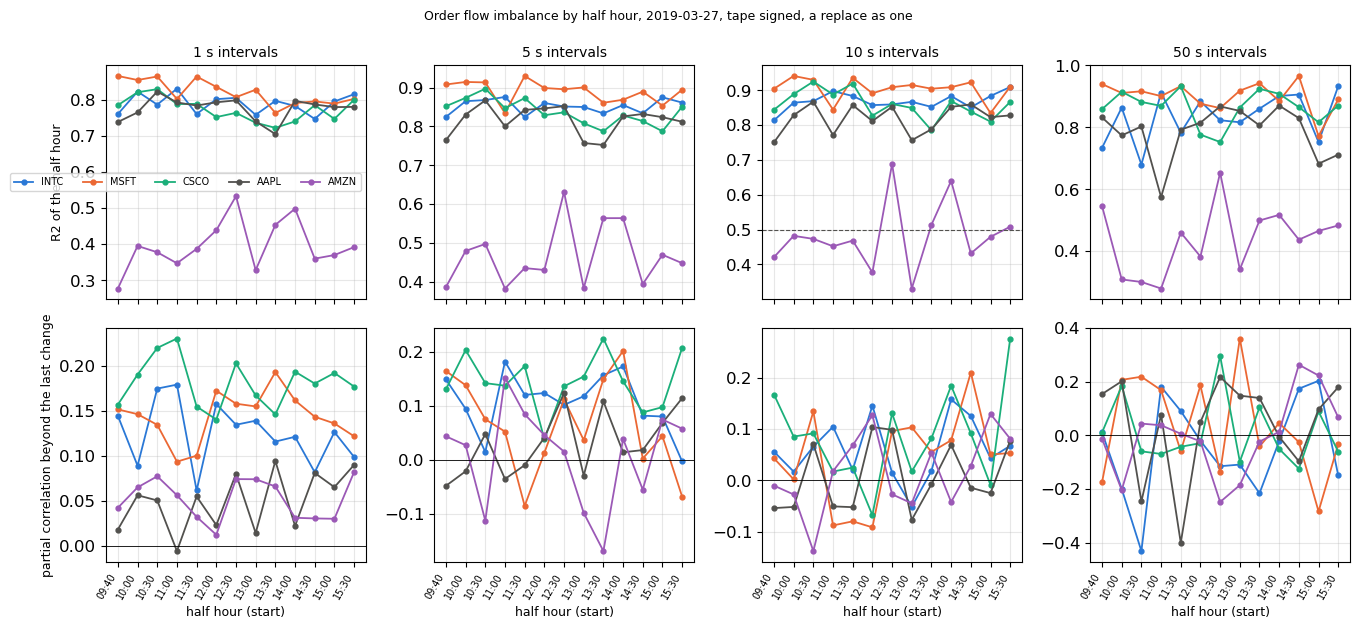

In [17]:
# Section 2, order flow imbalance by half hour: the R2 of each half hour (top) and the partial correlation beyond the
# last change (bottom), at each interval, a line a stock, one y-axis a panel. Needs the imb_ helpers. With the data
# absent it prints one line.
def ofi_figure(results, day=DAY):
    fig, axes = plt.subplots(2, len(INTERVALS), figsize=(14, 6.4), sharex=True)
    for j, h in enumerate(INTERVALS):
        top, bottom = axes[0, j], axes[1, j]
        plot_strips(results, lambda r, h=h: r['ofi'][h]['R2 strip'], 'R2 of the half hour' if j == 0 else '', ax=top)
        plot_strips(
            results,
            lambda r, h=h: r['ofi'][h]['beyond strip'],
            'partial correlation beyond the last change' if j == 0 else '',
            ax=bottom,
            zero=True,
        )
        top.set_title(f'{h} s intervals', fontsize=10)
        if h == OFI_MAIN:
            top.axhline(
                0.5, color=GRAY, linestyle='--', linewidth=0.8
            )  # the prediction's threshold for the median half hour
        top.set_xlabel('')
        for ax in (top, bottom):
            tidy_axes(ax)
            if j or ax is bottom:
                ax.get_legend().remove()
    fig.suptitle(figure_title('Order flow imbalance by half hour', results, day), fontsize=9)
    plt.tight_layout()
    plt.show()


if need(DAY):
    ofi_figure(measured(DAY))

TODO(prose): The R2 tables ("Order flow imbalance: the same-interval R2"). For each reported stock quote the median half-hour R2 at 1, 5, 10 and 50 s with its block-bootstrap standard error (the figure), and set beside it, labeled as not the stock's figure, the pooled R2 at the same intervals, the share of the flow's sum of squares in the ten largest seconds (percent) and the R2 at 1 s without them. Say whether the pooled R2 is close to the median half-hour R2 or a few seconds of the day (the share and the R2 without them decide it), and do not say that either stock's figure is a property of the stock. Notebook 14's R2 at 10 units (ZI 0.322 (0.013); 0.238 to 0.495 over the five models) and at 50 units (0.363 to 0.768) are a simulator's pooled R2 of a run: set them beside and call them near or far, and say that they are not medians of half hours.

TODO(prose): The half-hour R2 strips ("Order flow imbalance by half hour"'s top row). For each stock quote the lowest and the highest half-hour R2 at 10 s and which half hours they are (from the strip's header), and say whether the first and the last half hours (twenty minutes each) stand apart. Say how many intervals a half hour holds at each interval (the first and the last half hours, of twenty minutes, hold 24 intervals at 50 s and the others 36), so that a half hour's R2 at 50 s is noisy.

TODO(prose): Beyond the last change ("Order flow imbalance beyond the last change" and the figure's bottom row). Quote, for each stock and interval, the number of half hours with the partial correlation above 0, and the strip at 1 s; quote the pooled value only as the one beside the strip (labeled), with its block-bootstrap standard error. Set notebook 14's values beside them (at 10 units ZI -0.04, Hawkes ZI -0.01, MF 2008 +0.12, Parlour +0.04, Informed ZI +0.28; at 50 units +0.07 to +0.23), and say, stock by stock, whether the simulator's sign at 1 to 10 units (about 0 in ZI, Hawkes ZI and Parlour) appeared or the real values are positive in most half hours.

TODO(prose): The R2 by spread (the last real table of "Order flow imbalance beyond the last change"): the intervals each spread class holds, which classes have an R2, and what it says about whether a stock's R2 is of the class it spends its time in.

TODO(prose): The prediction (printed under "Order flow imbalance: the same-interval R2"'s tables): median half-hour R2 at 10 s above 0.50 and the partial correlation beyond the last change at 1 s positive in 10 of 13 half hours or more. Count the stocks that passed of those judged, give each stock's median and count beside its verdict, and say that a stock with a median near 0.50 is as much a statement about the threshold as about the stock.

**What this cannot show.**

- *R2 is a same-interval fit and not a forecast.* OFI explains the interval it falls in because the flow moves the quotes that make the mid; a high R2 says nothing about predicting the next interval, and the partial correlation beyond the last change is the only forecast statistic here, with no trading rule and no costs behind it.
- *A pooled R2 can be a few seconds of the day.* That is why the figure is the median half-hour R2 and the pooled R2 is printed beside it as what it is; the ten largest seconds' share says how much of the pooled figure is theirs.
- *Half hours are not exchangeable, and some are short.* The block bootstrap resamples them as if they were; the first and the last are twenty minutes and the first holds the open's burst. A half hour holds few intervals at 50 s, so its R2 there is noisy.
- *R2 is not comparable across stocks.* The mid of a stock whose spread is one tick moves in half-tick steps and a stock with a wide spread moves it in other steps; the shares of the flow are in shares, so its scale is the stock's own. No two stocks are said to differ and no stock is labeled by regime.
- *Notebook 14's R2 is the simulator's pooled R2 of a run.* It is set beside the real median half-hour R2 to show what is being compared; they are not the same statistic and nothing is called a match.
- *Hidden executions are not in the flow.* They move no quote, so the flow is the displayed book's; the tape does not change it.

### VPIN

The first half of section 2 took the findings of notebook 14 that read prices and quotes: the queue imbalance and the next move, the queue race, order flow imbalance. The three that follow, VPIN, order-to-trade ratios and resilience, read the flow of volume and the depth of the book, and they are the findings whose simulator figures were most set by the simulator's design (one order size, one cancellation hazard, Poisson arrivals). Each is made here with the same study classes as in notebook 14, on the stream of `lob.feeds`, and is a function of a stock and a day, so that section 6 prints the same tables for the second day.

**The question.** Is the signed volume of a bucket more one-sided than random signs on the same fills would make it? VPIN is how one-sided the signed volume of a bucket is: the mean, over the last 50 buckets of V shares each, of |buy volume - sell volume| / V. It measures how often a buy follows a buy at the scale of a bucket. It is not a measure of informed trading, and nothing in this notebook says it is.

**What notebook 14 found in the simulator** (its saved output, seeds 101 to 108, the mean over seeds and its standard error across them, five models). True-side VPIN was 0.113 (se 0.001) in ZI, 0.111 (0.001) in Hawkes ZI and 0.113 (0.002) in Parlour, which is the value of independent fair-coin sides on fills of one size, sqrt(2 / (pi n)) at n = 50 fills a bucket (an identity of that simulator's equal-size market orders, not a null for any other stream), and 0.195 (0.004) in MF 2008 and 0.170 (0.003) in Informed ZI; the tick rule's VPIN was lower in every model and bulk volume classification's sat at 0.471 to 0.524 whatever the flow. The tables below print these beside the real figures.

**What the exploration stocks showed** (exploration: NVDA and CMCSA, 2019-03-27, on which this code and its settings were built; neither is reported as a result here, and each figure is its own stock's). VPIN with true sides was 0.400 against a fair-coin null of 0.244 (sd 0.007) on NVDA and 0.417 against 0.378 (sd 0.011) on CMCSA, so the null that the simulator's 0.113 stands for is not a number of the real stream: it depends on the fill sizes and has to be simulated on each stream's own fills. The excess over the null was +0.147 to +0.157 across 11 bucket origins on NVDA (20.1 to 23.5 null standard deviations) and +0.025 to +0.043 on CMCSA (2.3 to 4.0 null standard deviations, which is what moving where the buckets start does to a figure of a few null standard deviations). VPIN was first defined at 09:48:20 on NVDA and 09:43:40 on CMCSA (the first window of 50 buckets has to close), and an aggressive order was on the side of the one before it 77.6% and 65.7% of the time. On CMCSA the tick rule's VPIN (0.630) was above the true sides' and on NVDA (0.387) below. Bulk volume classification read 0.455 and 0.460, with the mid unchanged over 4.3% and 12.3% of the buckets.

**What is run.** `measured()` (the measurements of each stock on the day, run once for the whole notebook) gives, for each stock, VPIN's levels and nulls for the signed tape and the none tape. The tables are VPIN by the rule that signs the fills (true sides, the tick rule, the quote rule at lags 0 and 1, bulk volume classification) against its two nulls; the range of the excess across bucket origins, when VPIN is first defined and the prediction's verdict; and the half-hour strip with its figure. Each table prints the three rates (events, changes of the mid and aggressive orders a second) beside it, and the tape and the replace convention in its heading.

**How to read what is printed.**

- *Two nulls on the same fills.* The fair-coin null signs each aggressive order by a coin (all the fills of one order share its sign) and the shuffled null permutes the true signs among the signed orders (a rule's own signs among orders with as many fills); each is drawn 200 times with generator seed 1 on the fills and buckets of the level it is set against. The excess is the level less the null's mean, and "sds" is the excess in the null's standard deviations. A VPIN is never set against a formula.
- *The range across bucket origins.* The buckets start at the first fill after the calibration, so where they start is a choice: the true-side level is also computed with V fixed and the buckets starting at each minute from 09:30 to 09:40, and the range of the excess across those 11 origins is printed with every excess. An excess without its range is not a figure.
- *The tape.* "signed" is the displayed executions and the hidden ones that a displayed run signs; "none" is the displayed executions alone, beside it wherever the two differ. The hidden and the unsigned shares of the executed shares are printed beside every table (unsigned hidden volume never reaches a signed VPIN).
- *Half hours.* A strip is the thirteen half hours from 09:40 (the first and the last are twenty minutes of the session); a block bootstrap, where one is printed, resamples the half hours with replacement and ASSUMES EXCHANGEABLE BLOCKS, which they are not.
- *A figure near the simulator's is a description.* Nothing is called a match, and a real figure is never "the market's": it is one stock's on one day.

In [18]:
# VPIN, order-to-trade ratios and resilience (the cells of this part) read measured(): the measure() result of each
# stock on a day (the first call of the notebook runs them). Names this range makes start vpin_ (VPIN and what the
# three parts share), otr_ (order-to-trade ratios) and resil_ (resilience); the setup's are not assigned to. Every
# table below is a function of the results for a list of stocks and a day, so that section 6 can print the same table
# for the second day: vpin_report_levels, vpin_report_origins, vpin_report_strips, otr_report, resil_report and
# resil_report_strips each take (results, day) and print and return what they tabulate.


def vpin_origin_header():
    # the bucket origins' start times (each minute from the open), over a line of 11 values
    return ' '.join(f'{clock(60 * minute)[:5]:>7}' for minute in range(N_ORIGINS))


def vpin_clock(units):
    # a time in units as hh:mm:ss, '-' where there is none (a VPIN never defined)
    return '-' if units is None or not math.isfinite(units) else clock(units)

In [19]:
vpin_rules = (
    ('true', 'true sides'),
    ('tick', 'tick rule'),
    ('mid, lag 0', 'quote rule, lag 0'),
    ('mid, lag 1', 'quote rule, lag 1'),
    ('bvc', 'bulk volume classification'),
)


def vpin_report_levels(results, day=DAY, tapes=TAPES):
    # VPIN, by the rule that signs the fills, against its two nulls made on the same fills (never against a formula):
    # the fair-coin null signs each aggressive order by a coin (all its fills share it) and the shuffled null permutes
    # the true signs among the signed orders (a rule's own signs among the orders with as many fills); bulk volume
    # classification's null permutes its bucket changes of the mid. NULL_DRAWS draws, generator seed NULL_SEED. The
    # level
    # is the mean, over the buckets closed in the session, of the mean of the last N_BUCKETS buckets' imbalances.
    # Returns {tape: (levels frame, frame of what is beside them)}.
    out = {}
    for tape in tapes:
        rows, index, beside = [], [], {}
        for stock, result in results.items():
            v = result['vpin'][tape]
            assert v['draws'] == NULL_DRAWS, f'{stock}: the nulls were drawn {v["draws"]} times, not NULL_DRAWS'
            assert v['V'] > 0 and v['buckets'] > 0, f'{stock}: no VPIN bucket on the {tape} tape'
            for rule, label in vpin_rules:
                r = v['rules'][rule]
                if rule == 'bvc':
                    mean, sd = r['changes permuted']
                    excess, sds = r['excess over changes permuted'], r['excess over changes permuted (null sds)']
                    row = {'level': r['level'], 'fair coin (sd)': f'{mean:.3f} ({sd:.3f})'}
                    row |= {'excess over coin': excess, 'coin sds': sds, 'shuffled (sd)': '-'}
                    row |= {
                        'excess over shuffled': math.nan,
                        'shuffled sds': math.nan,
                        'level, time-weighted': math.nan,
                    }
                    label += ' (null: its bucket changes permuted)'
                else:
                    (mean, sd), (smean, ssd) = r['fair coin per order'], r['own signs permuted']
                    excess, sds = r['excess over fair coin'], r['excess over fair coin (null sds)']
                    if math.isfinite(excess):  # a stock-day with too few buckets has no level, and so no excess
                        assert math.isclose(excess, r['level'] - mean, abs_tol=1e-12), (
                            f'{stock} {rule}: excess is not level - null'
                        )
                        assert math.isclose(sds, excess / sd, rel_tol=1e-9), (
                            f'{stock} {rule}: null sds are not excess / sd'
                        )
                    row = {'level': r['level'], 'fair coin (sd)': f'{mean:.3f} ({sd:.3f})'}
                    row |= {'excess over coin': excess, 'coin sds': sds, 'shuffled (sd)': f'{smean:.3f} ({ssd:.3f})'}
                    row |= {'excess over shuffled': r['excess over permuted']}
                    row |= {
                        'shuffled sds': r['excess over permuted (null sds)'],
                        'level, time-weighted': r['level, time-weighted'],
                    }
                rows.append(row)
                index.append((stock, label))
            beside[stock] = {
                'V (shares)': v['V'],
                'buckets, since the open': v['buckets'],
                'in the session': int(np.nansum(v['blocks: buckets closed'])),
                'fills a bucket': v['fills a bucket'],
                'first defined': vpin_clock(v['first defined at']),
                'same side as the order before %': 100 * v['same side as the order before'],
                'orders that bought %': 100 * v['share of orders that bought'],
                'bvc: mid unchanged %': 100 * v['rules']['bvc']['share of buckets with the mid unchanged (session)'],
                'origin range of the excess': (
                    f'{fmt(v["origin range of the excess"][0], 3, sign=True)} to '
                    f'{fmt(v["origin range of the excess"][1], 3, sign=True)}'
                ),
            }
        levels = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'rule']))
        around = pd.DataFrame(beside).T.infer_objects().join(shares_beside(results)).join(rates_beside(results))
        heading('VPIN against its own nulls', results, day, how=convention(tape))
        note = (
            'displayed executions and the hidden ones a displayed run signs; the unsigned hidden volume never '
            'reaches it'
            if tape == TAPE
            else 'displayed executions alone; every hidden execution is left out'
        )
        print(
            f'{note}. V = {V_MEDIANS} x the median of the first {V_FILLS} fills, {N_BUCKETS} buckets a window, '
            f'bucket-weighted level over the buckets closed in the session; nulls on the same fills, {NULL_DRAWS} '
            f'draws, seed {NULL_SEED}.'
        )
        formats = {
            'level': '.3f',
            'excess over coin': '+.3f',
            'coin sds': '+.1f',
            'excess over shuffled': '+.3f',
            'shuffled sds': '+.1f',
            'level, time-weighted': '.3f',
        }
        print(shown(levels, formats))
        print('\nBeside each stock (the same tape):')
        print(
            shown(
                around,
                {
                    'V (shares)': ',.0f',
                    'buckets, since the open': ',.0f',
                    'in the session': ',.0f',
                    'fills a bucket': '.1f',
                    'same side as the order before %': '.1f',
                    'orders that bought %': '.1f',
                    'bvc: mid unchanged %': '.1f',
                    'hidden % of shares': '.2f',
                    'unsigned % of shares': '.2f',
                    'events a second': '.2f',
                    'mid changes a second': '.3f',
                    'aggressive orders a second': '.3f',
                },
            )
        )
        out[tape] = (levels, around)
    print(
        '\nThe excess is the level less the null\'s mean; "sds" is the excess in the null\'s standard deviations '
        'over its draws. The range of the excess over the 11 bucket origins is beside it: a one-number excess has an '
        'uncertainty that the null does not carry.'
    )
    return out


if need(DAY):
    vpin_levels = vpin_report_levels(measured(DAY), DAY)
    show_nb14(
        {
            'true sides': 'true: level',
            'tick rule': 'tick: level',
            'quote rule, lag 0': 'mid, lag 0: level',
            'quote rule, lag 1': 'mid, lag 1: level',
            'bulk volume classification': 'bvc: level',
        },
        'VPIN by the rule that signs the fills; the same 250 lots a bucket, 50 buckets',
    )


VPIN against its own nulls: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
displayed executions and the hidden ones a displayed run signs; the unsigned hidden volume never reaches it. V = 50 x the median of the first 200 fills, 50 buckets a window, bucket-weighted level over the buckets closed in the session; nulls on the same fills, 200 draws, seed 1.
                                                                      level fair coin (sd) excess over coin coin sds  shuffled (sd) excess over shuffled shuffled sds level, time-weighted
stock rule                                                                                                                                                                                
INTC  true sides                                                      0.374  0.330 (0.008)           +0.044     +5.3  0.328 (0.008)               +0.045         +5.5                0.367
      tick rule                                          

In [20]:
def vpin_report_origins(results, day=DAY, tapes=TAPES):
    # The range of VPIN's level and of its excess over the fair-coin null across N_ORIGINS bucket origins (V fixed,
    # buckets from the first fill at or after each minute from the open): what moving where the buckets start does,
    # which the null does not carry. With when VPIN is first defined (it is not defined at the session's start: the
    # first N_BUCKETS buckets must close), the share of the session's units at which it is, and the prediction's
    # verdict. Returns {tape: frame}.
    out = {}
    for tape in tapes:
        rows, lines = {}, {'level': [], 'null': [], 'excess': [], 'excess (null sds)': []}
        for stock, result in results.items():
            v = result['vpin'][tape]
            origins = v['origins']
            assert [o['minute'] for o in origins] == list(range(N_ORIGINS)), f'{stock}: not {N_ORIGINS} bucket origins'
            level = np.array([o.get('level', math.nan) for o in origins])
            excess = np.array([o.get('excess', math.nan) for o in origins])
            sds = np.array([o.get('excess (null sds)', math.nan) for o in origins])
            assert int(np.isfinite(excess).sum()) == v['origins computed'], (
                f'{stock}: origins computed is not its count'
            )
            assert int((excess > 0).sum()) == v['origins with an excess above 0'], (
                f'{stock}: origins above 0 miscounted'
            )
            if np.isfinite(excess).any():
                assert (np.nanmin(excess), np.nanmax(excess)) == v['origin range of the excess'], f'{stock}: range'
            first = v['first defined at']
            if tape == TAPE:  # the class's own series (the signed tape's): when it is first defined, in units
                unit = result['vpin defined']['first defined (unit)']['true']
                if math.isfinite(first):
                    assert unit == math.floor(first) + 1, (
                        f'{stock}: the series is first defined at unit {unit}, not {first}'
                    )
                defined = 100 * result['vpin defined']['defined share of the session']['true']
            else:
                defined = math.nan
            rows[stock] = {
                'level, lowest': np.nanmin(level) if np.isfinite(level).any() else math.nan,
                'level, highest': np.nanmax(level) if np.isfinite(level).any() else math.nan,
                'excess, lowest': v['origin range of the excess'][0],
                'excess, highest': v['origin range of the excess'][1],
                'null sds, lowest': np.nanmin(sds) if np.isfinite(sds).any() else math.nan,
                'null sds, highest': np.nanmax(sds) if np.isfinite(sds).any() else math.nan,
                'origins above 0': f'{v["origins with an excess above 0"]} of {v["origins computed"]}',
                'first defined': vpin_clock(first),
                'defined % of session units': defined,
            }
            for name, values in (('level', level), ('null', [o.get('null', math.nan) for o in origins])):
                lines[name].append((stock, values))
            lines['excess'].append((stock, excess))
            lines['excess (null sds)'].append((stock, sds))
        table = pd.DataFrame(rows).T.infer_objects()
        heading(
            'The range of VPIN\'s excess over its fair-coin null across bucket origins',
            results,
            day,
            how=convention(tape),
        )
        print(
            f'The true-sides VPIN, V fixed at {V_MEDIANS} x the median of the first {V_FILLS} fills, the buckets '
            f'starting at the first fill at or after each of the {N_ORIGINS} minutes from the open; {NULL_DRAWS} '
            'draws a null. "first defined" is the time the first window of buckets has closed.'
        )
        print(
            shown(
                table,
                {
                    'level, lowest': '.3f',
                    'level, highest': '.3f',
                    'excess, lowest': '+.3f',
                    'excess, highest': '+.3f',
                    'null sds, lowest': '+.1f',
                    'null sds, highest': '+.1f',
                    'defined % of session units': '.1f',
                },
            )
        )
        for name, fmt_digits in (('level', 3), ('null', 3), ('excess', 3), ('excess (null sds)', 1)):
            print(f'\n{name} by bucket origin (the minute the buckets start):')
            print(f'{"":<8}{vpin_origin_header()}')
            for stock, values in lines[name]:
                print(
                    f'{stock:<8}' + ' '.join(f'{fmt(x, fmt_digits, sign=name.startswith("excess")):>7}' for x in values)
                )
        out[tape] = table
    heading('The prediction on VPIN', results, day)
    print(f'rule: {PREDICTIONS["VPIN"].rule}.')
    for stock, result in results.items():
        verdict = PREDICTIONS['VPIN'].judge(result)
        print(f'{stock:<8}{verdict.status}: {verdict.detail}')
    return out


if need(DAY):
    vpin_origins = vpin_report_origins(measured(DAY), DAY)


The range of VPIN's excess over its fair-coin null across bucket origins: 2019-03-27, session 09:40:00 to 15:50:00, tape
signed, a replace as one.
The true-sides VPIN, V fixed at 50 x the median of the first 200 fills, the buckets starting at the first fill at or after each of the 11 minutes from the open; 200 draws a null. "first defined" is the time the first window of buckets has closed.
     level, lowest level, highest excess, lowest excess, highest null sds, lowest null sds, highest origins above 0 first defined defined % of session units
INTC         0.367          0.373         +0.035          +0.044             +4.3              +5.6        11 of 11      09:39:54                      100.0
MSFT         0.283          0.297         +0.050          +0.066             +9.1             +13.1        11 of 11      09:38:34                      100.0
CSCO         0.360          0.384         +0.040          +0.061             +4.6              +7.1        11 of 11      09:47:01     


VPIN by half hour, true sides against the fair-coin null: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a
replace as one.
Half hours by the time the buckets close; the first and the last are cut to the session. The strip's fair-coin null is the mean of 100 draws (the levels of the tables above use 200).

true sides:
stock     09:40   10:00   10:30   11:00   11:30   12:00   12:30   13:00   13:30   14:00   14:30   15:00   15:30
INTC      0.367   0.394   0.338   0.294   0.489   0.396   0.392   0.342   0.353   0.341   0.353   0.354   0.381
MSFT      0.285   0.281   0.286   0.309   0.291   0.276   0.298   0.270   0.295   0.298   0.272   0.286   0.362
CSCO      0.373   0.337   0.386   0.383   0.429   0.412   0.365   0.328   0.378   0.332   0.327   0.425   0.431
AAPL      0.475   0.473   0.440   0.454   0.480   0.407   0.465   0.408   0.428   0.428   0.423   0.416   0.468
AMZN      0.580   0.582   0.633   0.644   0.618   0.606   0.610   0.548   0.532   0.531   0.547   0.581   0.595


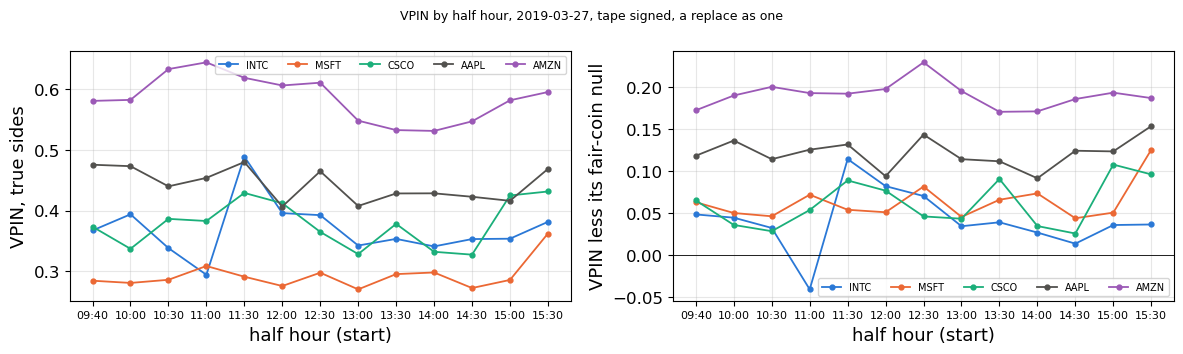

In [21]:
def vpin_report_strips(results, day=DAY):
    # VPIN by half hour on the signed tape: the true-sides level, the fair-coin null's mean (the mean over its draws of
    # the null's level in the buckets closed in the half hour: STRIP_NULL_DRAWS draws at most) and the excess, with the
    # buckets closed in each half hour (a half hour with a few buckets is a noisy value) and the strip's own standard
    # error (the standard deviation of the half-hour values over the root of how many there are). One y-axis a panel.
    # Returns the strips of each stock.
    strips = {}
    heading('VPIN by half hour, true sides against the fair-coin null', results, day)
    print(
        'Half hours by the time the buckets close; the first and the last are cut to the session. The strip\'s '
        f'fair-coin null is the mean of {STRIP_NULL_DRAWS} draws (the levels of the tables above use {NULL_DRAWS}).'
    )
    for label, key, digits, scale in (
        ('true sides', 'blocks: true', 3, 1.0),
        ('fair coin', 'blocks: fair coin mean', 3, 1.0),
        ('excess', 'blocks: excess', 3, 1.0),
        ('buckets', 'blocks: buckets closed', 0, 1.0),
    ):
        print(f'\n{label}:')
        print(stock_strips(results, lambda r, key=key: r['vpin'][TAPE][key], digits, scale, 7, 'stock'))
    for stock, result in results.items():
        v = result['vpin'][TAPE]
        strips[stock] = {key: v[key] for key in ('blocks: true', 'blocks: fair coin mean', 'blocks: excess')}
        values = np.array(v['blocks: excess'])
        assert len(values) == len(HAVE_BLOCKS), f'{stock}: not a value for each half hour of the session'
        assert np.allclose(
            values, np.array(v['blocks: true']) - np.array(v['blocks: fair coin mean']), equal_nan=True
        ), f'{stock}: the excess strip is not the true strip less the null strip'
        positive = int((values[np.isfinite(values)] > 0).sum())
        print(
            f'{stock:<8}excess above 0 in {positive} of {int(np.isfinite(values).sum())} half hours; strip se '
            f'{fmt(v["blocks: excess strip se"], 3)}; buckets closed in the session '
            f'{int(np.nansum(v["blocks: buckets closed"])):,}.'
        )
    fig, axes = plt.subplots(1, 2, figsize=(12.0, 3.6))
    plot_strips(results, lambda r: r['vpin'][TAPE]['blocks: true'], 'VPIN, true sides', ax=axes[0])
    plot_strips(
        results, lambda r: r['vpin'][TAPE]['blocks: excess'], 'VPIN less its fair-coin null', ax=axes[1], zero=True
    )
    fig.suptitle(figure_title('VPIN by half hour', results, day), fontsize=9)
    fig.tight_layout()
    plt.show()
    return strips


if need(DAY):
    vpin_strips = vpin_report_strips(measured(DAY), DAY)

TODO(prose): VPIN against its two nulls ("VPIN against its own nulls", the signed tape, the none tape beside it). For each stock: the level with true sides, the fair-coin null's mean and sd, the excess and the excess in null standard deviations, with the shuffled-signs null's excess beside it and the none tape's excess beside that. Say that the excess is how much more one-sided the signed volume of a bucket is than random signs on the same fills would make it, that the simulator's 0.113 is an identity of equal-size fills that no real stream has (the fair-coin null printed here is what takes its place), and that the hidden and unsigned shares printed beside the table are volume that the signed tape's VPIN does or does not see.

TODO(prose): The range across the 11 bucket origins ("The range of VPIN's excess"). For each stock: the lowest and the highest excess and the same in null standard deviations, how many of the 11 origins are above 0, the time VPIN is first defined and the share of the session's units at which it is, the same-side share (how often an aggressive order is on the side of the one before) and the verdict line of the VPIN prediction, then the count of stocks that passed. Never one excess without its range; never that VPIN is defined at 09:40.

TODO(prose): The other rules ("VPIN against its own nulls"). For each stock whether the tick rule's VPIN sits below or above the true sides' (the simulator: below in all five models), and that a rule's level depends on how persistent its own signs are as well as on the flow; bulk volume classification's level beside the share of buckets whose mid did not change (section 3 returns to it).

TODO(prose): The half-hour strip ("VPIN by half hour", the figure). For each stock: in how many half hours the excess is above 0, the strip's own standard error and the buckets closed in the thinnest half hour; no pattern across the day is claimed and no two stocks are said to differ.

### Order-to-trade ratios

**The question.** How many messages does the book of a real stock carry for every aggressive order, in each half hour of the day, and how much of the answer is how the messages and the orders are counted? Notebook 14 measured the ratio for the model's own orders over a window of 10 units; a real book's ratio is of every participant's messages, so the two are not the same count and the simulator's figure is quoted beside the real one for what it is, and nothing is said to match.

**What is counted.** A message is an event of the stream: an add, a cancel of part of an order, a deletion, or a replace. A replace is one message of the book and two rows of the file (a deletion and a new order at one nanosecond), so the headline counts it as one message and the table prints it as two beside it (the difference is the number of replaces, which the cell asserts equals the frames' replace rows over two). A trade is an aggressive order (executions at one nanosecond with consecutive match numbers are one order); the deletions and paired reductions that an aggressive order makes inside its own event are no messages of their own. The session's ratio is a ratio of sums (all the session's messages over all its aggressive orders), and the half-hour values are the same ratio in each half hour; TTO is the shares traded over the shares ordered. Three sensitivities are printed: the grouping (the frames made with executions of one side within 100 microseconds taken as one aggressive order), the unknown tape (each hidden run that no displayed run signs counted as a message and a trade) and notebook 14's own window form (the mean over the units that have a trade in the last 10 units, with the share of units where there is none), which is not a ratio of sums.

**What notebook 14 found in the simulator** (seeds 101 to 108): 10.22 (se 0.03), 12.93 (0.17), 5.43 (0.03), 2.48 (0.00) and 8.65 (0.04) messages a trade in ZI, Hawkes ZI, MF 2008, Parlour and Informed ZI, with TTO of 0.166, 0.161, 0.274, 0.448 and 0.191, counting the model's own orders over 10 units; and a partial correlation of the ratio with the next unit's absolute change of the mid, given the last, of -0.09 to -0.24 in four models and -0.01 in MF 2008. The cell prints the ratio's figures beside the real ones.

**What the exploration stocks showed** (exploration: NVDA and CMCSA, 2019-03-27). With a replace as one message the session's ratio was 55.4 on NVDA and 137.8 on CMCSA (a block bootstrap standard error of 4.0 and 7.3 assuming exchangeable blocks); counting a replace as two gave 60.6 and 145.2, and the merged grouping 62.3 and 141.2 (a replace as one), so the grouping moved the NVDA figure by about an eighth and CMCSA's by about a fortieth. The half-hour values ran from 35.1 to 76.9 on NVDA and from 88.7 to 163.5 on CMCSA. Notebook 14's window form gave 89.1 and 168.6, with no trade in the window for 9.2% and 30.7% of the units: a mean of window ratios is not the ratio of the sums, and it is undefined where a window has no trade.

**What is run.** For each stock on the day, the session table (aggressive orders, messages, replaces, the ratio a replace as one and as two with its block bootstrap and strip standard errors, TTO), the sensitivities, the three rates beside, the half-hour strips with the aggressive orders and the messages in each half hour, a figure of the ratio by half hour, and notebook 14's figures beside.


Order-to-trade ratios, messages per aggressive order: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace
as one.
The session's ratio of sums, a replace as one message and as two; "se (blocks)" is a block bootstrap over the half hours (1,000 draws) ASSUMING EXCHANGEABLE BLOCKS (they are not) and "strip se" the half-hour values' own.
     aggressive orders messages, a replace as one replaces OTR, a replace as one se (blocks) strip se OTR, a replace as two TTO, as one TTO, as two
INTC             9,445                  1,277,381   83,521                 135.2         5.7      4.7                 144.1      0.0178      0.0152
MSFT            24,879                  1,917,347  144,755                  77.1         3.6      3.7                  82.9      0.0438      0.0343
CSCO             9,632                    995,995   74,118                 103.4         2.9      2.8                 111.1      0.0305      0.0255
AAPL            32,884                  1,747,872  125,587 

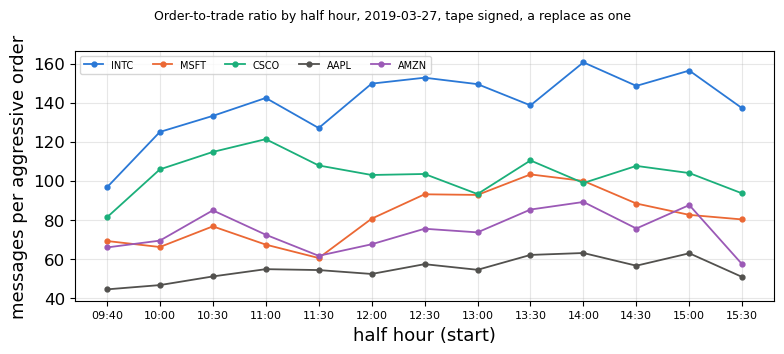


notebook 14, seeds 101 to 108, the simulator (a window of 10 units, the model's own orders only: not the same count as a real book's messages):
            OTR (messages a trade) TTO (lots traded a lot ordered)
ZI                    10.22 (0.03)                   0.166 (0.000)
Hawkes ZI             12.93 (0.17)                   0.161 (0.002)
MF 2008                5.43 (0.03)                   0.274 (0.001)
Parlour                2.48 (0.00)                   0.448 (0.000)
Informed ZI            8.65 (0.04)                   0.191 (0.001)
its three rates a unit of simulation time (seeds 1 to 8, the models' defaults; a real stock's are a second):
            events a unit mid changes a unit aggressive orders a unit
ZI                  59.80               4.06                     6.01
Hawkes ZI           59.84               3.90                     6.20
MF 2008             14.57               1.48                     2.75
Parlour             13.27               4.83                    

In [22]:
def otr_report(results, day=DAY):
    # Order-to-trade ratios: messages per aggressive order, the session's (a ratio of sums, which is not a mean of
    # ratios) and by half hour, a replace counted as one message and as two, with the grouping's sensitivity (frames
    # made with merge_within: successive same-side runs of executions within MERGE_WITHIN seconds are one aggressive
    # order) and each unsigned hidden run counted as a message and a trade (the unknown tape). A trade is an aggressive
    # order; deletions and paired reductions inside one are no messages of their own. TTO is the shares traded per
    # share ordered. Returns the session frame.
    rows, strips = {}, {}
    for stock, result in results.items():
        one, two = result['otr']['as one'], result['otr']['as two']
        merged, frames = result['merged'], result['frames']
        replaced = result['tape']['events as two'] - result['tape']['events as one']
        # a replace is two messages of the stream and one of the book: the difference is the replaces' second halves
        assert two['session']['messages'] - one['session']['messages'] == replaced == frames['replace rows'] // 2, (
            f'{stock}: a replace as two messages less a replace as one is not the replaces of the frames'
        )
        assert one['session']['trades'] == two['session']['trades'] == result['tape']['aggressive orders'], (
            f'{stock}: the trades of the order-to-trade ratio are not the aggressive orders'
        )
        for name, part in (('as one', one), ('as two', two)):
            assert sum(part['messages']) == part['session']['messages'], f'{stock}: half hours do not sum, {name}'
            assert sum(part['trades']) == part['session']['trades'], f'{stock}: half-hour trades do not sum, {name}'
            assert math.isclose(
                part['session']['otr'], part['session']['messages'] / part['session']['trades'], rel_tol=1e-12
            ), f'{stock}: the session ratio is not the ratio of its sums, {name}'
        if merged is not None:
            assert merged['aggressive orders'] <= one['session']['trades'], f'{stock}: grouping cannot add orders'
        window = result['otr']['window']
        rows[stock] = {
            'aggressive orders': one['session']['trades'],
            'messages, a replace as one': one['session']['messages'],
            'replaces': replaced,
            'OTR, a replace as one': one['session']['otr'],
            'se (blocks)': one['otr se'],
            'strip se': one['otr strip se'],
            'OTR, a replace as two': two['session']['otr'],
            'merged: as one': math.nan if merged is None else merged['otr as one']['session']['otr'],
            'merged: as two': math.nan if merged is None else merged['otr as two']['session']['otr'],
            'unknown tape: as one': result['otr']['unknown tape, as one']['otr'],
            'TTO, as one': one['session']['tto'],
            'TTO, as two': two['session']['tto'],
            'window form: OTR': window['OTR'],
            'window undefined %': 100 * window['undefined share'],
        }
        strips[stock] = {'as one': one, 'as two': two}
    table = pd.DataFrame(rows).T.infer_objects()
    heading('Order-to-trade ratios, messages per aggressive order', results, day)
    print(
        'The session\'s ratio of sums, a replace as one message and as two; "se (blocks)" is a block bootstrap over '
        f'the half hours ({DRAWS:,} draws) ASSUMING EXCHANGEABLE BLOCKS (they are not) and "strip se" the half-hour '
        'values\' own.'
    )
    print(
        shown(
            table[
                [
                    'aggressive orders',
                    'messages, a replace as one',
                    'replaces',
                    'OTR, a replace as one',
                    'se (blocks)',
                    'strip se',
                    'OTR, a replace as two',
                    'TTO, as one',
                    'TTO, as two',
                ]
            ],
            {
                'aggressive orders': ',.0f',
                'messages, a replace as one': ',.0f',
                'replaces': ',.0f',
                'OTR, a replace as one': '.1f',
                'se (blocks)': '.1f',
                'strip se': '.1f',
                'OTR, a replace as two': '.1f',
                'TTO, as one': '.4f',
                'TTO, as two': '.4f',
            },
        )
    )
    print(
        f'\nSensitivities: "merged" takes executions of one side within {1e6 * MERGE_WITHIN:.0f} microseconds as one '
        'aggressive order; "unknown tape" counts each unsigned hidden run as a message and a trade (a replace as '
        'one); "window form" is notebook 14\'s own figure (the mean over the units with a trade in the last 10 '
        'units, with the share of units where there is none), here for the comparison with the simulator: it is not '
        'the ratio of sums.'
    )
    print(
        shown(
            table[
                ['merged: as one', 'merged: as two', 'unknown tape: as one', 'window form: OTR', 'window undefined %']
            ],
            {
                'merged: as one': '.1f',
                'merged: as two': '.1f',
                'unknown tape: as one': '.1f',
                'window form: OTR': '.1f',
                'window undefined %': '.1f',
            },
        )
    )
    print('\nBeside, the three rates a second:')
    print(shown(rates_beside(results), RATE_FORMATS))
    for name, label in (('as one', 'a replace as one message'), ('as two', 'a replace as two messages')):
        print(f'\nmessages per aggressive order by half hour, {label}:')
        print(stock_strips(results, lambda r, name=name: r['otr'][name]['otr'], 1, 1.0, 7, 'stock'))
    print('\naggressive orders in each half hour:')
    print(stock_strips(results, lambda r: r['otr']['as one']['trades'], 0, 1.0, 7, 'stock'))
    print('\nmessages in each half hour, a replace as one:')
    print(stock_strips(results, lambda r: r['otr']['as one']['messages'], 0, 1.0, 8, 'stock'))
    fig, ax = plt.subplots(figsize=(8.0, 3.6))
    plot_strips(results, lambda r: r['otr']['as one']['otr'], 'messages per aggressive order', ax=ax)
    fig.suptitle(figure_title('Order-to-trade ratio by half hour', results, day), fontsize=9)
    fig.tight_layout()
    plt.show()
    return table


if need(DAY):
    otr_table = otr_report(measured(DAY), DAY)
    show_nb14(
        {
            'OTR (messages a trade)': 'OTR (messages a trade)',
            'TTO (lots traded a lot ordered)': 'TTO (lots traded a lot ordered)',
        },
        'a window of 10 units, the model\'s own orders only: not the same count as a real book\'s messages',
    )

TODO(prose): The session's ratio ("Order-to-trade ratios"). For each stock: messages per aggressive order with a replace as one message, its block-bootstrap standard error (ASSUMING EXCHANGEABLE BLOCKS) and the strip's own beside it, and the ratio with a replace as two beside; the number of replaces is the difference in messages. Say what the ratio is (every participant's messages over aggressive orders) and that notebook 14's figure counts the model's own orders over a window and is not the same count.

TODO(prose): The sensitivities ("Order-to-trade ratios"). How much the merged grouping moves each stock's ratio and its count of aggressive orders (a one-number ratio is a statement under one grouping), what the unknown tape changes, and the window form's mean against the ratio of sums with its undefined share of units; the window form is for the comparison with the simulator only.

TODO(prose): The half-hour strip ("Order-to-trade ratios", the figure). For each stock the lowest and the highest half hour and where they fall, the aggressive orders in the thinnest half hour (a ratio over few orders is noisy), and that the half hours are not exchangeable; no pattern is said to hold across stocks, and no two stocks are said to differ.

### Resilience

**The question.** When a take or a cancel leaves the depth near the touch below half its baseline, how often does the quote move away before the depth comes back, how long does the recovery take when it does, and how quickly does the quote itself come back after a take that moved it (Large's restoration)?

**What is measured.** The depth is the visible shares at the K = 3 prices from the side's best quote, a tick a cent; the baseline is the median of the once-a-unit samples over the last 100 units. An episode starts when a take or a cancel leaves that depth below 0.5 of the baseline, keeps those prices as its anchor, and ends *recovered* when the depth there is back at 0.9 of the baseline, or *abandoned* when the best quote has moved more than K ticks from the anchor or the side is empty. The onset "below the line" is the dashboard's; "crossing" counts only the falls through the line and is printed beside it. A limit order that improves the quote never starts an episode. Large's restoration is the share of the takes that moved the quote that a limit order put back within 30 seconds, and after how long. The identity (shares arrived less canceled less taken equals the change in depth over an episode) is counted, never asserted: a hidden or a priced execution takes shares that the book does not show.

**What cannot be compared.** K is fixed in ticks, so it is a different distance in each stock's spreads: a stock whose median spread is six ticks has a reach of half its spread, and one whose spread is a tick has three spreads. Every table below therefore starts with K in spreads, the number of episodes and the abandoned share, a stock's figures are its own, and no table or sentence sets one stock's resilience against another's. A half-hour strip is shown only for a half hour with 30 ended episodes or more.

**What notebook 14 found in the simulator** (seeds 101 to 108, K = 3 prices, onset below; a unit is the simulator's unit of time): the recovered share of ended episodes was 0.41 (se 0.01), 0.23 (0.02), 0.54 (0.01), 0.07 (0.00) and 0.33 (0.01) in ZI, Hawkes ZI, MF 2008, Parlour and Informed ZI, the median recovery 32.0 (1.4), 24.4 (1.1), 24.6 (1.7), 2.6 (0.1) and 18.6 (0.6) units, Large's restoration within 30 units 0.984, 0.979, 0.940, 0.974 and 0.983, the identity's largest gap 0 in every run, and the shifting-window definition (depth measured from the side's current best quote) 14.3, 7.0, 5.3, 1.3 and 11.2 times the anchored definition's episodes.

**What the exploration stocks showed** (exploration: NVDA and CMCSA, 2019-03-27; each stock's own figures, with K in its own spreads). On NVDA the reach was 0.50 of the median spread; there were 11,054 episodes, an abandoned share of 0.636 and a median recovery of 1.00 s, 0.00 s in the first half hour (about half of the first half hour's recovered episodes lasted under a millisecond, in a burst of a few minutes), the quote was put back within 30 s after 0.762 of the takes that moved it, 253 of the 344 episodes whose identity had a gap took a hidden or priced lot, and the shifting-window definition started 0.98 times the episodes. On CMCSA the reach was 3.00 spreads; there were 65 episodes, an abandoned share of 0.108 and a median recovery of 7.44 s, no half hour with 30 episodes (so no strip), the quote put back within 30 s after 0.756 of the takes, all 6 of the episodes with a gap took a hidden or priced lot, and the shifting-window definition started 0.92 times the episodes.

**What is run.** For each stock on the day, recovery under both onsets, restoration and the refill, the identity and the shifting-window definition, and the figures by the spread before the starting event, each with K in spreads, the episodes and the abandoned share in front, and notebook 14's figures beside; then the half-hour strips, only where a half hour has the episodes for one, and a figure with a panel for each stock that has one.

In [23]:
def resil_lead(results, onset):
    # What goes beside every resilience figure: the reach in spreads (K = RESILIENCE_TICKS ticks over the stock's median
    # spread), the number of episodes and the share of them abandoned before the depth came back
    lead = {}
    for stock, result in results.items():
        r = result['resilience'][onset]
        assert math.isclose(
            r['reach: ticks in median spreads (unit samples)'],
            RESILIENCE_TICKS / r['median spread (ticks)'],
            rel_tol=1e-12,
        ), f'{stock}: the reach in spreads is not K over the median spread'
        if r['ended']:
            assert math.isclose(r['recovered share'] + r['abandoned share'], 1.0, abs_tol=1e-12), f'{stock}: shares'
        lead[stock] = {
            'K in spreads': r['reach: ticks in median spreads (unit samples)'],
            'episodes': r['episodes'],
            'abandoned': r['abandoned share'],
        }
    return pd.DataFrame(lead).T.infer_objects()


def resil_report(results, day=DAY):
    # Resilience: episodes of depleted depth within K = RESILIENCE_TICKS ticks of the touch (depleted below 0.5 of a
    # rolling-median baseline, recovered at 0.9, each episode anchored where it began), how often the quote moves away
    # from the anchor before the depth recovers (abandoned), how long recovery takes, Large's restoration of the quote,
    # what arrives and leaves while an
    # episode is open, the identity arrived - canceled - taken = change in depth COUNTED (a hidden or priced lot taken
    # breaks it) and the shifting-window definition beside. Every table starts with K in spreads, the episodes and the
    # abandoned share. K is fixed in ticks, so it is a different distance in each stock's spreads: no two stocks'
    # figures are to be compared. Returns the frames.
    frames = {}
    boot = {stock: result['resilience bootstrap'] for stock, result in results.items()}
    for onset in ('below', 'crossing'):
        lead = resil_lead(results, onset)
        r = {stock: result['resilience'][onset] for stock, result in results.items()}
        extra = pd.DataFrame(
            {
                stock: {
                    'abandoned at once': 100 * r[stock]['abandoned at once (zero length) share'],
                    'recovered': r[stock]['recovered share'],
                    'a second': r[stock]['started a unit'],
                    'median recovery (s)': r[stock]['median recovery'],
                    'p90 (s)': r[stock]['p90 recovery'],
                }
                for stock in results
            }
        ).T
        if onset == 'below':
            extra['abandoned se'] = pd.Series({stock: boot[stock]['abandoned share se'] for stock in results})
            extra['median recovery se'] = pd.Series({stock: boot[stock]['median recovery se'] for stock in results})
        frames[onset] = lead.join(extra)
    heading('Resilience: recovery of the depth within K ticks of the touch', results, day)
    print(
        f'K = {RESILIENCE_TICKS} ticks, a tick a cent: "K in spreads" is K over the stock\'s median spread. An '
        'episode begins when a take or a cancel leaves the depth at the K prices from the side\'s best quote below '
        'half its baseline (the median of the last 100 unit samples); it keeps those prices as its anchor and ends '
        'recovered when the depth there is back at 0.9 of the baseline, or abandoned when the best quote has moved '
        'more than K ticks from the anchor or the side is empty ("abandoned at once": the share of the abandoned '
        'that ended in the instant they began). Onset "below" is the dashboard\'s; "crossing" counts only the falls '
        'through the line. The standard errors are a block bootstrap ASSUMING EXCHANGEABLE BLOCKS. Times are '
        'seconds.'
    )
    print('\nOnset below the line:')
    print(
        shown(
            frames['below'],
            {
                'K in spreads': '.2f',
                'episodes': ',.0f',
                'abandoned': '.3f',
                'abandoned at once': '.1f',
                'recovered': '.3f',
                'a second': '.4f',
                'median recovery (s)': '.2f',
                'p90 (s)': '.1f',
                'abandoned se': '.3f',
                'median recovery se': '.2f',
            },
        )
    )
    print('\nOnset crossing the line:')
    print(
        shown(
            frames['crossing'].drop(columns=['abandoned at once']),
            {
                'K in spreads': '.2f',
                'episodes': ',.0f',
                'abandoned': '.3f',
                'recovered': '.3f',
                'a second': '.4f',
                'median recovery (s)': '.2f',
                'p90 (s)': '.1f',
            },
        )
    )
    # Large's restoration, the refill and the identity, onset below
    lead, r = resil_lead(results, 'below'), {stock: result['resilience']['below'] for stock, result in results.items()}
    wanted = {
        'quote-moving takes a second': 'quote-moving takes a unit',
        'restored within 30 s': 'restored share',
        'median restoration (s)': 'median restoration',
        'restorations': 'restorations',
        'baseline depth (shares)': 'baseline depth (shares)',
        'arrived a second': 'arrived a unit of episode time',
        'canceled a second': 'canceled a unit of episode time',
        'taken a second': 'taken a unit of episode time',
        'net a second': 'net a unit',
        'median deficit': 'median deficit',
        'median gained': 'median depth gained',
    }
    refill = lead.join(pd.DataFrame({stock: {k: r[stock][v] for k, v in wanted.items()} for stock in results}).T)
    frames['refill'] = refill
    print(
        '\nLarge\'s restoration (of the takes that moved the quote, the share that a limit order put back within 30 '
        's) and what arrives, is canceled and is taken a second of episode time, in shares, over the recovered '
        'episodes:'
    )
    print(
        shown(
            refill,
            {
                'K in spreads': '.2f',
                'episodes': ',.0f',
                'abandoned': '.3f',
                'quote-moving takes a second': '.3f',
                'restored within 30 s': '.3f',
                'median restoration (s)': '.2f',
                'restorations': ',.0f',
                'baseline depth (shares)': ',.0f',
                'arrived a second': ',.1f',
                'canceled a second': ',.1f',
                'taken a second': ',.1f',
                'net a second': ',.1f',
                'median deficit': ',.0f',
                'median gained': ',.0f',
            },
        )
    )
    gap_names = {
        'episodes with a gap': 'identity: episodes with a gap',
        'share of ended': 'identity: share of ended episodes with a gap',
        'took a hidden or priced lot': 'identity: gaps in episodes that took a hidden or priced lot',
        'largest gap (shares)': 'identity: largest gap (shares)',
        'shifting-window episodes a second': 'shifting-window episodes a unit',
        'times as many': 'shifting times as many',
        'from a quote-improving arrival': 'shifting: share started by a quote-improving arrival',
    }
    gaps = lead.join(pd.DataFrame({stock: {k: r[stock][v] for k, v in gap_names.items()} for stock in results}).T)
    frames['identity'] = gaps
    for stock in results:
        assert gaps.loc[stock, 'took a hidden or priced lot'] <= gaps.loc[stock, 'episodes with a gap'], (
            f'{stock}: gaps'
        )
    print(
        '\nThe identity arrived - canceled - taken = change in depth, counted on every ended episode (it fails where '
        'a hidden or priced lot was taken, which the book does not show), and the shifting-window definition (depth '
        'measured from the side\'s current best quote), which counts episodes that the anchored definition does not:'
    )
    print(
        shown(
            gaps,
            {
                'K in spreads': '.2f',
                'episodes': ',.0f',
                'abandoned': '.3f',
                'episodes with a gap': ',.0f',
                'share of ended': '.3f',
                'took a hidden or priced lot': ',.0f',
                'largest gap (shares)': ',.0f',
                'shifting-window episodes a second': '.4f',
                'times as many': '.2f',
                'from a quote-improving arrival': '.3f',
            },
        )
    )
    # by the spread before the starting event: a class with under RESILIENCE_STRIP_MIN episodes is a count only
    rows, index = [], []
    reach = {
        0: f'{RESILIENCE_TICKS / 1:.2f}',
        1: f'{RESILIENCE_TICKS / 2:.2f}',
        2: f'at most {RESILIENCE_TICKS / 3:.2f}',
    }
    for stock in results:
        total = 0
        for k, label in enumerate(CLASSES):
            c = r[stock]['by spread: ' + label]
            total += c['episodes']
            enough = c['episodes'] >= RESILIENCE_STRIP_MIN
            rows.append(
                {
                    'K in spreads': reach[k],
                    'episodes': c['episodes'],
                    'abandoned': 1 - c['recovered share'] if enough else math.nan,
                    'median recovery (s)': c['median recovery'] if enough else math.nan,
                }
            )
            index.append((stock, label))
        assert total <= r[stock]['ended'], f'{stock}: more episodes by spread class than ended episodes'
    by_class = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'spread before']))
    frames['by spread'] = by_class
    print(
        f'\nBy the spread before the starting event (ended episodes; a class with under {RESILIENCE_STRIP_MIN} '
        'episodes is a count only):'
    )
    print(shown(by_class, {'episodes': ',.0f', 'abandoned': '.3f', 'median recovery (s)': '.2f'}))
    print(
        '\nbeside, the three rates a second (a replace as one), and the median spread in ticks the reach is measured '
        'against:'
    )
    beside = rates_beside(results).join(
        stock_table(results, {'median spread (ticks)': lambda x: x['tape']['median spread (ticks, unit samples)']})
    )
    print(shown(beside, {'events a second': '.2f', 'mid changes a second': '.3f', 'median spread (ticks)': '.1f'}))
    print(
        'K is fixed in ticks, so a stock with a wide spread has a reach of a fraction of its spread and one with a '
        f'one-cent spread has {RESILIENCE_TICKS} spreads: no figure above is to be compared between two stocks.'
    )
    return frames


if need(DAY):
    resil_tables = resil_report(measured(DAY), DAY)
    show_nb14(
        {
            'baseline depth (lots)': 'baseline depth (lots)',
            'episodes a unit': 'episodes a unit',
            'recovered share': 'recovered share',
            'median recovery (units)': 'median recovery (units)',
            '90th percentile': '90th percentile',
        },
        'onset below, K = 3 prices; a unit is the simulator\'s unit of time and a lot is 5 shares',
    )
    show_nb14(
        {
            'quote-moving takes a unit': 'quote-moving takes a unit',
            'restored within 30 units': 'restored within 30 units',
            'median restoration (units)': 'median restoration (units)',
            'crossing: recovered share': 'crossing: recovered share',
            'crossing: median recovery': 'crossing: median recovery',
            'shifting-window episodes a unit': 'shifting-window episodes a unit',
            'times as many': 'times as many',
        },
        'restoration, the crossing onset and the shifting-window definition',
    )


Resilience: recovery of the depth within K ticks of the touch: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a
replace as one.
K = 3 ticks, a tick a cent: "K in spreads" is K over the stock's median spread. An episode begins when a take or a cancel leaves the depth at the K prices from the side's best quote below half its baseline (the median of the last 100 unit samples); it keeps those prices as its anchor and ends recovered when the depth there is back at 0.9 of the baseline, or abandoned when the best quote has moved more than K ticks from the anchor or the side is empty ("abandoned at once": the share of the abandoned that ended in the instant they began). Onset "below" is the dashboard's; "crossing" counts only the falls through the line. The standard errors are a block bootstrap ASSUMING EXCHANGEABLE BLOCKS. Times are seconds.

Onset below the line:
     K in spreads episodes abandoned abandoned at once recovered a second median recovery (s) p90 (s) abandoned se median


notebook 14, seeds 101 to 108, the simulator (onset below, K = 3 prices; a unit is the simulator's unit of time and a lot is 5 shares):
            baseline depth (lots) episodes a unit recovered share median recovery (units) 90th percentile
ZI                        190 (9)   0.048 (0.001)     0.41 (0.01)              32.0 (1.4)      91.8 (4.5)
Hawkes ZI                220 (18)   0.091 (0.008)     0.23 (0.02)              24.4 (1.1)      65.0 (4.7)
MF 2008                  155 (11)   0.041 (0.001)     0.54 (0.01)              24.6 (1.7)      82.8 (4.5)
Parlour                    34 (2)   0.639 (0.006)     0.07 (0.00)               2.6 (0.1)       7.4 (0.4)
Informed ZI               202 (8)   0.083 (0.002)     0.33 (0.01)              18.6 (0.6)      58.1 (2.2)
its three rates a unit of simulation time (seeds 1 to 8, the models' defaults; a real stock's are a second):
            events a unit mid changes a unit aggressive orders a unit
ZI                  59.80               4.06    


notebook 14, seeds 101 to 108, the simulator (restoration, the crossing onset and the shifting-window definition):
            quote-moving takes a unit restored within 30 units median restoration (units) crossing: recovered share crossing: median recovery shifting-window episodes a unit times as many
ZI                        2.09 (0.01)            0.984 (0.000)                0.58 (0.00)               0.67 (0.02)                17.1 (0.8)                   0.692 (0.006)          14.3
Hawkes ZI                 1.95 (0.05)            0.979 (0.001)                0.50 (0.00)               0.55 (0.02)                14.1 (1.2)                   0.635 (0.017)           7.0
MF 2008                   0.76 (0.01)            0.940 (0.001)                1.71 (0.02)               0.66 (0.01)                17.4 (0.4)                   0.217 (0.004)           5.3
Parlour                   2.71 (0.01)            0.974 (0.001)                0.79 (0.01)               0.17 (0.00)                 


Resilience by half hour: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
A half hour is a value only where at least 30 episodes ended in it (restorations: that many quote-moving takes); the half hours from the open, the first and the last cut to the session.

INTC: K = 3.00 spreads, 66 episodes, abandoned 0.182; 0 of 13 half hours have 30 episodes or more.
episodes  09:40   10:00   10:30   11:00   11:30   12:00   12:30   13:00   13:30   14:00   14:30   15:00   15:30
INTC         19      15       6       4      11       3       3       0       1       1       1       0       2
no strip: no half hour has enough episodes.
Large's restoration (the quote put back after a take that moved it: a different count, at least 30 takes resolved in a half hour):
median s  09:40   10:00   10:30   11:00   11:30   12:00   12:30   13:00   13:30   14:00   14:30   15:00   15:30
INTC       2.02    2.52    2.03    3.28    2.00    2.86    2.77    3.64    2.82    3.05    3.50    3.62 

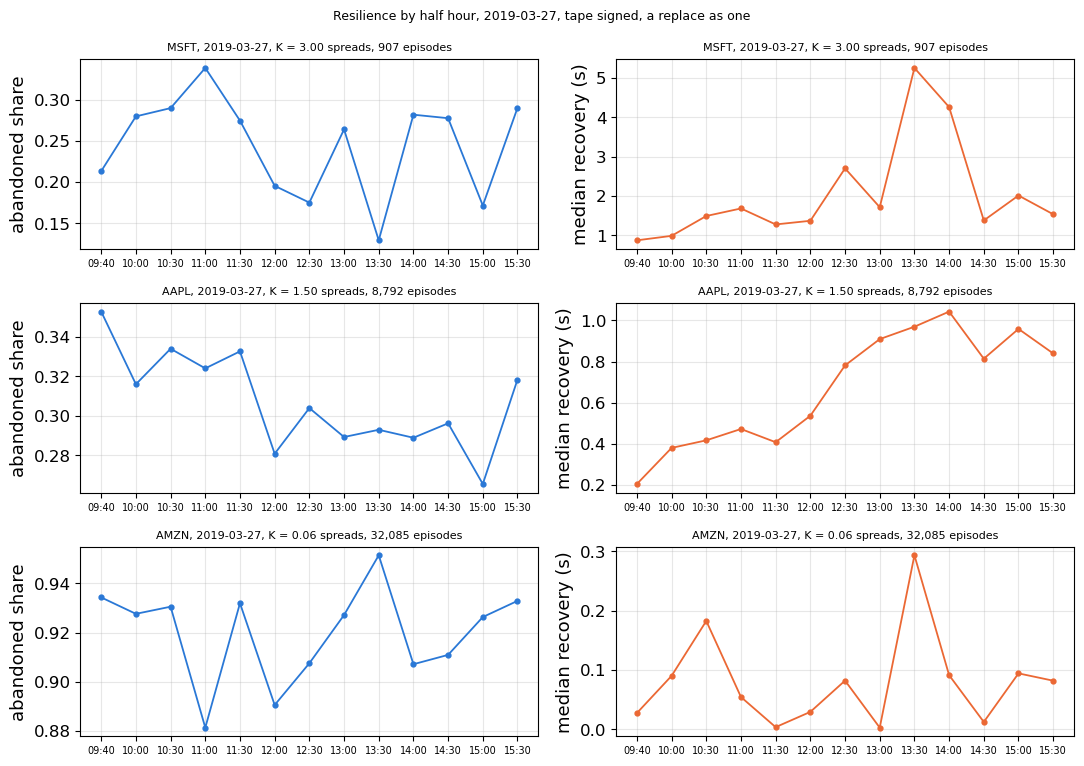

In [24]:
def resil_report_strips(results, day=DAY):
    # Resilience by half hour, only where a half hour has RESILIENCE_STRIP_MIN ended episodes or more (a restoration
    # strip where it has that many restorations): a stock with no such half hour shows its counts and no strip. Each
    # stock is its own panel with its own axis, since K is a different distance in each stock's spreads and the figures
    # are not to be compared. Returns {stock: the strips shown}.
    shown_strips = {}
    heading('Resilience by half hour', results, day)
    print(
        f'A half hour is a value only where at least {RESILIENCE_STRIP_MIN} episodes ended in it (restorations: that '
        'many quote-moving takes); the half hours from the open, the first and the last cut to the session.'
    )
    for stock, result in results.items():
        r = result['resilience']['below']
        ended = np.array(r['blocks: ended episodes'])
        abandoned, recovery = np.array(r['blocks: abandoned share']), np.array(r['blocks: median recovery'])
        assert len(ended) == len(HAVE_BLOCKS) and len(abandoned) == len(HAVE_BLOCKS), f'{stock}: a value a half hour'
        assert np.isfinite(abandoned).sum() == r['blocks with a strip'] == (ended >= RESILIENCE_STRIP_MIN).sum(), (
            f'{stock}: the abandoned strip has a value in a half hour that has under {RESILIENCE_STRIP_MIN} episodes'
        )
        assert not (np.isfinite(abandoned) & (ended < RESILIENCE_STRIP_MIN)).any(), f'{stock}: a thin half hour shown'
        assert r['strip shown'] == bool(r['blocks with a strip']), f'{stock}: strip shown is not blocks with a strip'
        print(
            f'\n{stock}: K = {fmt(r["reach: ticks in median spreads (unit samples)"], 2)} spreads, {r["episodes"]:,} '
            f'episodes, abandoned {fmt(r["abandoned share"], 3)}; {r["blocks with a strip"]} of {len(HAVE_BLOCKS)} '
            f'half hours have {RESILIENCE_STRIP_MIN} episodes or more.'
        )
        one = {stock: result}
        print(stock_strips(one, lambda x: x['resilience']['below']['blocks: ended episodes'], 0, 1.0, 7, 'episodes'))
        if r['strip shown']:
            print(
                stock_strips(one, lambda x: x['resilience']['below']['blocks: abandoned share'], 3, 1.0, 7, 'abandoned')
            )
            print(
                stock_strips(
                    one, lambda x: x['resilience']['below']['blocks: median recovery'], 2, 1.0, 7, 'recovery s'
                )
            )
            shown_strips[stock] = {'abandoned': abandoned, 'median recovery': recovery}
        else:
            print('no strip: no half hour has enough episodes.')
        restoration = r['blocks: median restoration']
        if np.isfinite(restoration).any():
            print(
                'Large\'s restoration (the quote put back after a take that moved it: a different count, at least '
                f'{RESILIENCE_STRIP_MIN} takes resolved in a half hour):'
            )
            print(
                stock_strips(
                    one, lambda x: x['resilience']['below']['blocks: median restoration'], 2, 1.0, 7, 'median s'
                )
            )
    if shown_strips:
        fig, axes = plt.subplots(len(shown_strips), 2, figsize=(11.0, 2.6 * len(shown_strips)), squeeze=False)
        x = np.arange(len(HAVE_BLOCKS))
        for row, (stock, strip) in enumerate(shown_strips.items()):
            for column, (name, label, color) in enumerate(
                (('abandoned', 'abandoned share', BLUE), ('median recovery', 'median recovery (s)', ORANGE))
            ):
                ax = axes[row, column]
                ax.plot(x, strip[name], marker='o', markersize=3.5, linewidth=1.3, color=color)
                ax.set_xticks(x, [BLOCK_LABELS[b] for b in HAVE_BLOCKS], fontsize=7)
                ax.set_ylabel(label)
                reach = results[stock]['resilience']['below']['reach: ticks in median spreads (unit samples)']
                episodes = results[stock]['resilience']['below']['episodes']
                ax.set_title(
                    f'{stock}, {day_text(day)}, K = {reach:.2f} spreads, {episodes:,} episodes'
                    + (' (exploration)' if stock in EXPLORED else ''),
                    fontsize=8,
                )
        fig.suptitle(figure_title('Resilience by half hour', results, day), fontsize=9)
        fig.tight_layout()
        plt.show()
    else:
        print('\nNo stock has a half hour with enough episodes: no figure.')
    return shown_strips


if need(DAY):
    resil_strips = resil_report_strips(measured(DAY), DAY)

TODO(prose): Recovery ("Resilience: recovery of the depth"). For each stock, in a sentence of its own: K in spreads, the number of episodes, the abandoned share with its block-bootstrap standard error (ASSUMING EXCHANGEABLE BLOCKS), the recovered share and the median recovery in seconds with its standard error, and the crossing onset's figures beside them. State that each is that stock's on that day with that reach, and that no two stocks' figures are set against each other; where a stock has few episodes (a count under 100), say how few.

TODO(prose): Restoration and the refill ("Resilience: recovery of the depth"). Per stock: the quote-moving takes a second, the share restored within 30 s and the median restoration; what arrives, is canceled and is taken a second of episode time and the net refill, and what that says about how depth comes back (the simulator: the net refill is a fraction of the arrivals, since takes and cancels remove most of them).

TODO(prose): The identity and the shifting-window definition ("Resilience: recovery of the depth"). Per stock: the episodes whose identity (arrived - canceled - taken = change in depth) has a gap, their share of the ended episodes, how many of them took a hidden or priced lot (the identity holds in the simulator only because nothing there is hidden or priced), the shifting-window definition's episodes as a multiple of the anchored and the share it starts at a quote-improving arrival (the simulator: 1.3 to 14.3 times, 98.0 to 99.7% quote-improving).

TODO(prose): By the spread before the starting event and by half hour ("Resilience: recovery of the depth" and "Resilience by half hour"). Which spread classes have 30 episodes or more and what the abandoned share and the median recovery are there; which stocks have a half-hour strip (the half hours with 30 ended episodes or more), what it shows for each, and, for a stock with no strip, the count of its episodes by half hour; the median recovery in the first half hour if it is near 0 s and what the count there says.

**What this cannot show.**

- *Anything wider than one stock on one day.* Each figure is a stock's on 2019-03-27 (and, in section 6, on the second day). The five stocks share each day's market factor, so a spread across them is a spread and is never called a standard error, and no two stocks are said to differ. The half-hour strips are thirteen values of one day, and the block bootstrap that is printed assumes that the half hours are exchangeable, which they are not (the first has 1.3 to 1.8 times the day's message rate in the stocks the design review looked at): its standard error is printed with the strip's own beside it and is never the uncertainty of the stock.
- *That VPIN measures toxicity or informed trading.* It is how one-sided the signed volume of a bucket is: how often, at the scale of a bucket, a buy follows a buy. The excess over a null says that the signs are more persistent than random signs on the same fills; it does not say why, and there is no truth here to test it against (the simulator has an informed share in one model; a real day has none to read). Nothing in these cells is about the informed share, about a loss to a maker, about queue position or about P&L.
- *That an excess is a number.* A VPIN excess moves with where the buckets start (the range across 11 origins is printed with every one), with the tape (the none tape is beside the signed), with the grouping of executions into orders (the grouping changes the fair-coin null's draws as it changes the number of orders) and with the fill sizes that V is set from. VPIN is not defined at the start of the session: it is first defined after 50 buckets have closed, and the time is printed. A level is not compared with a threshold or with another stock's level.
- *Volume the tape does not sign.* The hidden executions that no displayed run signs never reach a signed VPIN, and the shares left out are printed beside every table; a VPIN with true sides is the sides that the stream gives, which for a hidden execution inside a displayed run are that run's.
- *Bulk volume classification as flow.* Its level reads changes of the mid and not signed volume (section 3 shows this beside the share of buckets whose mid did not change).
- *An order-to-trade ratio of a stock or a market.* It is messages over aggressive orders on one day, under one grouping and one way of counting a replace; it counts every participant's messages and not only the orders of any one trader, and a mean of window ratios is not the ratio of sums.
- *Resilience between stocks, or as a property of a stock.* K is fixed in ticks, so it is a different reach in each stock's spreads; the abandoned share, the recovery times and the counts of episodes are what that reach gives on that day, and a cancel rate or a refill rate read from them is not a property of the stock. Where a stock has under 30 episodes in a half hour there is no strip, and where it has a few dozen in the day (the exploration's CMCSA had 65) the day's own figures are the count and little else. The identity of arrivals, cancels, takes and the change in depth is counted and never asserted: a hidden or a priced execution takes shares that the book does not show.
- *What follows from the simulator's figures.* A real figure near the simulator's is a description, nothing is called a match, and nothing here says the simulator matches a market.

TODO(prose): Section 2's second half in a sentence or two: which of notebook 14's VPIN, order-to-trade and resilience findings appeared on each stock on the first day (the VPIN excess above 0 at every origin, the same-side share, the abandoned share and the reach), counted over the five stocks, with every excess given with its origin range and every resilience figure with its reach in spreads; and what is left to the second day.

## Section 3: What is the estimator's

**The question.** A finding is the estimator's, and not a book's, when it follows from how the quantity is computed and so holds on any stream. Section 2 set real figures beside the simulator's and asked whether a simulator finding's sign or ordering appeared. This section asks which of notebook 14's findings would have appeared on whatever book the collectors were run on: a rule that is exact by construction, a measure that reads price changes and not flow, and a pairing that scores a state against a change it has already seen. Each is checked on the real stocks as an identity or a check and is not set beside the simulator as a result.

### The look-ahead trap

**What notebook 14 found.** VisualHFT's research note R-002 reported that pairing an imbalance with a bucket's open time inflated a result. Notebook 14 tested the pairing on the simulator's once-a-unit samples: the sample taken at the start of unit u is the state at the end of unit u - 1, so it can be paired with the change of the mid over unit u - 1, which it has just seen (as a join on a bucket's open time does), or with the change over unit u, which follows it (the causal pairing). Units with no change and zero readings are left out. In the simulator the pairing that looks ahead gave a sign agreement of 22.6 to 29.1% at L 1 in its five models and the causal one 67.8 to 73.3% (seeds 101 to 108; the lines are quoted below from its saved output). The sign of the bias depends on the book's queues: R-002's pairing inflated a result, and here it has the opposite sign, because (in the reviews' reading, which notebook 14 did not test) a move exposes a deep level and the end-of-unit imbalance then points back at the reversal.

**What section 2 does instead.** Its reading is the first event after a change of the mid that leaves the mid alone and gives a nonzero imbalance (notebook 14's strict design, R-001's event design), scored against the direction of the next change within 30 seconds. The reading comes before the change it is scored against, so the study does not make the trap. The inclusive design lets the change event's own state give the reading, which is a different question and drops fewer changes; it is shown beside the strict one below, and neither is the unit pairing.

**What the exploration stocks showed** (exploration: NVDA and CMCSA, the first day). At L 1 the sample paired with the same unit agreed in sign on 50.4% (NVDA) and 41.3% (CMCSA) of the units with a change and a reading, and paired with the next unit on 56.8% and 83.6%.

**What is run.** Nothing new: the pairing counts (every setting; L 1 and touch-weighted L 10 are printed, as notebook 14 printed them) and the strict and inclusive designs' class tables are in each stock's `measure` result. The pairing is a property of how a sample is joined to a change, so it is true on any stream; the size of the gap between the two pairings is the book's.


The look-ahead trap: the sample of the imbalance paired with the change over the same unit and the next: 2019-03-27,
session 09:40:00 to 15:50:00, tape signed, a replace as one.
Sign agreement of the once-a-unit sample with the change of the mid, percent of the units with a change and a reading;
50% is what a sample that knows nothing gives.
                same unit: n same unit % next unit: n next unit % next minus same, pp
INTC L 1 equal         3,721        52.9        3,737        80.2                27.3
     L 10 touch        3,745        56.0        3,745        78.7                22.8
MSFT L 1 equal        10,039        42.0       10,024        67.2                25.2
     L 10 touch       10,341        44.9       10,340        65.6                20.7
CSCO L 1 equal         3,400        42.0        3,412        81.2                39.2
     L 10 touch        3,426        46.0        3,426        79.5                33.5
AAPL L 1 equal        13,895        47.2       13,881

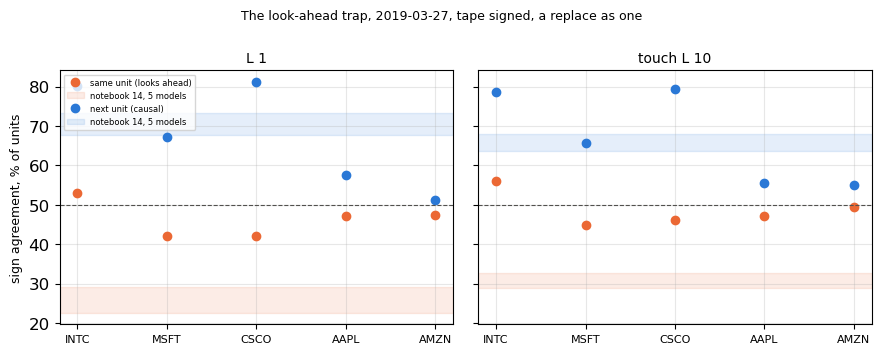

In [25]:
# Section 3, the look-ahead trap: the once-a-unit sample of the imbalance paired with the change of the mid over the
# SAME unit (the pairing that looks ahead: the sample at the start of a unit is the state at the end of the unit before,
# which it has already seen) and over the NEXT unit (the causal one); and the strict event design (the first event that
# leaves the mid alone gives the reading) beside the inclusive one. Functions of a dict of measure() results by stock.
# This cell needs the setup only (it reads notebook 14's saved output itself). With the data absent it prints one
# line.
TRAP_SETTINGS = {
    'L 1 equal': 'L 1',
    'L 10 touch': 'touch L 10',
}  # the settings notebook 14 printed, and its name for each
TRAP_PAIRINGS = (  # the pairing's key, its name, its color, and the heading of notebook 14's column (after 'L 1: ')
    ('same unit', 'same unit (looks ahead)', ORANGE, 'end of the unit against the same unit %'),
    ('next unit', 'next unit (causal)', BLUE, 'against the next unit %'),
)


def trap_table(results):
    # A frame, a row for each stock and setting: the units paired and the sign agreement (percent) of the sample with
    # the change over the same unit and over the next, and the next's lead in points
    rows = {}
    for stock, r in results.items():
        for setting in TRAP_SETTINGS:
            p = r['imbalance']['pairing'][setting]
            rows[stock, setting] = {
                'same unit: n': p['n same'],
                'same unit %': 100 * p['same unit'],
                'next unit: n': p['n next'],
                'next unit %': 100 * p['next unit'],
                'next minus same, pp': 100 * (p['next unit'] - p['same unit']),
            }
    return pd.DataFrame.from_dict(rows, orient='index')


def trap_design_table(results, setting='L 1 equal'):
    # A frame, a row for each stock and spread class: the strict design (the first event that leaves the mid alone gives
    # the reading) and the inclusive one (the change event's own state can): readings, hit rate (percent) and lift over
    # the better baseline in the class (points). A class under MIN_READINGS readings in a design is its count only.
    rows = {}
    for stock, r in results.items():
        for design, name in (('classes', 'strict'), ('inclusive', 'inclusive')):
            table = r['imbalance'][design]
            for cls in CLASSES:
                got = table[(table.setting == setting) & (table['class'] == cls)].iloc[0]
                n = int(got['n'])
                enough = n >= MIN_READINGS
                row = rows.setdefault((stock, cls), {})
                row[f'{name}: n'] = n
                row[f'{name}: hit %'] = 100 * got['hit'] if enough else math.nan
                row[f'{name}: lift pp'] = 100 * got['lift over the better'] if enough else math.nan
    return pd.DataFrame.from_dict(rows, orient='index')


def trap_nb14_pairing(path=NB14_PATH):
    # Notebook 14's table of the two pairings from its saved output, {(model, column heading): text as printed}: each
    # column is a block of lines of its own, so each row is read under the heading line above it (the setup's reader is
    # not used: it misses a heading that is one character wider than its cells). Empty if the notebook or its output is
    # not there.
    try:
        notebook = json.loads(Path(path).read_text())
    except FileNotFoundError:
        return {}
    out, row_of = {}, re.compile(r'^(ZI|Hawkes ZI|MF 2008|Parlour|Informed ZI)\s+([+-]?\d*\.?\d+ \([\d.]+\))$')
    for cell in notebook['cells']:
        for part in cell.get('outputs', []):
            text = ''.join(part.get('data', {}).get('text/plain', []))
            if 'end of the unit against the same unit %' not in text:
                continue
            column = None
            for line in text.splitlines():
                line = line.rstrip().removesuffix('\\').rstrip()
                row = row_of.match(line)
                if row and column:
                    out[row.group(1), column] = row.group(2)
                elif 'unit' in line:
                    column = line.strip()
    return out


def trap_nb14_table():
    # notebook 14's sign agreements of the two pairings, a row a model, as printed (mean over seeds 101 to 108, se in
    # brackets)
    read = trap_nb14_pairing()
    columns = [(label, key) for label in TRAP_SETTINGS.values() for key, _, _, _ in TRAP_PAIRINGS]
    text = {(label, key): text for label in TRAP_SETTINGS.values() for key, _, _, text in TRAP_PAIRINGS}
    rows = {m: [read.get((m, f'{label}: {text[label, key]}'), '-') for label, key in columns] for m in NB14_MODELS}
    return pd.DataFrame.from_dict(rows, orient='index', columns=pd.MultiIndex.from_tuples(columns))


def trap_check(results):
    # What must hold: an agreement is a share, and the class rows of each design add up to the setting's pooled row
    for stock, r in results.items():
        for setting in TRAP_SETTINGS:
            for key in ('same unit', 'next unit'):
                value = r['imbalance']['pairing'][setting][key]
                assert not np.isfinite(value) or 0 <= value <= 1, f'{stock} {setting}: {key} agreement is not a share'
        for design in ('classes', 'inclusive'):
            table = r['imbalance'][design]
            sub = table[table.setting == 'L 1 equal'].set_index('class')
            assert sub.loc[list(CLASSES)].n.sum() == sub.loc['pooled', 'n'], (
                f'{stock} {design}: the classes do not add up'
            )


def trap_figure(results, day=DAY):
    # The two pairings' sign agreement, a panel for each setting, a point a stock; the band is the range of notebook
    # 14's five models' means; the dashed line is 50%, which a sample that knows nothing would give
    fig, axes = plt.subplots(1, len(TRAP_SETTINGS), figsize=(9, 3.6), sharey=True)
    read = trap_nb14_pairing()
    stocks = list(results)
    x = np.arange(len(stocks))
    for ax, (setting, label) in zip(axes, TRAP_SETTINGS.items(), strict=True):
        for key, name, color, text in TRAP_PAIRINGS:
            values = [100 * results[s]['imbalance']['pairing'][setting][key] for s in stocks]
            ax.plot(x, values, marker='o', linestyle='none', color=color, label=name)
            sim = [printed_value(read.get((m, f'{label}: {text}'))) for m in NB14_MODELS]
            sim = [got[0] for got in sim if got is not None]
            if sim:
                ax.axhspan(min(sim), max(sim), color=color, alpha=0.12, label=f'notebook 14, {len(sim)} models')
        ax.axhline(50, color=GRAY, linestyle='--', linewidth=0.8)
        ax.set_xticks(x, stocks, fontsize=8)
        ax.set_title(label, fontsize=10)
        ax.set_ylabel('sign agreement, % of units' if ax is axes[0] else '', fontsize=9)
    axes[0].legend(fontsize=6, loc='upper left')
    fig.suptitle(figure_title('The look-ahead trap', results, day), fontsize=9)
    plt.tight_layout()
    plt.show()


def trap_show(results, day=DAY):
    trap_check(results)
    heading(
        'The look-ahead trap: the sample of the imbalance paired with the change over the same unit and the next',
        results,
        day,
    )
    say(
        'Sign agreement of the once-a-unit sample with the change of the mid, percent of the units with a change and a '
        'reading; 50% is what a sample that knows nothing gives.'
    )
    counts, shares = ('same unit: n', 'next unit: n'), ('same unit %', 'next unit %', 'next minus same, pp')
    print(shown(trap_table(results), dict.fromkeys(counts, ',.0f') | dict.fromkeys(shares, '.1f')))
    say(f'\n{NB14_SEEDS}, the simulator, as printed (mean over seeds, se across seeds in brackets):')
    print(trap_nb14_table().to_string())
    heading(
        'The event design, L 1, by the spread at the reading: strict (the first event that leaves the mid alone gives '
        'the reading; section 2\'s) and inclusive (the change event\'s own state can)',
        results,
        day,
    )
    design = trap_design_table(results)
    formats = {c: ',.0f' if c.endswith(': n') else '.1f' for c in design.columns}
    print(shown(design, formats))
    print('\nThe share of the changes of the mid with no reading is in the table of section 2 beyond the touch.')


if need(DAY):
    trap_results = measured(DAY)
    trap_show(trap_results)
    trap_figure(trap_results)

TODO(prose): The two pairings ("The look-ahead trap"). For each reported stock quote the sign agreement of the once-a-unit sample with the change over the same unit and over the next unit at L 1 and at touch L 10, the units paired, and the gap in points. Say whether the pairing that looks ahead gave a different answer from the causal pairing in that stock (the gap and its sign) and whether it fell below 50%, as it did in all five of notebook 14's models (22.6 to 29.1% against 67.8 to 73.3% at L 1, quoted with its seeds). Say what the gap is: a property of the join (the sample at the start of a unit is the state at the end of the unit before, which it has already seen), true on any stream, with a size that is the book's. Say that notebook 14 found the bias to have the opposite sign to R-002's and that the sign depends on the book's queues, and do not say what a data vendor's pairing would give.

TODO(prose): The event design (the last table of "The look-ahead trap"). Quote, for each stock and class, the readings and the lift over the better baseline under the strict design (section 2's) and the inclusive one, and say how much the choice of design moved them (points and readings). Say that the strict design's reading comes before the change it is scored against and so does not make the trap, and that the inclusive design is a different question (the change event's own state can give the reading), not a look-ahead.

**What this cannot show.**

- *The trap is about a join, not about a stock.* The gap between the two pairings is what the join does to a sample taken at a unit's start; it is true on any stream and says nothing about how well a stock's imbalance predicts. Its size is the book's: it is printed for each stock and setting, and in the simulator it was printed for each model.
- *The two pairings score different units.* A unit with a change and a reading is paired; units with no change, and zero readings, are left out, so the agreement is of the units that moved, and the strict design's hit rate (section 2) is of changes of the mid and not of units.
- *The inclusive design is not tested for a trap.* It is shown beside the strict one to say how much the choice of which event gives the reading moves the figures; a difference between them is a difference of design.
- *One day of each stock.* No two stocks are said to differ; the figures are of that stock on that day.

### The rules that sign trades, and bulk volume classification

Section 3 asks which of notebook 14's findings are the estimator's, true of a rule on any stream, and which are the simulator's. Two sets of rules are left: the rules that give a trade its side from prices and quotes (the tick rule and the quote rule), and bulk volume classification, which gives a bucket a buy share from the change of the mid. On a real stream the true side of a displayed execution is known (it is minus the resting order's side), so each rule can be scored against it; that is what notebook 14 did against the simulator's aggressor.

**The questions.** How often is each rule right, per aggressive order, per lot and per fill, at quote lags of 0, 1 and 5 units, on each tape, by the spread at the fill, with priced executions and hidden fills shown apart and the hidden and the unsigned shares of the executed shares printed beside every accuracy? Does the quote rule at lag 0, which reads the mid just before the fill's event, have no miss at all on displayed executions at their resting price, as it must? And what does bulk volume classification's level read, beside the share of buckets whose mid did not change?

**The rules.** The tick rule signs a fill by the sign of the last change of the fill price (undefined before the first change). The quote rule at lag L signs a fill by its price against the mid that was sampled L units earlier (lag 0: the mid just before the fill's event); a fill at the mid takes the tick rule's sign, as `TradeDelta` does. Per aggressive order is the rule's sign at the order's first displayed fill against the order's aggressor (an order that sweeps several prices counts once); per lot weights each fill by the shares executed (a lot is a share on a real book); per fill counts each fill. Only displayed executions are scored, because their aggressor is known; a hidden execution inside a run of displayed executions takes the run's aggressor and is shown apart, since its side is the run's and not independent; a hidden run alone stays unsigned and is in no accuracy. The "signed" tape is the stream as it is, and the "none" tape is the same without its hidden executions, which changes the tick rule's price sequence, and with it the sign that a quote rule gives a fill at the mid; both are printed wherever the two differ.

**What notebook 14 found in the simulator** (its saved output, seeds 101 to 108, per fill, the mean over seeds and its standard error across them). The tick rule was right on 92.2 (se 0.0), 92.8 (0.1), 94.7 (0.1), 90.5 (0.1) and 90.5 (0.1)% of fills in ZI, Hawkes ZI, MF 2008, Parlour and Informed ZI; the quote rule at lag 0 on 100.0% by construction, a check and not a result; at lag 1 on 90.1, 90.2, 95.4, 86.8 and 87.5%, and at lag 5 on 77.4, 80.4, 84.8, 72.4 and 77.4%. The tick rule was above the quote rule at lag 1 in four of the five models. Per bucket of 250 lots the correlation of the tick rule's buy share with the true one was 0.79, 0.80, 0.95, 0.77 and 0.86, and of bulk volume classification's 0.45, 0.37, 0.71, 0.50 and 0.43, whose mean absolute error was 0.200 to 0.233 against the tick rule's 0.028 to 0.043; and bulk volume classification's VPIN read 0.471 to 0.524 in every model, because when its standardized change is normal, |2 Phi(x) - 1| is uniform on (0, 1) with mean one half whatever the flow.

**What the exploration stocks showed** (exploration: NVDA and CMCSA, 2019-03-27; each stock's own figures). The quote rule at lag 0 read 100.00% on every one of the 20,637 (NVDA) and 15,909 (CMCSA) displayed fills at their resting price, and fell short of it only through the priced executions (98 and 358 fills, a cent off their order's price) when these were included. Per aggressive order the quote rule at lag 1 was right on 89.69% (NVDA) and 83.20% (CMCSA) against the tick rule's 87.46% and 64.14%: the order of the two rules that notebook 14 found in four of its five models was reversed on both stocks, and within NVDA it flips with the spread at the fill (the tick rule above the quote rule at lag 1 at spreads of one and two ticks, below it at three ticks or more). The hidden shares of the executed shares were 16.64% and 9.45% and the unsigned shares 11.38% and 6.53%. Bulk volume classification's level was 0.455 and 0.460, with the mid unchanged in 4.3% and 12.3% of the buckets, and its per-bucket correlation with the true buy share 0.56 and 0.58 against the tick rule's 0.87 and 0.44.

**What is run.** The accuracy per aggressive order, per lot and per fill on each tape, then the check (the quote rule at lag 0 at the resting price, asserted to have no miss at all, per fill, per lot and per order, not merely to round to 100.00%, with the misses printed and a message that says what a miss would mean) and the asserts that tie the tables' counts to the frames'. Then priced executions and hidden fills apart, the accuracy by the spread at the fill and by tape, the half-hour strips with their figure, and the verdict of the signing prediction. Then bulk volume classification's level and null beside the share of buckets whose mid did not change, and the per-bucket agreement with the true buy share.

In [26]:
# The cells of this part (signing, and bulk volume classification) read measured(): the measure() result of each stock
# on a day. Names this range makes start est_. Every table is a function of the results for a list of stocks and a
# day, so that section 6 can print it for the second day: est_report_signing, est_report_apart and est_report_bvc each
# take (results, day) and print and return what they tabulate.
est_rules = ('tick', 'quote0', 'quote1', 'quote5')  # the setup's RULES, in its order


def est_beside(results):
    # what is beside every accuracy of a stock: the hidden share of the executed shares and the unsigned share (the
    # hidden executions that no displayed run signs: never in a signed figure), and the three rates a second
    return shares_beside(results).join(rates_beside(results))


est_beside_formats = SHARE_FORMATS | RATE_FORMATS
est_class_names = {k: 'displayed, spread ' + label for k, label in enumerate(CLASSES)}


def est_check_counts(stock, result):
    # The signing tables' counts against the frames', which count the same executions another way: the displayed
    # executions of the session (and their shares) are the stream's displayed fills, the hidden fills a displayed run
    # signs are the frames' signed hidden trades, and the categories add up.
    frames = result['frames']
    for tape in TAPES:
        table = result['signing'][tape]
        fills, lots = table['fill counts'], table['lots']
        assert fills['displayed (both)'] == fills['displayed, at the resting price'] + fills['displayed, priced (C)'], (
            f'{stock} {tape}: the displayed fills are not the resting-price ones and the priced ones'
        )
        assert lots['displayed (both)'] == lots['displayed, at the resting price'] + lots['displayed, priced (C)'], (
            f'{stock} {tape}: the displayed shares are not the resting-price ones and the priced ones'
        )
        assert fills['displayed (both)'] == frames['rows by type'].get(4, 0), (
            f'{stock} {tape}: the stream\'s displayed fills are not the frames\' execution rows'
        )
        assert lots['displayed (both)'] == frames['displayed executed shares'], (
            f'{stock} {tape}: the stream\'s displayed shares are not the frames\' displayed executed shares'
        )
        signed = tape == TAPE
        assert fills['hidden, signed'] == (frames['hidden signed trades'] if signed else 0), (
            f'{stock} {tape}: the hidden fills a run signs are not the frames\' signed hidden trades'
        )
        assert lots['hidden, signed'] == (frames['hidden signed shares'] if signed else 0), (
            f'{stock} {tape}: the shares of the hidden fills a run signs are not the frames\''
        )
    check = result['signing'][TAPE]['check against TradeDelta']
    assert check, f'{stock}: no check against TradeDelta'
    for name, c in check.items():
        assert math.isclose(c['class accuracy'], c['mine'], rel_tol=1e-9) and math.isclose(
            c['class coverage'], c['mine coverage'], rel_tol=1e-9
        ), f'{stock}: {name}: TradeDelta\'s own accuracy per lot is not the numpy accuracy of this notebook'


def est_report_signing(results, day=DAY, tapes=TAPES):
    # Signing accuracy of the tick rule and the quote rule at lags 0, 1 and 5 against the aggressor, on displayed
    # executions (whose aggressor is known): per aggressive order (the rule's sign at the order's first displayed fill),
    # per lot (weighted by the shares executed: a lot is a share on a real book) and per fill, on each tape, with the
    # hidden and the unsigned shares of the executed shares beside (an accuracy never includes hidden volume, signed or
    # not: that is shown apart in the next cell). The check comes first: the quote rule at lag 0 on displayed
    # executions at their resting price must have no miss, at every count and on every tape (lag0_exact: 100.00% to two
    # decimals is not enough), and the cell stops, before it prints an accuracy, if it does. Returns {unit: frame,
    # 'check': frame}.
    frames = {}
    for stock, result in results.items():
        est_check_counts(stock, result)
    units = (('per order', 'per aggressive order'), ('per lot', 'per lot'), ('per fill', 'per fill'))
    rows, index = [], []
    for stock, result in results.items():
        for tape in tapes:
            c = result['signing'][tape]['quote0']['displayed, at the resting price']
            assert c.get('fills'), f'{stock} {tape}: no displayed execution at its resting price'
            row = {
                'fills': c['fills'],
                'orders': c['orders'],
                'shares': result['signing'][tape]['lots']['displayed, at the resting price'],
            }
            for key, unit in units:
                row[unit] = 100 * c[key]
            exact, misses = lag0_exact(c)
            row['misses (fills, orders)'] = misses.split(' and ')[0]
            rows.append(row)
            index.append((stock, tape))
            assert exact, (
                f'{stock}, tape {tape}: the quote rule at lag 0 misses on displayed executions at their resting '
                f'price ({misses}; {100 * c["per fill"]:.4f}% per fill). It reads the mid just before the fill\'s '
                'event, and a displayed execution at its resting price is at the maker\'s quote, on the right side of '
                'that mid: it cannot miss, and one miss is too many (the cell does not round to 100.00). A miss means '
                'that the conversion\'s touch, an execution\'s price or its aggressor is wrong, so that no figure of '
                'this notebook that reads a quote or a side can be relied on: stop here.'
            )
    frames['check'] = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'tape']))
    tail = est_beside(results)[['hidden % of shares', 'unsigned % of shares']]
    counts = {'per order': ('orders', 'orders'), 'per lot': ('shares', None), 'per fill': ('fills', 'fills')}
    for key, unit in units:
        rows, index = [], []
        for stock, result in results.items():
            for tape in tapes:
                table = result['signing'][tape]
                row = {RULE_NAMES[rule]: 100 * table[rule]['displayed (both)'][key] for rule in est_rules}
                base = table['tick']['displayed (both)']
                if key == 'per lot':
                    row['shares scored by the tick rule %'] = 100 * base['coverage by lots']
                    row['shares'] = table['lots']['displayed (both)']
                else:
                    row[counts[key][0]] = base[counts[key][1]]
                row |= tail.loc[stock].to_dict()
                rows.append(row)
                index.append((stock, tape))
        frames[key] = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'tape']))
        heading(
            f'Signing accuracy, {unit}, % of displayed executions', results, day, how=convention(' and '.join(tapes))
        )
        print(
            'rows: the tape the figure is on ("signed": the stream as it is; "none": the same without the hidden '
            'executions, which changes the tick rule\'s price sequence); hidden and unsigned shares are of the '
            'shares executed in the session.'
        )
        formats = {name: '.2f' for name in RULE_NAMES.values()}
        formats |= {
            'hidden % of shares': '.2f',
            'unsigned % of shares': '.2f',
            'shares scored by the tick rule %': '.2f',
        }
        print(shown(frames[key], formats | {'orders': ',.0f', 'fills': ',.0f', 'shares': ',.0f'}))
    heading(
        'The check: the quote rule at lag 0, displayed executions at their resting price',
        results,
        day,
        how=convention(' and '.join(tapes)),
    )
    print(
        'Exact by construction (the rule reads the mid just before the event and the fill is at the maker\'s price), '
        'so a check on the conversion and not a finding; the cell asserted no miss at all (not merely 100.00% to two '
        'decimals) at every count and every tape before printing any accuracy, and the misses are printed.'
    )
    print(shown(frames['check'], {'fills': ',.0f', 'orders': ',.0f', 'shares': ',.0f', **{u: '.2f' for _, u in units}}))
    print(
        '\nThe numpy accuracy per lot equals TradeDelta\'s own, rule by rule (on every signed fill of the session, '
        'an unsigned one counted wrong), and every count of the tables above equals the frames\' (execution rows, '
        'executed shares, signed hidden trades): asserted.'
    )
    print('\nbeside, hidden and unsigned shares of the executed shares and the three rates a second:')
    print(shown(est_beside(results), est_beside_formats))
    return frames


if need(DAY):
    est_signing = est_report_signing(measured(DAY), DAY)
    show_nb14(
        {RULE_NAMES[rule]: RULE_NAMES[rule] for rule in est_rules},
        'per fill, % of the fills classified; every fill is its own aggressive order there',
        after='Per fill: the share of the fills classified',
    )


Signing accuracy, per aggressive order, % of displayed executions: 2019-03-27, session 09:40:00 to 15:50:00, tape signed
and none, a replace as one.
rows: the tape the figure is on ("signed": the stream as it is; "none": the same without the hidden executions, which changes the tick rule's price sequence); hidden and unsigned shares are of the shares executed in the session.
             tick rule quote rule, lag 0 quote rule, lag 1 quote rule, lag 5  orders hidden % of shares unsigned % of shares
stock tape                                                                                                                  
INTC  signed     66.49             98.15             88.21             70.46   9,445               8.64                 6.63
      none       65.97             98.15             88.21             70.46   9,445               8.64                 6.63
MSFT  signed     67.31             98.00             77.32             61.72  24,879               9.59                 6


Accuracy of each kind of execution, apart: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
Priced executions (ITCH's C) are a cent off their order's price and are displayed, so their side is known; a hidden fill is in a signed figure only where a displayed run of the same aggressive order gives it a side, which is that run's and not independent. The unsigned hidden shares are in no row. Per aggressive order (the rule's sign at the order's first fill of the kind), per lot and per fill, % of each kind of execution.

per aggressive order:
                                                    fills  orders     shares tick rule quote rule, lag 0 quote rule, lag 1 quote rule, lag 5
stock executions                                                                                                                            
INTC  displayed, at the resting price (the check)  22,114   9,259  3,176,052     67.42            100.00             89.80             71.33
      dis

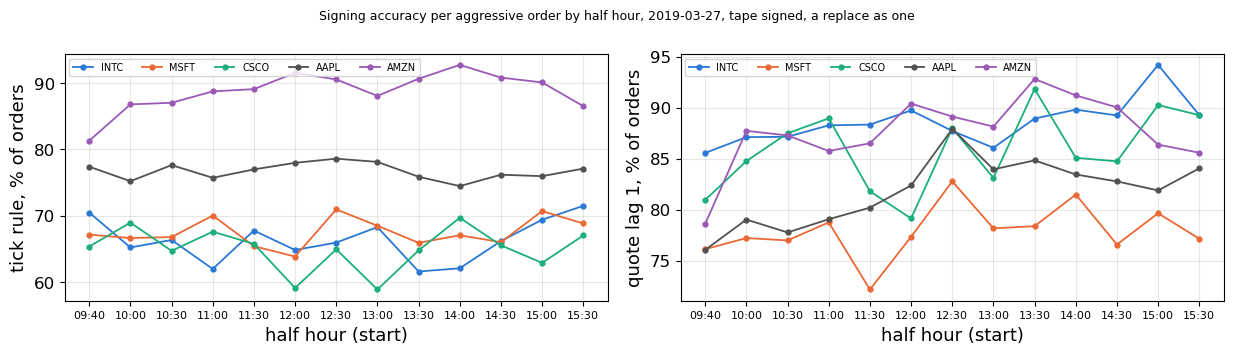


The prediction on signing: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
rule: the quote rule at lag 0 is exact (no miss at all: 100.00% is not enough) on displayed executions at their resting price, and the quote rule at lag 1 is at least as accurate per aggressive order as the tick rule.
INTC    passed: lag 0 at the resting price: 0 of 22,114 fills, 0 of 9,259 orders and 0.0000% of the lots missed; per order quote lag 1 88.21%, tick 66.49%
MSFT    passed: lag 0 at the resting price: 0 of 43,266 fills, 0 of 24,242 orders and 0.0000% of the lots missed; per order quote lag 1 77.32%, tick 67.31%
CSCO    passed: lag 0 at the resting price: 0 of 20,979 fills, 0 of 9,336 orders and 0.0000% of the lots missed; per order quote lag 1 85.22%, tick 64.87%
AAPL    passed: lag 0 at the resting price: 0 of 47,541 fills, 0 of 32,553 orders and 0.0000% of the lots missed; per order quote lag 1 80.95%, tick 76.71%
AMZN    not passed: lag 0 at the resting price: 0 of 20,280

In [27]:
est_short = {'tick': 'tick rule', 'quote1': 'quote lag 1'}  # the figure's y labels


def est_report_apart(results, day=DAY, tapes=TAPES):
    # What the main table leaves apart or splits: the priced executions (ITCH's C, a cent off their order's displayed
    # price: a rule at lag 0 reads their price against a mid that does not know it) and the hidden fills a displayed
    # run signs (their side is the run's, not independently known) each on their own; the accuracy per aggressive order
    # by the spread at the fill and by tape (a class with under MIN_READINGS orders is a count only); and by half hour.
    # With the prediction's verdict. Returns {name: frame}.
    frames = {}
    parts = (
        ('displayed, at the resting price', 'displayed, at the resting price (the check)'),
        ('displayed, priced (C)', 'displayed, priced (C)'),
        ('hidden, signed', 'hidden, signed by their run'),
    )
    formats = {name: '.2f' for name in RULE_NAMES.values()} | {'fills': ',.0f', 'orders': ',.0f', 'shares': ',.0f'}
    heading('Accuracy of each kind of execution, apart', results, day)
    print(
        'Priced executions (ITCH\'s C) are a cent off their order\'s price and are displayed, so their side is '
        'known; a hidden fill is in a signed figure only where a displayed run of the same aggressive order gives it '
        'a side, which is that run\'s and not independent. The unsigned hidden shares are in no row. Per aggressive '
        'order (the rule\'s sign at the order\'s first fill of the kind), per lot and per fill, % of each kind of '
        'execution.'
    )
    for key, unit in (('per order', 'per aggressive order'), ('per lot', 'per lot'), ('per fill', 'per fill')):
        rows, index = [], []
        for stock, result in results.items():
            table = result['signing'][TAPE]
            for kind, label in parts:
                row = {'fills': table['fill counts'][kind], 'orders': table['quote0'][kind].get('orders', 0)}
                row['shares'] = table['lots'][kind]
                for rule in est_rules:
                    row[RULE_NAMES[rule]] = 100 * table[rule][kind].get(key, math.nan)
                rows.append(row)
                index.append((stock, label))
        frames['apart ' + key] = pd.DataFrame(
            rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'executions'])
        )
        print(f'\n{unit}:')
        print(shown(frames['apart ' + key], formats))
    # by the spread at the fill, per aggressive order, on each tape
    rows, index = [], []
    for stock, result in results.items():
        for tape in tapes:
            table = result['signing'][tape]
            for k, label in enumerate(CLASSES):
                orders = table['tick'][est_class_names[k]].get('orders', 0)
                enough = orders >= MIN_READINGS
                row = {'orders': orders}
                for rule in est_rules:
                    row[RULE_NAMES[rule]] = 100 * table[rule][est_class_names[k]]['per order'] if enough else math.nan
                rows.append(row)
                index.append((stock, tape, label))
    frames['by spread'] = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'tape', 'spread']))
    heading(
        'Accuracy per aggressive order by the spread at the fill', results, day, how=convention(' and '.join(tapes))
    )
    print(
        f'Displayed executions; a spread class with under {MIN_READINGS} orders is a count only. The classes are the '
        'spread (in ticks of a cent) of the touch before the order\'s event.'
    )
    print(shown(frames['by spread'], formats))
    # by half hour, signed tape, per aggressive order
    strips = {}
    heading('Accuracy per aggressive order by half hour, displayed executions', results, day)
    for rule in est_rules:
        print(f'\n{RULE_NAMES[rule]}, % of orders:')
        print(est_strip_lines(results, rule))
        for stock, result in results.items():
            strips.setdefault(rule, {})[stock] = result['signing'][TAPE][rule]['blocks, per order']
    for stock, result in results.items():
        for rule in est_rules:
            assert len(result['signing'][TAPE][rule]['blocks, per order']) == len(HAVE_BLOCKS), (
                f'{stock}: a value a half hour'
            )
    frames['strips'] = strips
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
    for ax, rule in zip(axes, ('tick', 'quote1'), strict=True):
        plot_strips(
            results,
            lambda r, rule=rule: r['signing'][TAPE][rule]['blocks, per order'],
            f'{est_short[rule]}, % of orders',
            scale=100.0,
            ax=ax,
        )
    fig.suptitle(figure_title('Signing accuracy per aggressive order by half hour', results, day), fontsize=9)
    fig.tight_layout()
    plt.show()
    heading('The prediction on signing', results, day)
    print(f'rule: {PREDICTIONS["signing"].rule}.')
    for stock, result in results.items():
        verdict = PREDICTIONS['signing'].judge(result)
        print(f'{stock:<8}{verdict.status}: {verdict.detail}')
    return frames


def est_strip_lines(results, rule):
    # a line a stock: the rule's accuracy per aggressive order in each half hour (displayed executions, signed tape)
    return stock_strips(results, lambda r: r['signing'][TAPE][rule]['blocks, per order'], 1, 100.0, 7, 'stock')


if need(DAY):
    est_apart = est_report_apart(measured(DAY), DAY)

TODO(prose): The check ("Signing accuracy"). For each stock and tape: the quote rule at lag 0 had no miss (the misses are printed: 0 of the fills and of the orders) per fill, per lot and per aggressive order on the displayed executions at their resting price, over the fills and the orders printed (the cell stops if it has one); say it is exact by construction (the rule reads the mid just before the event and a fill is at the maker's price), so a check on the conversion's touch, prices and aggressors and not a finding, and that with a separate trade stream the rule would not be available at lag 0.

TODO(prose): The accuracies ("Signing accuracy"). For each stock, per aggressive order on displayed executions: the tick rule and the quote rule at lags 0, 1 and 5 on the signed tape with the none tape beside it, and the same per lot and per fill; the hidden and the unsigned shares of the executed shares beside each; the verdict of the signing prediction (the quote rule at lag 1 at least as accurate as the tick rule per aggressive order: the number of stocks out of five), and whether notebook 14's ordering (the tick rule above the quote rule at lag 1 in four of five models) appeared on each stock. Say what the tape changes (in the exploration the tick rule's figure moved by 0.6 and 1.6 points per aggressive order and the quote rules' by under a tenth of a point) and that the accuracy is of displayed executions, whose aggressor is known, and includes no unsigned hidden volume.

TODO(prose): Priced and hidden executions apart, by the spread at the fill ("Accuracy of each kind of execution, apart"). The priced executions' accuracy for the quote rule at lag 0 (their price is a cent off the order's, so the rule reads it against a mid that does not know it) and the hidden fills' accuracy (against the side their run gives, not an independent one); then by spread class and tape, per aggressive order, with the classes of under 200 orders as counts: for each stock where the two rules' order flips with the spread and where it does not. No claim that either rule is better in general.

TODO(prose): The half-hour strip ("Accuracy of each kind of execution, apart", the figure). For each stock the lowest and the highest half hour of the tick rule and of the quote rule at lag 1, per aggressive order, and whether the order of the two rules holds in every half hour; no pattern across the day or between stocks is claimed.

In [28]:
def est_report_bvc(results, day=DAY, tapes=TAPES):
    # Bulk volume classification: VPIN's buy share of a bucket read from the mid's change over it (Phi of the change in
    # units of the standard deviation of the last 100 buckets' changes), so that a bucket with an unchanged mid reads an
    # imbalance of exactly 0 and its level is a property of the distribution of price changes. Its level against the
    # null that permutes its bucket changes, beside the share of buckets whose mid did not change, the mean imbalance
    # over the buckets that did, and the per-bucket agreement with the true buy share (tick rule and the quote rule at
    # lag 1 beside it). Returns {'level': frame, 'agreement': frame}.
    rows, index = [], []
    for stock, result in results.items():
        for tape in tapes:
            v = result['vpin'][tape]
            b = v['rules']['bvc']
            mean, sd = b['changes permuted']
            unchanged = b['share of buckets with the mid unchanged (session)']
            moved = b['mean |2 Phi(x) - 1| over buckets with a change']
            if math.isfinite(b['level']):  # a stock-day with too few buckets has no level
                assert 0.0 <= unchanged <= 1.0 and 0.0 <= b['level'] <= 1.0, (
                    f'{stock} {tape}: bulk volume level out of range'
                )
                assert math.isclose(b['excess over changes permuted'], b['level'] - mean, abs_tol=1e-12), (
                    f'{stock}: excess'
                )
            rows.append(
                {
                    'BVC level': b['level'],
                    'null: changes permuted (sd)': f'{mean:.3f} ({sd:.3f})',
                    'excess': b['excess over changes permuted'],
                    'sds': b['excess over changes permuted (null sds)'],
                    'mid unchanged %': 100 * unchanged,
                    'mean |2 Phi - 1| where it changed': moved,
                    'x (1 - unchanged)': (1 - unchanged) * moved,
                    'true sides level': v['rules']['true']['level'],
                    'tick rule level': v['rules']['tick']['level'],
                    'buckets, since the open': v['buckets'],
                }
            )
            index.append((stock, tape))
    level = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'tape']))
    heading(
        'Bulk volume classification: its level beside the share of buckets whose mid did not change',
        results,
        day,
        how=convention(' and '.join(tapes)),
    )
    print(
        f'VPIN as the vendors read it from prices: a bucket of V = {V_MEDIANS} x the median of the first {V_FILLS} '
        f'fills, {N_BUCKETS} buckets a window, bucket-weighted over the session; the null permutes the buckets\' '
        f'changes of the mid ({NULL_DRAWS} draws, seed {NULL_SEED}), which keeps their distribution and breaks any '
        'link to the flow. "x (1 - unchanged)" is the level that the share of unchanged buckets and the mean '
        'imbalance of the others give, to the edge effects of a window.'
    )
    print(
        shown(
            level,
            {
                'BVC level': '.3f',
                'excess': '+.3f',
                'sds': '+.1f',
                'mid unchanged %': '.1f',
                'mean |2 Phi - 1| where it changed': '.3f',
                'x (1 - unchanged)': '.3f',
                'true sides level': '.3f',
                'tick rule level': '.3f',
                'buckets, since the open': ',.0f',
            },
        )
    )
    # per bucket, against the true buy share: the signed tape's buckets of the session
    rows, index = [], []
    for stock, result in results.items():
        agreement = result['bucket agreement']
        counts = {agreement[rule]['buckets'] for rule in ('tick', 'mid, lag 1', 'bvc')}
        assert len(counts) == 1, f'{stock}: the rules\' buckets are not the same buckets: {counts}'
        in_session = int(np.nansum(result['vpin'][TAPE]['blocks: buckets closed']))
        assert counts == {in_session}, (
            f'{stock}: the buckets compared per bucket are not the buckets closed in the session'
        )
        for rule, label in (
            ('tick', 'tick rule'),
            ('mid, lag 1', 'quote rule, lag 1'),
            ('bvc', 'bulk volume classification'),
        ):
            a = agreement[rule]
            rows.append(
                {
                    'buckets': a['buckets'],
                    'share: correlation': a['share correlation'],
                    'share: mean absolute error': a['share mean absolute error'],
                    'VPIN: correlation with true sides': a["VPIN correlation with the true side's"],
                }
            )
            index.append((stock, label))
    agreement = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'rule']))
    heading('Per bucket against the true buy share, the buckets closed in the session', results, day)
    print(
        'The inferred buy share of each bucket against the true one (over the buckets of the session): the '
        'correlation and the mean absolute error; and the correlation of each rule\'s trailing VPIN with the true '
        'sides\'. The true share is the share of the bucket\'s volume with a known aggressor; the unsigned hidden '
        'volume is in neither.'
    )
    print(
        shown(
            agreement,
            {
                'buckets': ',.0f',
                'share: correlation': '.2f',
                'share: mean absolute error': '.3f',
                'VPIN: correlation with true sides': '.2f',
            },
        )
    )
    print('\nbeside, hidden and unsigned shares of the executed shares and the three rates a second:')
    print(shown(est_beside(results), est_beside_formats))
    return {'level': level, 'agreement': agreement}


if need(DAY):
    est_bvc = est_report_bvc(measured(DAY), DAY)
    show_nb14(
        {
            'bulk volume classification: level': 'bvc: level',
            'true sides: level': 'true: level',
            'tick rule: level': 'tick: level',
        },
        'VPIN by the rule that signs the fills, 250 lots a bucket; a bulk volume level is near 0.5 whatever the flow',
    )
    show_nb14(
        {
            'tick: correlation': 'tick: correlation',
            'mid, lag 1: correlation': 'mid, lag 1: correlation',
            'bvc: correlation': 'bvc: correlation',
            'tick: mean absolute error': 'tick: mean absolute error',
            'bvc: mean absolute error': 'bvc: mean absolute error',
        },
        'per bucket of 250 lots, the inferred buy share against the true one',
    )


Bulk volume classification: its level beside the share of buckets whose mid did not change: 2019-03-27, session 09:40:00
to 15:50:00, tape signed and none, a replace as one.
VPIN as the vendors read it from prices: a bucket of V = 50 x the median of the first 200 fills, 50 buckets a window, bucket-weighted over the session; the null permutes the buckets' changes of the mid (200 draws, seed 1), which keeps their distribution and breaks any link to the flow. "x (1 - unchanged)" is the level that the share of unchanged buckets and the mean imbalance of the others give, to the edge effects of a window.
             BVC level null: changes permuted (sd)  excess   sds mid unchanged % mean |2 Phi - 1| where it changed x (1 - unchanged) true sides level tick rule level buckets, since the open
stock tape                                                                                                                                                                                   
INTC  signed 


Per bucket against the true buy share, the buckets closed in the session: 2019-03-27, session 09:40:00 to 15:50:00, tape
signed, a replace as one.
The inferred buy share of each bucket against the true one (over the buckets of the session): the correlation and the mean absolute error; and the correlation of each rule's trailing VPIN with the true sides'. The true share is the share of the bucket's volume with a known aggressor; the unsigned hidden volume is in neither.
                                 buckets share: correlation share: mean absolute error VPIN: correlation with true sides
stock rule                                                                                                              
INTC  tick rule                      655               0.47                      0.230                              0.62
      quote rule, lag 1              655               0.64                      0.120                              0.77
      bulk volume classification     655 


notebook 14, seeds 101 to 108, the simulator (per bucket of 250 lots, the inferred buy share against the true one):
            tick: correlation mid, lag 1: correlation bvc: correlation tick: mean absolute error bvc: mean absolute error
ZI                0.79 (0.00)             0.77 (0.01)      0.45 (0.01)             0.034 (0.000)            0.233 (0.002)
Hawkes ZI         0.80 (0.01)             0.75 (0.01)      0.37 (0.02)             0.033 (0.000)            0.221 (0.001)
MF 2008           0.95 (0.00)             0.96 (0.00)      0.71 (0.01)             0.028 (0.001)            0.200 (0.003)
Parlour           0.77 (0.01)             0.72 (0.01)      0.50 (0.02)             0.036 (0.001)            0.222 (0.002)
Informed ZI       0.86 (0.01)             0.82 (0.01)      0.43 (0.01)             0.043 (0.000)            0.224 (0.001)
its three rates a unit of simulation time (seeds 1 to 8, the models' defaults; a real stock's are a second):
            events a unit mid changes a un

TODO(prose): Bulk volume classification's level ("Bulk volume classification"). For each stock: its level, the null that permutes its bucket changes and the excess in null standard deviations, the share of buckets whose mid did not change and the mean imbalance over the buckets that did, and the level that the two give together; set beside notebook 14's 0.471 to 0.524 in every model. Say what it shows: the level is a property of the distribution of price changes and reads about the same whatever the flow, so it is not a measure of how one-sided the flow is, and it falls as more buckets have an unchanged mid.

TODO(prose): Per bucket against the true buy share ("Bulk volume classification"). For each stock the correlation and the mean absolute error of the tick rule's, the quote rule's (lag 1) and bulk volume classification's buy shares against the true one, and the correlation of each rule's trailing VPIN with the true sides'; set beside notebook 14's (tick 0.77 to 0.95, bulk volume classification 0.37 to 0.71). Say which rule tracks the true share on which stock and that the answer is a stock's on a day; no rule is called better in general.

**What this cannot show.**

- *That a rule is better in general.* The accuracy of the tick rule and of the quote rule depends on the spread at the fill, on the tape and on the stock's own price and quote behavior (in the exploration the order of the two rules flipped with the spread within one stock). A figure here is an accuracy on one stock's displayed executions on one day, and the order of two rules on it says nothing about another stock or day.
- *Accuracy on all volume.* An accuracy is scored on displayed executions, whose aggressor is known. The hidden executions that no displayed run signs are in no accuracy (their share of the executed shares is printed beside every one), and a hidden fill inside a displayed run has that run's side, so its accuracy is against an inferred side and is shown apart. The opening and the closing crosses are outside the session.
- *That the grouping of executions into orders is given.* An aggressive order is a run of executions at one nanosecond with consecutive match numbers; where a venue sends the pieces of one order microseconds apart the count of orders, and every per-order figure, moves with the rule that joins them (the grouping sensitivity of the order-to-trade table shows the size of that on that ratio). Per lot and per fill are not per order, and a sweep of many fills counts once per order and many times per fill.
- *The quote rule at lag 0 as a finding.* It is exact by construction when the book is synchronized with the trades, which an order-by-order feed gives; a stream of trades and quotes from separate feeds, or a price-level feed, would not give it (section 4 degrades the same real stream to show how it falls). The check says that the conversion's touch, prices and aggressors are consistent, nothing more.
- *That bulk volume classification measures flow.* It reads the change of the mid over a bucket: its level is near its null's whatever the flow, it is 0 for a bucket whose mid did not change, and its agreement with the true buy share per bucket is an agreement of price changes with flow on one day.
- *Anything wider than one stock on one day, or any difference between two stocks.* The five stocks share each day's market factor, and a spread across them is a spread and not a standard error.

TODO(prose): Section 3's second half in a sentence or two: the lag-0 check's verdict, how many of the five stocks had the quote rule at lag 1 at least as accurate as the tick rule per aggressive order (and whether it held in every spread class), and what bulk volume classification's level and its unchanged-mid share say; the look-ahead trap of the imbalance pairing is above, at the head of this section.

## Section 4: The ladder

Everything measured so far was measured on the exchange's own stream: every order added, canceled or executed, at the nanosecond it happened, with the true side of every trade. What is used outside an exchange is often poorer than that: a feed of price levels (one update for each price level whose size changed, not for each order), delivered in batches of real time, with the trades on a stream of their own and a clock of their own. **The question.** What does each measurement of this notebook become on the same real day seen through a poorer window? That is the third question. This section answers it for the two exploration stocks, shown as what the code was built on, and for the five reported stocks, where the ladder's prediction is judged, and it says at its end what it cannot answer.

**Why on the real book.** A degraded simulator stream is a degradation of the simulator's own events, and says nothing of what a real day's events lose. The ladder here degrades the real stream itself: the same frames of the same day, each rung a deterministic function of them, so that a figure on a rung is read against the same figure on the reference, which is the stream as the exchange gave it. A figure on a rung is **like for like** with the reference's only on the same tape (the displayed executions: no hidden execution is in any figure of this section), the same replace convention (a replace is one change of the book), the same session (09:40:00 to 15:50:00) and the same unit samples (each unit's book is sampled from the book the rung's consumer holds, and every rung has the same units). The cells assert the parts of that which a number can show.

**The rungs** (`lob.ladder`; each is a stream of events that `lob.feeds.run` takes, so the collectors of the setup cell measure it with the same code):

| Rung | What it is | What it keeps | What it loses |
|---|---|---|---|
| reference | the displayed tape, every event, a replace as one change | everything the frames show | hidden orders and executions, iceberg orders; the order of events inside one nanosecond beyond the file's |
| `levels` | one event for each price level whose size changed inside the ten levels the frames show, best price first, a trade fused with the fall of its level | the touch and the levels after every update; the trades | order identity; the grouping of the fills of one aggressive order (a sweep is several trades); the order of the updates inside one event (a rule of this rung, not a fact about any venue); anything deeper than ten levels |
| batches of 1, 50 and 100 ms | the net change of each level over each window of real time (windows start at 09:30:00), one update stamped one nanosecond before the window's end; the trades a stream of their own, one event for each aggressive order, stamped at its first fill and seeing the book of the last update stamped at or before it | the book at the end of each window; the true aggressor of every trade, the grouping of its fills and its time to the nanosecond (which a venue's trade feed may not keep) | order identity; the order of events inside a window; arrivals against cancels at a level; states shorter than a window; the link between a trade and the level change it caused; windows whose rows net to nothing |
| trades shifted by -50, +50 and +100 ms | the 100 ms batches with the trade stream stamped a constant later (earlier if negative) than the book | as the batches | the trades' place against the book, by a constant that no venue is known to have: **a bound on what an unsynchronized trade stream does, not a model of any venue** |

A shifted rung has its batch rung's book, so only its trade-side figures (the quote rule, VPIN) are computed for it and the run checks that its book side is the batch rung's. The tables list every rung for the exploration stocks; for the reported stocks they list the reference and three rungs, the batches of 1 and of 100 ms and the trades at +50 ms.

**What notebook 14 found in the simulator.** Notebook 14 has no ladder: its stream is one event at a time with the true side of every trade, so there is nothing to set against a rung except what its estimators read on the stream as it is. For the zero-intelligence market (`ZI`), on notebook 14's seeds 101 to 108, as it printed them: the imbalance at the touch gives a lift of 7.2 (0.1) points; order flow imbalance's same-interval R2 is 0.322 (0.005) over 1 unit and 0.322 (0.013) over 10 units; the quote rule at lag 0 is exact, 100.0 (0.0) per fill, by construction, with the tick rule at 92.2 (0.0) and the quote rule at lag 1 at 90.1 (0.1); and bulk volume classification's VPIN is 0.504 (0.004), a level that it said is the level of any flow, because |2 Phi(x) - 1| is uniform when x is standard normal whatever the flow is. These are the simulator's, from its saved output, and say nothing about a market.

**What the exploration stocks showed** (exploration: NVDA and CMCSA on 2019-03-27, which the code and its settings were built on; never results, and not read on the second day). On the displayed tape the lag-0 quote rule, exact at the resting price on the reference, read 92.4% (NVDA) and 85.0% (CMCSA) per lot on 100 ms batches, and 73.7% and 56.7% with the trades 50 ms later. The median half-hour R2 of order flow imbalance at 1 s fell on both (NVDA 0.549 to 0.464, CMCSA 0.728 to 0.509), though NVDA's pooled R2 rose (0.234 to 0.376): ten seconds of NVDA's day hold 64% of the flow's sum of squares, so the pooled R2 follows them and not the day. And the imbalance's lift at one tick on a batched rung moved with the batch length and, at some lengths, with where the grid starts. Those three findings fix how this section is written: the **median half-hour R2** is its figure for order flow imbalance and the pooled R2 only a check beside it; the lift at one tick on a batched rung is shown only as a sweep over batch length and over offsets of the grid; and the shifted rungs are named a bound wherever they appear.

**What is run.** The setup's collectors, as section 0 showed them reproduce notebook 14, over each rung: the L 1 reading of the imbalance (strict design, `T_MAX`, the baseline within each spread class, a class with under 200 readings a count only), order flow imbalance at each interval, the tick rule and the quote rule at lags 0, 1 and 5 against the true aggressor, per lot, and VPIN with true sides and with bulk volume classification, in worker processes, one for each stock. Resilience and the order-to-trade ratio are not run on a rung: a batch update's kind, side, price and size are placeholders, and a study that reads them measures nothing. In the tables below, in this order:

1. the three rates (events, changes of the mid and aggressive orders a second) and the order flow's gross size on each rung, with what each rung holds;
2. the imbalance's lift by spread class, with its half-hour strip; the one-tick lift of a batched rung is not in this table;
3. order flow imbalance: the median half-hour R2 at four intervals with the half hours in which a rung is below the reference, the pooled R2 beside it, and what the pooled R2 is made of;
4. the tick rule and the quote rule per lot on each rung, the lag-0 rule by the true spread before the order, and its half-hour strip;
5. VPIN with true sides and with bulk volume classification, and the share of buckets whose mid did not change;
6. the lift as a sweep over batch length (1, 5, 10, 25, 50, 100, 250 and 500 ms), each length on four offsets of the grid, for the exploration stocks;
7. the ladder's prediction, judged for each reported stock.

**How to read them.** Every figure names its tape and replace convention in its heading. A strip is the half hours of the session, from 09:40 (the first and the last hold twenty minutes). "Below reference" is the number of half hours in which a rung's figure is below the reference's, out of the half hours that have both. Standard errors are the block bootstrap of the half hours, which assumes they are exchangeable (they are not), beside the strip's own. Per-order accuracy is not shown on any rung: a feed that stamps trades to the millisecond may not give the fills of one order as one, and these rungs keep the grouping that such a feed may lose.

**The prediction** (in the predictions cell): the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already at 1 ms, and the lag-0 quote rule, per lot, is lower at 100 ms than on the reference by 2 points or more. It is judged for each reported stock on each day, and the section counts the stocks that pass.

In [29]:
# Section 4, the ladder: what a price-level feed loses. Names this section makes are prefixed lad_ (LAD_ for constants,
# Lad for classes). It reads nothing from another section: it runs lob.ladder's rungs on the frames of a stock-day, in
# worker processes (run_stocks), and keeps compact figures. What the sections that read it call:
#   lad_stock(stock, day)     the reported stocks' ladder (the reference and three rungs) of one stock-day, a dict
#                             {'rungs': {rung: figures}, 'specs', 'seconds', 'peak memory (MB)'}; the second day is
#                             run_stocks(lad_stock, SECOND_DAY)
#   lad_judged(figures)       results['ladder'] for judge_all, with exactly the keys judge_ladder reads (the run cell
#                             keeps the first day's figures in lad_reported and the exploration stocks' in lad_explored)
#   lad_explore(stock, day)   the exploration stocks' ladder: every rung and the sweep over batch length
import copy

from lob import ladder as lad_lib

LAD_REFERENCE, LAD_LEVELS = 'reference', 'levels'  # the two rungs of a stream that is not batched
LAD_FIRST, LAD_LAST = LADDER_BATCHES_MS[0], LADDER_BATCHES_MS[-1]  # the batches the ladder's rule reads (1 and 100 ms)
LAD_SHIFT_ON = LAD_LAST  # a shifted rung is this batch with its trades moved: its book is that batch rung's
LAD_PLUS = [shift for shift in LADDER_SHIFTS_MS if shift > 0][0]  # the shift of the reported stocks' rung
LAD_SWEEP_MS = (1, 5, 10, 25, 50, 100, 250, 500)  # the sweep's batch lengths, ms
LAD_OFFSETS = 4  # offsets of the batch grid for each length: k / 4 of the length, k = 0 to 3
LAD_ALL = [*EXPLORED, *STOCKS]  # the stocks whose data the section needs (the smoke's are the same two)
LAD_KEPT = ('fills', 'scored', 'per fill', 'per lot', 'coverage by lots')  # what a signing row keeps (no per-order)
LAD_CATEGORIES = ('displayed (both)', 'displayed, at the resting price', 'displayed, priced (C)')
assert (LAD_FIRST, LAD_LAST) == (1, 100), 'the keys of results["ladder"] name the 1 ms and the 100 ms rungs'


def lad_name(kind, ms=None, shift=None):
    # the name of a rung in every table
    if kind in (LAD_REFERENCE, LAD_LEVELS):
        return kind
    if kind == 'batch':
        return f'batch {ms:g} ms'
    return f'batch {ms:g} ms, trades {shift:+g} ms'


def lad_specs(reported):
    # The rungs of a stock: (name, how it is made from a Day, kind, its parent). The reported stocks get the reference
    # and
    # three rungs (the batches of the first and the last length, and the last length with trades at +50 ms); the
    # exploration stocks every rung. A shifted rung has its batch rung's book: only its trades differ.
    out = [(LAD_REFERENCE, lad_lib.reference, LAD_REFERENCE, None)]
    batches_ms = (LAD_FIRST, LAD_LAST) if reported else LADDER_BATCHES_MS
    shifts = (LAD_PLUS,) if reported else LADDER_SHIFTS_MS
    if not reported:
        out.append((LAD_LEVELS, lad_lib.levels, LAD_LEVELS, None))
    for ms in batches_ms:
        out.append((lad_name('batch', ms), lambda day, ms=ms: lad_lib.batches(day, ms), 'batch', None))
    for shift in shifts:
        out.append(
            (
                lad_name('shift', LAD_SHIFT_ON, shift),
                lambda day, shift=shift: lad_lib.shifted(day, LAD_SHIFT_ON, shift),
                'shift',
                lad_name('batch', LAD_SHIFT_ON),
            )
        )
    return out


# ---- the collectors of this section: the setup's, over a rung ----
class LadHook(Hook):
    # The setup's Hook, which can leave out the trades of a batch rung. A batch rung gives its trades as events that
    # hold
    # the book the consumer has (quotes before and after are one object), not as changes of it, so a collector that
    # counts changes of the book must not read them as events that leave the mid alone.
    def __init__(self, collector, key, skip_trades=False):
        super().__init__(collector, key)
        self.skip_trades = skip_trades

    def observe(self, t, kind, side, price, size, fills, aggressor, quotes_before, quotes_after, book, own=False):
        if self.skip_trades and fills and quotes_before is quotes_after:
            return
        super().observe(t, kind, side, price, size, fills, aggressor, quotes_before, quotes_after, book, own)


class LadReading:
    # What the setup's ImbalanceCollector keeps for its first setting, L 1 (one level, equal weights), strict design:
    # the Reading and the rule that gives it, and nothing else (no unit samples, no other setting).
    def __init__(self, end=math.inf):
        self.end = end
        self.study = BookImbalance(levels=1, weighting='equal')
        self.reading = Reading(False)
        self.last_mid = None

    def on_reset(self, unit, t):
        self.study.reset(unit, t)
        self.last_mid = None
        self.reading.break_()

    def on_pre(self, warm, t, book):
        pass

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        mid = mid_of(after)
        if mid is None:
            self.last_mid = None
            self.reading.break_()
            return
        previous, self.last_mid = self.last_mid, mid
        if warm or t >= self.end:
            return
        changed = previous is not None and mid != previous
        if changed:
            self.reading.change(t, 1 if mid > previous else -1)
        if self.reading.wants(changed):
            value = self.study.compute(book)
            if value:
                self.reading.read(value, after[2] - after[0])

    def result(self):
        return np.frombuffer(self.reading.scored, dtype=np.float64).reshape(-1, 5).copy()


def lad_pass(rung, batched=False, only_reading=False):
    # One pass over a rung, as the setup's collect() makes one over the frames: the recorder, the order flow and the L 1
    # reading (or the reading alone), through lob.ladder.run_rung, which also samples every unit up to the session's end
    # from the book the consumer holds, so that every rung has the same units.
    started = time.time()
    collectors = {'reading': LadReading(U1)}
    if not only_reading:
        collectors = {'recorder': Recorder(), 'flow': FlowCollector(U1)} | collectors
    hooks = [LadHook(c, name, skip_trades=batched and name != 'recorder') for name, c in collectors.items()]
    recorder = collectors.get('recorder')
    result = lad_lib.run_rung(
        rung, StudySet(hooks, auto_sample=False), unit=UNIT, listeners=[recorder.listener] if recorder else []
    )
    scored = collectors['reading'].result()
    out = {
        'rung counts': dict(rung.counts),
        'run counts': dict(result.counts),
        'resets': hooks[0].resets,
        'imbalance': {'scored': [scored]},  # the setup's L1 is setting 0
        'reading counts': dict(collectors['reading'].reading.counts),
    }
    if recorder:
        flow, mid = collectors['flow'].units()
        out |= {'recorder': recorder.result(), 'flow': {'flow': flow, 'mid': mid, 'first': collectors['flow'].first}}
    out['seconds'] = time.time() - started
    return out


# ---- what is read of a pass ----
def lad_increments(e):
    # each event's order flow increment (the setup's ofi_increment, over the recorder's events: 0 where a side is empty)
    with np.errstate(invalid='ignore'):
        inc = (
            np.where(e['ab'] >= e['bb'], e['abq'], 0.0)
            - np.where(e['ab'] <= e['bb'], e['bbq'], 0.0)
            - np.where(e['aa'] <= e['ba'], e['aaq'], 0.0)
            + np.where(e['aa'] >= e['ba'], e['baq'], 0.0)
        )
    return np.where(np.isfinite(e['bb'] + e['ba'] + e['ab'] + e['aa']), inc, 0.0)


def lad_rates(res, batched):
    # Events, mid changes and aggressive orders a second, and the order flow's gross size (the sum of |e| a second), in
    # the
    # session, with the half-hour strips of the first two. An event is an update of the book the consumer holds: a
    # replace is one (its new order is `own`) and a batch rung's trades are not updates. On `levels` an aggressive order
    # that sweeps is several trades. The net flow of the recorder's events must equal the order flow collector's.
    e = events_of(res)
    t = e['t']
    sess = (t >= U0) & (t < U1)
    keep = e['own'] == 0
    if batched:
        keep &= e['nfills'] == 0
    mid = ((e['ab'] + e['aa']) / 2.0)[keep]
    previous = np.r_[np.nan, mid[:-1]]
    changed = np.zeros(len(t), bool)
    changed[np.flatnonzero(keep)] = np.isfinite(mid) & np.isfinite(previous) & (mid != previous)
    increment = lad_increments(e)
    aggressive = (e['nfills'] > 0) & (e['aggressor'] != 0)
    blk = block_of(t)

    def by_block(mask):
        return block_values(
            [mask[blk == b].sum() / BLOCK_SECONDS[b] if BLOCK_SECONDS[b] else math.nan for b in range(N_BLOCKS)]
        )

    net, collected = float(increment[sess].sum()), float(res['flow']['flow'][: U1 - U0].sum())
    assert math.isclose(net, collected, rel_tol=1e-9, abs_tol=1e-6), (
        f'the order flow of the recorder\'s events ({net}) is not the collector\'s ({collected})'
    )
    return {
        'events a second': float((sess & keep).sum()) / SESSION_SECONDS,
        'mid changes a second': float((changed & sess).sum()) / SESSION_SECONDS,
        'aggressive orders a second': float((aggressive & sess).sum()) / SESSION_SECONDS,
        'gross OFI a second': float(np.abs(increment[sess & keep]).sum()) / SESSION_SECONDS,
        'events by block': by_block(sess & keep),
        'mid changes by block': by_block(changed & sess),
    }


def lad_imbalance(res):
    # the L 1 reading by the spread at the reading: the class's own row (n, hit, reversal, the lifts and the baseline
    # that
    # binds), and for a class with MIN_READINGS or more the half-hour strip and the block bootstrap
    scored = res['imbalance']['scored'][L1]
    spread = spread_class(scored[:, 4]) if len(scored) else np.array([], int)
    out = {'readings': len(scored), 'changes': res['reading counts']['changes'], 'classes': {}}
    for k, name in enumerate(CLASSES):
        row = class_row(scored, spread == k)
        row['shown'] = row['n'] >= MIN_READINGS
        if row['shown']:
            row['strip'] = imbalance_strip(res, L1, 0, name)
        out['classes'][name] = row
    return out


def lad_signing(res):
    # the tick rule and the quote rule at lags 0, 1 and 5 against the true aggressor on the displayed fills, per fill
    # and
    # per lot (no per-order figure: a feed that stamps trades to the millisecond may not give an order's fills as one),
    # for the fills at their resting price, the priced ones (printable C) and both; the half-hour strip per lot
    table = signing_table(res, 'none')
    out = {
        rule: {category: {k: table[rule][category].get(k) for k in LAD_KEPT} for category in LAD_CATEGORIES}
        | {'blocks, per lot': table[rule]['blocks, per lot']}
        for rule in RULES
    }
    return out | {'lots': table['lots'], 'fill counts': table['fill counts']}


def lad_pack(res):
    # the reference's fills (price, size) with the true spread before each, in order: what a rung's fills are read
    # against
    tp = Tape(res, 'none')
    known = np.isfinite(tp.spread0)
    return {
        'price': tp.price,
        'size': tp.size,
        'class': np.where(known, spread_class(np.where(known, tp.spread0, 1.0)), -1),
    }


def lad_by_true_spread(res, pack):
    # The quote rules at lags 0 and 1, per lot, on the displayed fills in the session, by the spread before the order in
    # the reference's book (the true spread, not the stale one the rung's consumer sees): a rung's fills are the
    # reference's, in order (a shifted rung's last ones may be past the session's end).
    tp = Tape(res, 'none')
    n = min(len(tp.price), len(pack['price']))
    assert np.array_equal(tp.price[:n], pack['price'][:n]) and np.array_equal(tp.size[:n], pack['size'][:n]), (
        'the fills of the rung are not the reference\'s fills in order'
    )
    klass = np.full(len(tp.price), -1)
    klass[:n] = pack['class'][:n]
    mask = (tp.t >= U0) & (tp.t < U1) & ~tp.hidden
    out = {}
    for rule in ('quote0', 'quote1'):
        sign = tp.rule_signs(rule)
        out[rule] = {name: rule_accuracy(sign, tp.agg, tp.size, mask & (klass == k)) for k, name in enumerate(CLASSES)}
    return out


def lad_vpin(res):
    # VPIN's level with the true sides and with bulk volume classification (the setup's functions, 50 buckets, V from
    # the
    # first 200 fills) and the share of buckets, in the session, in which the mid did not change: levels only, no excess
    d = vpin_inputs(res, 'none')
    sizes = d['size']
    v = max(1.0, V_MEDIANS * float(np.median(sizes[:V_FILLS])))
    size_after, t_after = sizes[V_FILLS:], d['t'][V_FILLS:]
    edges = bucket_edges(size_after, v)
    close_t = t_after[edges[0]]
    imb_true, _ = bucket_imbalance(size_after, d['sign']['true'][V_FILLS:], v, edges)
    changes = bvc_changes(d, edges[0])
    in_session = (close_t >= U0) & (close_t < U1)
    blk = block_of(close_t)
    unchanged = [
        float((changes[(blk == b) & in_session] == 0).mean()) if ((blk == b) & in_session).any() else math.nan
        for b in range(N_BLOCKS)
    ]
    return {
        'V': v,
        'buckets': len(close_t),
        'buckets in session': int(in_session.sum()),
        'true level': vpin_level(imb_true, close_t)[0],
        'bvc level': vpin_level(bvc_imbalance(changes), close_t)[0],
        'bvc unchanged mid': float((changes[in_session] == 0).mean()) if in_session.any() else math.nan,
        'bvc unchanged strip': block_values(unchanged),
    }


def lad_signature(res):
    # what the book side of a pass is, in four numbers: a shifted rung must have its batch rung's
    flow, mid = res['flow']['flow'], res['recorder']['unit_mid']
    return (len(res['imbalance']['scored'][L1]), float(flow.sum()), float(np.abs(flow).sum()), float(np.nansum(mid)))


def lad_figures(res, kind, pack):
    # Everything the tables of this section read of one rung: rates, the lift by spread class, order flow imbalance,
    # signing, VPIN with bulk volume classification. A shifted rung keeps only its rates and its trade side (its book
    # is its batch rung's, which the run checks).
    batched = kind in ('batch', 'shift')
    out = {
        'counts': res['rung counts'],
        'seconds': res['seconds'],
        'units sampled': len(res['recorder']['unit_mid']),
        'signature': lad_signature(res),
        'rates': lad_rates(res, batched),
        'signing': lad_signing(res),
        'vpin': lad_vpin(res),
    }
    if kind != 'levels':
        out['by true spread'] = lad_by_true_spread(res, pack if pack is not None else lad_pack(res))
    if kind != 'shift':
        out['imbalance'] = lad_imbalance(res)
        out['ofi'] = ofi_summary(res)
    return out


# ---- the run of one stock-day ----
def lad_day(stock, day):
    # the frames of a stock-day as a lob.ladder Day (the book as arrays, the session's events once): the frames are
    # dropped
    messages, book, _ = frames_of(stock, day)
    out = lad_lib.Day(messages, book, origin=OPEN, end=OPEN + U1)
    del messages, book
    gc.collect()
    return out


def lad_check(figures, name, kind, parent, reference_figures):
    # What must hold between rungs for a table to mean anything: the same units sampled; the same fills, so the tick
    # rule and VPIN with true sides are the reference's on every rung that does not move trades; a shifted rung with
    # its batch rung's book.
    assert figures['units sampled'] == reference_figures['units sampled'], f'{name}: another number of units sampled'
    if kind in (LAD_LEVELS, 'batch'):
        same = reference_figures['signing']['tick']['displayed (both)']
        got = figures['signing']['tick']['displayed (both)']
        assert all(got[k] == same[k] for k in LAD_KEPT), f'{name}: the tick rule is not the reference\'s: {got} {same}'
        assert math.isclose(figures['vpin']['true level'], reference_figures['vpin']['true level'], abs_tol=1e-12), (
            f'{name}: VPIN with true sides is not the reference\'s'
        )
    if parent is not None:
        assert figures['signature'] == parent['signature'], f'{name}: its book is not its batch rung\'s'


def lad_offset_rung(day, ms, offset_ms):
    # A batch rung whose grid starts offset_ms after the origin (the unit clock stays at the origin: only the windows
    # move). lob.ladder has no offset: the rung is made on a shallow copy of the Day with its origin moved.
    if offset_ms == 0:
        return lad_lib.batches(day, ms)
    moved = copy.copy(day)
    moved.origin_ns = day.origin_ns + round(offset_ms * 1e6)
    rung = lad_lib.batches(moved, ms)
    rung.origin_ns = day.origin_ns
    return rung


def lad_sweep(day):
    # The L 1 reading by spread class on batches of every length of LAD_SWEEP_MS, each on LAD_OFFSETS offsets of the
    # grid
    assert day.table.n, 'the session has no events'  # built once: the copies of the Day share the table
    out = {}
    for ms in LAD_SWEEP_MS:
        for k in range(LAD_OFFSETS):
            offset = ms * k / LAD_OFFSETS
            res = lad_pass(lad_offset_rung(day, ms, offset), batched=True, only_reading=True)
            scored = res['imbalance']['scored'][L1]
            spread = spread_class(scored[:, 4]) if len(scored) else np.array([], int)
            out[ms, k] = {
                'offset ms': offset,
                'readings': len(scored),
                'changes': res['reading counts']['changes'],
                'updates': res['rung counts']['batches'],
                'classes': {name: class_row(scored, spread == c) for c, name in enumerate(CLASSES)},
            }
    return out


def lad_run(day, specs, sweep=False):
    # The figures of each rung in turn (the reference first: its fills are what the others are read against) and, for
    # the
    # exploration stocks, the sweep. Returns {'rungs': {name: figures}, 'sweep': ..., 'seconds': ..., 'peak memory
    # (MB)'}.
    started = time.time()
    assert day.table.n, 'the session has no events'  # the events of the reference as arrays, made once
    out, pack = {'rungs': {}}, None
    for name, make, kind, parent in specs:
        rung = make(day)
        res = lad_pass(rung, batched=kind in ('batch', 'shift'))
        out['rungs'][name] = figures = lad_figures(res, kind, pack)
        if kind == LAD_REFERENCE:
            assert figures['units sampled'] == U1, (
                f'the reference has {figures["units sampled"]} unit samples, not the {U1} of the session: '
                'the ladder\'s rungs would not be like for like'
            )
            pack = lad_pack(res)
            lad_exact, lad_misses = lag0_exact(figures['signing']['quote0']['displayed, at the resting price'])
            assert lad_exact, (
                f'the quote rule at lag 0 is not exact at the resting price ({lad_misses}): the stream is wrong and '
                'the section stops'
            )
        else:
            lad_check(figures, name, kind, out['rungs'][parent] if parent else None, out['rungs'][LAD_REFERENCE])
        del rung, res
        gc.collect()
    out['specs'] = [(name, kind, parent) for name, _, kind, parent in specs]
    if sweep:
        out['sweep'] = lad_sweep(day)
    out['seconds'] = time.time() - started
    out['peak memory (MB)'] = peak_mb()
    return out


def lad_stock(stock, day):
    # The reported stocks' ladder on a day: the reference and three rungs
    return lad_run(lad_day(stock, day), lad_specs(True))


def lad_explore(stock, day):
    # The exploration stocks' ladder: every rung, and the sweep over batch length (what the code was built on)
    return lad_run(lad_day(stock, day), lad_specs(False), sweep=True)


def lad_judged(figures):
    # what the setup's judge_ladder reads, as results['ladder'] with exactly its keys: the median half-hour R2 of order
    # flow imbalance at OFI_MAIN seconds on the reference and the 1 and 100 ms rungs, and the lag-0 quote rule per lot
    # on the reference and at 100 ms
    rungs = figures['rungs']
    first, last = lad_name('batch', LAD_FIRST), lad_name('batch', LAD_LAST)
    return {
        'median_r2_reference': rungs[LAD_REFERENCE]['ofi'][OFI_MAIN]['median half-hour R2'],
        'median_r2_1ms': rungs[first]['ofi'][OFI_MAIN]['median half-hour R2'],
        'median_r2_100ms': rungs[last]['ofi'][OFI_MAIN]['median half-hour R2'],
        'quote0_reference': rungs[LAD_REFERENCE]['signing']['quote0']['displayed (both)']['per lot'],
        'quote0_100ms': rungs[last]['signing']['quote0']['displayed (both)']['per lot'],
    }

In [30]:
# Section 4, the run. It needs the cell before it (61_a_machinery). The exploration stocks get every rung and the sweep
# over batch length; the reported stocks the reference and three rungs. Each stock is a worker (run_stocks); what comes
# back are figures, not passes. The rungs' own checks (the same units on every rung, the same fills and so the same tick
# rule and VPIN with true sides, a shifted rung's book its batch rung's, the lag-0 quote rule exact at the resting
# price)
# run in the worker and stop it with a message if they fail.
lad_explored, lad_reported = {}, {}
if need(DAY, LAD_ALL):
    lad_explored = run_stocks(lad_explore, DAY, EXPLORED)
    lad_reported = run_stocks(lad_stock, DAY, STOCKS)
    lad_rows = [row for row in RUN_LOG if row[0] in ('lad_explore', 'lad_stock')]
    print(
        f'section 4: {len(lad_rows)} stock-days run, {sum(row[3] for row in lad_rows) / 60:.1f} core-minutes, '
        f'peak memory of a worker {max(row[4] for row in lad_rows):,.0f} MB.'
    )
    for lad_function, lad_label in (('lad_explore', 'exploration'), ('lad_stock', 'reported')):
        print(
            f'  {lad_label}: '
            + '; '.join(f'{row[1]} {row[3]:.0f} s, {row[4]:,.0f} MB' for row in lad_rows if row[0] == lad_function)
        )


def lad_halves():
    # (heading, results by stock) for each half that was run: the exploration stocks (every rung) and the reported
    # stocks
    # (the reference and three rungs), each with the tape and the replace convention its figures are on. The rungs are
    # the
    # displayed tape (hidden_mode none: the displayed executions), a replace as one.
    where = f'{convention("none")}, session {SESSION_START} to {SESSION_END}, unit {UNIT:g} s'
    out = []
    if lad_explored:
        out.append((f'{EXPLORATION}, {day_text(DAY)}; {where}', lad_explored))
    if lad_reported:
        out.append((f'the reported stocks, {day_text(DAY)}; {where}', lad_reported))
    return out


def lad_book_rungs(run_out):
    # the rungs that have a book side of their own (a shifted rung has its batch rung's)
    return [name for name, kind, _ in run_out['specs'] if kind != 'shift']


def lad_below(values, base):
    # the half hours in which a figure is below the reference's, as 'k/m' of the half hours that have both
    a, b = np.asarray(values, dtype=float), np.asarray(base, dtype=float)
    both = np.isfinite(a) & np.isfinite(b)
    return f'{int((a[both] < b[both]).sum())}/{int(both.sum())}'


def lad_above(values, base):
    a, b = np.asarray(values, dtype=float), np.asarray(base, dtype=float)
    both = np.isfinite(a) & np.isfinite(b)
    return f'{int((a[both] > b[both]).sum())}/{int(both.sum())}'


def lad_strips(rows, digits, scale, width=7, label_width=34):
    # lines of half-hour values, `rows` a list of (label, strip), under the half hours' start times
    lines = [f'{"":<{label_width}}{strip_header(width)}']
    lines += [f'{label:<{label_width}}{strip_text(strip, digits, scale, width)}' for label, strip in rows]
    return '\n'.join(lines)

section 4: 7 stock-days run, 4.5 core-minutes, peak memory of a worker 5,025 MB.
  exploration: NVDA 62 s, 4,037 MB; CMCSA 52 s, 3,689 MB
  reported: INTC 31 s, 3,263 MB; MSFT 35 s, 5,025 MB; CSCO 26 s, 2,609 MB; AAPL 36 s, 4,528 MB; AMZN 30 s, 2,995 MB


In [31]:
# Section 4, table 1: what each rung holds and the three rates on it (events, changes of the mid and aggressive orders a
# second), with the order flow's gross size. Needs the ladder's machinery and run cells.
def lad_rates_table(results):
    # a row a stock and rung: the rates in the session, and in how many half hours the rung's events and mid changes a
    # second are below the reference's (the 13 half-hour values: the first and the last are twenty minutes)
    rows = {}
    for stock, run_out in results.items():
        reference_rates = run_out['rungs'][LAD_REFERENCE]['rates']
        for name in lad_book_rungs(run_out):
            rates = run_out['rungs'][name]['rates']
            rows[stock, name] = {
                'events a second': rates['events a second'],
                'mid changes a second': rates['mid changes a second'],
                'aggressive orders a second': rates['aggressive orders a second'],
                'gross OFI a second': rates['gross OFI a second'],
                'events below reference': lad_below(rates['events by block'], reference_rates['events by block']),
                'mid changes below reference': lad_below(
                    rates['mid changes by block'], reference_rates['mid changes by block']
                ),
            }
    return pd.DataFrame.from_dict(rows, orient='index')


def lad_holds_table(results):
    # what a rung holds, from the rung's own construction: updates, the windows of a batch rung and those whose rows net
    # to
    # nothing (no update), the events `levels` split and those it could not, and the trades
    rows = {}
    for stock, run_out in results.items():
        for name in lad_book_rungs(run_out):
            counts = run_out['rungs'][name]['counts']
            rows[stock, name] = {
                'updates': counts.get(
                    'batches', counts.get('updates', counts['events'] - counts.get('replace_deletions', 0))
                ),
                'windows': counts.get('windows', math.nan),
                'windows netting to nothing': counts.get('empty_net_change', math.nan),
                'events split': counts.get('split_events', math.nan),
                'events kept whole': counts.get('fallback_events', math.nan),
                'trades': counts.get('trades', counts.get('aggressive', math.nan)),
            }
    return pd.DataFrame.from_dict(rows, orient='index')


if need(DAY, LAD_ALL):
    for lad_heading, lad_results in lad_halves():
        print(f'Rates a second on each rung, {lad_heading}.')
        print(
            'A shifted rung has its batch rung\'s book. "Aggressive orders" are the trades: on `levels` an order that '
            'sweeps is several.\n'
        )
        lad_rates_frame = lad_rates_table(lad_results)
        print(shown(lad_rates_frame, {'gross OFI a second': ',.0f'}))
        print(
            '\nWhat each rung holds, from the opening cross at 09:30 to the session\'s end (counts, not rates; '
            'a window is a batch\'s clock interval):\n'
        )
        lad_holds = lad_holds_table(lad_results)
        print(shown(lad_holds, dict.fromkeys(lad_holds.columns, ',.0f')))
        print()
        for lad_stock_name, lad_out in lad_results.items():
            lad_reference = lad_rates_frame.loc[lad_stock_name, LAD_REFERENCE]
            for lad_rung in lad_book_rungs(lad_out):
                lad_row = lad_rates_frame.loc[lad_stock_name, lad_rung]
                if lad_rung.startswith('batch'):
                    # a batch is an update of the book only if some level's size changed net: at most as many updates
                    # as events, and fewer mid changes
                    assert lad_row['events a second'] <= lad_reference['events a second'], (
                        f'{lad_stock_name} {lad_rung}: more updates than the reference has events'
                    )
                    assert lad_row['mid changes a second'] <= lad_reference['mid changes a second'], (
                        f'{lad_stock_name} {lad_rung}: more changes of the mid than the reference has'
                    )

Rates a second on each rung, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.
A shifted rung has its batch rung's book. "Aggressive orders" are the trades: on `levels` an order that sweeps is several.

                   events a second mid changes a second aggressive orders a second gross OFI a second events below reference mid changes below reference
NVDA  reference             38.946                3.039                      0.703                635                   0/13                        0/13
      levels                39.392                3.079                      0.720                641                   0/13                        0/13
      batch 1 ms            14.803                2.003                      0.703                475                  13/13                       13/13
      batch 50 ms            6.902                1.130                      

TODO(prose): The three rates and the gross order flow on each rung (the table above), for each stock and for the exploration stocks labeled as exploration: the events a second and the mid changes a second on the reference and on each rung, as a share of the reference's, and the "below reference" counts (in how many of the thirteen half hours each rung's rate is below the reference's). Say how much of the event rate and of the mid-change rate each rung keeps and that a coarser window keeps fewer; that the aggressive orders a second are the same on every batch rung because the trade stream is kept (and that `levels` counts a sweep as several trades); that `gross OFI a second` falls with the window because flow that arrives and is canceled inside a window nets out. A description of what a rung holds, with no direction claimed for any feed.

TODO(prose): What each rung holds (the counts table): the updates of each rung, the windows of a batch rung and how many net to nothing (no update), the events `levels` split and how many it kept whole (and that `events kept whole` is a count of the construction's fallbacks, which the table prints). One sentence each; the reader learns what an update is on each rung.

In [32]:
# Section 4, table 2: the queue imbalance at the touch (L 1, equal weights, strict design) and the next move of the mid,
# on
# each rung, by the spread at the reading, with the baseline within each class. The lift is over the better of the
# reversal rate and 50% within the class. A class with under 200 readings is a count only. On a batched rung the one-
# tick
# lift is not a figure of this table (it is shown only as the sweep over batch length, below): the count is.
# Needs the ladder's machinery and run cells.
def lad_lift_table(results):
    # a row a stock, rung and spread class: the readings, hit and reversal rate in percent, the baseline that binds, the
    # lift in points with its block-bootstrap and strip standard errors (assuming exchangeable half hours)
    rows = {}
    for stock, run_out in results.items():
        for name, kind, _ in run_out['specs']:
            if kind == 'shift':
                continue
            for spread, row in run_out['rungs'][name]['imbalance']['classes'].items():
                out = {'readings': row['n']}
                if row['shown'] and not (kind == 'batch' and spread == CLASSES[0]):
                    strip = row['strip']
                    out |= {
                        'hit %': 100 * row['hit'],
                        'reversal %': 100 * row['reversal'],
                        'baseline': row['binds'],
                        'lift pp': 100 * row['lift over the better'],
                        'se pp (blocks)': 100 * strip['lift se'],
                        'se pp (strip)': 100 * strip['lift strip se'],
                    }
                rows[stock, name, spread] = out
    return pd.DataFrame.from_dict(rows, orient='index')


def lad_counts_table(results):
    # the changes of the mid, the readings scored and the readings by class: what the lift rests on
    rows = {}
    for stock, run_out in results.items():
        for name in lad_book_rungs(run_out):
            im = run_out['rungs'][name]['imbalance']
            rows[stock, name] = {'changes of the mid': im['changes'], 'readings scored': im['readings']} | {
                spread: row['n'] for spread, row in im['classes'].items()
            }
    return pd.DataFrame.from_dict(rows, orient='index')


if need(DAY, LAD_ALL):
    for lad_heading, lad_results in lad_halves():
        print(f'The imbalance at the touch and the next move, by the spread at the reading, {lad_heading}.')
        print(
            'Lift: the hit rate less the better of the reversal rate and 50% within the class (points); the baseline '
            'that binds is named. Standard errors: block bootstrap of the half hours (assumes they are exchangeable; '
            f'they are not) and the strip\'s own (sd of the half hours over the root of how many). A class with under '
            f'{MIN_READINGS} readings is a count; a batched rung\'s one-tick lift is not shown here.\n'
        )
        lad_counts = lad_counts_table(lad_results)
        print(shown(lad_counts, dict.fromkeys(lad_counts.columns, ',.0f')))
        print()
        lad_lift = lad_lift_table(lad_results)
        print(
            shown(
                lad_lift,
                {
                    'readings': ',.0f',
                    'hit %': '.1f',
                    'reversal %': '.1f',
                    'lift pp': '+.1f',
                    'se pp (blocks)': '.2f',
                    'se pp (strip)': '.2f',
                },
            )
        )
        print(f'\nHalf-hour lift (points), the classes with {MIN_READINGS} readings or more:')
        lad_lines = []
        for lad_stock_name, lad_out in lad_results.items():
            for lad_rung, lad_kind, _ in lad_out['specs']:
                if lad_kind == 'shift':
                    continue
                for lad_spread, lad_row in lad_out['rungs'][lad_rung]['imbalance']['classes'].items():
                    if lad_row['shown'] and not (lad_kind == 'batch' and lad_spread == CLASSES[0]):
                        lad_lines.append(
                            (f'{lad_stock_name} {lad_spread}, {lad_rung}', lad_row['strip']['strip']['lift'])
                        )
        print(lad_strips(lad_lines, 1, 100, 6))
        print()
        for lad_stock_name, lad_out in lad_results.items():
            lad_im = lad_out['rungs'][LAD_REFERENCE]['imbalance']
            assert lad_im['readings'] == sum(row['n'] for row in lad_im['classes'].values()), (
                f'{lad_stock_name}: the readings by class do not add up to the readings scored'
            )
            if (DAY, lad_stock_name) in MEASURED:
                # The reference rung is the displayed tape (hidden_mode 'none') and section 2's pass is the signed tape,
                # whose book side is the same. The readings by class are the same up to the few aggressive orders that
                # the two streams partition differently (the worst-fill rule that says whether a trailing add is a
                # remainder: on one exploration stock one event in a million), so the counts are compared to within
                # that, not for equality, and the largest difference is printed.
                lad_section_2 = class_rows(MEASURED[DAY, lad_stock_name])
                lad_gaps = {k: lad_im['classes'][k]['n'] - int(lad_section_2[k]['n']) for k in CLASSES}
                assert all(abs(lad_gaps[k]) <= max(2, 0.001 * lad_section_2[k]['n']) for k in CLASSES), (
                    f'{lad_stock_name}: the reference rung\'s readings are not those of the main pass: {lad_gaps}'
                )
                print(
                    f'{lad_stock_name}: readings by class, the reference rung less the main pass: '
                    + ', '.join(f'{k} {lad_gaps[k]:+d}' for k in CLASSES)
                    + '.'
                )

The imbalance at the touch and the next move, by the spread at the reading, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.
Lift: the hit rate less the better of the reversal rate and 50% within the class (points); the baseline that binds is named. Standard errors: block bootstrap of the half hours (assumes they are exchangeable; they are not) and the strip's own (sd of the half hours over the root of how many). A class with under 200 readings is a count; a batched rung's one-tick lift is not shown here.

                   changes of the mid readings scored one tick two ticks three or more
NVDA  reference                67,466          52,473      909     1,804        49,760
      levels                   68,351          52,546      909     1,804        49,833
      batch 1 ms               44,459          30,273      232       777        29,264
      batch 50 ms              

TODO(prose): The imbalance's lift by spread class (the table above): for each stock, the readings by class on the reference and on each rung (the counts table), and, for each class with 200 readings or more, the hit rate, the reversal rate, the baseline that binds and the lift in points with both standard errors, on the reference and on `levels`; and on each batched rung the lift of the classes that have 200 readings or more (two ticks, three or more) with the baseline within the class. Say how the readings by class move down the ladder (the one-tick count of a batched rung is a count here and its lift is in the sweep below), how the lift of each class that is shown on a rung compares with the reference's and within its half-hour strip (the strip's own standard error beside the bootstrap's, which assumes exchangeable half hours), and that a class under 200 readings is a count. No pooled lift is a figure of a stock, and no batched one-tick lift is quoted from this table.

TODO(prose): `levels` against the reference (the first two rungs of each stock): whether the lift and the counts by class differ and by how much; `levels` keeps the touch after every update, so any difference is a count of readings, and the sentence says so.

Order flow imbalance on each rung, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.
The median half-hour R2 is the figure. "Below reference": in how many half hours the rung's R2 is below the reference's. Standard error: block bootstrap of the half hours (assumes they are exchangeable; they are not).

                   median R2, 1 s median R2, 5 s median R2, 10 s median R2, 50 s se, 10 s (blocks) below reference, 1 s below reference, 10 s beyond the last change > 0, 1 s
NVDA  reference             0.549          0.674           0.675           0.644             0.034                 0/13                  0/13                           13/13
      levels                0.554          0.680           0.679           0.617             0.038                 0/13                  4/13                           13/13
      batch 1 ms            0.474          0.598           0.612  

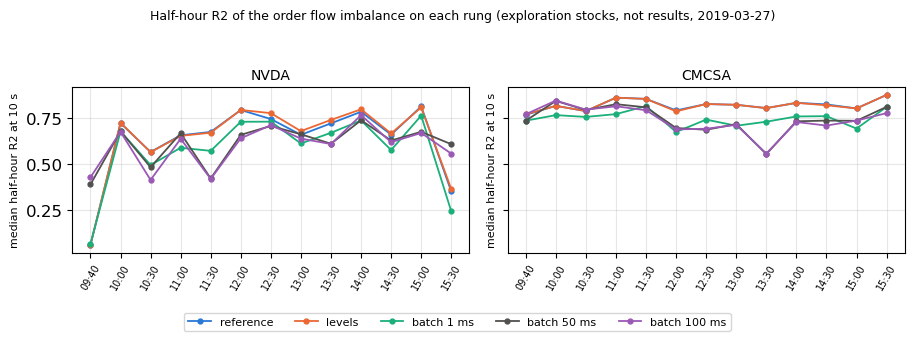

Order flow imbalance on each rung, the reported stocks, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.
The median half-hour R2 is the figure. "Below reference": in how many half hours the rung's R2 is below the reference's. Standard error: block bootstrap of the half hours (assumes they are exchangeable; they are not).

                  median R2, 1 s median R2, 5 s median R2, 10 s median R2, 50 s se, 10 s (blocks) below reference, 1 s below reference, 10 s beyond the last change > 0, 1 s
INTC reference             0.795          0.855           0.867           0.861             0.008                 0/13                  0/13                           13/13
     batch 1 ms            0.695          0.778           0.810           0.855             0.010                13/13                 13/13                           13/13
     batch 100 ms          0.562          0.718           0.805           0.839             0.014                13/13       

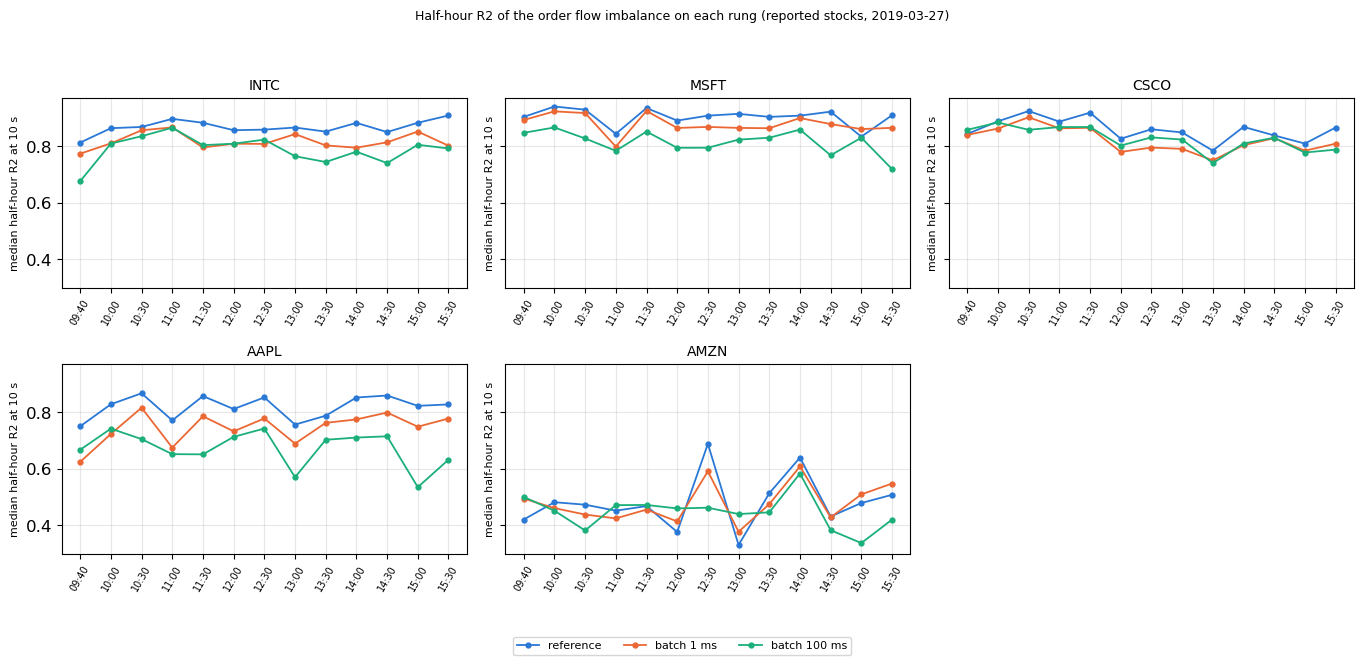

INTC: the reference rung's median half-hour R2 and the main pass's differ by at most 0.0e+00 over 4 intervals.
MSFT: the reference rung's median half-hour R2 and the main pass's differ by at most 0.0e+00 over 4 intervals.
CSCO: the reference rung's median half-hour R2 and the main pass's differ by at most 0.0e+00 over 4 intervals.
AAPL: the reference rung's median half-hour R2 and the main pass's differ by at most 0.0e+00 over 4 intervals.
AMZN: the reference rung's median half-hour R2 and the main pass's differ by at most 0.0e+00 over 4 intervals.


In [33]:
# Section 4, table 3: order flow imbalance on each rung. The figure is the median half-hour R2 of the change of the mid
# on the interval's order flow imbalance, at each interval, with the pooled R2 beside it (a check, never a stock's
# figure: ten seconds of the day can carry most of the flow's sum of squares), the half hours in which a rung's R2 is
# below the reference's, and "beyond the last change" at 1 s. Needs the ladder's machinery and run cells.
def lad_ofi_table(results):
    # a row a stock and rung: the median half-hour R2 at each interval with its block-bootstrap standard error at
    # OFI_MAIN s, the half hours in which a rung's R2 is below the reference's at the first interval and at OFI_MAIN,
    # and
    # the half hours in which the partial correlation beyond the last change at the first interval is above 0
    rows = {}
    first = INTERVALS[0]
    for stock, run_out in results.items():
        reference_ofi = run_out['rungs'][LAD_REFERENCE]['ofi']
        for name in lad_book_rungs(run_out):
            ofi = run_out['rungs'][name]['ofi']
            row = {f'median R2, {h} s': ofi[h]['median half-hour R2'] for h in INTERVALS}
            row[f'se, {OFI_MAIN} s (blocks)'] = ofi[OFI_MAIN]['median half-hour R2 se']
            for h in (first, OFI_MAIN):
                row[f'below reference, {h} s'] = lad_below(ofi[h]['R2 strip'], reference_ofi[h]['R2 strip'])
            row[f'beyond the last change > 0, {first} s'] = (
                f'{ofi[first]["blocks with beyond above 0"]}/{ofi[first]["blocks with R2"]}'
            )
            rows[stock, name] = row
    return pd.DataFrame.from_dict(rows, orient='index')


def lad_pooled_table(results):
    # the pooled R2 (a check, not a figure of the stock) and what the pooled R2 at 1 s is made of: the share of the
    # flow's
    # sum of squares in its ten largest seconds, and the pooled R2 at 1 s without them
    rows = {}
    for stock, run_out in results.items():
        for name in lad_book_rungs(run_out):
            ofi = run_out['rungs'][name]['ofi']
            largest = ofi['largest seconds']
            rows[stock, name] = {f'pooled R2, {h} s': ofi[h]['pooled R2'] for h in INTERVALS} | {
                f'share of the sum of squares in the {TOP_SECONDS} largest seconds, 1 s': largest[
                    'share of the sum of squares of the flow in the ten largest seconds'
                ],
                f'pooled R2, 1 s, without the {TOP_SECONDS}': largest['R2 at 1 s without the ten largest seconds'],
            }
    return pd.DataFrame.from_dict(rows, orient='index')


def lad_plot_ofi(results, heading):
    # a panel a stock (three to a row): the half-hour R2 at OFI_MAIN s on each rung, one line a rung
    columns = min(len(results), 3)
    rows = -(-len(results) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(4.6 * columns, 3.3 * rows), sharey=True, squeeze=False)
    for ax, (stock, run_out) in zip(axes.flat, results.items(), strict=False):
        plot_strips(
            {rung: run_out['rungs'][rung] for rung in lad_book_rungs(run_out)},
            lambda figures: figures['ofi'][OFI_MAIN]['R2 strip'],
            f'median half-hour R2 at {OFI_MAIN} s',
            stock,
            ax=ax,
        )
        ax.tick_params(axis='x', labelrotation=60, labelsize=7)
        ax.set_xlabel('')
        ax.set_ylabel(ax.get_ylabel(), fontsize=8)
        handles, labels = ax.get_legend_handles_labels()
        ax.get_legend().remove()
    for ax in list(axes.flat)[len(results) :]:
        ax.axis('off')
    which = 'exploration stocks, not results' if heading.startswith(EXPLORATION) else 'reported stocks'
    fig.suptitle(f'Half-hour R2 of the order flow imbalance on each rung ({which}, {day_text(DAY)})', fontsize=9)
    fig.legend(handles, labels, loc='lower center', ncols=len(labels), fontsize=8)
    fig.tight_layout(rect=(0, 0.07, 1, 0.95))
    plt.show()


if need(DAY, LAD_ALL):
    for lad_heading, lad_results in lad_halves():
        print(f'Order flow imbalance on each rung, {lad_heading}.')
        print(
            'The median half-hour R2 is the figure. "Below reference": in how many half hours the rung\'s R2 is '
            'below the reference\'s. Standard error: block bootstrap of the half hours (assumes they are '
            'exchangeable; they are not).\n'
        )
        print(shown(lad_ofi_table(lad_results)))
        print(
            '\nThe pooled R2, which is a check and not a figure of the stock, and what the pooled R2 at 1 s is made '
            'of:\n'
        )
        print(shown(lad_pooled_table(lad_results)))
        for lad_h in (INTERVALS[0], OFI_MAIN):
            print(
                f'\nHalf-hour R2 at {lad_h} s (09:40 to 15:50; the first and the last half hour hold twenty minutes):'
            )
            print(
                lad_strips(
                    [
                        (f'{lad_stock_name} {lad_rung}', lad_out['rungs'][lad_rung]['ofi'][lad_h]['R2 strip'])
                        for lad_stock_name, lad_out in lad_results.items()
                        for lad_rung in lad_book_rungs(lad_out)
                    ],
                    3,
                    1.0,
                )
            )
        print()
        lad_plot_ofi(lad_results, lad_heading)
        for lad_stock_name, lad_out in lad_results.items():
            if (DAY, lad_stock_name) in MEASURED:
                # The reference rung is the displayed tape and section 2's pass the signed tape: the order flow is the
                # same up to the few events that the two streams partition differently (a trailing add that the
                # worst-fill rule calls a remainder in one and not in the other), so the median half-hour R2 is
                # compared to within 0.001, not for equality, and the largest difference is printed.
                lad_gap = 0.0
                for lad_h in INTERVALS:
                    lad_mine = lad_out['rungs'][LAD_REFERENCE]['ofi'][lad_h]['median half-hour R2']
                    lad_main = MEASURED[DAY, lad_stock_name]['ofi'][lad_h]['median half-hour R2']
                    lad_gap = max(lad_gap, abs(lad_mine - lad_main))
                    assert math.isclose(lad_mine, lad_main, abs_tol=1e-3), (
                        f'{lad_stock_name}: the reference rung\'s median half-hour R2 at {lad_h} s is not the '
                        f'main pass\'s: {lad_mine:.4f} against {lad_main:.4f}'
                    )
                print(
                    f'{lad_stock_name}: the reference rung\'s median half-hour R2 and the main pass\'s differ by at '
                    f'most {lad_gap:.1e} over {len(INTERVALS)} intervals.'
                )
        if not SMOKE:
            for lad_stock_name, lad_out in lad_results.items():
                for lad_rung in lad_book_rungs(lad_out):
                    lad_ofi_rung = lad_out['rungs'][lad_rung]['ofi']
                    assert all(lad_ofi_rung[lad_h]['blocks with R2'] == N_BLOCKS for lad_h in INTERVALS), (
                        f'{lad_stock_name} {lad_rung}: a half hour has no R2 at some interval'
                    )

TODO(prose): Order flow imbalance on each rung (the median half-hour R2 table and the strips): for each stock, the median half-hour R2 at 1, 5, 10 and 50 s on the reference and on each rung, with the bootstrap standard error at 10 s (assuming exchangeable half hours), and "below reference" at 1 s and 10 s (in how many of the half hours the rung's R2 is below the reference's); say whether the median half-hour R2 is lower on the batched rungs than on the reference at each interval and at which intervals it is not, stock by stock, and how much of the drop at 100 ms is already there at 1 ms (the ladder's prediction reads the 10 s column, in the verdict table below). "Beyond the last change at 1 s" positive in how many half hours on each rung. No direction for feeds in general is claimed.

TODO(prose): The pooled R2 and what it is made of (the second table): for each stock the pooled R2 at each interval beside the median half-hour R2, the share of the flow's sum of squares in the ten largest seconds on the reference and on each rung, and the pooled R2 at 1 s without them; say where the pooled R2 and the median half-hour R2 disagree on whether a rung is above or below the reference and why (the ten largest seconds), and that the pooled R2 is a check and never the ladder's evidence.

TODO(prose): The figure of the half-hour R2 at 10 s on each rung: what the lines of the rungs do through the day against the reference's (say where they separate and where they do not), stock by stock, from the strips printed above it.

In [34]:
# Section 4, table 4: the tick rule and the quote rule at lags 0, 1 and 5 against the true aggressor on each rung, per
# lot,
# on the displayed executions (the rungs are the displayed tape: no hidden volume is in any figure). The trade stream
# of a batch rung is the reference's (the true aggressor, the order's fills together, the time of its first fill), so
# only what the book gives the rule differs; a shifted rung is the 100 ms batch rung with its trades moved: a bound
# on what an unsynchronized trade stream does, not a model of any venue. No per-order figure is shown (a feed that
# stamps
# trades to the millisecond may not give an order's fills as one). Needs the ladder's machinery and run cells.
LAD_RULES = {'tick': 'tick rule', **{f'quote{lag}': f'quote lag {lag}' for lag in LAGS}}  # the columns' names


def lad_signing_table(results):
    # a row a stock and rung (every rung): per lot, in percent, the tick rule and the quote rule at each lag on the
    # displayed executions; the lag-0 rule at the resting price (the check, 100.00% on the reference); and the half
    # hours
    # in which the lag-0 rule is below the reference's
    rows = {}
    for stock, run_out in results.items():
        reference = run_out['rungs'][LAD_REFERENCE]['signing']
        for name, _, _ in run_out['specs']:
            signing = run_out['rungs'][name]['signing']
            row = {LAD_RULES[rule]: 100 * signing[rule]['displayed (both)']['per lot'] for rule in RULES}
            row['lag 0 at the resting price'] = 100 * signing['quote0']['displayed, at the resting price']['per lot']
            priced = signing['quote0']['displayed, priced (C)']['per lot']
            row['lag 0 priced (C)'] = math.nan if priced is None else 100 * priced
            row['lag 0 below reference'] = lad_below(
                signing['quote0']['blocks, per lot'], reference['quote0']['blocks, per lot']
            )
            row['lag 0 coverage %'] = 100 * signing['quote0']['displayed (both)']['coverage by lots']
            rows[stock, name] = row
    return pd.DataFrame.from_dict(rows, orient='index')


def lad_true_spread_table(results):
    # the lag-0 quote rule per lot by the spread before the order in the reference's book, with the fills it is over; a
    # class with under MIN_READINGS fills is a count only
    rows = {}
    for stock, run_out in results.items():
        for name, kind, _ in run_out['specs']:
            if kind == LAD_LEVELS:
                continue
            by_class = run_out['rungs'][name]['by true spread']['quote0']
            rows[stock, name] = {
                spread: (
                    f'{100 * by_class[spread]["per lot"]:.1f} ({by_class[spread]["fills"]:,})'
                    if by_class[spread]['fills'] >= MIN_READINGS
                    else f'{by_class[spread]["fills"]:,} fills: under {MIN_READINGS}'
                )
                for spread in CLASSES
            }
    return pd.DataFrame.from_dict(rows, orient='index')


if need(DAY, LAD_ALL):
    for lad_heading, lad_results in lad_halves():
        print(f'Signing on each rung, per lot, displayed executions, {lad_heading}.')
        print(
            'Percent of the lots whose side the rule gets right; the tick rule does not read the book. A shifted rung '
            'is the batch rung with its trades stamped a constant later or earlier: a bound on what an unsynchronized '
            'trade stream does, not a model of any venue. No per-order accuracy is shown: a feed that stamps trades '
            'to the millisecond may not give an order\'s fills as one.\n'
        )
        lad_signing_frame = lad_signing_table(lad_results)
        print(
            shown(
                lad_signing_frame,
                {c: '.2f' for c in lad_signing_frame.columns if lad_signing_frame[c].dtype.kind == 'f'},
            )
        )
        print(
            '\nThe lag-0 quote rule per lot by the spread before the order in the reference\'s book (the true spread; '
            'fills in parentheses):\n'
        )
        print(shown(lad_true_spread_table(lad_results)))
        print('\nHalf-hour lag-0 quote rule per lot (%):')
        print(
            lad_strips(
                [
                    (f'{lad_stock_name} {lad_rung}', lad_out['rungs'][lad_rung]['signing']['quote0']['blocks, per lot'])
                    for lad_stock_name, lad_out in lad_results.items()
                    for lad_rung, _, _ in lad_out['specs']
                ],
                1,
                100,
                6,
                label_width=46,
            )
        )
        print()
        for lad_stock_name, lad_out in lad_results.items():
            lad_check_row = lad_out['rungs'][LAD_REFERENCE]['signing']['quote0']['displayed, at the resting price']
            lad_exact, lad_misses = lag0_exact(lad_check_row)
            assert lad_exact, (
                f'{lad_stock_name}: the lag-0 quote rule at the resting price misses on the reference ({lad_misses})'
            )
            print(f'{lad_stock_name}: the lag-0 quote rule at the resting price on the reference: {lad_misses}.')

Signing on each rung, per lot, displayed executions, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.
Percent of the lots whose side the rule gets right; the tick rule does not read the book. A shifted rung is the batch rung with its trades stamped a constant later or earlier: a bound on what an unsynchronized trade stream does, not a model of any venue. No per-order accuracy is shown: a feed that stamps trades to the millisecond may not give an order's fills as one.

                                   tick rule quote lag 0 quote lag 1 quote lag 5 lag 0 at the resting price lag 0 priced (C) lag 0 below reference lag 0 coverage %
NVDA  reference                        88.31       99.80       90.36       79.98                     100.00            61.44                  0/13           100.00
      levels                           88.31       99.80       90.36       79.98          

TODO(prose): The quote rule and the tick rule on each rung (the first signing table): for each stock the tick rule per lot (the same on every rung that keeps the trades: the table's tick column), the quote rule at lags 0, 1 and 5 on the reference and on each rung, and the lag-0 rule at the resting price, which must have no miss on the reference (the check, asserted in the cell, with the misses printed). Say how far the lag-0 rule falls on each batch rung and on each shifted rung, and that the shifted rungs are a bound and not a feed; what the "priced (C)" column shows (executions a cent off their order's price: say what the quote rule at lag 0 gives on them on the reference, as printed); and the half hours in which the lag-0 rule is below the reference's ("lag 0 below reference"). Per lot only: no per-order figure is shown.

TODO(prose): The lag-0 quote rule by the true spread before the order (the second table): for each stock and rung the accuracy per lot in each spread class of the reference's book (the fills in parentheses; a class with under 200 fills is a count), and what the spread classes show about where the rule loses: the states that a window does not show are the ones whose spread differs from the book the rule reads. The figure is by the reference's spread and not by the stale spread the rung's consumer sees, and the sentence says so.

TODO(prose): The half-hour strip of the lag-0 rule: whether the fall on a rung is there in every half hour (the "below reference" count) and where it is largest, stock by stock.

In [35]:
# Section 4, table 5: VPIN's level on each rung with the true sides and with bulk volume classification, and the share
# of
# buckets in which the mid did not change, which is what bulk volume classification reads (a bucket's change of the mid
# in
# units of its standard deviation): levels only, no excess over a null (an excess is only shown with its range over
# bucket origins, in section 2). The trade stream is the reference's on every rung that does not move trades, so VPIN
# with
# true sides is the reference's to the digit: a check. Needs the ladder's machinery and run cells.
def lad_vpin_table(results):
    # a row a stock and rung (every rung): V, the buckets closed in the session, VPIN with true sides, with bulk volume
    # classification, the share of buckets whose mid did not change, and the half hours in which that share is above
    # the reference's
    rows = {}
    for stock, run_out in results.items():
        reference = run_out['rungs'][LAD_REFERENCE]['vpin']
        for name, _, _ in run_out['specs']:
            vpin = run_out['rungs'][name]['vpin']
            rows[stock, name] = {
                'V (shares)': vpin['V'],
                'buckets in the session': vpin['buckets in session'],
                'VPIN, true sides': vpin['true level'],
                'VPIN, bulk volume': vpin['bvc level'],
                'mid unchanged in a bucket %': 100 * vpin['bvc unchanged mid'],
                'half hours above reference': lad_above(vpin['bvc unchanged strip'], reference['bvc unchanged strip']),
            }
    return pd.DataFrame.from_dict(rows, orient='index')


if need(DAY, LAD_ALL):
    for lad_heading, lad_results in lad_halves():
        print(f'VPIN and bulk volume classification on each rung, {lad_heading}.')
        print(
            'Levels over the buckets closed in the session (50 buckets, V from the first 200 fills, bucket-weighted); '
            'no excess is shown. The true sides are the reference\'s on every rung: the trades are.\n'
        )
        lad_vpin_frame = lad_vpin_table(lad_results)
        print(
            shown(
                lad_vpin_frame,
                {
                    'V (shares)': ',.0f',
                    'buckets in the session': ',.0f',
                    'VPIN, true sides': '.4f',
                    'VPIN, bulk volume': '.4f',
                    'mid unchanged in a bucket %': '.1f',
                },
            )
        )
        print('\nHalf-hour share of buckets with an unchanged mid (%):')
        print(
            lad_strips(
                [
                    (f'{lad_stock_name} {lad_rung}', lad_out['rungs'][lad_rung]['vpin']['bvc unchanged strip'])
                    for lad_stock_name, lad_out in lad_results.items()
                    for lad_rung, _, _ in lad_out['specs']
                ],
                1,
                100,
                6,
                label_width=46,
            )
        )
        print()
        for lad_stock_name, lad_out in lad_results.items():
            lad_levels = {name: f['vpin']['true level'] for name, f in lad_out['rungs'].items()}
            lad_unmoved = [name for name, kind, _ in lad_out['specs'] if kind != 'shift']
            assert all(
                math.isclose(lad_levels[name], lad_levels[LAD_REFERENCE], abs_tol=1e-12) for name in lad_unmoved
            ), f'{lad_stock_name}: VPIN with true sides differs between rungs that keep the trades: {lad_levels}'

VPIN and bulk volume classification on each rung, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.
Levels over the buckets closed in the session (50 buckets, V from the first 200 fills, bucket-weighted); no excess is shown. The true sides are the reference's on every rung: the trades are.

                                   V (shares) buckets in the session VPIN, true sides VPIN, bulk volume mid unchanged in a bucket % half hours above reference
NVDA  reference                         4,800                    358           0.3843            0.4599                         3.9                       0/13
      levels                            4,800                    358           0.3843            0.4596                         3.9                       0/13
      batch 1 ms                        4,800                    358           0.3843            0.4574                    

TODO(prose): VPIN and bulk volume classification on each rung (the table above): VPIN's level with true sides, which is the reference's to the digit on every rung that keeps the trades (the check asserted in the cell; the shifted rungs move the trades and are the only rungs on which it differs), and bulk volume classification's level on each rung; the share of buckets whose mid did not change, on the reference and on each rung, with its half-hour strip and the count of half hours above the reference's. Say what bulk volume classification reads (a bucket's change of the mid in units of its standard deviation, so a bucket with no change reads as balanced) and that a coarser window raises or lowers the share of buckets with an unchanged mid stock by stock as the table shows, with no direction claimed for feeds. Levels only: no excess over a null is shown, and VPIN is not called informed trading (it measures how often a buy follows a buy).

The lift over the better baseline within each spread class as a sweep over batch length, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00.
Each batch length is run on 4 offsets of the grid; the lift is the mean over the offsets with the range in parentheses; a class with under 200 readings at some offset is a count only. Hit and reversal rates are means over the offsets. Not a statement about any feed.

NVDA:
                        one tick: readings    one tick: lift pp one tick: hit / reversal % two ticks: readings      two ticks: lift pp two ticks: hit / reversal % three or more: readings three or more: lift pp three or more: hit / reversal %
reference (every event)                909                +10.2                66.0 / 55.8               1,804                   +10.6                 60.6 / 49.1                  49,760                   +6.3                     56.3 / 48.1
1 ms 

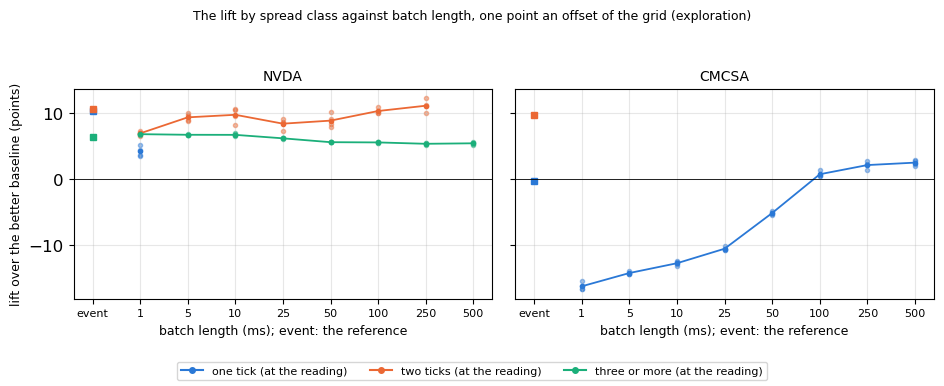

In [36]:
# Section 4, table 6 and figure: the lift as a sweep over batch length, the only way a batched one-tick lift is shown.
# The exploration stocks only (the reported stocks have three rungs, not a sweep). Each length is run on LAD_OFFSETS
# offsets of the batch grid (the windows start k / 4 of a length after 09:30:00; the unit clock does not move),
# because at some lengths the figure moves with the grid's offset: the mean over the offsets is the line, each offset
# a point, and a class is drawn at a length only if every offset has MIN_READINGS readings or more. Needs the ladder's
# machinery and run cells.
def lad_sweep_table(run_out):
    # a row a batch length (and the reference): for each spread class, the readings (the range over the offsets), the
    # lift
    # in points (the mean over the offsets and the range) and the hit and reversal rates (the means); a class under
    # MIN_READINGS readings at some offset is a count only
    rows = {}
    reference = run_out['rungs'][LAD_REFERENCE]['imbalance']['classes']
    rows['reference (every event)'] = {}
    for spread in CLASSES:
        row = reference[spread]
        rows['reference (every event)'] |= {
            f'{spread}: readings': f'{row["n"]:,}',
            f'{spread}: lift pp': f'{100 * row["lift over the better"]:+.1f}' if row['shown'] else 'count only',
            f'{spread}: hit / reversal %': f'{100 * row["hit"]:.1f} / {100 * row["reversal"]:.1f}'
            if row['shown']
            else '-',
        }
    for ms in LAD_SWEEP_MS:
        cells = {}
        for spread in CLASSES:
            offsets = [run_out['sweep'][ms, k]['classes'][spread] for k in range(LAD_OFFSETS)]
            n = [row['n'] for row in offsets]
            cells[f'{spread}: readings'] = f'{min(n):,} to {max(n):,}' if min(n) != max(n) else f'{n[0]:,}'
            if min(n) >= MIN_READINGS:
                lift = [100 * row['lift over the better'] for row in offsets]
                cells[f'{spread}: lift pp'] = f'{np.mean(lift):+.1f} ({min(lift):+.1f} to {max(lift):+.1f})'
                cells[f'{spread}: hit / reversal %'] = (
                    f'{100 * np.mean([row["hit"] for row in offsets]):.1f} / '
                    f'{100 * np.mean([row["reversal"] for row in offsets]):.1f}'
                )
            else:
                cells[f'{spread}: lift pp'] = 'count only'
                cells[f'{spread}: hit / reversal %'] = '-'
        rows[f'{ms:g} ms'] = cells
    return pd.DataFrame.from_dict(rows, orient='index')


if need(DAY, LAD_ALL):
    if lad_explored:
        print(
            f'The lift over the better baseline within each spread class as a sweep over batch length, {EXPLORATION}, '
            f'{day_text(DAY)}; {convention("none")}, session {SESSION_START} to {SESSION_END}.'
        )
        print(
            f'Each batch length is run on {LAD_OFFSETS} offsets of the grid; the lift is the mean over the offsets '
            f'with the range in parentheses; a class with under {MIN_READINGS} readings at some offset is a count '
            'only. Hit and reversal rates are means over the offsets. Not a statement about any feed.\n'
        )
        for lad_stock_name, lad_out in lad_explored.items():
            print(f'{lad_stock_name}:')
            print(lad_sweep_table(lad_out).to_string())
            print()
        lad_fig, lad_axes = plt.subplots(
            1, len(lad_explored), figsize=(4.8 * len(lad_explored), 3.8), sharey=True, squeeze=False
        )
        lad_x = np.arange(len(LAD_SWEEP_MS) + 1)
        lad_handles = {}
        for lad_ax, (lad_stock_name, lad_out) in zip(lad_axes[0], lad_explored.items(), strict=True):
            for lad_color, lad_spread in zip((BLUE, ORANGE, AQUA), CLASSES, strict=True):
                lad_ref = lad_out['rungs'][LAD_REFERENCE]['imbalance']['classes'][lad_spread]
                if lad_ref['shown']:
                    lad_ax.plot([0], [100 * lad_ref['lift over the better']], marker='s', color=lad_color, markersize=5)
                    lad_handles[lad_spread] = lad_color
                lad_means = []
                for lad_i, lad_ms in enumerate(LAD_SWEEP_MS, start=1):
                    lad_rows = [lad_out['sweep'][lad_ms, k]['classes'][lad_spread] for k in range(LAD_OFFSETS)]
                    if all(row['n'] >= MIN_READINGS for row in lad_rows):
                        lad_lifts = [100 * row['lift over the better'] for row in lad_rows]
                        lad_ax.scatter([lad_i] * len(lad_lifts), lad_lifts, s=9, color=lad_color, alpha=0.45)
                        lad_means.append((lad_i, float(np.mean(lad_lifts))))
                if lad_means:
                    lad_ax.plot(*zip(*lad_means, strict=True), color=lad_color, linewidth=1.3, marker='o', markersize=3)
                    lad_handles[lad_spread] = lad_color
            lad_ax.axhline(0, color='black', linewidth=0.6)
            lad_ax.set_xticks(lad_x, ['event'] + [f'{ms:g}' for ms in LAD_SWEEP_MS], fontsize=8)
            lad_ax.set_xlabel('batch length (ms); event: the reference', fontsize=9)
            lad_ax.set_title(lad_stock_name, fontsize=10)
        lad_axes[0][0].set_ylabel('lift over the better baseline (points)', fontsize=9)
        lad_fig.suptitle(
            'The lift by spread class against batch length, one point an offset of the grid '
            f'({EXPLORATION.split(":")[0]})',
            fontsize=9,
        )
        lad_fig.legend(
            [plt.Line2D([], [], color=color, marker='o', markersize=4) for color in lad_handles.values()],
            [f'{spread} (at the reading)' for spread in lad_handles],
            loc='lower center',
            ncols=len(lad_handles),
            fontsize=8,
        )
        lad_fig.tight_layout(rect=(0, 0.07, 1, 0.95))
        plt.show()
        for lad_stock_name, lad_out in lad_explored.items():
            lad_first = lad_out['sweep'][LAD_SWEEP_MS[0], 0]
            assert lad_first['updates'] > 0 and lad_first['readings'] > 0, (
                f'{lad_stock_name}: the finest batch has no readings'
            )
            assert all(
                lad_out['sweep'][ms, k]['offset ms'] == ms * k / LAD_OFFSETS
                for ms in LAD_SWEEP_MS
                for k in range(LAD_OFFSETS)
            ), f'{lad_stock_name}: the sweep\'s offsets are not the grid\'s fractions'
    else:
        print('no exploration stock was run, so there is no sweep.')

TODO(prose): The sweep over batch length (the table and the figure above; the exploration stocks only, labeled as exploration): for each class that has 200 readings or more at every offset of a length, the lift at each length with its range over the four offsets, and the hit and reversal rates beside it; say how the lift moves as the length grows and how much it moves with the offset at each length (the range in parentheses and the spread of the points), and what the hit and reversal rates show (which of them moves); and that a class under 200 readings at some offset is a count at that length, so that a stock whose one-tick class is small has no one-tick line over most of the lengths. The explanation the exploration gave, that the reading is taken one window after the change it follows, belongs here as the exploration's reading and not as a result. This is a sweep over batch length on two stocks of one day and not a statement about any feed: no direction for feeds in general is claimed, and no single batched one-tick lift is a figure of this notebook.

In [37]:
# Section 4, the ladder's prediction. The rule (the predictions cell): the median half-hour R2 of the order flow
# imbalance at OFI_MAIN seconds is lower at the last batch length than on the reference, with half the drop or more
# already at the first, and the lag-0 quote rule, per lot, is lower at the last than on the reference by 2 points or
# more. It is judged for each reported stock by the setup's judge on `results['ladder']`, which lad_judged builds from
# a stock's figures; the exploration stocks are shown with the same inputs and no verdict (what the code was built on
# is not a result). Needs the ladder's machinery and run cells.
def lad_inputs_table(results, judge):
    # a row a stock: the rule's inputs and, for the reported stocks, its status. The lag-0 quote rule's level depends on
    # the spreads the stock trades at (a stock that trades at three ticks or more is read higher at every batch length),
    # so the rule reads the drop from the reference to the last batch length, and the reference's level, the level at
    # the last and the drop are printed together; lad_level_split gives the level by spread class.
    rows = {}
    for stock, run_out in results.items():
        keys = lad_judged(run_out)
        reference, first, last = keys['median_r2_reference'], keys['median_r2_1ms'], keys['median_r2_100ms']
        quote_reference = keys['quote0_reference']
        row = {
            f'median R2, {OFI_MAIN} s, reference': reference,
            f'batch {LAD_FIRST:g} ms': first,
            f'batch {LAD_LAST:g} ms': last,
            f'share of the drop at {LAD_FIRST:g} ms': (reference - first) / (reference - last)
            if reference > last
            else math.nan,
            'lag-0 quote rule, reference, per lot %': 100 * quote_reference,
            f'lag-0 quote rule at {LAD_LAST:g} ms, per lot %': 100 * keys['quote0_100ms'],
            'drop from the reference, pp': 100 * (quote_reference - keys['quote0_100ms']),
        }
        if judge:
            row['status'] = PREDICTIONS['ladder'].judge({'ladder': keys}).status
        rows[stock] = row
    return pd.DataFrame.from_dict(rows, orient='index')


def lad_level_split(results):
    # The lag-0 quote rule per lot on the reference and at the last batch length, by the spread before the order in the
    # reference's book (the true spread), with the fills in each class and the drop in points: a level depends on the
    # spreads at which the stock trades (the rule reads the drop, which is why it does not read a level), so the drop
    # is shown class by class. A class with under MIN_READINGS fills is its count only.
    last = lad_name('batch', LAD_LAST)
    rows = {}
    for stock, run_out in results.items():
        row = {}
        for spread in CLASSES:
            ref = run_out['rungs'][LAD_REFERENCE]['by true spread']['quote0'][spread]
            end = run_out['rungs'][last]['by true spread']['quote0'][spread]
            shown_class = ref['fills'] >= MIN_READINGS
            tag = {'one tick': '1', 'two ticks': '2', 'three or more': '3+'}[spread]  # the table's column heads
            row[f'{tag}: fills'] = ref['fills']
            row[f'{tag}: ref %'] = 100 * ref['per lot'] if shown_class else math.nan
            row[f'{tag}: {LAD_LAST:g} ms %'] = 100 * end['per lot'] if shown_class else math.nan
            row[f'{tag}: drop pp'] = 100 * (ref['per lot'] - end['per lot']) if shown_class else math.nan
        rows[stock] = row
    return pd.DataFrame.from_dict(rows, orient='index')


if need(DAY, LAD_ALL):
    if lad_explored:
        print(f'What the ladder\'s rule reads, {EXPLORATION}, {day_text(DAY)}; no verdict: they are not reported.\n')
        print(shown(lad_inputs_table(lad_explored, judge=False)))
        print()
    if lad_reported:
        print(f'The ladder\'s prediction on the reported stocks, {day_text(DAY)}.')
        print(f'Rule: {PREDICTIONS["ladder"].rule}.\n')
        lad_keys = {stock: lad_judged(figures) for stock, figures in lad_reported.items()}
        lad_verdicts = {
            stock: {'ladder': PREDICTIONS['ladder'].judge({'ladder': keys})} for stock, keys in lad_keys.items()
        }
        print(shown(lad_inputs_table(lad_reported, judge=True)))
        print(
            f'\nThe lag-0 quote rule per lot at the reference and at {LAD_LAST:g} ms by the spread before the order '
            '(the true spread; 1, 2 and 3+ ticks), with the fills in each class:'
        )
        lad_split = lad_level_split(lad_reported)
        print(shown(lad_split, {c: ',.0f' if 'fills' in c else '.1f' for c in lad_split.columns}))
        print()
        for lad_line in unrun_lines(DAY, lad_reported):
            print(f'{lad_line} (the ladder was not run: not judged)')
        for lad_stock_name, lad_verdict in lad_verdicts.items():
            print(f'{lad_stock_name}: {lad_verdict["ladder"].status}: {lad_verdict["ladder"].detail}')
        lad_counts = counts_of(verdict_table(lad_verdicts))
        print(
            f'\nladder: {int(lad_counts.loc["ladder", "passed"])} of {int(lad_counts.loc["ladder", "judged"])} judged '
            f'stocks pass ({int(lad_counts.loc["ladder", "stocks"])} stocks), {day_text(DAY)}.'
        )
        print(
            '\nThe median half-hour R2 is judged on the displayed tape with a replace as one, at the first and the '
            'last batch length; the pooled R2 is never the ladder\'s evidence. The shifted rungs are a bound, not '
            'a venue\'s model.'
        )

What the ladder's rule reads, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; no verdict: they are not reported.

      median R2, 10 s, reference batch 1 ms batch 100 ms share of the drop at 1 ms lag-0 quote rule, reference, per lot % lag-0 quote rule at 100 ms, per lot % drop from the reference, pp
NVDA                       0.675      0.612        0.637                     1.673                                 99.802                                92.367                       7.434
CMCSA                      0.822      0.756        0.736                     0.767                                 98.348                                84.968                      13.380

The ladder's prediction on the reported stocks, 2019-03-27.
Rule: the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already at 1 ms, and the quote rule at lag 0, per lot, is lower at 100 ms than on the reference by 2 points or mo

TODO(prose): The ladder's prediction on the reported stocks (the verdict table and the count above): for each reported stock the median half-hour R2 at 10 s on the reference, at 1 ms and at 100 ms, the share of the drop that is already there at 1 ms, the lag-0 quote rule per lot on the reference and at 100 ms with its drop in points, and the verdict; how many of the five stocks pass, stated as a count of stocks on this day (the second day's count is in section 6). A stock whose R2 does not fall at 100 ms has no share to report and the table says so. The exploration stocks' inputs (above, no verdict) are what the rule was written from and are said to be so. Nothing is said of the pooled R2 as evidence, nothing about any feed, and no two stocks are said to differ.

**What this cannot show.**

- *No venue's feed.* Each rung is one rule applied to one exchange's order-by-order stream. A real feed differs in every respect that these rungs fix: how a batch is cut, where it is stamped, the order of its updates, which trades it publishes and whether they carry a side, and the delay between its book and its trades. The shifted rungs move the trades by a constant that no venue is known to have: they are a bound on what an unsynchronized trade stream does. Nothing here says what any feed gives, and nothing in it is a direction for feeds in general.
- *The trade stream is kinder than a feed's may be.* On every rung the trades keep their true aggressor, the grouping of an order's fills into one order and their time to the nanosecond. The quote rule's losses here are therefore the losses of the book's staleness and of the shift alone. A feed that stamps trades to the millisecond may not give an order's fills as one (on the exploration stocks that was found to lose 30% of NVDA's aggressive orders and 23% of CMCSA's: exploration, from the ladder's diagnostics and not measured in this notebook), so no per-order accuracy is shown.
- *The displayed tape only.* Hidden executions are not in any rung, so no figure here says anything about hidden volume, the hidden share, or the signed tape of sections 1 to 3; a figure of this section is compared only with the reference rung's, which is the displayed tape.
- *Not every study.* Resilience and the order-to-trade ratio are not run on a rung (a batch update's kind, side, price and size are placeholders), and the queue race is not fitted on one.
- *One grid, one day.* The windows of a batch rung start at 09:30:00; the sweep shows that at some lengths the figure moves with the offset of the grid, for two stocks of one day, and not at which lengths it would for a stock it was not run on. A class with under 200 readings is a count, which on a stock with a wide spread leaves the one-tick lift of most batched rungs unshown.
- *One day, shared factor.* The five reported stocks share each day's market factor, so a count of stocks that pass is a count over stocks that move together and not five independent trials, no two stocks are said to differ, and a figure is that stock's on that day. The block bootstrap assumes exchangeable half hours, which the unequal half hours contradict.
- *The thresholds.* The prediction's two thresholds (a median R2 that falls, half of it by 1 ms; a lag-0 quote rule, per lot, that falls by 2 points or more from the reference to 100 ms) were chosen on two stocks; where a reported stock lies near one the verdict is as much a statement about the threshold as about the stock, and the table prints each figure beside its verdict for that reason.
- *The pooled R2 is a check.* A pooled R2 can rise under batching when a few seconds carry most of the flow's sum of squares; it is printed beside the median half-hour R2 to show that, and is never the evidence.

## Section 5: The calibration

**The question.** What must the simulator's model be to look like a real day, and does it then? `MikeFarmer2008Model` has eight parameters (`lam`, `cancel_rate`, `imbalance_offset`, `hurst`, `nu`, `loc`, `scale`, `lot_size`), and notebook 08 built an estimator for each from order-level data in LOBSTER's format. Here those estimators are pointed at a real day of each reported stock: `calibrate_lobster` reads the day's messages and book, and the fitted model is then simulated and set beside the day, fact by fact and half hour by half hour.

**This is a calibration that fails, and the section says so before it runs.** The reasons are in the model's structure and not in any one stock: the model has one order size, one cancellation hazard for every resting order, one symmetric law for the price of a new order, Poisson arrivals at a constant rate, no hidden orders and no replaces, and a stationary day, and a real order book has none of these. A fit says what the model would need to look like the day *on average*, one part at a time (arrivals, prices, signs, cancellations); it does not say that the whole looks like the day, and nothing in a maximum-likelihood fit asks the simulated book to. So the section reports, for each reported stock, which facts the fitted model reproduces and which it cannot, by how much, and why. It also says what a fitted number is not: a cancel rate is not a property of a stock (on the two exploration stocks the same day gave a cancel rate 6 to 40 times as large in a half hour fitted as a file of its own as in the day's fit, and the same half hours fitted with the day's history came out within a factor of two of it: exploration figures, not this section's), and no fitted set is offered as a preset.

**What notebook 08 found, on the model's own output.** The estimators recover known parameters from the simulator, including through LOBSTER's format and from a file that starts on a full book. Quoted from its saved output (seeds 1 to 8; the file that starts on a full book, 101 to 108), and printed again by the next cell: *"From the files, every mean estimate's 95% interval covers the true value."*, *"Noisiest relative to its value: imbalance_offset (one run's estimate scatters by about 17%)."*, and *"imbalance_offset: true 0.2; without a burn-in 0.205 (0.1896 to 0.2205), with one 0.2049"*. So an estimate of B that sits on the fit's bound on a real day is not the estimator's habit on the model's own data; whether it says more than that the day has no dependence of cancellations on the own side's share is for Table 4 below.

**What the two exploration stocks showed** (exploration: NVDA and CMCSA, 2019-03-27, what this section's code was built on; neither is a result here, and neither is read on the second day). `imbalance_offset` was at the fit's bound of 50 for the whole day and in every half hour fitted as a file, and the dashboard's range for it ends at 5; CMCSA's `nu` (0.44) and `scale` (0.07) were below the dashboard's minimums (0.5 and 0.5). The fitted model had 7.6 times (NVDA) and 8.6 times (CMCSA) the real day's aggressive orders and a book 17 to 72 times too deep on NVDA across its first ten ticks and 45 times too deep at the touch on CMCSA, whose mid did not move once in any of eight seeds over the 22,200 s of the session. The cancel rate of a half hour fitted as a file was about 40 times the day's on NVDA, while the half hours fitted with the day's history came out within a factor of two of the day's. What the model did reproduce there was the order rate (by construction) and, on NVDA, the one-second volatility within about a tenth and the order signs' autocorrelation at lags 10 and 100. These figures are the exploration's, are repeated in the predictions cell, and are what the notebook's `calibration` prediction was written from; they are not this section's results.

**What is run.** For each reported stock on the first day, in one worker a stock (`cal_calibrated`, a function of stocks and a day, so that section 6 runs the second day through it):

1. `calibrate_lobster` on the day, 09:30:00 to 16:00:00, with a burn-in of 1,800 s (notebook 08's real-data cell); and on each of the thirteen half hours from 09:30 as a file of its own (burn-in 0, so every order resting at the half hour's start is unknown to the replay); and the cancellation parameters of each half hour with the day's history replayed from the open and counted only from the half hour's start. (Table 1, Table 2.)
2. Which values sit on a bound of the fit (`b_max` 50 for B; 0.5 and 0.999 for the Hurst exponent) or outside the dashboard's ranges, read from `app/model_specs.py`. Nothing is clipped. (Table 3.)
3. B's profile log-likelihood, with the two shares that say whether a cancellation depends on the own side's share of the resting orders. (Table 4.)
4. The dropped-replace sensitivity: the day and each half hour refitted with both rows of every replace made no-ops, for every parameter and above all for `nu` and `lam`. (Table 5.) The group column, the paired reductions and the partial cancels moved nothing in the exploration and are not rerun; their row counts are printed.
5. How long the day's orders last, which is why the cancel rate depends on the window. (Table 6.)
6. The fitted model, with the day's fit, on the simulator's seeds 1 to 8 (`SIM_SEEDS`), a lot of 100 shares and a tick a cent, read as the real session is: the spread, the depth at the touch and near it, the one-second return's volatility, tails and clustering, the order signs' autocorrelation, and the orders, cancels and aggressive orders a second, in the thirteen half hours of the session (09:40 to 15:50, the first and the last cut to twenty minutes) and as a whole. (Tables 7 and 8, the figure of each stock, the depth profile.) Then the fitted price law against the offsets it was fitted to, which is where the model's aggressive orders come from (Table 9), and the two calibration tests (Tables 10 and 11).

**Conventions.** The calibration reads the frames' six LOBSTER columns, the displayed rows only; the hidden executions stay out of every fit and of the facts' counts (their shares of executed shares are in section 1); a replace is a deletion and a new order, as the frames have it, which is how `lam`, the price fit and the cancel count take it in notebook 08's code (the dropped-replace sensitivity is the only variant run). The comparison is like for like in lots: the model's order size is 100 shares (`CALIBRATION_LOT`) and the real depth is divided by 100 shares too, so a "lot" of depth is 100 shares on both sides, and a tick is a cent on both. The comparison is like for like in blocks: the real session's thirteen half hours and the model's, the same units. The model starts from an empty book at the real mid of 09:40 and is simulated for a warm-up of four mean lifetimes of a resting order (at least ten minutes, at most about an hour) before unit 0, so its book is the model's stationary one when the session begins. Every table's heading names the tape and the replace convention.

**Cost.** Measured at full length on the two exploration stocks, on a busy machine and one core a stock (exploration, not results): about 8 core-minutes for NVDA and 4.5 for CMCSA, almost all of it the cancellation replays (the day's fit, the profile of B, the dropped-replace refit, and one replay of the day's history for each of the thirteen half hours); the eight simulated days are about 1 and 2 core-minutes. The plan's budget for this part was about 8 core-minutes a stock-day; the run prints its own seconds by part and the peak memory of a worker (about 2.5 GB, the stream pass of the real session).

TODO(prose): after the run, the cost sentence: core-minutes a stock-day and the peak memory (the table of seconds by part that the next cell prints), against the plan's 8 core-minutes.

In [38]:
# Section 5, the calibration: what it reads and how it fits. Names a cell of this section makes are prefixed cal_ (the
# setup's are shared by every cell). No market data is read here: this cell only defines. A stock-day's whole result is
# made by cal_calibration(stock, day), defined in the next cell, from the functions below.
# OrderBook and reset_order_id_counter are imported under other names because section 0's cell imports them too (the
# built notebook is linted as one file: a second import of a name its first cell has not used yet fails F811).
import inspect

from matplotlib.patches import Patch
from scipy import stats

from lob.analysis.stylized_facts import compute_acf, compute_rank_volatility_acf
from lob.book import OrderBook as CalOrderBook
from lob.calibration import fit_cancellation
from lob.feeds import Break
from lob.lobster import (
    LOBSTER_TICK,
    MESSAGE_COLUMNS,
    calibrate_lobster,
    lobster_cancellation_statistics,
    lobster_orders,
    order_offsets,
)
from lob.matching import PriceTimeEngine
from lob.models.mike_farmer import MikeFarmer2008Model
from lob.order import OrderType
from lob.order import reset_order_id_counter as cal_reset_order_ids

# ---------------------------------------------------------------------------------------------------------------------
# What the calibration is asked, in the setup's names. The dashboard's ranges are read from its model spec and nothing
# is clipped to them. The window is the day (09:30 to 16:00, unit 0 at the open); the smoke copy stops where its session
# does. The half hours are those the session touches (all thirteen in the real run).
# ---------------------------------------------------------------------------------------------------------------------
cal_spec = {param.name: (param.low, param.high) for param in MODEL_SPECS['mike_farmer_2008'].params}  # the dashboard's
cal_params = tuple(cal_spec)  # the model's eight parameters, in the order calibrate_lobster reports them
assert set(inspect.signature(MikeFarmer2008Model).parameters) == set(cal_params) | {'initial_mid'}, (
    'the model takes other parameters than the dashboard\'s spec for it lists'
)
assert inspect.signature(fit_cancellation).parameters['b_max'].default == CALIBRATION_B_MAX, (
    'calibrate_lobster fits B up to the library\'s own b_max, which is not the notebook\'s CALIBRATION_B_MAX'
)
cal_fit_bounds = {'imbalance_offset': (0.0, float(CALIBRATION_B_MAX)), 'hurst': (0.5, 0.999)}  # the fit's own bounds
cal_at_bound = 1e-3  # a fit this close to a bound of the fit is "at its bound" (the optimizer stops within 1e-6)
cal_end = U1 if SMOKE else CAL1  # the calibration's day in units from 09:30:00; the smoke copy stops with its session
cal_blocks = HAVE_BLOCKS  # the half hours of the calibration, each a file of its own: 13 from 09:30 in the real run
cal_labels = [clock(block * BLOCK)[:5] for block in cal_blocks]  # their start times, '09:30' ... '15:30'
cal_windows = [(block, max(U0, block * BLOCK), min(U1, (block + 1) * BLOCK)) for block in cal_blocks]  # facts: session
cal_session = (U0, U1)  # the session's units, where the facts are read (the opening ten minutes and the last ten out)
cal_tape = (  # named in the heading of every table: what the fits read, and how the facts count
    'fits: displayed rows only, a replace as the frames have it (a deletion and a new order); '
    f'facts: {convention(replaces_as_one=False)}'
)
cal_levels = 10  # levels of the book frame
cal_depth_ticks = 10  # ticks from the same-side best quote at which depth is read (0 is the touch)
cal_placeholder = 9e9  # lob.feeds: a price this far from 0 is LOBSTER's marker of an empty level
cal_noop = 7  # a row type that neither lobster_orders nor the cancellation replay reads
cal_b_points = (0.0, 1.0, cal_spec['imbalance_offset'][1], float(CALIBRATION_B_MAX), 4.0 * CALIBRATION_B_MAX)
cal_b_grid = np.unique(
    np.concatenate([[0.0], np.logspace(-2, 4, 61), cal_b_points, [200.0 * CALIBRATION_B_MAX]])
)  # B's profile is read on this grid, to 10,000 (200 times the bound)
cal_region = stats.chi2.ppf(0.95, 1) / 2  # the log-likelihood a 95% likelihood region reaches below the best (1.92)
cal_warm_min, cal_warm_max, cal_warm_lifetimes, cal_warm_hazard = 600.0, 4_000.0, 4.0, 0.63
cal_sign_lags = (1, 10, 100)  # lags (in orders) at which the order signs' autocorrelation is read
cal_offsets = range(-6, 12)  # offsets from the same-side best quote shown against the fitted law
cal_age_marks = (0.001, 1.0, 10.0)  # seconds: the shares of deletions within each of these ages of the order's placing
cal_notebook_08 = '08_calibration.ipynb'  # notebook 08's saved output, which the opening quotes
cal_cache = {}  # (day, stock) -> cal_calibration's result, kept by cal_calibrated()


# ---------------------------------------------------------------------------------------------------------------------
# The frames, cut at the calibration's end where a smoke copy shortens it
# ---------------------------------------------------------------------------------------------------------------------
def cal_frames(stock, day):
    # messages, book and hidden of a stock-day. At full length the frames as they are; in a smoke copy the rows before
    # the shortened day's end.
    messages, book, hidden = frames_of(stock, day)
    if cal_end >= CAL1:
        return messages, book, hidden
    stop = OPEN + cal_end
    rows = int(np.searchsorted(messages['time'].to_numpy(), stop, side='left'))
    return messages.iloc[:rows], book.iloc[:rows], hidden[hidden['time'] < stop]


def cal_block_rows(time_s, block):
    # the rows of the messages that fall in a half hour of the calibration (from 09:30:00)
    low = np.searchsorted(time_s, OPEN + block * BLOCK, side='left')
    high = np.searchsorted(time_s, OPEN + (block + 1) * BLOCK, side='left')
    return int(low), int(high)


def cal_row_counts(messages, hidden, orders):
    # rows of the frames in the calibration's day, by what the calibration does with them, and the orders they make
    kinds = messages['type'].to_numpy()
    return {
        'messages': int(len(messages)),
        'adds': int((kinds == 1).sum()),
        'deletions': int((kinds == 3).sum()),
        'partial cancels': int((kinds == 2).sum()),
        'executions': int((kinds == 4).sum()),
        'replace rows': int(messages['replace'].sum()),
        'paired reductions': int(messages['paired'].sum()),
        'hidden executions (not read)': int(len(hidden)),
        'orders': int(len(orders)),
        'orders executed in full': int(orders['price'].isna().sum()),
    }


# ---------------------------------------------------------------------------------------------------------------------
# The fits. calibrate_lobster is called as it is (notebook 08's): on the day with a burn-in, and on each half hour as a
# file of its own. The half hour with the day's history is the cancellation fit alone, from a replay of the day to the
# end of the half hour that counts only from its start (the orders, placed anywhere in the day, are the day's).
# ---------------------------------------------------------------------------------------------------------------------
def cal_half_hours(six, book, time_s, burn_in=0.0):
    # calibrate_lobster on each half hour's rows as a file of its own
    fits = []
    for block in cal_blocks:
        low, high = cal_block_rows(time_s, block)
        fits.append(calibrate_lobster(six.iloc[low:high], book.iloc[low:high], burn_in=burn_in))
    return fits


def cal_history(six, book, orders, time_s):
    # The cancellation parameters of each half hour with the day's history replayed: the replay runs from the open to
    # the half hour's end and counts only from its start, so the orders placed in earlier half hours are exposure.
    fits = []
    for block in cal_blocks:
        _, high = cal_block_rows(time_s, block)
        counted = lobster_cancellation_statistics(
            six.iloc[:high], book.iloc[:high], orders, burn_in=OPEN + block * BLOCK - time_s[0]
        )
        fits.append(
            fit_cancellation(counted, b_max=CALIBRATION_B_MAX)
            | {'n_cancels': int(len(counted['share'])), 'n_cancels_skipped': int(counted['skipped'])}
        )
    return fits


def cal_profile(counted, fitted_b):
    # B's profile log-likelihood on the grid (the cancel rate at its best for each B), from the replay's sums as
    # fit_cancellation reads them, less the best of the grid and of the fit itself; and the two shares that say whether
    # a cancellation depends on the own side's share of the resting orders at all. The log-likelihood at the fitted B
    # is computed exactly and not read off the grid: the grid's steps are 17% apart, and with hundreds of thousands of
    # cancels a profile that peaks inside the grid loses a few units of log-likelihood between its points. The shift is
    # the larger of the grid's best and the fit's value (the fit may sit between two grid points, above both), so the
    # fit's value is at most 0 and the grid's best within the bound at most 0 as well; `agrees` says the fit is, to
    # 0.001, at least as good as every grid point within the bound.
    share, w_u, w_v = counted['share'], counted['w_u'], counted['w_v']
    n = len(share)
    profile = np.array([np.log(share + b).sum() - n * math.log(w_u + b * w_v) for b in cal_b_grid])
    at_fit = float(np.log(share + fitted_b).sum() - n * math.log(w_u + fitted_b * w_v))
    shift = max(float(profile.max()), at_fit)
    profile -= shift
    at_fit -= shift
    inside = cal_b_grid[profile >= -cal_region]
    return {
        'B': cal_b_grid.tolist(),
        'log-likelihood': profile.tolist(),
        'log-likelihood at the fit': at_fit,
        'best on the grid within the bound': float(profile[cal_b_grid <= CALIBRATION_B_MAX].max()),
        'agrees': bool(at_fit >= float(profile[cal_b_grid <= CALIBRATION_B_MAX].max()) - 1e-3),
        'best B on the grid': float(cal_b_grid[profile.argmax()]),
        'region': (float(inside.min()), float(inside.max())),  # the 95% likelihood region on the grid
        'n cancels': int(n),
        'share at a cancel': float(share.mean()),  # the mean own-side share of resting orders at the cancels
        'share of exposure': float(w_u / w_v),  # the same share, weighted by the exposure the rate divides by
    }


def cal_replaces_dropped(messages):
    # The messages with every replace's two rows made no-ops (type cal_noop) and the later messages of a replaced order
    # given its first reference, so that neither row is an arrival or a cancellation and no order is left resting.
    # lob.itch's `replace` flag marks both rows of a pair (the deletion of the old reference, then the new order).
    changed = messages.copy()
    marked = changed['replace'].to_numpy(bool)
    kind = changed['type'].to_numpy(int).copy()
    order_id = changed['order_id'].to_numpy(np.int64).copy()
    rows = np.nonzero(marked)[0]
    assert len(rows) % 2 == 0 and (kind[rows[0::2]] == 3).all() and (kind[rows[1::2]] == 1).all(), (
        'the replace rows are not pairs of a deletion and a new order'
    )
    assert (rows[1::2] == rows[0::2] + 1).all(), 'the two rows of a replace are not next to each other'
    root = {}
    for deletion, new in zip(rows[0::2], rows[1::2], strict=True):
        old = int(order_id[deletion])
        root[int(order_id[new])] = root.get(old, old)
    if root:
        keys = np.array(sorted(root), dtype=np.int64)
        values = np.array([root[key] for key in keys], dtype=np.int64)
        at = np.searchsorted(keys, order_id)
        at[at == len(keys)] = 0
        order_id = np.where(keys[at] == order_id, values[at], order_id)
    kind[marked] = cal_noop
    changed['type'] = kind
    changed['order_id'] = order_id
    return changed[MESSAGE_COLUMNS]


def cal_ages(messages, stop):
    # How long the day's orders last, from the frames: the age of an order at its deletion, the orders still resting at
    # the end, and the share of the day's order-seconds that is age beyond a half hour (the exposure that the replay of
    # the whole day divides the cancellations by, which a half hour as a file does not have).
    time_s = messages['time'].to_numpy()
    kind = messages['type'].to_numpy()
    order_id = messages['order_id'].to_numpy(np.int64)
    size = messages['size'].to_numpy(np.int64)
    add = kind == 1
    placed = pd.Series(time_s[add], index=order_id[add])
    first_size = pd.Series(size[add], index=order_id[add])
    deleted = pd.Series(time_s[kind == 3], index=order_id[kind == 3])
    deleted = deleted[deleted.index.isin(placed.index)]
    reduced = pd.DataFrame({'id': order_id[(kind == 2) | (kind == 4)], 't': time_s[(kind == 2) | (kind == 4)]})
    reduced['cumulative'] = pd.Series(size[(kind == 2) | (kind == 4)]).groupby(reduced['id']).cumsum().to_numpy()
    reduced = reduced[reduced['id'].isin(placed.index)]
    gone = reduced[reduced['cumulative'] >= first_size.reindex(reduced['id']).to_numpy()]
    gone = pd.Series(gone['t'].to_numpy(), index=gone['id'].to_numpy()).groupby(level=0).min()  # the last share goes
    ends = pd.concat([deleted, gone]).groupby(level=0).min()
    age_deleted = (deleted - placed.reindex(deleted.index)).to_numpy()
    end_all = pd.Series(stop, index=placed.index)
    end_all.loc[ends.index] = ends.to_numpy()
    lifetime = (end_all - placed).to_numpy()
    return {
        'orders placed': int(len(placed)),
        'resting at the end': float((len(placed) - len(ends)) / len(placed)),
        'deletions of placed orders': int(len(deleted)),
        'deleted within': {mark: float((age_deleted <= mark).mean()) for mark in cal_age_marks},
        'median age at deletion': float(np.median(age_deleted)),
        'order-seconds beyond a half hour': float(np.clip(lifetime - BLOCK, 0, None).sum() / lifetime.sum()),
    }


def cal_price_fit(orders, fit):
    # The offset law the fit found against the offsets it was fitted to: the share of all orders at each offset from the
    # same-side best quote (positive: less aggressive; an order that executed in full shows only that its offset was at
    # most a bound, so it is counted apart), the shares at or beyond one tick inside the quote, and the orders that
    # trade
    # on arrival against the fitted law's.
    exact, bounds = order_offsets(orders)
    n = len(exact) + len(bounds)

    def cdf(k):
        return float(stats.t.cdf((k + 0.5 - fit['loc']) / fit['scale'], fit['nu']))

    return {
        'orders with a same-side quote': int(n),
        'share by offset: data (exact)': {k: float((exact == k).sum() / n) for k in cal_offsets},
        'share by offset: fitted law': {k: cdf(k) - cdf(k - 1) for k in cal_offsets},
        'executed in full (offset known only to be at most a bound)': float(len(bounds) / n),
        'share at an offset of -1 or less: data, exact': float((exact <= -1).sum() / n),
        'share at an offset of -1 or less: fitted law': cdf(-1),
        'share of orders that trade on arrival': float((orders['executed'] > 0).mean()),
    }


# ---------------------------------------------------------------------------------------------------------------------
# What the dashboard refuses, and what the fit's own bounds hold. Nothing is clipped.
# ---------------------------------------------------------------------------------------------------------------------
def cal_outside(name, value):
    # True where a value is outside the dashboard's range for the parameter
    low, high = cal_spec[name]
    return bool(value < low or value > high)


def cal_at_fit_bound(name, value):
    # True where a value sits on a bound of the fit itself (B's b_max, the Hurst exponent's 0.5 and 0.999)
    low, high = cal_fit_bounds.get(name, (math.nan, math.nan))
    return bool(abs(value - low) < cal_at_bound or abs(value - high) < cal_at_bound)

In [39]:
# Section 5, the fitted model beside the day: notebook 05's facts read the same way off the real session and off a
# simulated one, and the function that makes a whole stock-day's result. Nothing here reads market data until
# cal_calibration is called.
#
# A session is what the facts read, a unit of one second at a time (unit u is the seconds [u, u + 1) after unit 0, which
# begins at the open for the real day and after the warm-up for a simulation): the mid, the spread (ticks) and the depth
# at 0 to 9 ticks from the same-side best (shares), each from the book before the event that opens the unit, as
# lob.feeds.run takes them; the counts of events, orders (a new limit order or an aggressive order), cancels and
# aggressive orders in the unit; and the sign of every order, in time order.


def cal_new_session(n_units):
    return {
        'mid': np.full(n_units, np.nan),
        'spread': np.full(n_units, np.nan),
        'depth': np.full((n_units, 2, cal_depth_ticks), np.nan),
        'events': np.zeros(n_units),
        'orders': np.zeros(n_units),
        'cancels': np.zeros(n_units),
        'aggressive': np.zeros(n_units),
        'fills': np.zeros(n_units),
        'order_time': np.zeros(0),
        'order_sign': np.zeros(0),
    }


def cal_fill_units(sess, units, bid_price, bid_size, ask_price, ask_size):
    # The unit samples of a session from the ten best levels of each side at the given units: prices in ticks (NaN: no
    # level), sizes in shares, best first. A tick with no order has depth 0; a tick beyond the farthest of ten shown
    # levels is not observed (NaN), so a deep book is not read as an empty one.
    best_bid, best_ask = bid_price[:, 0], ask_price[:, 0]
    ok = np.isfinite(best_bid) & np.isfinite(best_ask) & (best_bid < best_ask)
    sess['mid'][units] = np.where(ok, (best_bid + best_ask) / 2, np.nan)
    sess['spread'][units] = np.where(ok, best_ask - best_bid, np.nan)
    for side, (price, size, best) in enumerate(((bid_price, bid_size, best_bid), (ask_price, ask_size, best_ask))):
        distance = np.abs(best[:, None] - price)
        present = np.isfinite(price)
        farthest = np.where(present, distance, -1).max(axis=1)  # the farthest tick that a shown level holds
        full = present.sum(axis=1) >= cal_levels
        for tick in range(cal_depth_ticks):
            depth = np.where(present & (distance == tick), size, 0).sum(axis=1).astype(float)
            depth = np.where(~full | (tick <= farthest), depth, np.nan)
            sess['depth'][units, side, tick] = np.where(ok, depth, np.nan)


def cal_real_session(messages, book, hidden, orders):
    # The real day's session from its frames: the unit samples from the book frame, the counts from the stream of
    # lob.feeds (a replace is two events here, the deletion and the new order, as the calibration counts them), and the
    # order signs from lobster_orders (the same orders the fit reads).
    n_units = int(U1)
    sess = cal_new_session(n_units)
    time_s = messages['time'].to_numpy()
    rows = np.searchsorted(time_s, OPEN + np.arange(n_units), side='left') - 1  # the last message before each unit
    units = np.nonzero(rows >= 0)[0]
    last = rows[units]
    tick = float(LOBSTER_TICK)
    columns = {}
    for name in ('bid_price', 'bid_size', 'ask_price', 'ask_size'):
        values = np.column_stack([book[f'{name}_{i}'].to_numpy(float)[last] for i in range(1, cal_levels + 1)])
        columns[name] = np.where(np.abs(values) > cal_placeholder, np.nan, values) if name.endswith('price') else values
    cal_fill_units(
        sess,
        units,
        columns['bid_price'] / tick,
        columns['bid_size'],
        columns['ask_price'] / tick,
        columns['ask_size'],
    )
    for event in lobster_events(messages, book, hidden, hidden_mode=TAPE):
        if isinstance(event, Break):
            continue
        unit = int(event.t - OPEN)
        if unit >= n_units:
            break
        if not 0 <= unit:
            continue
        sess['events'][unit] += 1
        if event.kind == CANCEL:
            sess['cancels'][unit] += 1
        else:
            sess['orders'][unit] += 1
        if event.fills:
            sess['aggressive'][unit] += 1
            sess['fills'][unit] += sum(1 for fill in event.fills if not fill.hidden)
    sess['order_time'] = orders['time'].to_numpy() - OPEN
    sess['order_sign'] = np.where(orders['side'] == 'bid', 1.0, -1.0)
    return sess


def cal_window_facts(sess, first, last):
    # The facts of the units [first, last) of a session: a dict of floats (the depth profile a list of ten)
    facts = {}
    spread = sess['spread'][first:last]
    seen = spread[np.isfinite(spread)]
    facts['units with a spread'] = float(np.isfinite(spread).mean())
    facts['spread mean (ticks)'] = float(seen.mean())
    facts['spread median (ticks)'] = float(np.median(seen)) if len(seen) else math.nan
    facts['share at one tick'] = float((seen == 1).mean())
    facts['share at 5 ticks or more'] = float((seen >= 5).mean())
    depth = sess['depth'][first:last]  # units x side x tick
    for tick in (0, 1, 3, 9):
        facts[f'depth at {tick} (lots)'] = float(np.nanmean(depth[:, :, tick])) / CALIBRATION_LOT
    facts['depth profile (lots)'] = (np.nanmean(depth, axis=(0, 1)) / CALIBRATION_LOT).tolist()
    mid = sess['mid'][first:last]
    both = np.isfinite(mid[1:]) & np.isfinite(mid[:-1])
    ret = np.log(mid[1:][both] / mid[:-1][both])
    moving = len(ret) > 2 and ret.std() > 0  # compute_acf gives ones for a constant series: undefined here
    facts['1 s return sd (bp)'] = float(ret.std() * 1e4) if len(ret) else math.nan
    facts['zero 1 s returns'] = float((ret == 0).mean()) if len(ret) else math.nan
    facts['mid changes a second'] = float((ret != 0).sum() / (last - first))  # between two 1 s samples of the mid
    facts['excess kurtosis of 1 s returns'] = float(stats.kurtosis(ret)) if moving else math.nan
    facts['rank |r| acf, lag 1'] = (
        float(compute_rank_volatility_acf(ret, 1)[1]) if moving and (ret != 0).sum() > 2 else math.nan
    )
    facts['return acf, lag 1'] = float(compute_acf(ret, 1)[1]) if moving else math.nan
    signs = sess['order_sign'][(sess['order_time'] >= first) & (sess['order_time'] < last)]
    acf = compute_acf(signs, cal_sign_lags[-1]) if len(signs) > cal_sign_lags[-1] + 1 else None
    for lag in cal_sign_lags:
        facts[f'sign acf, lag {lag}'] = float(acf[lag]) if acf is not None else math.nan
    span = last - first
    for name, key in (
        ('events a second', 'events'),
        ('orders a second', 'orders'),
        ('cancels a second', 'cancels'),
        ('aggressive orders a second', 'aggressive'),
        ('displayed fills a second', 'fills'),
    ):
        facts[name] = float(sess[key][first:last].sum() / span)
    return facts


def cal_facts_of(sess):
    # the facts of every half hour of the session (cal_windows) and of the session as a whole
    return {
        'blocks': [
            {'block': block, 'first': first, 'last': last, **cal_window_facts(sess, first, last)}
            for block, first, last in cal_windows
        ],
        'session': cal_window_facts(sess, *cal_session),
    }


def cal_warm_up(cancel_rate):
    # seconds simulated from an empty book before unit 0: four lifetimes of an order at the cancellation hazard that an
    # order at the distance it was placed has, never under ten minutes or over about an hour
    return float(min(max(cal_warm_min, cal_warm_lifetimes / (cal_warm_hazard * cancel_rate)), cal_warm_max))


def cal_simulate(params, seconds, warmup, seed, initial_mid):
    # One run of the fitted model, read as the real day is. The loop is lob.simulation.Simulation.run's (the model's
    # event, the clock set to its time, the matching engine) stopped at a time and not at a count, with the book
    # sampled at each unit's start. `seconds` of units are kept after `warmup` seconds from an empty book.
    cal_reset_order_ids()
    model = MikeFarmer2008Model(initial_mid=int(initial_mid), **params)
    book, engine = CalOrderBook(), PriceTimeEngine()
    rng = np.random.default_rng(seed)
    n_units = int(seconds)
    sess = cal_new_session(n_units)
    price = {side: np.full((n_units, cal_levels), np.nan) for side in (Side.BID, Side.ASK)}
    size = {side: np.zeros((n_units, cal_levels)) for side in (Side.BID, Side.ASK)}
    sampled = np.zeros(n_units, bool)
    order_time, order_sign = [], []
    t, next_unit = 0.0, 0
    while True:
        order = model.generate_event(book, t, rng)
        if order is None:
            continue
        t = order.timestamp
        rel = t - warmup
        if rel >= seconds:
            break
        while rel >= next_unit and next_unit < n_units:  # the units this event passes: the book as it stands, before it
            for side in (Side.BID, Side.ASK):
                for level, (level_price, level_size) in enumerate(book.depth_profile(side, cal_levels)):
                    price[side][next_unit, level], size[side][next_unit, level] = level_price, level_size
            sampled[next_unit] = True
            next_unit += 1
        if order.order_type == OrderType.CANCEL:
            if book.get_order(order.order_id) is None:
                continue
            book.cancel_order(order.order_id)
            if rel >= 0:
                sess['events'][int(rel)] += 1
                sess['cancels'][int(rel)] += 1
            continue
        fills = engine.process(book, order)
        if rel >= 0:
            unit = int(rel)
            sess['events'][unit] += 1
            sess['orders'][unit] += 1
            if fills:
                sess['aggressive'][unit] += 1
                sess['fills'][unit] += len(fills)
            order_time.append(rel)
            order_sign.append(1.0 if order.side == Side.BID else -1.0)
    units = np.nonzero(sampled)[0]
    cal_fill_units(
        sess, units, price[Side.BID][units], size[Side.BID][units], price[Side.ASK][units], size[Side.ASK][units]
    )
    sess['order_time'], sess['order_sign'] = np.array(order_time), np.array(order_sign)
    return sess


def cal_simulated_runs(fit, initial_mid):
    # The day's fit run on each of the simulator's seeds (SIM_SEEDS): a lot of CALIBRATION_LOT shares (the fit's own
    # modal size is reported beside it), a tick a cent, the units of the session and the tail the setup's passes also
    # run past it, so that the session's last unit is sampled.
    params = {name: fit[name] for name in cal_params} | {'lot_size': CALIBRATION_LOT}
    warmup = cal_warm_up(fit['cancel_rate'])
    runs = []
    for seed in SIM_SEEDS:
        started = time.time()
        sess = cal_simulate(params, U1 + BATCH_TAIL, warmup, seed, initial_mid)
        runs.append({'seed': seed, 'seconds': time.time() - started, **cal_facts_of(sess)})
    return runs, params, warmup


# ---------------------------------------------------------------------------------------------------------------------
# One stock-day, whole: the worker function of run_stocks, and the four numbers the prediction reads
# ---------------------------------------------------------------------------------------------------------------------
def cal_calibration(stock, day=DAY):
    # Everything section 5 tabulates for one stock-day, in a dict of plain numbers (see the keys below). It reads the
    # day's frames (frames_of), fits (calibrate_lobster on the day and on each half hour as a file; the cancellation
    # fit of each half hour with the day's history; B's profile; the replaces-dropped sensitivity), measures how long
    # orders last and what offset law the fit found, reads the real session's facts, and runs the day's fit on every
    # seed.
    started = time.time()
    seconds, peaks = {}, {}

    def lap(part, since):
        seconds[part] = time.time() - since
        peaks[part] = peak_mb()
        return time.time()

    t = time.time()
    messages, book, hidden = cal_frames(stock, day)
    six = messages[MESSAGE_COLUMNS]
    time_s = six['time'].to_numpy()
    orders = lobster_orders(six, book)
    t = lap('frames and orders', t)
    day_fit = calibrate_lobster(six, book, burn_in=CALIBRATION_BURN)
    t = lap('the day', t)
    half_hours = cal_half_hours(six, book, time_s)
    t = lap('half hours as files', t)
    history = cal_history(six, book, orders, time_s)
    t = lap('half hours with history', t)
    counted = lobster_cancellation_statistics(six, book, orders, burn_in=CALIBRATION_BURN)
    refit = fit_cancellation(counted, b_max=CALIBRATION_B_MAX)
    profile = cal_profile(counted, day_fit['imbalance_offset'])
    assert math.isclose(refit['cancel_rate'], day_fit['cancel_rate'], rel_tol=1e-9) and math.isclose(
        refit['imbalance_offset'], day_fit['imbalance_offset'], rel_tol=1e-9, abs_tol=1e-9
    ), f'{stock}: the profile\'s replay is not the one calibrate_lobster fitted'
    del counted
    t = lap('profile of B', t)
    dropped = cal_replaces_dropped(messages)
    dropped_day = calibrate_lobster(dropped, book, burn_in=CALIBRATION_BURN)
    dropped_half_hours = cal_half_hours(dropped, book, time_s)
    del dropped
    t = lap('replaces dropped', t)
    ages = cal_ages(messages, OPEN + cal_end)
    price_fit = cal_price_fit(orders, day_fit)
    t = lap('ages and price law', t)
    real = cal_real_session(messages, book, hidden, orders)
    initial_mid = int(round(real['mid'][U0]))
    real_facts = cal_facts_of(real)
    counts = cal_row_counts(messages, hidden, orders)
    assert counts['orders'] == counts['adds'] + counts['orders executed in full'] == day_fit['n_orders'], (
        f'{stock}: an order is an add, or an aggressive order that executed in full: the counts do not say so'
    )
    del messages, book, hidden, six, orders
    t = lap('real session', t)
    runs, params, warmup = cal_simulated_runs(day_fit, initial_mid)
    t = lap('simulations', t)
    seconds['all'] = time.time() - started
    return {
        'stock': stock,
        'day': day,
        'window': (CAL0, cal_end),
        'blocks': list(cal_blocks),
        'rows': counts,
        'day fit': day_fit,
        'half hours as files': half_hours,
        'half hours with history': history,
        'profile': profile,
        'replaces dropped': {'day': dropped_day, 'half hours': dropped_half_hours},
        'ages': ages,
        'price law': price_fit,
        'real': real_facts,
        'sim': runs,
        'sim params': params,
        'initial mid': initial_mid,
        'warm-up': warmup,
        'seconds': seconds,
        'peak memory by part (MB)': peaks,
        'peak memory (MB)': peak_mb(),
    }


def cal_summary(detail):
    # What the calibration's two tests read, from one stock-day's result. PREDICTIONS['calibration']: B at the bound
    # (and the flag that says whether B's profile agrees with the fit, which it reads too), and the fitted model's
    # aggressive orders and its depth at the touch (the session, both sides, seeds' mean) as multiples of the real
    # day's. PREDICTIONS['calibration\'s mechanism']: the fitted model's mid changes a second and its mean spread, the
    # same multiples. `cancel_ratio` (the median half-hour cancel rate, each half hour as a file, as a multiple of the
    # day's) is in no verdict: it is the estimator's window effect, and is printed as that.
    real, runs = detail['real']['session'], [run['session'] for run in detail['sim']]

    def ratio(fact):
        return float(np.mean([run[fact] for run in runs]) / real[fact]) if real[fact] > 0 else math.nan

    day = detail['day fit']
    return {
        'b_at_bound': bool(day['imbalance_offset'] >= CALIBRATION_B_MAX - cal_at_bound),
        'profile_agrees': bool(detail['profile']['agrees']),  # False: the profile on its grid disagrees with the fit
        'aggressive_ratio': ratio('aggressive orders a second'),
        'depth_ratio': ratio('depth at 0 (lots)'),
        'mid_changes_ratio': ratio('mid changes a second'),
        'spread_ratio': ratio('spread mean (ticks)'),
        'cancel_ratio': float(
            np.median([fit['cancel_rate'] for fit in detail['half hours as files']]) / day['cancel_rate']
        ),
    }


def cal_calibrated(day=DAY, stocks=None):
    # cal_calibration of each stock on a day, once: the first call runs the stocks (run_stocks) and later calls read
    # what it kept. Section 6 calls it on SECOND_DAY. A stock-day that lob.itch refused, or that failed, is not in the
    # dict (FAILED_RUNS says why), is not run again and is not replaced.
    stocks = list(STOCKS if stocks is None else stocks)
    todo = [
        stock
        for stock in stocks
        if (day, stock) not in cal_cache and ('cal_calibration', day, stock) not in FAILED_RUNS
    ]
    if todo:
        for stock, result in run_stocks(cal_calibration, day, todo).items():
            cal_cache[day, stock] = result
    return {stock: cal_cache[day, stock] for stock in stocks if (day, stock) in cal_cache}

Notebook 08, as it printed (seeds 1 to 8; the file that starts on a full book, seeds 101 to 108), on the model's own output:
  From the files, every mean estimate's 95% interval covers the true value.
  Noisiest relative to its value: imbalance_offset (one run's estimate scatters by about 17%).
  imbalance_offset: true 0.2; without a burn-in 0.205 (0.1896 to 0.2205), with one 0.2049


Section 5, the first day: 22 stock-days run by run_stocks, 112.4 core-minutes, peak memory of a worker 6,244 MB.

Seconds by part, one worker a stock (a simulated day: one of the 8 seeds):
     frames and orders the day half hours as files half hours with history profile of B replaces dropped ages and price law real session simulations     all a simulated day peak memory (MB)
INTC               1.6   104.1                39.3                   189.4        120.4            155.9                0.2          2.7       495.7  1109.4            61.9            3,957
MSFT               2.4   191.4                55.1                   348.8        211.5            276.9                0.3          4.0       526.1  1616.6            65.7            6,244
CSCO               1.2    55.6                25.0                   124.2         75.9            100.3                0.2          2.1       234.1   618.5            29.2            3,746
AAPL               2.3   282.8                76.1 

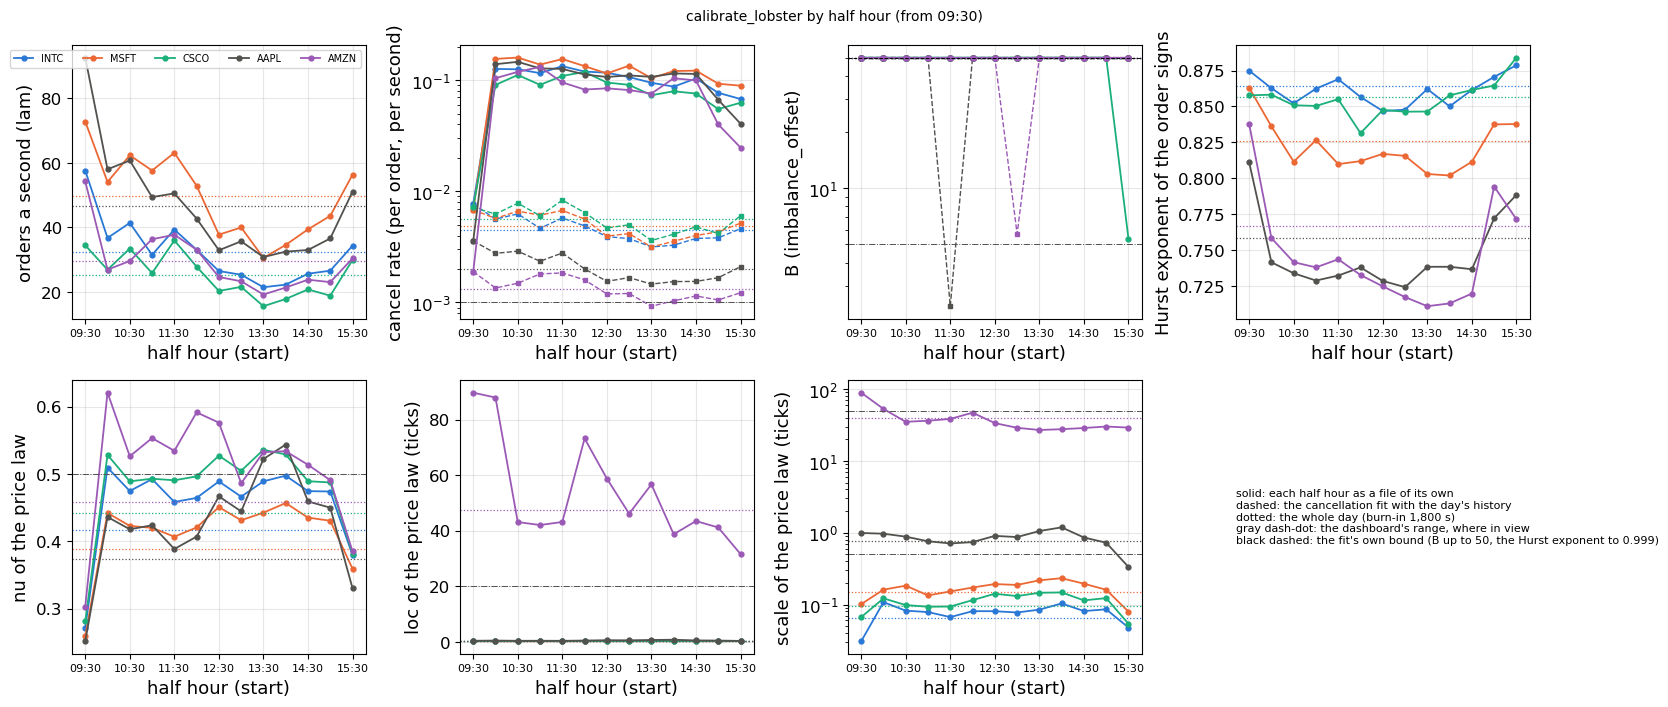

In [40]:
# 5.1 The calibration of each reported stock on the first day. Notebook 08's own figures first (no market data
# needed); then one run of cal_calibration on each stock (the slow part of this section: the cost is printed), and
# Table 1, the parameters: the whole day by calibrate_lobster, each half hour as a file of its own and with the day's
# history, what falls on the fit's bound and outside the dashboard's ranges (nothing is clipped), and Table 2, the
# cancel rate by window. Reads: cal_calibrated.


def cal_saved_text(path=cal_notebook_08):
    # what the code cells of a saved notebook printed, as saved ('' if the notebook is not there or has no output)
    try:
        notebook = json.loads(Path(path).read_text())
    except FileNotFoundError:
        return ''
    return '\n'.join(
        ''.join(output.get('text', ''))
        for cell in notebook['cells']
        if cell['cell_type'] == 'code'
        for output in cell.get('outputs', [])
        if output.get('output_type') == 'stream'
    )


def cal_heading(title, results, day=DAY):
    # a table's title with the day, the windows, the tape and the replace convention beside it (the fits read the day,
    # the facts the session), and the exploration label where it applies
    window = f'fits {clock(CAL0)} to {clock(cal_end)}, facts {SESSION_START} to {SESSION_END}'
    heading(title, results, day, how=cal_tape, window=window)


def cal_strip_lines(results, title, source, name, digits, width=7):
    # a line a stock: the whole day's value, then the half hours' (source: the half hours as files, or with history)
    lines = [f'{title:<30}{"day":>8}  ' + ' '.join(f'{label:>{width}}' for label in cal_labels)]
    for stock, detail in results.items():
        values = [fit[name] for fit in detail[source]]
        lines.append(
            f'{stock:<30}{fmt(detail["day fit"][name], digits):>8}  ' + strip_text(values, digits, width=width)
        )
    return '\n'.join(lines)


def cal_day_table(results):
    # a row a stock: calibrate_lobster's parameters for the day, and the counts they stand on
    columns = {name: (lambda detail, name=name: detail['day fit'][name]) for name in cal_params}
    columns |= {
        'orders': lambda detail: detail['day fit']['n_orders'],
        'executed in full': lambda detail: detail['day fit']['n_executed_in_full'],
        'cancels counted': lambda detail: detail['day fit']['n_cancels'],
        'cancels skipped (placed before the day)': lambda detail: detail['day fit']['n_cancels_skipped'],
    }
    return stock_table(results, columns)


def cal_cancel_table(results):
    # the cancel rate by window: the day, each half hour as a file, each half hour with the day's history
    rows = {}
    for stock, detail in results.items():
        day = detail['day fit']['cancel_rate']
        files = np.array([fit['cancel_rate'] for fit in detail['half hours as files']])
        history = np.array([fit['cancel_rate'] for fit in detail['half hours with history']])
        rows[stock] = {
            'the day': day,
            'files, median': np.median(files),
            'files, min': files.min(),
            'files, max': files.max(),
            'history, median': np.median(history),
            'history, min': history.min(),
            'history, max': history.max(),
            'files median / day': np.median(files) / day,
            'history median / day': np.median(history) / day,
        }
    return pd.DataFrame(rows).T


def cal_range_rows(results):
    # the day's and the half hours' values that sit on a bound of the fit, outside the dashboard's range or on its edge
    rows = []
    for stock, detail in results.items():
        for name in cal_params:
            low, high = cal_spec[name]
            day = detail['day fit'][name]
            files = [fit[name] for fit in detail['half hours as files']]
            history = [fit[name] for fit in detail['half hours with history'] if name in fit]
            outside = [sum(cal_outside(name, v) for v in values) for values in (files, history)]
            bound = [sum(cal_at_fit_bound(name, v) for v in values) for values in (files, history)]
            where = []
            if cal_outside(name, day):
                where.append('outside the range')
            elif day in (low, high):
                where.append('on the range\'s edge')
            if cal_at_fit_bound(name, day):
                where.append('at the fit\'s bound')
            if where or any(outside) or any(bound):
                rows.append(
                    {
                        'stock': stock,
                        'parameter': name,
                        'the day': day,
                        'dashboard range': f'{low:g} to {high:g}',
                        'where': ', '.join(where) or '-',
                        'files outside': f'{outside[0]} of {len(files)}',
                        'history outside': f'{outside[1]} of {len(history)}' if history else '-',
                        'files at the fit\'s bound': f'{bound[0]} of {len(files)}',
                        'history at the fit\'s bound': f'{bound[1]} of {len(history)}' if history else '-',
                    }
                )
    return pd.DataFrame(rows)


def cal_plot_parameters(results):
    # the half-hour strips of the seven fitted parameters, a line a stock (notebook 13's colors): the half hour as a
    # file solid; the cancellation parameters with the day's history dashed; the day dotted; the dashboard's range
    # (gray, dash-dot) where it is in view
    colors = [BLUE, ORANGE, AQUA, GRAY, '#9b59b6', '#c0392b', '#8c6d1f']
    panels = [
        ('lam', 'orders a second (lam)', False),
        ('cancel_rate', 'cancel rate (per order, per second)', True),
        ('imbalance_offset', 'B (imbalance_offset)', True),
        ('hurst', 'Hurst exponent of the order signs', False),
        ('nu', 'nu of the price law', False),
        ('loc', 'loc of the price law (ticks)', False),
        ('scale', 'scale of the price law (ticks)', True),
    ]
    fig, axes = plt.subplots(2, 4, figsize=(17, 7.2))
    x = np.arange(len(cal_blocks))
    for ax, (name, ylabel, log) in zip(axes.ravel(), panels, strict=False):
        for color, (stock, detail) in zip(colors, results.items(), strict=False):
            ax.plot(
                x,
                [fit[name] for fit in detail['half hours as files']],
                marker='o',
                markersize=3.5,
                linewidth=1.3,
                color=color,
                label=stock,
            )
            if name in ('cancel_rate', 'imbalance_offset'):
                ax.plot(
                    x,
                    [fit[name] for fit in detail['half hours with history']],
                    marker='s',
                    markersize=3,
                    linewidth=1.0,
                    linestyle='--',
                    color=color,
                )
            ax.axhline(detail['day fit'][name], color=color, linewidth=0.9, linestyle=':')
        if log:
            ax.set_yscale('log')
        low, high = ax.get_ylim()
        for edge in cal_spec[name]:
            if low <= edge <= high:
                ax.axhline(edge, color=GRAY, linewidth=0.7, linestyle='-.')
        if name in cal_fit_bounds:  # a bound of the fit itself, where a fit can sit on it
            for edge in cal_fit_bounds[name]:
                if low <= edge <= high:
                    ax.axhline(edge, color='black', linewidth=0.7, linestyle='--')
        ax.set_xticks(x[::2], cal_labels[::2], fontsize=8)
        ax.set_xlabel('half hour (start)')
        ax.set_ylabel(ylabel)
    axes[0, 0].legend(fontsize=7, ncols=min(len(results), 5))
    axes[1, 3].axis('off')
    axes[1, 3].text(
        0.0,
        0.5,
        'solid: each half hour as a file of its own\ndashed: the cancellation fit with the day\'s history\n'
        'dotted: the whole day (burn-in 1,800 s)\ngray dash-dot: the dashboard\'s range, where in view\n'
        f'black dashed: the fit\'s own bound (B up to {CALIBRATION_B_MAX}, the Hurst exponent to '
        f'{cal_fit_bounds["hurst"][1]})',
        fontsize=8,
        va='center',
    )
    fig.suptitle(
        'calibrate_lobster by half hour (from 09:30)' + (f'\n{EXPLORATION}' if set(results) & set(EXPLORED) else ''),
        fontsize=10,
    )
    fig.tight_layout()
    return fig


# --- notebook 08, quoted from its saved output (no market data needed)
# -------------------------------------------------
cal_quotes = (
    'From the files, every mean estimate\'s 95% interval covers the true value.',
    'Noisiest relative to its value: imbalance_offset (one run\'s estimate scatters by about 17%).',
    'imbalance_offset: true 0.2; without a burn-in 0.205 (0.1896 to 0.2205), with one 0.2049',
)
cal_printed = cal_saved_text()
if cal_printed:
    for cal_line in cal_quotes:
        assert cal_line in cal_printed, f'notebook 08 no longer prints: {cal_line}'
    print(
        'Notebook 08, as it printed (seeds 1 to 8; the file that starts on a full book, seeds 101 to 108), on the '
        'model\'s own output:'
    )
    for cal_line in cal_quotes:
        print(f'  {cal_line}')
else:
    print(f'{cal_notebook_08} has no saved output here: nothing is quoted from it.')

if need(DAY):
    cal_results = cal_calibrated(DAY)
    ran('Section 5, the first day: ')
    for cal_stock, cal_detail in cal_results.items():
        assert cal_detail['blocks'] == list(cal_blocks), f'{cal_stock}: the half hours are not the calibration\'s'
        for cal_source in ('half hours as files', 'half hours with history'):
            assert len(cal_detail[cal_source]) == len(cal_blocks), f'{cal_stock}: {cal_source} is not a strip'
        assert all(math.isfinite(cal_detail['day fit'][name]) for name in cal_params), (
            f'{cal_stock}: a fit is not finite'
        )
        assert 0 <= cal_detail['day fit']['imbalance_offset'] <= CALIBRATION_B_MAX + cal_at_bound, (
            f'{cal_stock}: B is outside the bounds of the fit'
        )
    if not SMOKE:
        assert list(cal_blocks) == list(range(N_BLOCKS)), 'the calibration is not the thirteen half hours from 09:30'

    cal_cost = pd.DataFrame({stock: detail['seconds'] for stock, detail in cal_results.items()}).T
    cal_cost['a simulated day'] = [
        np.mean([run['seconds'] for run in detail['sim']]) for detail in cal_results.values()
    ]
    cal_cost['peak memory (MB)'] = [detail['peak memory (MB)'] for detail in cal_results.values()]
    print(f'\nSeconds by part, one worker a stock (a simulated day: one of the {len(SIM_SEEDS)} seeds):')
    print(shown(cal_cost, {column: '.1f' for column in cal_cost.columns} | {'peak memory (MB)': ',.0f'}))

    cal_heading(
        f'Table 1. calibrate_lobster for the day ({clock(CAL0)} to {clock(cal_end)}, '
        f'burn-in {CALIBRATION_BURN:,.0f} s)',
        cal_results,
    )
    print(
        shown(
            cal_day_table(cal_results),
            {
                'lam': '.2f',
                'cancel_rate': '.5f',
                'imbalance_offset': '.2f',
                'hurst': '.3f',
                'nu': '.3f',
                'loc': '.2f',
                'scale': '.3f',
                'lot_size': 'd',
            },
        )
    )
    print(
        f'The model is run at a lot of {CALIBRATION_LOT} shares and a tick a cent; the fit\'s own modal order size is '
        'in the lot_size column.'
    )

    print(
        '\nEach half hour as a file of its own (burn-in 0, the half hour\'s own rows), from 09:30; the day beside it:'
    )
    for cal_title, cal_source, cal_name, cal_digits in (
        ('lam (orders a second)', 'half hours as files', 'lam', 2),
        ('cancel_rate, a file each', 'half hours as files', 'cancel_rate', 4),
        ('imbalance_offset, a file each', 'half hours as files', 'imbalance_offset', 2),
        ('hurst', 'half hours as files', 'hurst', 3),
        ('nu', 'half hours as files', 'nu', 2),
        ('loc (ticks)', 'half hours as files', 'loc', 2),
        ('scale (ticks)', 'half hours as files', 'scale', 2),
    ):
        print('\n' + cal_strip_lines(cal_results, cal_title, cal_source, cal_name, cal_digits))
    print(
        '\nThe cancellation fit of each half hour with the day\'s history replayed from the open, counted from its '
        'start:'
    )
    for cal_title, cal_name, cal_digits in (
        ('cancel_rate, with history', 'cancel_rate', 4),
        ('imbalance_offset, with history', 'imbalance_offset', 2),
    ):
        print('\n' + cal_strip_lines(cal_results, cal_title, 'half hours with history', cal_name, cal_digits))

    cal_heading('Table 2. The cancel rate by window (per order, per second)', cal_results)
    print(
        shown(
            cal_cancel_table(cal_results),
            {column: '.4f' for column in cal_cancel_table(cal_results).columns if '/' not in column}
            | {'files median / day': '.1f', 'history median / day': '.1f'},
        )
    )

    cal_heading(
        f'Table 3. What sits on a bound of the fit (B up to {CALIBRATION_B_MAX}, the Hurst exponent 0.5 to '
        f'{cal_fit_bounds["hurst"][1]}) or outside the dashboard\'s range or on its edge; nothing is clipped',
        cal_results,
    )
    cal_ranges = cal_range_rows(cal_results)
    if len(cal_ranges):
        print(shown(cal_ranges, {'the day': '.4g'}, index=False))
    else:
        print(
            'Every value of the day and of every half hour is inside the dashboard\'s ranges and off the fit\'s bounds.'
        )
    print('No fitted set is offered as a preset.')

    cal_fig = cal_plot_parameters(cal_results)
    plt.show()

TODO(prose): Table 1. For each stock, the day's parameters as printed (`lam`, `cancel_rate`, `imbalance_offset`, `hurst`, `nu`, `loc`, `scale`, `lot_size`) with the counts they stand on (orders, executed in full, cancels counted, cancels of orders placed before the day). Say what each describes on that day on average (the order rate, the signs' memory, the shape of the offset law) and nothing about the stock; say which of them the dashboard could not take (Table 3).

TODO(prose): The half-hour strips. For each stock the range of each parameter across the thirteen half hours as a file (the strip lines), and which half hour is the outlier (the first, which holds the opening burst). Say that the strips are the thirteen values of one day, that the half hours are not exchangeable, and that no spread across stocks is a standard error.

TODO(prose): Table 2, the cancel rate by window. For each stock, the day's `cancel_rate`, the median half hour as a file with its range, the median half hour with the day's history with its range, and the two ratios to the day's (the last two columns; the first is `cancel_ratio`, the estimator's window effect, which is in no verdict). Say, in these words, that a cancel rate is not a property of a stock: the same day gives these values depending on the window and on whether the history is replayed. Do not compare stocks.

TODO(prose): Table 3, what sits on a bound of the fit or outside the dashboard's ranges. For each stock: the day's `imbalance_offset` against its bound of 50 and the dashboard's cap of 5, and in how many half hours as files and with history it sits on the bound; any other parameter outside its range (the day's and the half hours' counts); `lot_size` on the dashboard's edge where it is. Say that nothing was clipped, that a fit the dashboard refuses cannot be entered as it is, and that no fitted set is offered as a preset.

INTC: the likelihood profile of B is -239.8984 at the fitted B (0 is the best) and -239.8984 at the grid's best within the bound: the fit is at least as good as every grid point.
MSFT: the likelihood profile of B is -1444.2013 at the fitted B (0 is the best) and -1444.2012 at the grid's best within the bound: the fit is at least as good as every grid point.
CSCO: the likelihood profile of B is -284.0674 at the fitted B (0 is the best) and -284.0674 at the grid's best within the bound: the fit is at least as good as every grid point.
AAPL: the likelihood profile of B is -30.0510 at the fitted B (0 is the best) and -30.0510 at the grid's best within the bound: the fit is at least as good as every grid point.
AMZN: the likelihood profile of B is -31.2235 at the fitted B (0 is the best) and -31.2235 at the grid's best within the bound: the fit is at least as good as every grid point.

Table 4. B's profile log-likelihood on the whole day (b_max 50), less its best (the grid's or the fit's): 

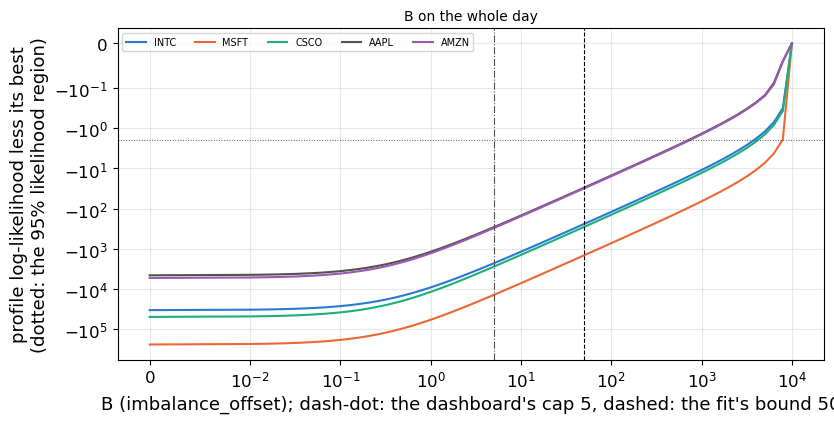


Table 5. Replaces dropped from both counts, a sensitivity of the fit: 2019-03-27, fits 09:30:00 to 16:00:00, facts
09:40:00 to 15:50:00, fits: displayed rows only, a replace as the frames have it (a deletion and a new order); facts:
tape signed, a replace as two.
What the frames hold that the sensitivities touch (rows in the calibration's day):
           adds replace pairs replace pairs over adds partial cancels paired reductions hidden executions (not read)
INTC    748,635        89,623                   12.0%           3,541                27                        2,141
MSFT  1,134,244       155,439                   13.7%           2,931               211                        4,719
CSCO    581,786        78,330                   13.5%           3,224                18                        3,111
AAPL  1,056,435       136,647                   12.9%           2,817                 7                        6,833
AMZN    673,701        97,623                   14.5%              

In [41]:
# 5.2 Why the fits come out as they do. Table 4: B's profile likelihood (b_max 50) and the two shares that say whether
# a cancellation depends on the own side's share of the resting orders; Table 5: the dropped-replace sensitivity of
# the day's fit (and of each half hour as a file), with the rows the frames hold that the calibration does not use;
# Table 6: how long orders last, which is why the cancel rate depends on the window. Reads: cal_results (kept by the
# cell before).


def cal_profile_table(results):
    # a row a stock: the profile log-likelihood of B less its best on the grid, at B of each cal_b_points and at the
    # grid's end; the 95% likelihood region on the grid; the two shares
    rows = {}
    for stock, detail in results.items():
        profile = detail['profile']
        grid, value = np.array(profile['B']), np.array(profile['log-likelihood'])
        row = {f'B = {b:g}': float(value[np.argmin(abs(grid - b))]) for b in (*cal_b_points, grid[-1])}
        row['95% region from B'], row['to B'] = profile['region']
        row['share at a cancel'], row['share of exposure'] = profile['share at a cancel'], profile['share of exposure']
        row['cancels'] = profile['n cancels']
        rows[stock] = row
    return pd.DataFrame(rows).T


def cal_plot_profile(results):
    # the profile log-likelihood of B on the grid, a line a stock, both axes symmetric-logarithmic (B = 0 and the
    # likelihood's best are on them); the dashboard's cap and the fit's bound marked, and where the 95% region begins
    colors = [BLUE, ORANGE, AQUA, GRAY, '#9b59b6', '#c0392b', '#8c6d1f']
    fig, ax = plt.subplots(figsize=(8.5, 4.4))
    for color, (stock, detail) in zip(colors, results.items(), strict=False):
        ax.plot(detail['profile']['B'], detail['profile']['log-likelihood'], color=color, linewidth=1.5, label=stock)
    ax.set_xscale('symlog', linthresh=float(cal_b_grid[1]))
    ax.set_yscale('symlog', linthresh=0.1)
    ax.axhline(-cal_region, color=GRAY, linewidth=0.7, linestyle=':')
    ax.axvline(cal_spec['imbalance_offset'][1], color=GRAY, linewidth=0.8, linestyle='-.')
    ax.axvline(CALIBRATION_B_MAX, color='black', linewidth=0.8, linestyle='--')
    ax.set_xlabel(
        f'B (imbalance_offset); dash-dot: the dashboard\'s cap {cal_spec["imbalance_offset"][1]:g}, '
        f'dashed: the fit\'s bound {CALIBRATION_B_MAX}'
    )
    ax.set_ylabel('profile log-likelihood less its best\n(dotted: the 95% likelihood region)')
    ax.set_title('B on the whole day' + (f'\n{EXPLORATION}' if set(results) & set(EXPLORED) else ''), fontsize=10)
    ax.legend(fontsize=7, ncols=min(len(results), 5))
    fig.tight_layout()
    return fig


def cal_rows_table(results):
    # the rows of the frames the sensitivities touch or the calibration does not read
    rows = {}
    for stock, detail in results.items():
        counts = detail['rows']
        rows[stock] = {
            'adds': counts['adds'],
            'replace pairs': counts['replace rows'] // 2,
            'replace pairs over adds': counts['replace rows'] / 2 / counts['adds'],
            'partial cancels': counts['partial cancels'],
            'paired reductions': counts['paired reductions'],
            'hidden executions (not read)': counts['hidden executions (not read)'],
        }
    return pd.DataFrame(rows).T


def cal_dropped_table(results, names=('lam', 'cancel_rate', 'hurst', 'nu', 'loc', 'scale')):
    # a row a stock and parameter: the day's value, with the replaces dropped, the shift in percent of the day's value,
    # and the shift as a share of the range of the half hours as files (and the median half hour's shift)
    rows = {}
    for stock, detail in results.items():
        base, dropped = detail['day fit'], detail['replaces dropped']['day']
        files, dropped_files = detail['half hours as files'], detail['replaces dropped']['half hours']
        for name in names:
            before = np.array([fit[name] for fit in files])
            after = np.array([fit[name] for fit in dropped_files])
            span = before.max() - before.min()
            rows[stock, name] = {
                'the day': base[name],
                'replaces dropped': dropped[name],
                'shift, % of the day': 100 * (dropped[name] / base[name] - 1),
                'range of the half hours': span,
                'day shift over range': abs(dropped[name] - base[name]) / span if span > 0 else math.nan,
                'median half-hour shift over range': abs(np.median(after - before)) / span if span > 0 else math.nan,
            }
    return pd.DataFrame(rows).T


def cal_ages_table(results):
    # how long the day's orders last, by stock
    rows = {}
    for stock, detail in results.items():
        ages = detail['ages']
        rows[stock] = {'orders placed': ages['orders placed']}
        for mark in cal_age_marks:
            rows[stock][f'deleted within {mark:g} s'] = ages['deleted within'][mark]
        rows[stock] |= {
            'median age at deletion (s)': ages['median age at deletion'],
            'still resting at the end': ages['resting at the end'],
            'order-seconds beyond a half hour': ages['order-seconds beyond a half hour'],
        }
    return pd.DataFrame(rows).T


if need(DAY):
    cal_results = cal_calibrated(DAY)
    for cal_stock, cal_detail in cal_results.items():
        # The fit's own log-likelihood (computed exactly, not read off the grid) against the grid's best within the
        # bound: a flag and not a stop, because it depends on the optimizer and a stock-day that tripped it should not
        # take the run's other cells with it. A stock-day where it is False is not judged on the calibration
        # (judge_calibration reads it through cal_summary).
        cal_profile_one = cal_detail['profile']
        print(
            f'{cal_stock}: the likelihood profile of B is {cal_profile_one["log-likelihood at the fit"]:.4f} at the '
            f'fitted B (0 is the best) and {cal_profile_one["best on the grid within the bound"]:.4f} at the grid\'s '
            'best within the bound: '
            + (
                'the fit is at least as good as every grid point.'
                if cal_profile_one['agrees']
                else 'DISAGREE: the calibration is not judged for this stock-day.'
            )
        )
        assert 0 < cal_profile_one['share at a cancel'] <= 1 and 0 < cal_profile_one['share of exposure'] <= 1, (
            f'{cal_stock}: a share of resting orders is outside (0, 1]'
        )
        assert cal_detail['rows']['replace rows'] % 2 == 0, f'{cal_stock}: the replace rows are not pairs'
        assert cal_detail['ages']['orders placed'] == cal_detail['rows']['adds'], (
            f'{cal_stock}: an add is not a placed order'
        )
        assert cal_detail['ages']['deletions of placed orders'] <= cal_detail['rows']['deletions'], (
            f'{cal_stock}: more placed orders were deleted than there are deletions'
        )

    cal_heading(
        f'Table 4. B\'s profile log-likelihood on the whole day (b_max {CALIBRATION_B_MAX}), less its best (the '
        'grid\'s or the fit\'s)',
        cal_results,
    )
    print(
        shown(
            cal_profile_table(cal_results),
            {column: '.1f' for column in cal_profile_table(cal_results).columns if column.startswith('B = ')}
            | {
                '95% region from B': '.2f',
                'to B': ',.0f',
                'share at a cancel': '.3f',
                'share of exposure': '.3f',
                'cancels': ',.0f',
            },
        )
    )
    print(
        'share at a cancel: the mean own-side share of the resting orders at each cancellation; share of exposure: '
        'the same share weighted by the exposure the cancel rate divides by. The model cancels an order faster when '
        'its own side holds more of the book (B small); the two shares are equal where it does not.'
    )
    cal_fig_profile = cal_plot_profile(cal_results)
    plt.show()

    cal_heading('Table 5. Replaces dropped from both counts, a sensitivity of the fit', cal_results)
    print('What the frames hold that the sensitivities touch (rows in the calibration\'s day):')
    print(
        shown(
            cal_rows_table(cal_results),
            {
                'adds': ',.0f',
                'replace pairs': ',.0f',
                'replace pairs over adds': '.1%',
                'partial cancels': ',.0f',
                'paired reductions': ',.0f',
                'hidden executions (not read)': ',.0f',
            },
        )
    )
    cal_table = cal_dropped_table(cal_results)
    print(
        '\nThe day and each half hour as a file, refitted with both rows of every replace made no-ops (neither is an '
        'arrival or a cancellation; the order goes on under its first reference):'
    )
    print(
        shown(
            cal_table,
            {
                'the day': '.5g',
                'replaces dropped': '.5g',
                'shift, % of the day': '+.1f',
                'range of the half hours': '.4g',
                'day shift over range': '.2f',
                'median half-hour shift over range': '.2f',
            },
        )
    )
    print(
        'Not rerun here: the group column for the aggressive orders, the paired reductions and the partial cancels '
        f'moved no parameter by more than 0.4 percent in the two exploration stocks ({EXPLORATION}); the counts above '
        'are what they act on.'
    )

    cal_heading('Table 6. How long the day\'s orders last (orders placed in the day)', cal_results)
    print(
        shown(
            cal_ages_table(cal_results),
            {f'deleted within {mark:g} s': '.1%' for mark in cal_age_marks}
            | {
                'orders placed': ',.0f',
                'median age at deletion (s)': '.2f',
                'still resting at the end': '.1%',
                'order-seconds beyond a half hour': '.1%',
            },
        )
    )
    print(
        'A half hour as a file knows only the orders placed in it and its exposure is theirs; the replay of the day '
        'divides by the exposure of every order placed so far, and the order-seconds beyond a half hour are the '
        'share of it that a half hour as a file never sees.'
    )

TODO(prose): Table 4, B's profile. For each stock the profile log-likelihood less its best at B = 5 (the dashboard's cap), at B = 50 (the fit's bound) and at 10,000, and where the 95% likelihood region begins (the `95% region from B` column). Say what the profile means: the data rise toward larger B, so B at 50 is the bound and not an estimate, and the region's lower end is what the data say B is at least. Beside it, the two shares: the mean own-side share at a cancel and the exposure-weighted share, and whether they are equal (no dependence of a cancellation on the own side's share, which is what a large B says). Quote notebook 08's recovery of B on the model's own output, so the estimator is not what puts it on the bound.

TODO(prose): Table 5, the dropped-replace sensitivity. For each stock the row counts (replace pairs and their share of adds; partial cancels, paired reductions and hidden executions, which the calibration does not use or the sensitivities do not touch), and the shift of `lam` and `nu` (and the others) when both rows of every replace are made no-ops: the shift in percent of the day's value, and as a share of the half-hour range (the day's shift over range, the median half hour's shift over range). Say which parameters a convention for replaces moves by more than the half hours move among themselves, and that the group column, the paired reductions and the partial cancels moved nothing in the exploration (labeled so).

TODO(prose): Table 6, how long orders last. For each stock the share of deletions within 0.001 s, 1 s and 10 s of the order's placing, the median age at deletion, the share of the day's placed orders still resting at the end, and the share of the day's order-seconds that is age beyond a half hour. Say that this is why the cancel rate of Table 2 depends on the window: the exposure it divides by is mostly orders older than a half hour, which a half hour as a file does not know, and a mixture of orders that leave within a millisecond and orders that rest for hours has no single hazard.


Table 7. INTC: the fitted model beside the day, session 09:40:00 to 15:50:00, a unit of one second, depth in lots of 100
shares on both sides; the fit's modal order size is 100 shares: 2019-03-27, fits 09:30:00 to 16:00:00, facts 09:40:00 to
15:50:00, fits: displayed rows only, a replace as the frames have it (a deletion and a new order); facts: tape signed, a
replace as two.
the day's fit (calibrate_lobster, burn-in 1,800 s): lam 32.45, cancel_rate 0.004445, imbalance_offset 50, hurst 0.864, nu 0.4173, loc 0.3472, scale 0.06415, lot_size 100; initial mid 5,368 ticks, warm-up 1,428 s, seeds 1 to 8
                               real session real half hours, min to max model, mean of seeds model, seeds min to max model against real real half hours inside the model's band
spread mean (ticks)                    1.00                1.00 to 1.00                 1.00            1.00 to 1.00              x1.00                                 2 of 13
share at one tick                     99.8

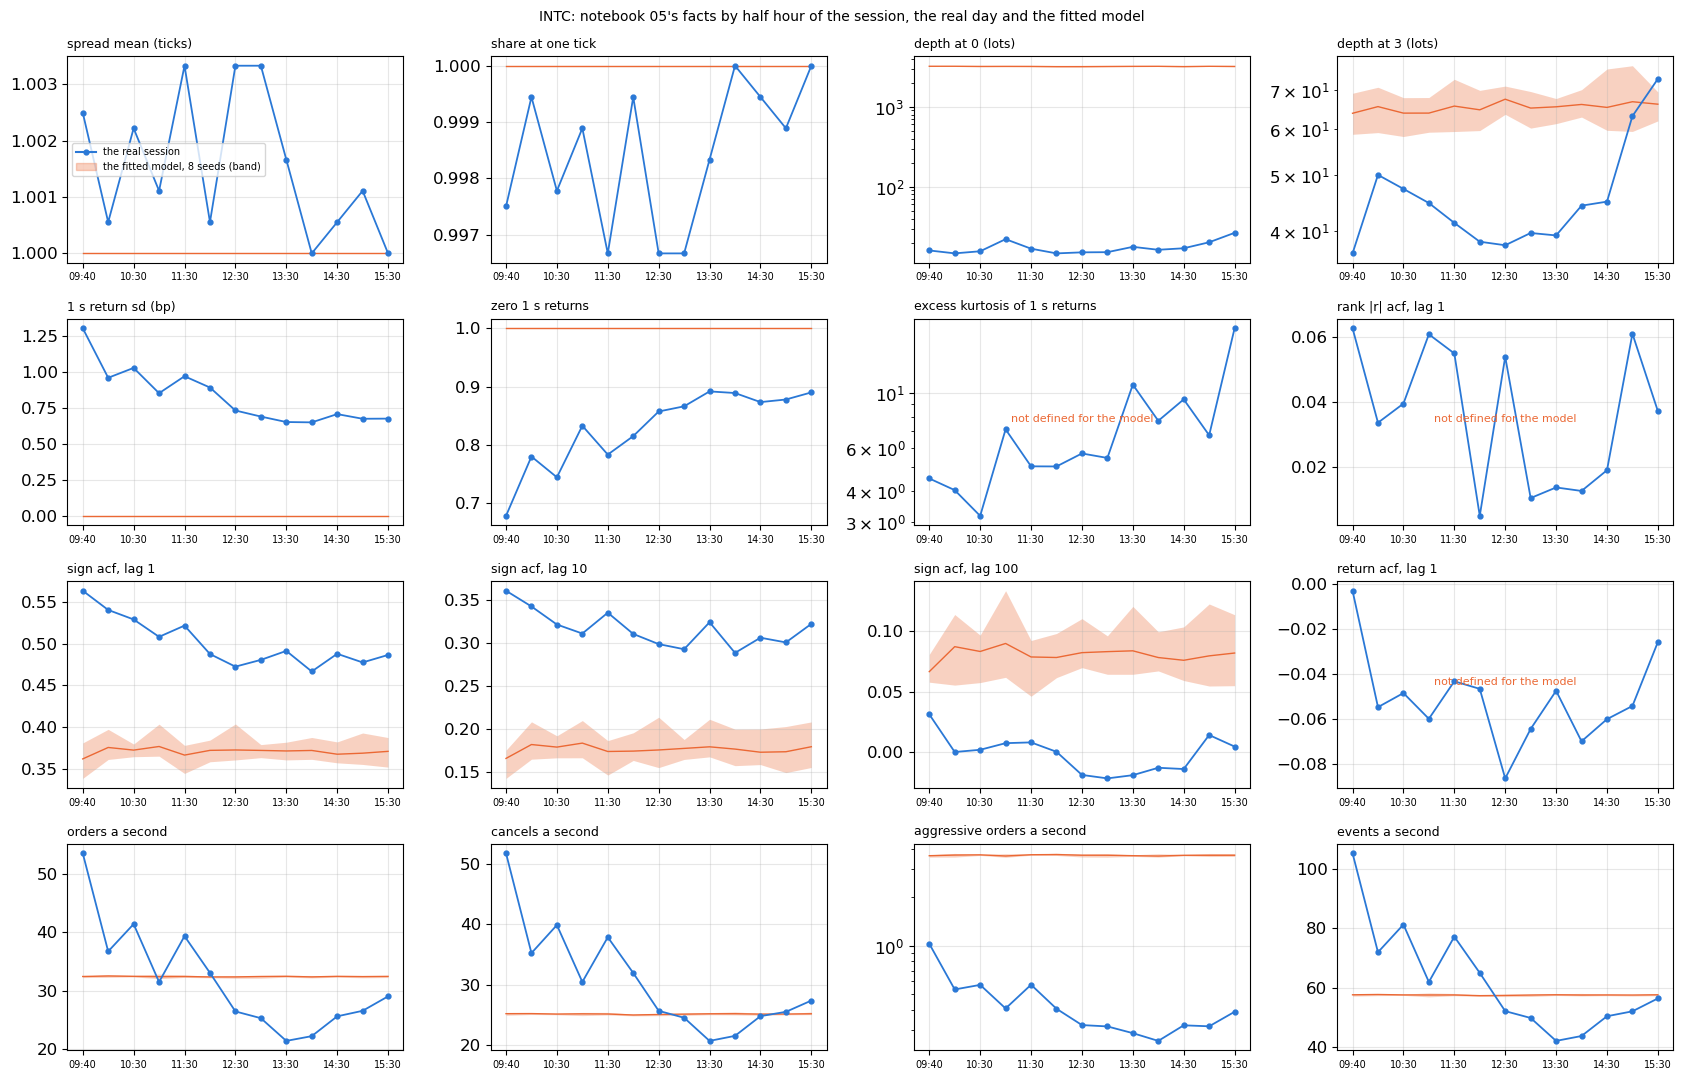

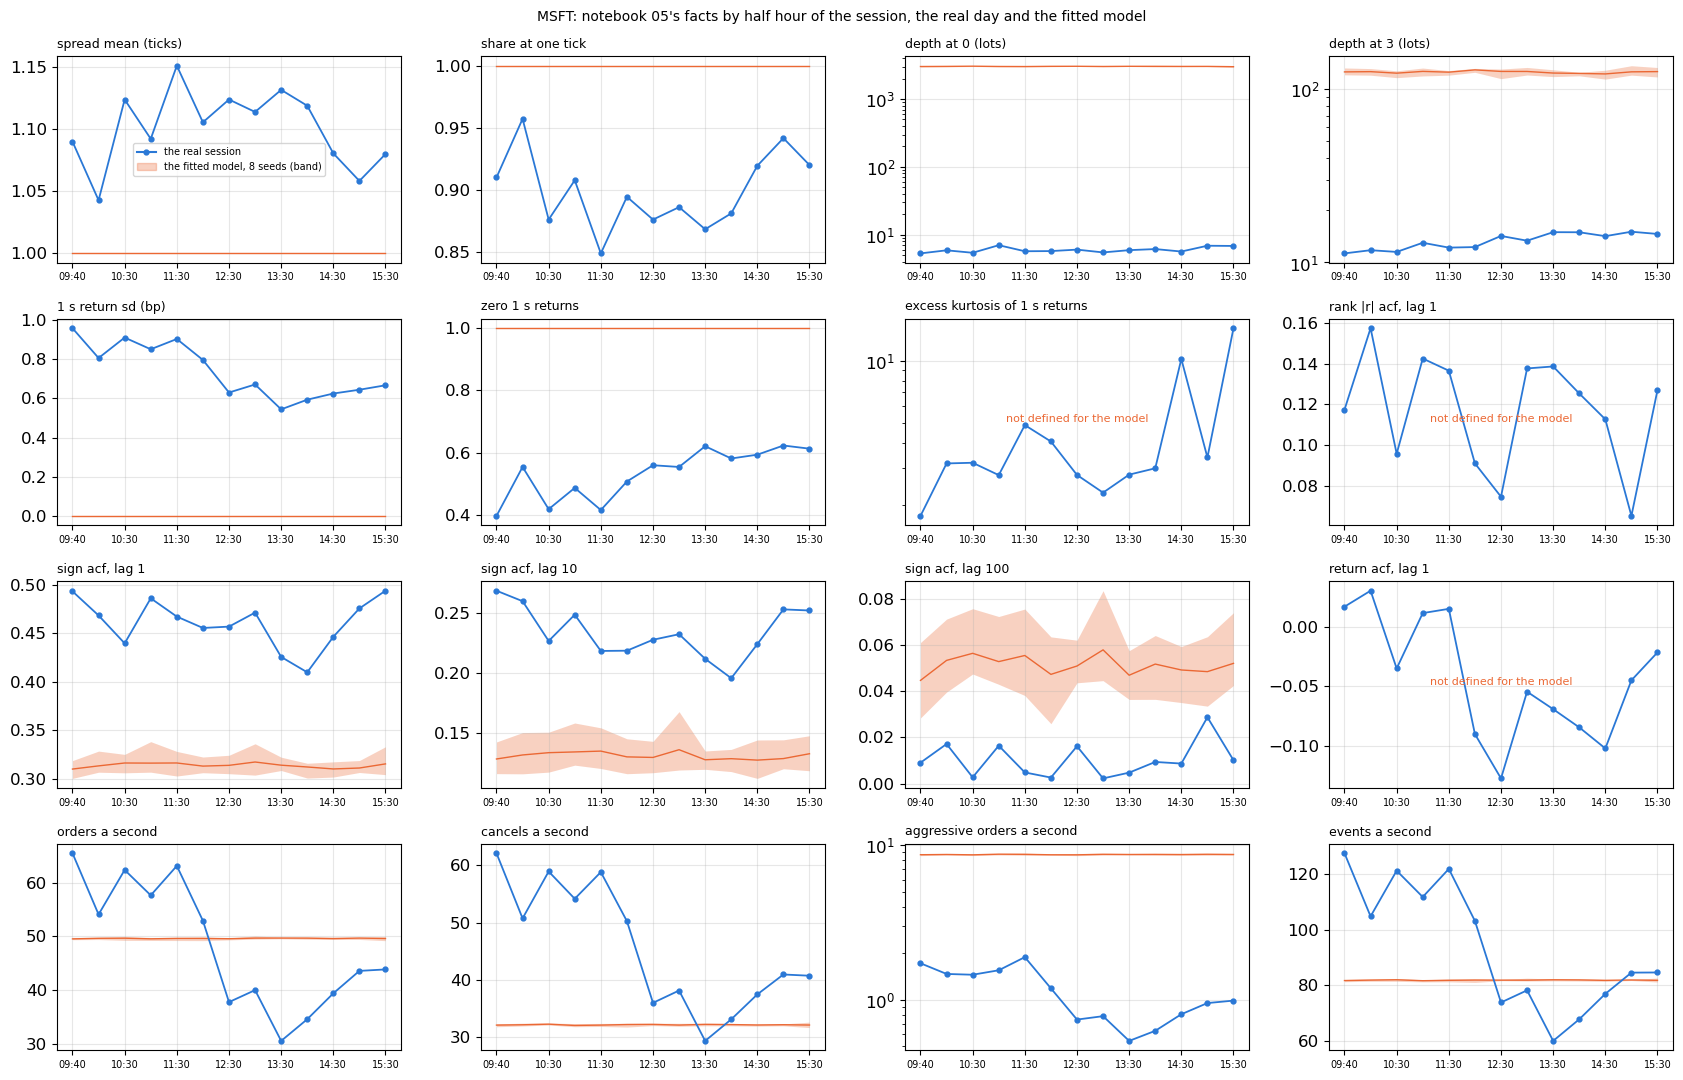

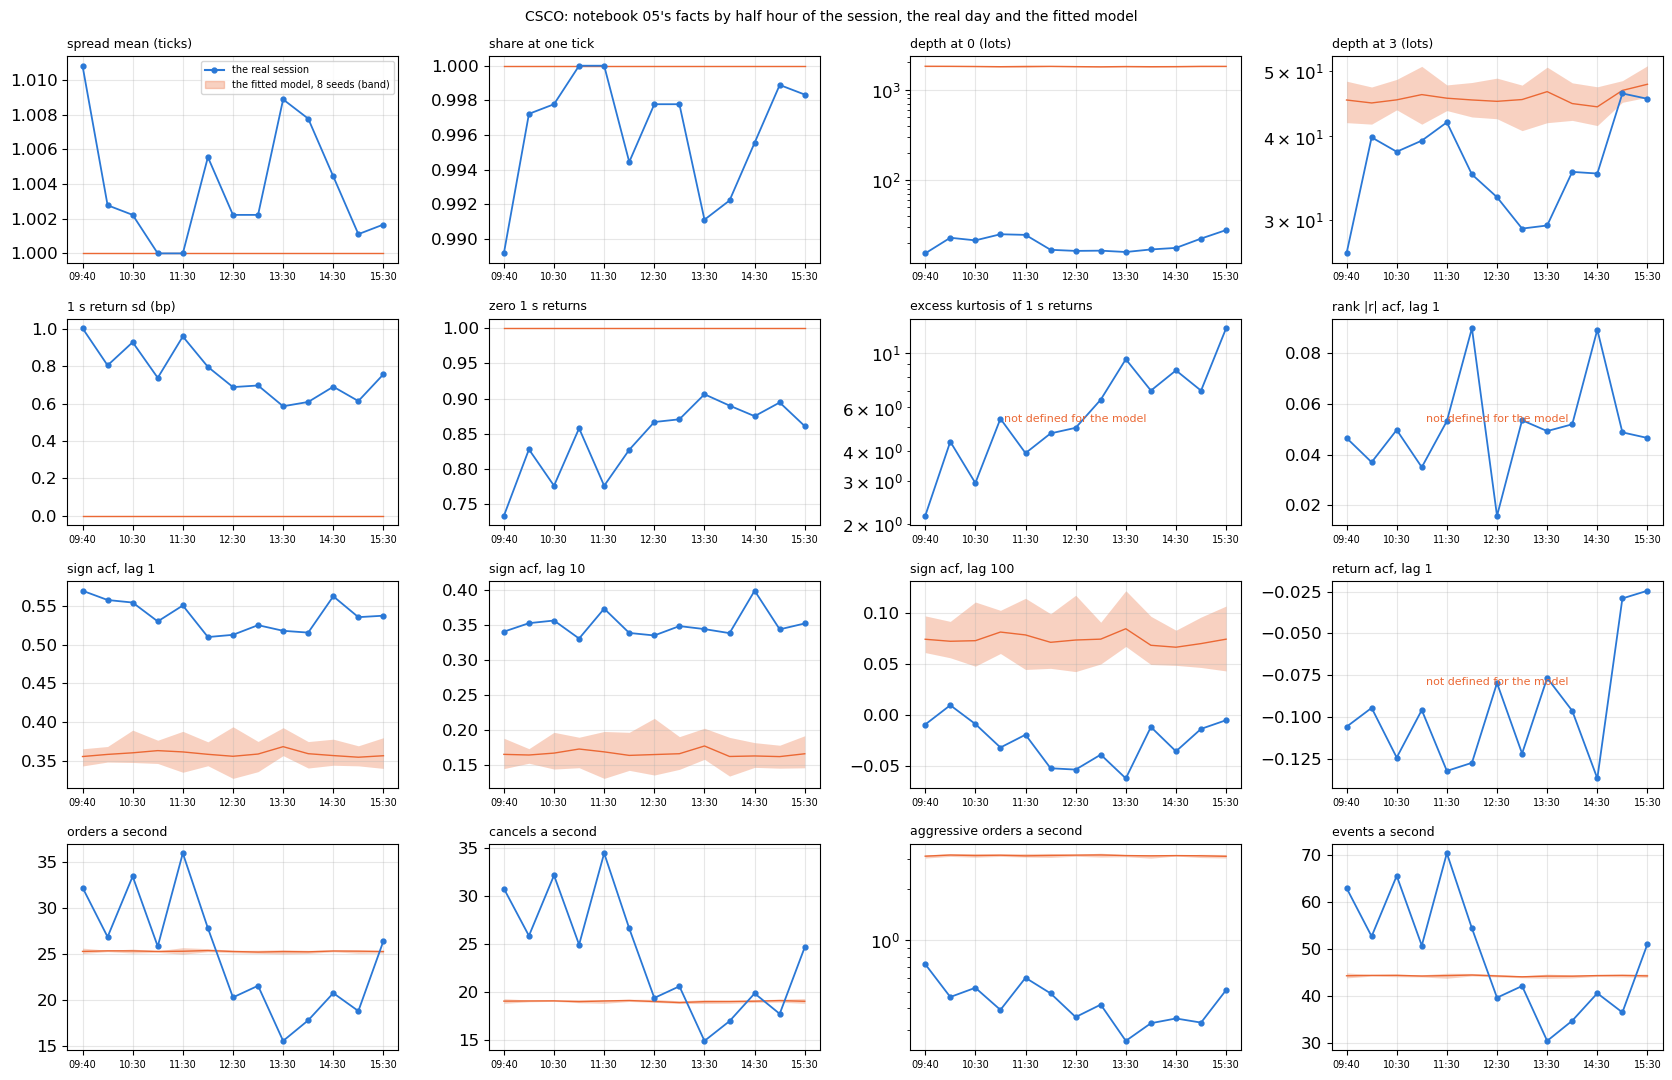

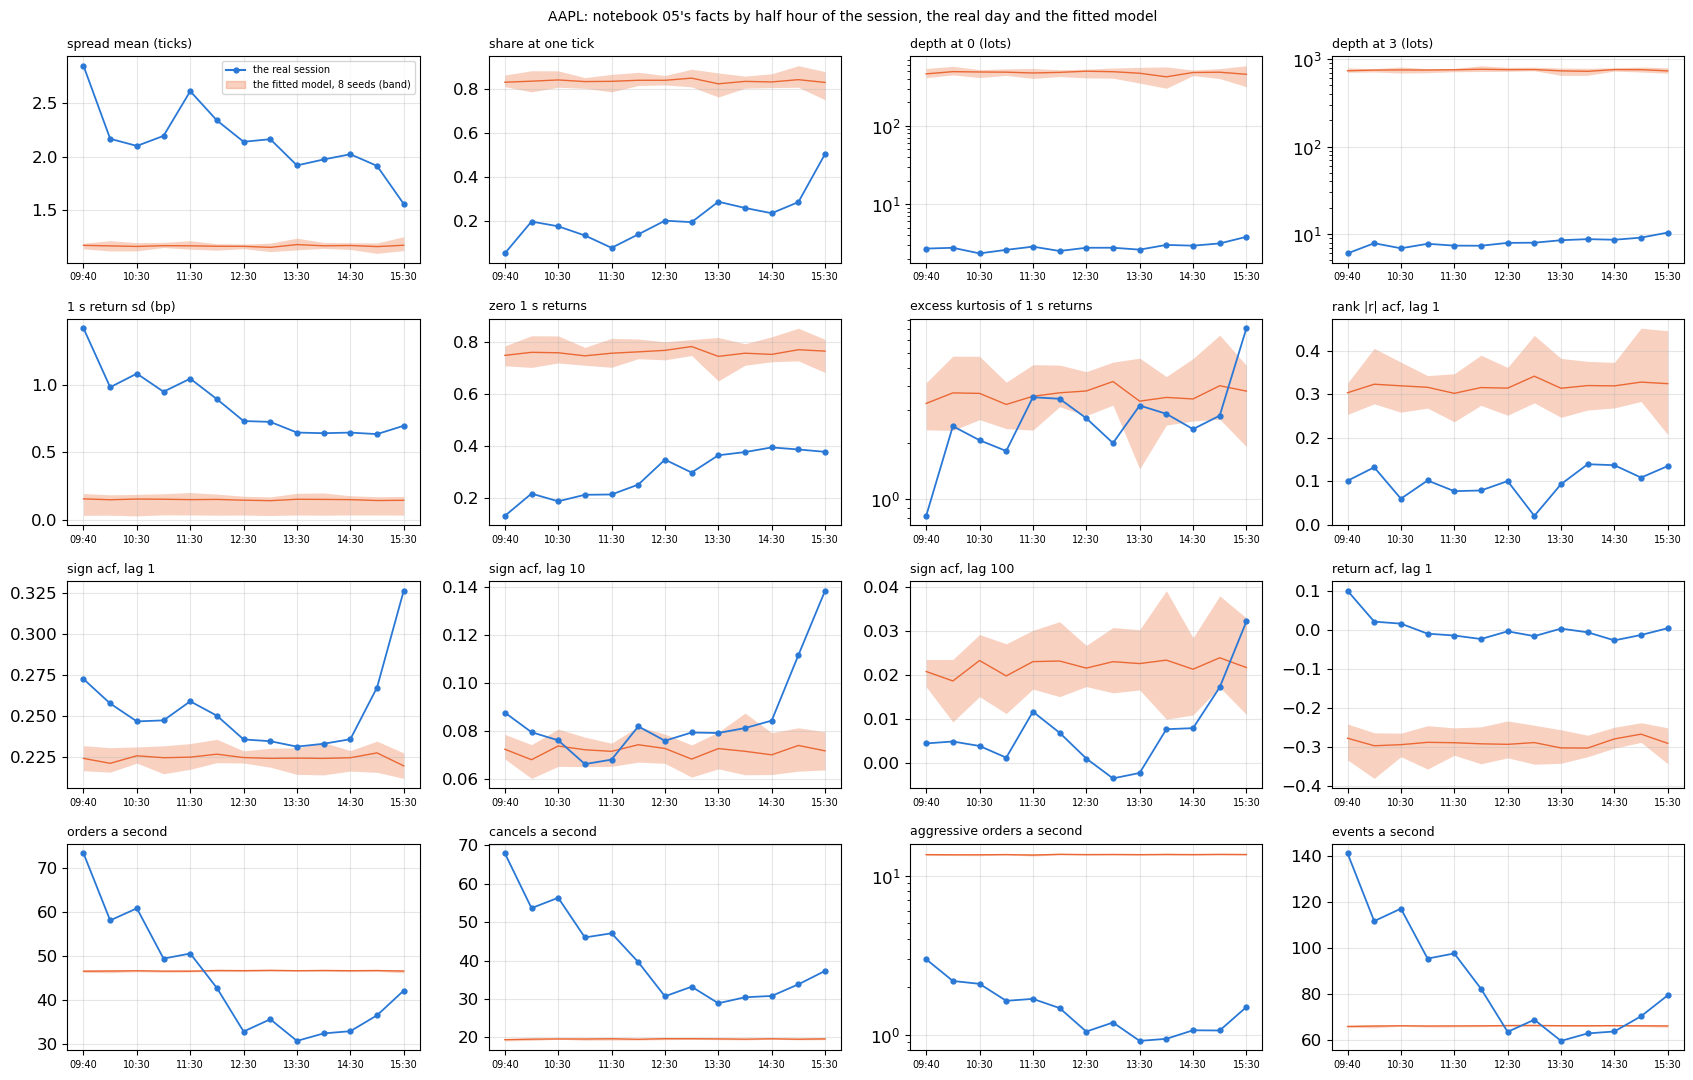

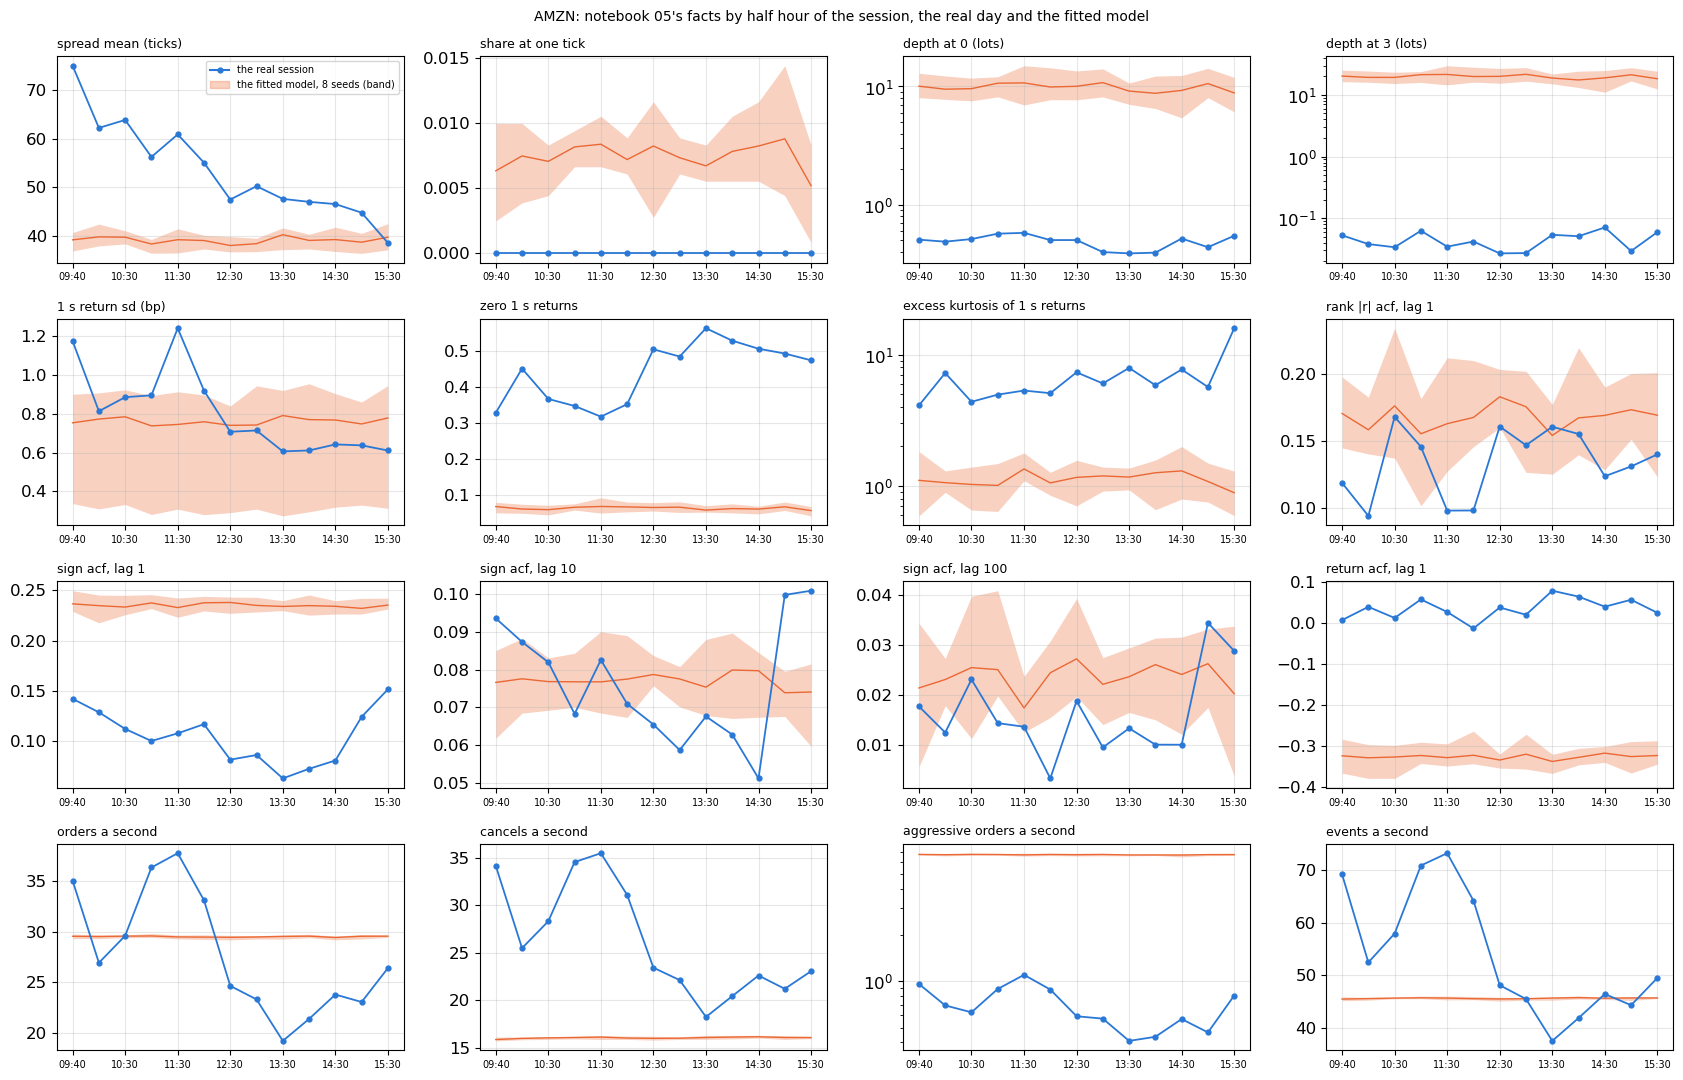

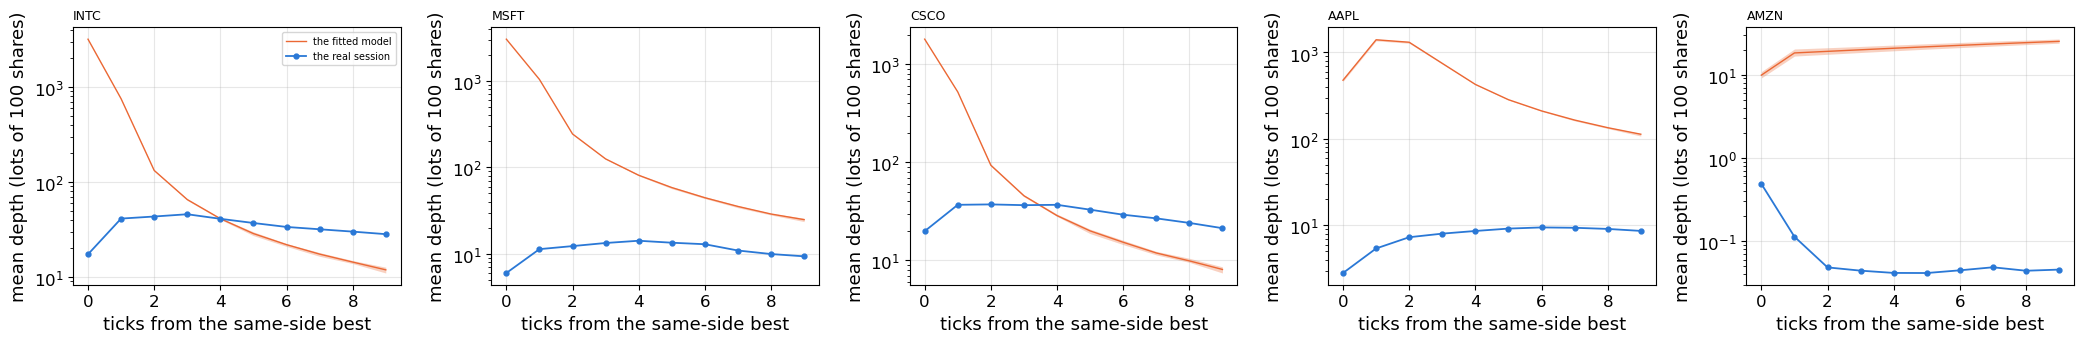


Table 9. The fitted price law against the offsets: where the model's aggressive orders come from: 2019-03-27, fits
09:30:00 to 16:00:00, facts 09:40:00 to 15:50:00, fits: displayed rows only, a replace as the frames have it (a deletion
and a new order); facts: tape signed, a replace as two.
         nu    loc   scale median spread (ticks) offset of -1 or less, data offset of -1 or less, fitted law trade on arrival, data trade on arrival, fitted model
INTC  0.417   0.35   0.064                   1.0                       2.3%                            11.2%                   1.4%                          11.2%
MSFT  0.389   0.27   0.148                   1.0                       5.4%                            17.6%                   2.3%                          17.6%
CSCO  0.442   0.34   0.094                   1.0                       2.8%                            12.4%                   1.8%                          12.4%
AAPL  0.374   0.45   0.759                   2.0       

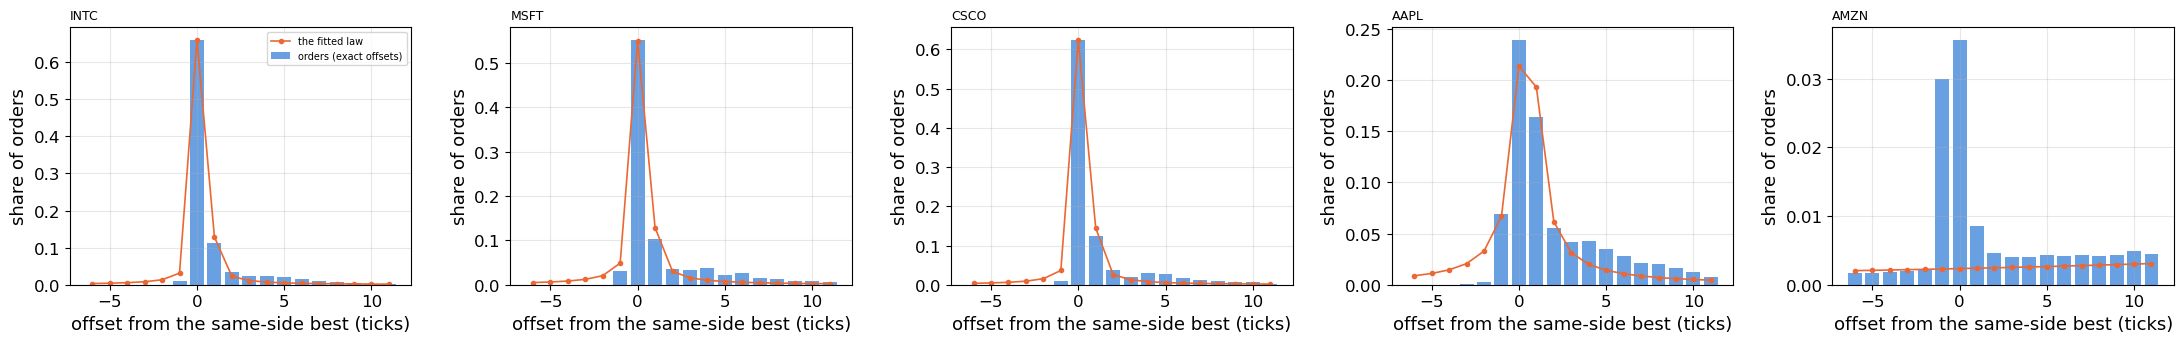


Table 10. The calibration prediction (the rule is in the predictions cell; judged through PREDICTIONS): 2019-03-27, fits
09:30:00 to 16:00:00, facts 09:40:00 to 15:50:00, fits: displayed rows only, a replace as the frames have it (a deletion
and a new order); facts: tape signed, a replace as two.
rule: the fitted B is at its bound, and the fitted model has 3 times the aggressive orders of the real day or more and 5 times its depth at the touch or more
     B at its bound aggressive orders, model over real depth at the touch, model over real cancel rate, median half hour as a file over the day (window effect, in no verdict) verdict
INTC           True                               8.56                              184.42                                                                                24.0  passed
MSFT           True                               7.78                              504.60                                                                                24.9  p

In [42]:
# 5.3 The fitted model beside the day, fact by fact and half hour by half hour. The day's fit (calibrate_lobster, burn-
# in
# 1,800 s) is run on each of the simulator's seeds (SIM_SEEDS) at a lot of CALIBRATION_LOT shares and a tick a cent, and
# read as the real session is (09:40 to 15:50, a unit of one second, depth in lots of CALIBRATION_LOT shares on both
# sides, the same half hours). Table 7 a stock: the facts, the real half hours' range against the model's; Table 8 the
# ratios side by side; Table 9 the price law against the offsets (where the aggressive orders come from); Table 10 the
# calibration prediction and Table 11 the calibration's mechanism (two of the ten tests, judged through PREDICTIONS).
# Reads: cal_results (kept by the first calibration cell).

cal_fact_rows = (  # (fact, format): notebook 05's facts, and the rates the calibration counts
    ('spread mean (ticks)', ',.2f'),
    ('share at one tick', '.1%'),
    ('share at 5 ticks or more', '.1%'),
    ('depth at 0 (lots)', ',.2f'),
    ('depth at 1 (lots)', ',.2f'),
    ('depth at 3 (lots)', ',.2f'),
    ('depth at 9 (lots)', ',.2f'),
    ('1 s return sd (bp)', '.2f'),
    ('zero 1 s returns', '.1%'),
    ('excess kurtosis of 1 s returns', '.2f'),
    ('rank |r| acf, lag 1', '.3f'),
    ('return acf, lag 1', '.3f'),
    ('sign acf, lag 1', '.3f'),
    ('sign acf, lag 10', '.3f'),
    ('sign acf, lag 100', '.3f'),
    ('orders a second', '.2f'),
    ('cancels a second', '.2f'),
    ('aggressive orders a second', '.3f'),
    ('events a second', '.2f'),
    ('mid changes a second', '.3f'),
)
# correlations: the model against the real value is a difference (a ratio of a 0 or a sign flips)
cal_difference_facts = (
    'rank |r| acf, lag 1',
    'return acf, lag 1',
    'sign acf, lag 1',
    'sign acf, lag 10',
    'sign acf, lag 100',
)
cal_log_facts = (
    'depth at 0 (lots)',
    'depth at 3 (lots)',
    'aggressive orders a second',
    'excess kurtosis of 1 s returns',
)
cal_ratio_facts = (  # the facts of Table 8, a column each
    'spread mean (ticks)',
    'depth at 0 (lots)',
    'depth at 3 (lots)',
    '1 s return sd (bp)',
    'zero 1 s returns',
    'excess kurtosis of 1 s returns',
    'rank |r| acf, lag 1',
    'sign acf, lag 1',
    'sign acf, lag 100',
    'orders a second',
    'cancels a second',
    'aggressive orders a second',
)
cal_panels = (  # the facts of the figure, a panel each; the first four rows are the book, then returns, signs, rates
    'spread mean (ticks)',
    'share at one tick',
    'depth at 0 (lots)',
    'depth at 3 (lots)',
    '1 s return sd (bp)',
    'zero 1 s returns',
    'excess kurtosis of 1 s returns',
    'rank |r| acf, lag 1',
    'sign acf, lag 1',
    'sign acf, lag 10',
    'sign acf, lag 100',
    'return acf, lag 1',
    'orders a second',
    'cancels a second',
    'aggressive orders a second',
    'events a second',
)


def cal_text(x, spec):
    # a number as text, '-' where it is not there
    return '-' if x is None or not math.isfinite(x) else format(x, spec)


def cal_range(values, spec):
    # 'min to max' of the values that are there, as text
    return f'{cal_text(np.nanmin(values), spec)} to {cal_text(np.nanmax(values), spec)}'


def cal_against(model, real, fact):
    # the model's value against the real one: a ratio for a size, a difference for a correlation (NaN if either is not
    # there, or a ratio's real value is 0)
    if fact in cal_difference_facts:
        return model - real
    return model / real if real else math.nan


def cal_against_text(value, fact):
    return (
        cal_text(value, '+.3f') if fact in cal_difference_facts else (f'x{value:.2f}' if math.isfinite(value) else '-')
    )


def cal_fact_arrays(detail, fact):
    # the real session's value, the real half hours' values, the model's session values (a seed each) and the model's
    # half-hour values (a row a seed)
    real, runs = detail['real'], detail['sim']
    return (
        real['session'][fact],
        np.array([block[fact] for block in real['blocks']], float),
        np.array([run['session'][fact] for run in runs], float),
        np.array([[block[fact] for block in run['blocks']] for run in runs], float),
    )


def cal_facts_table(detail):
    # a row a fact: the real session, the real half hours' range, the model's mean over seeds and its range, the ratio,
    # and how many of the real half hours lie inside the band the model's half hours (every seed) span
    rows = {}
    for fact, spec in cal_fact_rows:
        session, blocks, sim_session, sim_blocks = cal_fact_arrays(detail, fact)
        low, high = np.nanmin(sim_blocks), np.nanmax(sim_blocks)
        seen = np.isfinite(blocks)
        inside = int(((blocks >= low) & (blocks <= high))[seen].sum())
        mean = np.nanmean(sim_session) if np.isfinite(sim_session).any() else math.nan
        rows[fact] = {
            'real session': cal_text(session, spec),
            'real half hours, min to max': cal_range(blocks, spec),
            'model, mean of seeds': cal_text(mean, spec),
            'model, seeds min to max': cal_range(sim_session, spec),
            'model against real': cal_against_text(cal_against(mean, session, fact), fact),
            'real half hours inside the model\'s band': f'{inside} of {int(seen.sum())}',
        }
    return pd.DataFrame(rows).T


cal_strip_facts = (  # the facts whose half-hour values are printed under each Table 7
    'spread mean (ticks)',
    'depth at 0 (lots)',
    '1 s return sd (bp)',
    'sign acf, lag 1',
    'orders a second',
    'cancels a second',
    'aggressive orders a second',
)


def cal_fact_strips(detail, width=8):
    # the half-hour values of some facts, the real half hours and the model's mean over seeds, under the session's half
    # hours' start times
    lines = [f'{"":<30}{"":<7}' + ' '.join(f'{BLOCK_LABELS[block]:>{width}}' for block, _, _ in cal_windows)]
    for fact in cal_strip_facts:
        _, real, _, sim = cal_fact_arrays(detail, fact)
        spec = dict(cal_fact_rows)[fact]
        lines.append(f'{fact:<30}{"real":<7}' + ' '.join(f'{cal_text(v, spec):>{width}}' for v in real))
        lines.append(
            f'{"":<30}{"model":<7}' + ' '.join(f'{cal_text(v, spec):>{width}}' for v in np.nanmean(sim, axis=0))
        )
    return '\n'.join(lines)


def cal_ratio_table(results):
    # the model's mean over seeds against the real session, a row a stock, as text (a ratio; a difference for a
    # correlation, in the columns that say so), and (second frame) how many of the real half hours lie inside the
    # model's band
    against, inside = {}, {}
    for stock, detail in results.items():
        against[stock], inside[stock] = {}, {}
        for fact in cal_ratio_facts:
            session, blocks, sim_session, sim_blocks = cal_fact_arrays(detail, fact)
            mean = np.nanmean(sim_session) if np.isfinite(sim_session).any() else math.nan
            label = f'{fact} (difference)' if fact in cal_difference_facts else fact
            against[stock][label] = cal_text(
                cal_against(mean, session, fact), '+.3f' if 'difference' in label else '.2f'
            )
            seen = np.isfinite(blocks)
            hit = ((blocks >= np.nanmin(sim_blocks)) & (blocks <= np.nanmax(sim_blocks)))[seen].sum()
            inside[stock][fact] = f'{int(hit)}/{int(seen.sum())}'
    return pd.DataFrame(against).T, pd.DataFrame(inside).T


def cal_plot_facts(stock, detail):
    # the facts by half hour of the session: the real half hours (blue) and the model's, the band over seeds (orange)
    # with its mean; log axis where every value is positive and the fact is a size (depth, rates, tails)
    x = np.arange(len(cal_windows))
    fig, axes = plt.subplots(4, 4, figsize=(17, 11))
    for ax, fact in zip(axes.ravel(), cal_panels, strict=True):
        _, real, _, sim = cal_fact_arrays(detail, fact)
        ax.fill_between(x, np.nanmin(sim, axis=0), np.nanmax(sim, axis=0), color=ORANGE, alpha=0.3, linewidth=0)
        ax.plot(x, np.nanmean(sim, axis=0), color=ORANGE, linewidth=1.0)
        ax.plot(x, real, color=BLUE, marker='o', markersize=3.5, linewidth=1.3)
        positive = np.concatenate([real[np.isfinite(real)], sim[np.isfinite(sim)]])
        if fact in cal_log_facts and len(positive) and (positive > 0).all():
            ax.set_yscale('log')
        if np.isnan(sim).all():
            ax.text(
                0.5, 0.5, 'not defined for the model', transform=ax.transAxes, ha='center', color=ORANGE, fontsize=8
            )
        ax.set_title(fact, fontsize=9, loc='left')
        ax.set_xticks(x[::2], [BLOCK_LABELS[block] for block, _, _ in cal_windows][::2], fontsize=7)
    axes[0, 0].legend(
        handles=[
            plt.Line2D([], [], color=BLUE, marker='o', markersize=3.5, label='the real session'),
            Patch(color=ORANGE, alpha=0.3, label=f'the fitted model, {len(SIM_SEEDS)} seeds (band)'),
        ],
        fontsize=7,
    )
    fig.suptitle(
        f'{stock}: notebook 05\'s facts by half hour of the session, the real day and the fitted model'
        + (f'\n{EXPLORATION}' if stock in EXPLORED else ''),
        fontsize=10,
    )
    fig.tight_layout()
    return fig


def cal_plot_depth(results):
    # the depth profile of the session (mean depth, lots, at each tick from the same-side best), the real one against
    # the
    # band of the model's seeds, a panel a stock
    fig, axes = plt.subplots(1, len(results), figsize=(4.2 * len(results), 3.6), squeeze=False)
    ticks = np.arange(cal_depth_ticks)
    for ax, (stock, detail) in zip(axes[0], results.items(), strict=True):
        profiles = np.array([run['session']['depth profile (lots)'] for run in detail['sim']], float)
        ax.fill_between(
            ticks, np.nanmin(profiles, axis=0), np.nanmax(profiles, axis=0), color=ORANGE, alpha=0.3, linewidth=0
        )
        ax.plot(ticks, np.nanmean(profiles, axis=0), color=ORANGE, linewidth=1.0, label='the fitted model')
        ax.plot(
            ticks,
            detail['real']['session']['depth profile (lots)'],
            color=BLUE,
            marker='o',
            markersize=3.5,
            linewidth=1.3,
            label='the real session',
        )
        ax.set_yscale('log')
        ax.set_title(stock, fontsize=9, loc='left')
        ax.set_xlabel('ticks from the same-side best')
        ax.set_ylabel(f'mean depth (lots of {CALIBRATION_LOT} shares)')
    axes[0, 0].legend(fontsize=7)
    fig.tight_layout()
    return fig


def cal_price_table(results):
    # a row a stock: the price law the fit found, the median spread, the share of orders at an offset of one tick inside
    # the same-side quote or more (the data's exact ones with those that executed in full, and the law's), and the
    # orders that trade on arrival (the data's, and the fitted model's in the simulation)
    rows = {}
    for stock, detail in results.items():
        law, fit = detail['price law'], detail['day fit']
        simulated = np.mean(
            [run['session']['aggressive orders a second'] / run['session']['orders a second'] for run in detail['sim']]
        )
        real = detail['real']['session']
        rows[stock] = {
            'nu': fit['nu'],
            'loc': fit['loc'],
            'scale': fit['scale'],
            'median spread (ticks)': detail['real']['session']['spread median (ticks)'],
            'offset of -1 or less, data': law['share at an offset of -1 or less: data, exact']
            + law['executed in full (offset known only to be at most a bound)'],
            'offset of -1 or less, fitted law': law['share at an offset of -1 or less: fitted law'],
            'trade on arrival, data': real['aggressive orders a second'] / real['orders a second'],
            'trade on arrival, fitted model': simulated,
        }
    return pd.DataFrame(rows).T


def cal_plot_price(results):
    # the share of orders at each offset from the same-side best (positive: less aggressive), the exact ones of the data
    # as bars and the fitted law as a line, a panel a stock; orders that executed in full are in no bar
    fig, axes = plt.subplots(1, len(results), figsize=(4.4 * len(results), 3.6), squeeze=False)
    for ax, (stock, detail) in zip(axes[0], results.items(), strict=True):
        law = detail['price law']
        ks = list(cal_offsets)
        ax.bar(
            ks,
            [law['share by offset: data (exact)'][k] for k in ks],
            color=BLUE,
            alpha=0.7,
            label='orders (exact offsets)',
        )
        ax.plot(
            ks,
            [law['share by offset: fitted law'][k] for k in ks],
            color=ORANGE,
            marker='o',
            markersize=3,
            linewidth=1.2,
            label='the fitted law',
        )
        ax.set_title(stock, fontsize=9, loc='left')
        ax.set_xlabel('offset from the same-side best (ticks)')
        ax.set_ylabel('share of orders')
    axes[0, 0].legend(fontsize=7)
    fig.tight_layout()
    return fig


def cal_mechanism_table(summaries, verdicts, measures):
    # a row a stock: the share of the time at one tick, the figure the mechanism test reads (the fitted model's mid
    # changes a second as a multiple of the real day's where one tick holds more than half the time, its mean spread
    # as a multiple of the real day's otherwise), its line, and the verdict
    rows = {}
    for stock, summary in summaries.items():
        share = one_tick_share(measures.get(stock, {}))
        one_tick = is_number(share) and share > 0.5
        rows[stock] = {
            'time at one tick %': 100 * share,
            'the figure read': 'mid changes a second' if one_tick else 'mean spread',
            'model over real': summary['mid_changes_ratio' if one_tick else 'spread_ratio'],
            'the line': 'under 0.1' if one_tick else 'within 0.8 to 1.2',
            'verdict': verdicts[stock].status,
        }
    return pd.DataFrame(rows).T


if need(DAY):
    cal_results = cal_calibrated(DAY)
    for cal_stock, cal_detail in cal_results.items():
        assert cal_detail['sim params']['lot_size'] == CALIBRATION_LOT, f'{cal_stock}: the model is not run at the lot'
        assert [run['seed'] for run in cal_detail['sim']] == list(SIM_SEEDS), f'{cal_stock}: not the simulator\'s seeds'
        for cal_facts in (cal_detail['real']['session'], *(run['session'] for run in cal_detail['sim'])):
            assert math.isclose(
                cal_facts['events a second'], cal_facts['orders a second'] + cal_facts['cancels a second'], rel_tol=1e-9
            ), f'{cal_stock}: events are not orders and cancels'
            assert cal_facts['aggressive orders a second'] <= cal_facts['orders a second'] + 1e-12, (
                f'{cal_stock}: more aggressive orders a second than orders'
            )
        for cal_run in cal_detail['sim']:
            assert [b['block'] for b in cal_run['blocks']] == [b['block'] for b in cal_detail['real']['blocks']], (
                f'{cal_stock}: the model\'s half hours are not the real ones'
            )
        if not SMOKE:
            assert len(cal_detail['real']['blocks']) == N_BLOCKS, f'{cal_stock}: not thirteen half hours of the session'

    for cal_stock, cal_detail in cal_results.items():
        cal_heading(
            f'Table 7. {cal_stock}: the fitted model beside the day, session {clock(U0)} to {clock(U1)}, a unit of '
            f'one second, depth in lots of {CALIBRATION_LOT} shares on both sides; the fit\'s modal order size is '
            f'{cal_detail["day fit"]["lot_size"]} shares',
            [cal_stock],
        )
        print(
            f'the day\'s fit (calibrate_lobster, burn-in {CALIBRATION_BURN:,.0f} s): '
            + ', '.join(f'{name} {cal_detail["day fit"][name]:.4g}' for name in cal_params)
            + f'; initial mid {cal_detail["initial mid"]:,} ticks, warm-up {cal_detail["warm-up"]:,.0f} s, '
            f'seeds {SIM_SEEDS[0]} to {SIM_SEEDS[-1]}'
        )
        print(shown(cal_facts_table(cal_detail)))
        print('\nThe half hours of the session, start times over the columns:')
        print(cal_fact_strips(cal_detail))
    print(
        '\nmid changes a second are changes of the mid between two 1 s samples, not the stream\'s changes of the mid '
        'an event (section 1 prints those); events are orders and cancels, a replace as a deletion and a new order.'
    )

    cal_ratios, cal_inside = cal_ratio_table(cal_results)
    cal_heading(
        'Table 8. The model\'s mean over seeds against the real session (a ratio; a difference for a correlation), '
        'and how many real half hours lie inside the model\'s band',
        cal_results,
    )
    print(shown(cal_ratios))
    print()
    print(shown(cal_inside))

    for cal_stock, cal_detail in cal_results.items():
        cal_fig = cal_plot_facts(cal_stock, cal_detail)
        plt.show()
    cal_fig_depth = cal_plot_depth(cal_results)
    plt.show()

    cal_heading(
        'Table 9. The fitted price law against the offsets: where the model\'s aggressive orders come from', cal_results
    )
    print(
        shown(
            cal_price_table(cal_results),
            {'nu': '.3f', 'loc': '.2f', 'scale': '.3f', 'median spread (ticks)': '.1f'}
            | {
                column: '.1%'
                for column in ('offset of -1 or less, data', 'offset of -1 or less, fitted law')
                + ('trade on arrival, data', 'trade on arrival, fitted model')
            },
        )
    )
    cal_fig_price = cal_plot_price(cal_results)
    plt.show()

    cal_summaries = {stock: cal_summary(detail) for stock, detail in cal_results.items()}
    cal_verdicts = {
        stock: PREDICTIONS['calibration'].judge({'calibration': summary}) for stock, summary in cal_summaries.items()
    }
    cal_heading(
        'Table 10. The calibration prediction (the rule is in the predictions cell; judged through PREDICTIONS)',
        cal_results,
    )
    print(f'rule: {PREDICTIONS["calibration"].rule}')
    print(
        shown(
            pd.DataFrame(
                {
                    stock: {
                        'B at its bound': str(summary['b_at_bound']),
                        'aggressive orders, model over real': cal_text(summary['aggressive_ratio'], '.2f'),
                        'depth at the touch, model over real': cal_text(summary['depth_ratio'], '.2f'),
                        'cancel rate, median half hour as a file over the day (window effect, in no verdict)': (
                            cal_text(summary['cancel_ratio'], '.1f')
                        ),
                        'verdict': cal_verdicts[stock].status,
                    }
                    for stock, summary in cal_summaries.items()
                }
            ).T
        )
    )
    for cal_stock, cal_verdict in cal_verdicts.items():
        print(f'  {cal_stock}: {cal_verdict.status}: {cal_verdict.detail}')
    cal_counts = counts_of(verdict_table({stock: {'calibration': verdict} for stock, verdict in cal_verdicts.items()}))
    cal_count = cal_counts.loc['calibration']
    print(
        f'calibration: passed on {cal_count["passed"]} of {cal_count["judged"]} '
        f'judged stocks ({cal_count["stocks"]} calibrated), day {day_text(DAY)}.'
    )
    print(
        '\nThe cancel-rate ratio above measures the estimator\'s window effect: a half hour fitted as a file of its '
        'own is read against the day\'s fit, and the half hours fitted with the day\'s history agree with the day. '
        'It is not the stock\'s cancel rate, is not read as one, and is in no verdict.'
    )

    cal_measures = measured(DAY, list(cal_results))
    cal_test = 'calibration\'s mechanism'
    cal_mechanism = {
        stock: PREDICTIONS[cal_test].judge({**cal_measures.get(stock, {}), 'calibration': summary})
        for stock, summary in cal_summaries.items()
    }
    cal_heading(
        'Table 11. The calibration\'s mechanism (the rule is in the predictions cell; judged through PREDICTIONS)',
        cal_results,
    )
    print(f'rule: {PREDICTIONS[cal_test].rule}')
    print(
        shown(
            cal_mechanism_table(cal_summaries, cal_mechanism, cal_measures),
            {'time at one tick %': '.1f', 'model over real': '.3f'},
        )
    )
    for cal_stock, cal_verdict in cal_mechanism.items():
        print(f'  {cal_stock}: {cal_verdict.status}: {cal_verdict.detail}')
    cal_count = counts_of(verdict_table({stock: {'mechanism': verdict} for stock, verdict in cal_mechanism.items()}))
    cal_count = cal_count.loc['mechanism']
    print(
        f'{cal_test}: passed on {cal_count["passed"]} of {cal_count["judged"]} '
        f'judged stocks ({cal_count["stocks"]} calibrated), day {day_text(DAY)}.'
    )

TODO(prose): Tables 7 and 8, fact by fact. For each stock, which of notebook 05's facts the fitted model reproduces and which it cannot: the spread (mean, share at one tick), the depth at the touch and at 1, 3 and 9 ticks (the model against the real session, as a ratio, and the depth profile figure: the shape as well as the level), the one-second return's volatility, the share of zero returns and the excess kurtosis, the rank autocorrelation of |r| (clustering) and the return autocorrelation, the order signs' autocorrelation at lags 1, 10 and 100 (as differences), and the orders, cancels, aggressive orders, events and mid changes a second. "Reproduced" means the real session's value lies in the model's band over the seeds and the real half hours lie inside the band of the model's half hours (the last column of Table 7 and the inside counts of Table 8); say so for each fact and no more. Where the mid of the fitted model does not move (zero returns 100%), say that the volatility, tails and clustering are not defined for it.

TODO(prose): The figure of each stock, the half hours one by one. Say which facts the real day moves through (the spread falling, the busy opening) that a stationary model's band cannot follow; the model's band is flat by construction.

TODO(prose): Table 9, the price law. For each stock the fitted `nu`, `loc` and `scale`, the share of orders at an offset of one tick inside the same-side quote or more (the data, with the orders that executed in full, against the fitted law), the median spread, and the orders that trade on arrival (the data against the fitted model in the simulation). Say that the fitted law's heavy tail on the passive side forces an equally heavy tail on the aggressive side (a symmetric law), which is where the model's aggressive orders come from.

TODO(prose): Table 10, the calibration prediction. For each stock `b_at_bound`, `aggressive_ratio` and `depth_ratio` as printed (the rule reads these three), the verdict through `PREDICTIONS`, and the count of stocks that passed on this day. The `cancel_ratio` is printed beside them as the estimator's window effect and is in no verdict: say so. Say what the prediction was (written before the reported stocks were read, from the exploration; near-certain, so a pass is not a test of anything but the model's structure), whether each part held for each stock, and that section 6 runs the same code on the second day.

TODO(prose): Table 11, the calibration's mechanism (the tenth test). For each stock the share of the time at one tick, the figure the rule read (the fitted model's mid changes a second as a multiple of the real day's where one tick holds more than half the time, its mean spread as a multiple of the real day's otherwise), its line, the verdict and the count of stocks that passed on this day. Say what was written before the reported stocks were read (the exploration: on the one-tick stock the fitted model's mid did not move, a ratio of 0, and on the wide-spread stock the mean spread was within 20% of the real day's) and that this is a test that can fail, unlike the ratios above it.

**What this cannot show.**

**It is a calibration that fails, and it cannot be made to succeed by a better fit.** The fit is maximum likelihood, one part of the model at a time: the order rate from a count, the price law from the offsets of new orders, the signs' memory from their autocorrelation, the cancellation parameters from a replay of the book. Nothing in it asks the simulated book to have the real book's depth, spread or trades, so a fit that is good in each part is no promise that the parts together make the day. A fit says what the model would need to look like the day on average; it does not say that the model then does, and this section's tables are where that is checked, fact by fact. That the fitted model does or does not reproduce a fact for a stock on a day is a statement about that stock, that day and this model, and is not a statement about the simulator's models in general or about any other stock.

**Why it fails, and what each reason takes away from the comparison.**

- *One order size.* The model's orders all have `lot_size` shares, set here to 100 shares (`CALIBRATION_LOT`, the modal order size of the exploration stocks; the fit's own `lot_size` is printed in Table 1 and in the heading of each Table 7, and the model is run at 100 shares whatever it says). Real orders are odd lots, round lots and large blocks; depth in "lots of 100 shares" is a unit for comparing the two, not a claim that real orders have that size, and a book of many small orders and a book of few large ones are the same depth in this unit.
- *One cancellation hazard for every resting order.* The model cancels each order at one rate that depends on its distance from the opposite quote and on the own side's share of the book. Real orders are a mixture of orders that are deleted within a millisecond of being placed and orders that rest for hours, so the rate fitted from the cancellations divided by the exposure is a number between the two that is set by how much of each is in the window (Table 6). It is therefore **not a property of a stock**: it depends on the window, on the burn-in and on whether the history is replayed (Table 2), and no table here compares a stock's cancel rate with another's.
- *One symmetric law for prices.* A new order's price is a rounded Student's t offset from the same-side quote, with one location, one scale and one tail. A heavy tail on the passive side is a heavy tail on the aggressive side, and a stock whose spread is one tick almost all day and one whose spread is many ticks fit the same three parameters to very different things: any comparison of the fitted law across stocks is a comparison of the tick-to-spread ratio.
- *Poisson arrivals.* Orders come at a constant rate, the day's average, and independently of the book except through the signs' memory and the cancellations. The real rate changes through the day (the first half hour carried 1.3 to 1.8 times the day's message rate in the design review's and the exploration's stocks), and a Poisson process has no bursts.
- *No hidden orders and no replaces.* The calibration reads displayed rows only. Trades against non-displayed orders are out of every fit and of every count here (their shares of executed shares are in section 1), and a replace is read as a deletion and a new order, which gives the model arrivals and cancellations that the market did not make as such; Table 5 shows how much the fit moves when they are left out, and that is the only variant run.
- *A stationary day.* The model has no opening, no close and no trend in its spread or its rate. The day's fit is one set of numbers for a day whose spread, rate and depth move by large factors, so the model's band in the figures is flat by construction and the real half hours are not, and a fact such as the spread's decline from the open cannot be reproduced whatever the parameters.

**What the numbers are, and are not.**

- *B at its bound is a statement about the likelihood, not a value.* `b_max` is 50, the fit's own bound; a profile that rises toward larger B means the data want more than the bound allows, and the estimate is then the bound. What the data say is at least where the 95% likelihood region begins (Table 4). The dashboard's range for B ends at 5, so a fit with B on its bound cannot be entered in the dashboard as it is, and no fitted set is offered as a preset here or clipped into the dashboard's ranges to make one.
- *A fit is of one stock on one day.* The five stocks share the day's market factor, so a similarity across stocks is not five confirmations, and the second day (section 6) repeats the measurement and is not an independent test of the model. No parameter is "the market's" and none is "the stock's"; each is what one day's order flow gave one estimator.
- *Band against band is a description.* The model's band is eight seeds of one fitted model, and the real band is thirteen half hours of one day, which are not exchangeable (the first has the opening burst); "the real half hours inside the model's band" counts, it does not test, and an interval over eight seeds is not an interval for the real value. A ratio of the model to the real session is a size, not a score, and for a correlation the table gives a difference, because a ratio of a correlation that is near 0 or changes sign says nothing.
- *A fact that is not reproduced is not explained by the table that shows it.* Each reason above is a mechanism the model lacks; the tables show that a fact is missed and by how much, and Tables 4 to 6 and 9 show the mechanisms that the data can show (B's profile, the replace sensitivity, how long orders last, where the aggressive orders come from). They do not show that removing a mechanism would fix a fact: that would be another model, or a fit by matching moments (depth, trade share) and not by likelihood, to see whether any eight values of this model reproduce the day. That is the next step and is not done here.
- *What the estimator was checked on.* Notebook 08 checked the estimators on the model's own output and on its own output in LOBSTER's format, not on a real day's order flow, whose frames here are Nasdaq's converted by `lob.itch`; a fit on real data has the model's misspecification in it, and nothing separates that from an error of the estimator except the checks above.
- *The simulation starts from an empty book.* The model is warmed up for four mean lifetimes of a resting order at its fitted cancel hazard (at least ten minutes) from the real mid at 09:40; the real day starts with a book already full and with orders placed the day before, so what the fitted model has at unit 0 is the model's stationary book and not the day's.
- *Depth is read from the ten levels of the book frame.* Displayed orders only, odd lots included, hidden liquidity not at all; a tick beyond the farthest of the ten levels is not observed and is left out on both sides, so a deep book is not read as an empty one. The depth of a stock with a wide spread at the touch is the depth of one tick of a sparse book.
- *Nothing here is about informed trading, toxicity, P&L or queue position*, and nothing about NVDA or CMCSA as a result: they are the exploration stocks, shown only where a heading labels them as exploration (section 4's, and the smoke copy), never as results.

## Section 6: The second day

**The question.** Sections 1 to 5 measured the five reported stocks on 2019-03-27, the day everything was built on (through NVDA and CMCSA, the exploration stocks). Does what they found hold on a day that nobody looked at until the code was frozen? This section runs the same frozen code on the same five stocks on **2019-07-30**, and judges each of the ten tests of the predictions cell on each stock and each day, with the rules written before any reported stock was read. Nothing is retuned: no setting, no threshold and no stock is changed between the days, and NVDA and CMCSA are not read on the second day.

**What a second day can add.** Another day's order flow of the same five stocks, on a different date (four months after the first) and with a market factor of its own. A prediction that passes on a stock on both days has passed on two draws of that stock's day rather than one, and a prediction that passed on the first day and does not pass on the second is a finding that one day could not support. The second day is also the first test of the freeze: the code that ran on it is the code whose hash was recorded before any reported stock was converted, and a change to a code cell after that is listed under the conclusions as a deviation.

**What a second day cannot add.** It is another day of the same five stocks, and it is still five stocks.

- *It shares neither the first day's market factor nor its date, and it does not average them away.* Each day has its own market factor that all five stocks share, so five stocks on a day are not five independent trials, and two days are two draws of that factor and nothing more. A count of stocks that pass is a count over stocks that move together.
- *It is not a sample of days.* Two days cannot say how often a finding holds, in what regime, or on what kind of day; no regime is named for either day. "Held on both days" is a statement about these two days.
- *It is not a sample of stocks.* The five were named before their order flow was read and are five large Nasdaq stocks; nothing here says what a small or a thinly traded stock does, and no stock is said to differ from another.
- *It does not pool with the first day.* The two days are shown side by side, a figure for each, and are never averaged, pooled or tested against each other as if they were one sample.
- *A verdict is a rule on a figure.* The rules are thresholds chosen on two stocks (and the simulator); a figure near its threshold on either day is as much a statement about the threshold as about the stock, so every verdict is printed with the figures it read.

**What is run.** For the second day, in worker processes (one for each stock): `measure`, the conversion's checks, the ladder (the reference and three rungs) and the calibration with the fitted model simulated on seeds 1 to 8 (`SIM_SEEDS`) are run by the same functions as for the first day (`measured`, `tape_checks_of`, `lad_stock` and `cal_calibrated`, each a function of a stock and a day), and every table of sections 1 to 3 is printed again by the function that printed it. Nothing is measured twice: the first day's results are the ones the sections above kept. The tables that follow, in this order:

1. the verdict of each prediction on each stock on each day, with the figures it read;
2. the number of stocks that passed on the first day, on the second and on both, with how many were judged;
3. each prediction's headline figure on the first day beside the same figure on the second, a stock at a time, and a figure that draws them;
4. the second day's own tables, section by section.

A prediction is **held on both days** by a stock only where its rule passes on both; a `not passed` or a `not judged` on either day means it is not held, and a rule that does not apply to a stock on a day (the one-tick lift on a stock that spends little time at one tick) is `not judged`. Nothing is counted across predictions and no stock is ranked.

**It does not run without the data,** and the second day's file is not in the repository (`data/itch/` is ignored by git). With either day's data absent each cell of this section prints one line saying so and the notebook goes on.

TODO(prose): after the run, one sentence that says whether the second day's file was converted and read by the frozen code (the hash of the code cells, the hash of `lob/itch.py`, `lob/feeds.py` and `lob/ladder.py` recorded before the five stocks were converted), and the date it was first read.

In [43]:
# Section 6, the second day: what its cells share. Names are prefixed two_. It reads the first day's results that
# sections 1 to 5 kept (measured(DAY), tape_checks, lad_reported, cal_calibrated(DAY)) and calls the functions of every
# section above, each a function of a dict of results by stock and a day. Nothing here runs anything: the run is the
# next cell, and with either day's data absent every cell of this section prints the one line of need() and goes on.
TWO_SPREAD = 'time at a spread of one tick, two, three or more'
TWO_DAYS = ('first day', 'second day')


def two_ready():
    # both days' data is there (else need() prints its one line and this is False): the section compares the days
    return need(DAY) and need(SECOND_DAY)


def two_figures(day, kept=False):
    # Everything the tables of a day read, for the reported stocks: measure's result of each stock (measured(): once for
    # a stock-day), the conversion's checks, the ladder's figures (the reference and three rungs) and the calibration's
    # detail. The first day's are what sections 1 to 5 kept (kept=True); the second day's are run here by the same
    # functions, one worker for each stock. A stock-day that lob.itch refused, or that failed, is in none of them (it is
    # in FAILED_RUNS, and printed where it happened) and is never replaced.
    if kept:
        ladder = dict(lad_reported)
        todo = [s for s in STOCKS if s not in ladder and ('lad_stock', day, s) not in FAILED_RUNS]
        if todo:  # section 4 skips if an exploration stock is absent
            ladder |= run_stocks(lad_stock, day, todo)
        return {
            'measures': measured(day),
            'checks': tape_checks,
            'ladder': ladder,
            'calibration': cal_calibrated(day),
        }
    measures = measured(day)
    return {
        'measures': measures,
        'checks': run_stocks(tape_checks_of, day),
        'ladder': run_stocks(lad_stock, day),
        'calibration': cal_calibrated(day),
    }


def two_judged(figures):
    # The results that judge_all reads, for each stock of a day that has measure's result: measure's result with the
    # ladder's and the calibration's summaries added under the keys the rules read (BUILDERS.md, section 2), where
    # those ran (a test whose result is missing is 'not judged')
    out = {}
    for stock, result in figures['measures'].items():
        out[stock] = dict(result)
        if stock in figures['ladder']:
            out[stock]['ladder'] = lad_judged(figures['ladder'][stock])
        if stock in figures['calibration']:
            out[stock]['calibration'] = cal_summary(figures['calibration'][stock])
    return out


def two_verdicts(judged, day):
    # every prediction's verdict for each reported stock of a day: {stock: {test: Verdict}}; a stock-day that has no
    # result is every test 'not judged' with why (refused or failed), never replaced
    return day_verdicts(judged, day)


def two_common(first, second):
    # the stocks that have results on both days, in the order of STOCKS: what the tables set side by side
    return [stock for stock in STOCKS if stock in first and stock in second]


def two_counts(first_table, second_table):
    # A frame by test: the stocks judged and the stocks that passed on each day, and on both days (a prediction is held
    # on both days by a stock only where its rule passes on both), with which stocks held it. Counted per test; nothing
    # is counted across tests.
    first, second = counts_of(first_table), counts_of(second_table)
    held = held_on_both_days(first_table, second_table)
    out = pd.DataFrame(
        {
            'judged, first day': first['judged'],
            'passed, first day': first['passed'],
            'judged, second day': second['judged'],
            'passed, second day': second['passed'],
            'judged on both': held['judged on both'],
            'passed on both': held['passed on both'],
            'held on both days by': held['held on both days'],
        }
    )
    assert list(out.index) == list(PREDICTIONS), 'the counts are not of the ten tests, in their order'
    for column in ('passed, first day', 'judged, first day', 'passed, second day', 'judged, second day'):
        assert (out[column] >= 0).all() and (out[column] <= len(first_table.columns)).all(), column
    assert (out['passed, first day'] <= out['judged, first day']).all(), 'more stocks passed than were judged'
    assert (out['passed, second day'] <= out['judged, second day']).all(), 'more stocks passed than were judged'
    assert (out['passed on both'] <= out[['passed, first day', 'passed, second day']].min(axis=1)).all(), (
        'a prediction is held on both days by more stocks than passed on either day'
    )
    assert (out['passed on both'] <= out['judged on both']).all(), 'held on both days by a stock that was not judged'
    return out


def two_margin(label, value, line, se, strip, how, scale=1.0, digits=1):
    # One figure a rule reads, with what it is made of beyond one number: its standard error (`how` names it) and the
    # distance from the rule's line in standard errors, (figure - line) / se, and the range of its half-hour values
    # (`strip`). A figure "above 0" that sits at 0.1 of a standard error is not the same finding as one at 20.
    text = f'{label} {value * scale:.{digits}f} (line {line * scale:g})'
    if se is not None and math.isfinite(se) and se > 0:
        text += f': {(value - line) / se:+.1f} se, se {se * scale:.{digits}f} ({how})'
    values = [v for v in (strip or []) if math.isfinite(v)]
    if values:
        text += f'; half hours {min(values) * scale:.{digits}f} to {max(values) * scale:.{digits}f}'
    return text


def two_margins(test, r):
    # The lines of text under a stock-day's verdict on `test`: each figure the rule reads that has a standard error or a
    # half-hour range, with its distance from the rule's line in standard errors. Block bootstrap ASSUMES EXCHANGEABLE
    # BLOCKS. None for the tests whose figures have neither (the ladder's, the calibration's).
    lines = []
    if test in ('hit rate', 'reversal rate', 'one-tick lift'):
        keys = {'hit rate': ('hit',), 'reversal rate': ('reversal',), 'one-tick lift': ('lift over reversal',)}[test]
        for name in CLASSES:
            strip = r['imbalance']['strips'].get(('L 1 equal', name))
            if strip is None or (test == 'one-tick lift' and name != 'one tick'):
                continue
            for key in keys:
                lines.append(
                    two_margin(
                        f'{name}, L 1 {key}, %'
                        if test != 'one-tick lift'
                        else f'{name}, lift over the reversal, pp (the rule reads its 95% interval against -1 and +1)',
                        strip[key],
                        0.0 if test == 'one-tick lift' else 0.5,
                        strip[key + ' se'],
                        strip['strip'][key],
                        'block bootstrap',
                        100.0,
                    )
                )
    elif test == 'queue race':
        fit = r['imbalance']['race'].get('one tick')
        if fit is not None:
            amplitude, se = fit['a (c = 1)'], fit['a (c = 1) se']
            lines.append(two_margin('amplitude a at one tick', amplitude, 1.0, se, None, 'bootstrap', digits=3))
    elif test == 'order flow imbalance':
        ten = r['ofi'][OFI_MAIN]
        lines.append(
            two_margin(
                f'median half-hour R2 at {OFI_MAIN} s',
                ten['median half-hour R2'],
                0.5,
                ten['median half-hour R2 se'],
                ten['R2 strip'],
                'block bootstrap',
                digits=3,
            )
        )
    elif test == 'VPIN':
        v = r['vpin'][TAPE]
        origins = [o for o in v['origins'] if math.isfinite(o.get('excess', math.nan))]
        if origins:
            low = min(origins, key=lambda o: o['excess'])
            lines.append(
                two_margin(
                    'lowest origin\'s excess over the fair-coin null',
                    low['excess'],
                    0.0,
                    low['null sd'],
                    [o['excess'] for o in origins],
                    'the null\'s sd',
                    digits=3,
                )
            )
    elif test == 'signing':
        blocks = {rule: r['signing'][TAPE][rule]['blocks, per order'] for rule in ('quote1', 'tick')}
        gaps = [100 * (q - t) for q, t in zip(blocks['quote1'], blocks['tick'], strict=True)]
        finite = [g for g in gaps if math.isfinite(g)]
        se = strip_se(finite) if len(finite) > 1 else math.nan
        lines.append(
            two_margin(
                'quote lag 1 less the tick rule, per order, pp',
                two_signing(r, 'quote1') - two_signing(r, 'tick'),
                0.0,
                se,
                gaps,
                'the half hours\' sd over their root',
            )
        )
    return lines


def two_show_verdicts(first, second, judged_first=None, judged_second=None):
    # for each prediction: its rule, then each stock's status and the figures the rule read, on each day; and, where the
    # stock-days' results are given, under each verdict the figures with their standard errors or half-hour ranges and
    # their distance from the rule's line in standard errors (two_margins)
    results = {TWO_DAYS[0]: judged_first or {}, TWO_DAYS[1]: judged_second or {}}
    for test, prediction in PREDICTIONS.items():
        say(f'\n{test}: {prediction.rule}.')
        for stock in first:
            for day_name, verdicts in zip(TWO_DAYS, (first, second), strict=True):
                v = verdicts[stock][test]
                print(f'  {stock:<7}{day_name:<12}{v.status:<11}{v.detail}')
                if stock in results[day_name]:
                    for line in two_margins(test, results[day_name][stock]):
                        print(f'  {"":<7}{"":<12}{"":<11}  {line}')


# ---- the headline figures: what each prediction reads, and the other sections' figures, a stock-day at a time ----
def two_class(results, name, key, setting='L 1 equal'):
    # a figure of the L 1 imbalance in a spread class, in percent (points): NaN for a class under MIN_READINGS
    row = class_rows(results, setting).get(name)
    return math.nan if row is None or row['n'] < MIN_READINGS else 100 * row[key]


def two_race(results, key, name='one tick'):
    # a figure of the queue-race fit at one tick: NaN where the class has under MIN_READINGS readings
    fit = results['imbalance']['race'].get(name)
    return math.nan if fit is None else fit[key]


def two_signing(results, rule, kind='displayed (both)', key='per order'):
    # an accuracy of the signed tape, in percent
    return 100 * results['signing'][TAPE][rule][kind][key]


def two_vpin(results, key):
    return results['vpin'][TAPE][key]


def two_bvc(results, key):
    return results['vpin'][TAPE]['rules']['bvc'][key]


def two_resilience(results, key):
    return results['resilience']['below'][key]


def two_text(value, spec):
    # a headline figure as text: yes or no for a flag, '-' for a figure there is not
    if isinstance(value, (bool, np.bool_)):
        return 'yes' if value else 'no'
    return '-' if value is None or not math.isfinite(value) else format(value, spec)


def two_get(getter, results):
    # a headline figure of a stock-day, NaN where the stock-day has not the result it reads (a ladder or a calibration
    # that was refused or failed: it is in FAILED_RUNS, and not replaced)
    try:
        return getter(results)
    except (KeyError, TypeError):
        return math.nan


# (section, figure, format, getter, read by a prediction, the rule's line for the figure or None)
TWO_HEADLINES = (
    ('1 tape', 'events a second', ',.2f', lambda r: r['tape']['events as one a second'], True, None),
    ('1 tape', 'mid changes a second', ',.3f', lambda r: r['tape']['mid changes as one a second'], True, None),
    ('1 tape', 'aggressive orders a second', ',.3f', lambda r: r['tape']['aggressive orders a second'], True, None),
    ('1 tape', 'time at one tick, %', '.1f', lambda r: 100 * r['tape'][TWO_SPREAD][0], True, None),
    (
        '1 tape',
        'hidden, % of executed shares',
        '.1f',
        lambda r: 100 * r['frames']['hidden share of executed shares'],
        False,
        None,
    ),
    (
        '1 tape',
        'unsigned, % of executed shares',
        '.1f',
        lambda r: 100 * r['frames']['unsigned share of executed shares'],
        False,
        None,
    ),
    ('2 imbalance', 'L 1 hit rate, one tick, %', '.1f', lambda r: two_class(r, 'one tick', 'hit'), True, 50),
    ('2 imbalance', 'L 1 hit rate, two ticks, %', '.1f', lambda r: two_class(r, 'two ticks', 'hit'), True, 50),
    ('2 imbalance', 'L 1 hit rate, three or more, %', '.1f', lambda r: two_class(r, 'three or more', 'hit'), True, 50),
    ('2 imbalance', 'L 1 reversal rate, one tick, %', '.1f', lambda r: two_class(r, 'one tick', 'reversal'), True, 50),
    (
        '2 imbalance',
        'L 1 reversal rate, two ticks, %',
        '.1f',
        lambda r: two_class(r, 'two ticks', 'reversal'),
        True,
        50,
    ),
    (
        '2 imbalance',
        'L 1 lift over the better baseline, one tick, pp',
        '+.1f',
        lambda r: two_class(r, 'one tick', 'lift over the better'),
        False,
        None,
    ),
    (
        '2 imbalance',
        'L 1 lift over the reversal rate, one tick, pp',
        '+.1f',
        lambda r: two_class(r, 'one tick', 'lift over reversal'),
        True,
        0,
    ),
    (
        '2 imbalance',
        'L 1 lift over the better baseline, two ticks, pp',
        '+.1f',
        lambda r: two_class(r, 'two ticks', 'lift over the better'),
        False,
        None,
    ),
    ('2 queue race', 'amplitude a (c = 1), one tick', '.2f', lambda r: two_race(r, 'a (c = 1)'), False, None),
    ('2 queue race', 'its upper 95% bound', '.2f', lambda r: two_race(r, 'a (c = 1) upper 95%'), True, 1),
    (
        '2 order flow',
        'median half-hour R2 at 10 s',
        '.3f',
        lambda r: r['ofi'][OFI_MAIN]['median half-hour R2'],
        True,
        0.5,
    ),
    (
        '2 order flow',
        'half hours beyond the last change above 0 (1 s)',
        '.0f',
        lambda r: r['ofi'][1]['blocks with beyond above 0'],
        True,
        10,
    ),
    (
        '2 VPIN',
        'excess over the fair-coin null, lowest of 11 origins',
        '+.3f',
        lambda r: two_vpin(r, 'origin range of the excess')[0],
        True,
        0,
    ),
    (
        '2 VPIN',
        'excess over the fair-coin null, highest of 11 origins',
        '+.3f',
        lambda r: two_vpin(r, 'origin range of the excess')[1],
        False,
        None,
    ),
    (
        '2 VPIN',
        'V, shares (50 times the median of the day\'s first 200 fills: its own on each day)',
        ',.0f',
        lambda r: two_vpin(r, 'V'),
        True,  # the excess is read at this V, and V is not the same on the two days
        None,
    ),
    ('2 VPIN', 'fills a bucket', ',.1f', lambda r: two_vpin(r, 'fills a bucket'), True, None),
    (
        '2 VPIN',
        'same side as the order before, %',
        '.1f',
        lambda r: 100 * two_vpin(r, 'same side as the order before'),
        True,
        60,
    ),
    (
        '2 order-to-trade',
        'messages per aggressive order, a replace as one',
        '.1f',
        lambda r: r['otr']['as one']['session']['otr'],
        False,
        None,
    ),
    (
        '2 resilience',
        'reach, in the stock\'s own median spreads',
        '.2f',
        lambda r: two_resilience(r, 'reach: ticks in median spreads (unit samples)'),
        False,
        None,
    ),
    ('2 resilience', 'episodes', ',.0f', lambda r: two_resilience(r, 'episodes'), False, None),
    (
        '2 resilience',
        'abandoned share of ended episodes',
        '.3f',
        lambda r: two_resilience(r, 'abandoned share'),
        False,
        None,
    ),
    (
        '3 signing',
        'quote rule, lag 0, at the resting price, per fill, %',
        '.2f',
        lambda r: two_signing(r, 'quote0', 'displayed, at the resting price', 'per fill'),
        True,
        100,
    ),
    ('3 signing', 'quote rule, lag 1, per aggressive order, %', '.2f', lambda r: two_signing(r, 'quote1'), True, None),
    ('3 signing', 'tick rule, per aggressive order, %', '.2f', lambda r: two_signing(r, 'tick'), True, None),
    (
        '3 signing',
        'quote lag 1 less tick rule, per order, pp',
        '+.2f',
        lambda r: two_signing(r, 'quote1') - two_signing(r, 'tick'),
        True,
        0,
    ),
    (
        '3 trap',
        'sign agreement, same unit (looks ahead), L 1, %',
        '.1f',
        lambda r: 100 * r['imbalance']['pairing']['L 1 equal']['same unit'],
        False,
        None,
    ),
    (
        '3 trap',
        'sign agreement, next unit (causal), L 1, %',
        '.1f',
        lambda r: 100 * r['imbalance']['pairing']['L 1 equal']['next unit'],
        False,
        None,
    ),
    ('3 bulk volume', 'bulk volume classification, level', '.3f', lambda r: two_bvc(r, 'level'), False, None),
    (
        '3 bulk volume',
        'share of buckets with the mid unchanged, %',
        '.1f',
        lambda r: 100 * two_bvc(r, 'share of buckets with the mid unchanged (session)'),
        False,
        None,
    ),
    (
        '4 ladder',
        'median half-hour R2 at 10 s, reference',
        '.3f',
        lambda r: r['ladder']['median_r2_reference'],
        True,
        None,
    ),
    (
        '4 ladder',
        'median half-hour R2 at 10 s, batches of 1 ms',
        '.3f',
        lambda r: r['ladder']['median_r2_1ms'],
        True,
        None,
    ),
    (
        '4 ladder',
        'median half-hour R2 at 10 s, batches of 100 ms',
        '.3f',
        lambda r: r['ladder']['median_r2_100ms'],
        True,
        None,
    ),
    (
        '4 ladder',
        'quote rule, lag 0, per lot on the reference, %',
        '.1f',
        lambda r: 100 * r['ladder']['quote0_reference'],
        True,
        None,
    ),
    (
        '4 ladder',
        'quote rule, lag 0, per lot at 100 ms, %',
        '.1f',
        lambda r: 100 * r['ladder']['quote0_100ms'],
        True,
        None,
    ),
    (
        '4 ladder',
        'quote rule, lag 0, per lot, drop from the reference to 100 ms, pp',
        '.1f',
        lambda r: 100 * (r['ladder']['quote0_reference'] - r['ladder']['quote0_100ms']),
        True,
        2,
    ),
    ('5 calibration', 'B at its bound', '', lambda r: r['calibration']['b_at_bound'], True, None),
    (
        '5 calibration',
        'the fitted model\'s aggressive orders, times the day\'s',
        '.1f',
        lambda r: r['calibration']['aggressive_ratio'],
        True,
        3,
    ),
    (
        '5 calibration',
        'its depth at the touch, times the day\'s',
        '.1f',
        lambda r: r['calibration']['depth_ratio'],
        True,
        5,
    ),
    (
        '5 calibration',
        'its mid changes a second, times the day\'s (mechanism test)',
        '.3f',
        lambda r: r['calibration']['mid_changes_ratio'],
        True,
        0.1,
    ),
    (
        '5 calibration',
        'its mean spread, times the day\'s (mechanism test)',
        '.2f',
        lambda r: r['calibration']['spread_ratio'],
        True,
        None,
    ),
    (
        '5 calibration',
        'its median half-hour cancel rate, times the day\'s (the estimator\'s window effect, in no verdict)',
        '.1f',
        lambda r: r['calibration']['cancel_ratio'],
        False,
        None,
    ),
)
TWO_PANELS = (  # the figure of the headline figures: the panels, each a figure of TWO_HEADLINES that has a rule's line
    '2 imbalance|L 1 hit rate, two ticks, %',
    '2 imbalance|L 1 reversal rate, one tick, %',
    '2 queue race|its upper 95% bound',
    '2 order flow|median half-hour R2 at 10 s',
    '2 order flow|half hours beyond the last change above 0 (1 s)',
    '2 VPIN|excess over the fair-coin null, lowest of 11 origins',
    '2 VPIN|same side as the order before, %',
    '3 signing|quote lag 1 less tick rule, per order, pp',
    '4 ladder|quote rule, lag 0, per lot, drop from the reference to 100 ms, pp',
    '5 calibration|the fitted model\'s aggressive orders, times the day\'s',
    '5 calibration|its depth at the touch, times the day\'s',
    '5 calibration|its mid changes a second, times the day\'s (mechanism test)',
)


def two_headline_table(first, second, sections=None, read_by_a_prediction=False):
    # A frame, a row for each headline figure and a column for each stock: the first day's figure and the second's side
    # by side as 'first | second' (a figure that the day does not give is '-'). The two days are never pooled, averaged
    # or tested against each other.
    rows = {}
    for section, name, spec, getter, predicted, _ in TWO_HEADLINES:
        if (sections and section not in sections) or (read_by_a_prediction and not predicted):
            continue
        rows[section, name] = {
            stock: ' | '.join(two_text(two_get(getter, day[stock]), spec) for day in (first, second))
            for stock in two_common(first, second)
        }
    return pd.DataFrame.from_dict(rows, orient='index')


def two_figure(first, second, day_names=TWO_DAYS):
    # The headline figures of the predictions, a panel for each: a point for each stock, the first day's (a circle) and
    # the second's (a square) side by side, with the line of the rule that reads it. One y-axis a panel; no figure is a
    # mean of the two days.
    by_key = {f'{section}|{name}': (getter, line) for section, name, _, getter, _, line in TWO_HEADLINES}
    fig, axes = plt.subplots(3, 4, figsize=(15, 9.0))
    stocks = two_common(first, second)
    x = np.arange(len(stocks))
    for ax, key in zip(axes.flat, TWO_PANELS, strict=True):
        getter, line = by_key[key]
        for results, offset, color, marker, label in (
            (first, -0.12, BLUE, 'o', day_names[0]),
            (second, 0.12, ORANGE, 's', day_names[1]),
        ):
            values = [float(two_get(getter, results[stock])) for stock in stocks]
            ax.plot(x + offset, values, linestyle='none', marker=marker, markersize=6, color=color, label=label)
        if line is not None:
            ax.axhline(line, color=GRAY, linestyle='--', linewidth=0.8)
        if 'times the day' in key:
            ax.set_yscale('log')
        ax.set_xticks(x, stocks, fontsize=8)
        ax.set_title(key.split('|')[1], fontsize=8)
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(
        f'Each prediction\'s headline figure on each day, the dashed line the rule\'s ({day_text(DAY)} and '
        f'{day_text(SECOND_DAY)}; {convention()}; the figures are never pooled across days)',
        fontsize=9,
    )
    plt.tight_layout()
    plt.show()


def two_strip_figure(first, second, day_names=TWO_DAYS):
    # The half-hour R2 of the order flow imbalance at OFI_MAIN seconds on each day, a panel for each stock (its own
    # axis), the first day's line and the second's, with the line of the prediction's threshold
    stocks = two_common(first, second)
    fig, axes = plt.subplots(1, len(stocks), figsize=(3.1 * len(stocks), 3.4), squeeze=False)
    x = np.arange(len(HAVE_BLOCKS))
    for ax, stock in zip(axes[0], stocks, strict=True):
        for results, color, label in ((first, BLUE, day_names[0]), (second, ORANGE, day_names[1])):
            ax.plot(x, results[stock]['ofi'][OFI_MAIN]['R2 strip'], marker='o', markersize=3, color=color, label=label)
        ax.axhline(0.5, color=GRAY, linestyle='--', linewidth=0.8)
        ax.set_xticks(x, [BLOCK_LABELS[b] for b in HAVE_BLOCKS], fontsize=7)
        ax.set_title(stock, fontsize=9)
        tidy_axes(ax)
    axes[0, 0].set_ylabel(f'R2 of the half hour, {OFI_MAIN} s')
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(f'Half-hour R2 of order flow imbalance at {OFI_MAIN} s, a line a day; {convention()}', fontsize=9)
    plt.tight_layout()
    plt.show()

In [44]:
# Section 6, the run: the same frozen code on the five reported stocks on the second day. Needs the cell before it and
# the first day's results from sections 1 to 5. The second day is run here: measure (once for the stock-day, kept by
# measured()), the conversion's checks, the ladder's reference and three rungs, and the calibration with the fitted
# model simulated on every seed, each a function of a stock and a day run in a worker for each stock (run_stocks).
# Both days' results are then judged by judge_all, in one way. With either day's data absent this cell prints one line.
two_first, two_second, two_measures, two_judged_first, two_judged_second = {}, {}, {}, {}, {}
if two_ready():
    two_first = two_figures(DAY, kept=True)
    two_second = two_figures(SECOND_DAY)
    two_measures = two_second['measures']
    two_judged_first, two_judged_second = two_judged(two_first), two_judged(two_second)
    ran('Section 6: ')
    for two_name, two_rows in (('first day', two_judged_first), ('second day', two_judged_second)):
        two_day = DAY if two_name == 'first day' else SECOND_DAY
        for two_stock, two_one in two_rows.items():
            assert two_one['stock'] == two_stock and two_one['day'] == two_day, (
                f'{two_stock}: a result of another stock-day'
            )
            assert two_one['session'] == (U0, U1), f'{two_stock}: measured over {two_one["session"]}, not the session'
        assert set(two_rows) <= set(STOCKS), f'the {two_name}\'s stocks are not among the reported five'
        for two_stock in STOCKS:
            if two_stock not in two_rows:  # a stock-day that was refused or failed: reported as that, not replaced
                print(f'{two_stock}, {two_name}: {stock_day_failure(two_day, two_stock) or "no result"}; not judged.')
    if not SMOKE:
        assert not set(two_judged_second) & set(EXPLORED), 'the exploration stocks are not read on the second day'
    if SMOKE and SECOND_DAY == DAY:
        # the smoke stands the first day's frames in for the second: the same code on the same frames must give the same
        # figures (the ladder was run again, the measure and the calibration are the ones that were kept)
        for two_stock, two_one in two_judged_second.items():
            if 'ladder' not in two_one or 'ladder' not in two_judged_first.get(two_stock, {}):
                continue  # a ladder that was refused or failed on a day is not compared
            for two_key, two_value in two_judged_first[two_stock]['ladder'].items():
                assert math.isclose(two_value, two_one['ladder'][two_key], rel_tol=1e-9), (two_stock, two_key)
    print(
        f'the second day, {day_text(SECOND_DAY)}: {", ".join(two_second["measures"])}; session {SESSION_START} to '
        f'{SESSION_END}, {SESSION_SECONDS:,} seconds in {len(HAVE_BLOCKS)} half hours; {convention()}.'
    )
    for two_stock, two_one in two_second['measures'].items():
        print(
            f'  {two_stock}: measure {two_one["seconds"]["all"]:.0f} s (pass {two_one["seconds"]["pass"]:.0f} s), '
            f'worker peak {two_one["peak memory (MB)"]:,.0f} MB'
        )

Section 6: 42 stock-days run by run_stocks, 160.1 core-minutes, peak memory of a worker 6,244 MB.
the second day, 2019-07-30: INTC, MSFT, CSCO, AAPL, AMZN; session 09:40:00 to 15:50:00, 22,200 seconds in 13 half hours; tape signed, a replace as one.
  INTC: measure 36 s (pass 12 s), worker peak 2,896 MB
  MSFT: measure 46 s (pass 19 s), worker peak 3,511 MB
  CSCO: measure 24 s (pass 9 s), worker peak 1,895 MB
  AAPL: measure 51 s (pass 22 s), worker peak 3,762 MB
  AMZN: measure 26 s (pass 9 s), worker peak 1,702 MB


In [45]:
# Section 6: every prediction's verdict on each stock on each day, and the counts. Needs this section's machinery and
# run. With the data absent it prints one line. A verdict is the rule of the predictions cell applied to the figures
# of a stock-day by judge_all, the same function for both days, with the figures it read printed beside it.
two_verdicts_first, two_verdicts_second = {}, {}
if two_ready():
    two_verdicts_first = two_verdicts(two_judged_first, DAY)
    two_verdicts_second = two_verdicts(two_judged_second, SECOND_DAY)
    two_table_first, two_table_second = verdict_table(two_verdicts_first), verdict_table(two_verdicts_second)
    heading('Every prediction on each stock, first day', two_judged_first, DAY)
    print(two_table_first.to_string())
    heading('Every prediction on each stock, second day', two_judged_second, SECOND_DAY)
    print(two_table_second.to_string())
    print('\nThe figures each rule read, stock by stock and day by day (rules as the predictions cell wrote them):')
    two_show_verdicts(two_verdicts_first, two_verdicts_second, two_judged_first, two_judged_second)
    two_held = two_counts(two_table_first, two_table_second)
    say(
        '\nStocks that passed each prediction, of those judged, on the first day, on the second and on both. A '
        'prediction is held on both days by a stock only where its rule passes on both; a stock that is not judged on '
        'a day does not hold it. Counted a prediction at a time:'
    )
    print(two_held.to_string())
    for two_name, two_one in (('first day', two_table_first), ('second day', two_table_second)):
        two_stocks = two_one.shape[1]
        assert set(two_one.to_numpy().ravel()) <= {PASSED, FAILED, UNJUDGED}, (
            f'{two_name}: a status that is not a verdict'
        )
        assert two_one.shape == (len(PREDICTIONS), two_stocks), f'{two_name}: not ten tests on every stock'


Every prediction on each stock, first day: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
                               INTC        MSFT    CSCO        AAPL        AMZN
hit rate                     passed      passed  passed      passed      passed
reversal rate                passed      passed  passed  not judged  not judged
one-tick lift            not passed      passed  passed  not judged  not judged
queue race                   passed      passed  passed  not judged  not judged
order flow imbalance         passed      passed  passed      passed  not passed
VPIN                         passed      passed  passed      passed      passed
signing                      passed      passed  passed      passed  not passed
calibration                  passed      passed  passed      passed      passed
calibration's mechanism      passed      passed  passed  not passed  not passed
ladder                       passed  not passed  passed      passed      passed

Ev


The headline figure of each prediction and the three rates, 2019-03-27 | 2019-07-30, session 09:40:00 to 15:50:00, tape
signed, a replace as one.
A cell is the first day's figure, then the second's. A figure that a day does not give (a spread class under 200
readings, a rule that does not apply) is "-". Every figure is a stock's own on the day it is of; the rates are beside
every figure, and the same stock's two days are what is compared, never two stocks. VPIN's V is 50 times the median of
each stock-day's own first 200 fills, so VPIN's levels are not comparable across the two days (V and the fills a bucket
are printed beside them); the sign of the excess over the null is, because the null uses the same fills. A stock-day
that was refused by lob.itch or failed is not in this table (it is said under the section's run and is never replaced).
                                                                                                            INTC             MSFT             CSCO

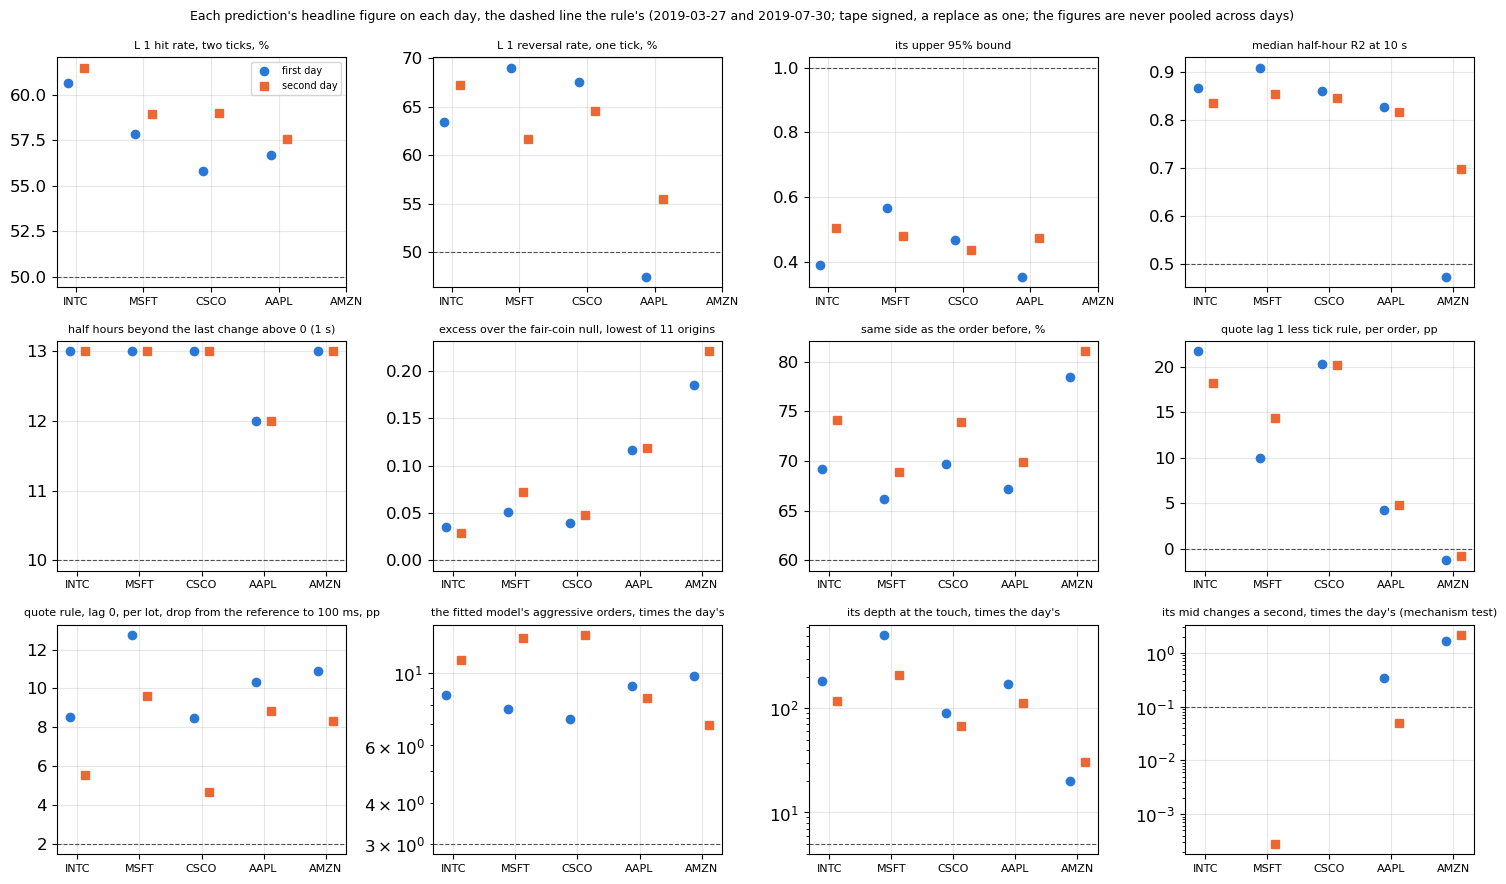

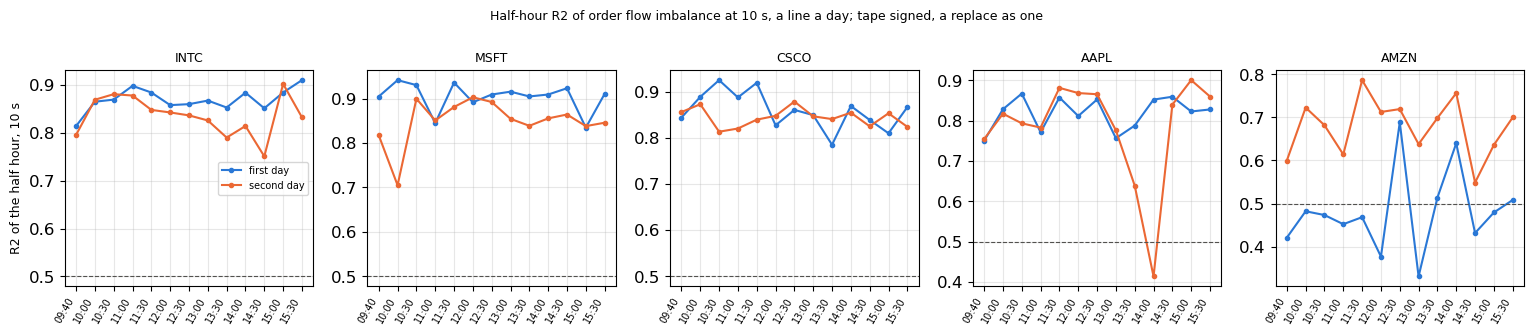

In [46]:
# Section 6: each prediction's headline figure on the first day beside the same figure on the second, and the figures
# that draw them. Needs this section's machinery, run and verdicts. With the data absent it prints one line. The two
# days are side by side and never pooled: no mean, no sum and no test across them, and nothing is retuned between
# them.
if two_ready():
    say(
        f'\nThe headline figure of each prediction and the three rates, {day_text(DAY)} | {day_text(SECOND_DAY)}, '
        f'session {SESSION_START} to {SESSION_END}, {convention()}.'
    )
    say(
        'A cell is the first day\'s figure, then the second\'s. A figure that a day does not give (a spread class '
        f'under {MIN_READINGS} readings, a rule that does not apply) is "-". Every figure is a stock\'s own on the day '
        'it is of; the rates are beside every figure, and the same stock\'s two days are what is compared, never two '
        'stocks. VPIN\'s V is 50 times the median of each stock-day\'s own first 200 fills, so VPIN\'s levels are not '
        'comparable across the two days (V and the fills a bucket are printed beside them); the sign of the excess '
        'over the null is, because the null uses the same fills. A stock-day that was refused by lob.itch or failed is '
        'not in this table (it is said under the section\'s run and is never replaced).'
    )
    print(two_headline_table(two_judged_first, two_judged_second, read_by_a_prediction=True).to_string())
    two_figure(two_judged_first, two_judged_second)
    two_strip_figure(two_judged_first, two_judged_second)

TODO(prose): The verdicts (the tables of the verdict cell). For each prediction, in the order of the predictions cell, the number of stocks that passed of those judged on the first day, on the second and on both days, with the stocks that held it on both named, from the last table of the cell; and, for every stock that passed on one day and not on the other, its figure beside its verdict on each day (the figures the rule read are printed under each prediction). A prediction is "held on both days" only for the stocks that passed on both, and a stock that was not judged on a day does not hold it. Say which predictions held for all five stocks on both days, which held for some, and which for none, as counts of stocks and nothing wider (never as ten confirmations, never as a count across predictions: the five stocks share each day's market factor, and a prediction that is near-certain on liquid one-tick stocks is not a test of notebook 14 by passing); no stock is said to differ from another, and no regime is named for either day.

TODO(prose): The figures beside each other (the headline table and its figure). For each prediction, the first day's figure beside the second's, stock by stock: where the second day's figure moved toward its rule's line or away from it, and how far, in the figure's own units (points, half hours, multiples). Do not average, pool or test the two days against each other; say where a stock's figure sat near its rule's line on either day, since a verdict near a threshold is as much a statement about the threshold as about the stock. Quote the three rates beside the figures (events, changes of the mid and aggressive orders a second) so that a reader can see whether the day was busier or quieter, and say nothing about why.

TODO(prose): What the second day did to the findings of sections 2 and 3 that the first day's figures had suggested: for the imbalance (hit rate, reversal rate and the one-tick lift by spread class), the queue race, order flow imbalance (the median half-hour R2 at 10 s and "beyond the last change"), VPIN (the excess at all 11 origins and the same-side share) and signing (the lag-0 check, which must have no miss on the second day or the notebook stops, and the quote rule at lag 1 against the tick rule): whether each sign or ordering that appeared on the first day appeared on the second, stock by stock. A figure near the simulator's is a description, and nothing is called a match.


Section 1 again, the tape, on 2019-07-30.

What each stock-day holds: 2019-07-30, session 09:40:00 to 15:50:00, a replace counted as one and as two, and three
tapes, as each column says.

What the session holds (rows of the frames; events of the stream, a replace counted as one and as two):
           rows     adds part cancels deletions executions replace rows events, as one events, as two aggressive orders hidden trades unsigned runs
INTC    725,546  360,160        2,719   346,554     16,113       59,944        686,210        716,182             6,875         2,138         1,436
MSFT  1,111,908  550,079        8,656   531,402     21,771       96,624      1,053,865      1,102,177            12,316         3,564         2,750
CSCO    492,995  241,334        8,967   233,869      8,825       38,672        468,924        488,260             4,165         1,710         1,329
AAPL  1,134,362  563,056        1,332   529,104     40,870      100,608      1,066,922      1,117,226            23

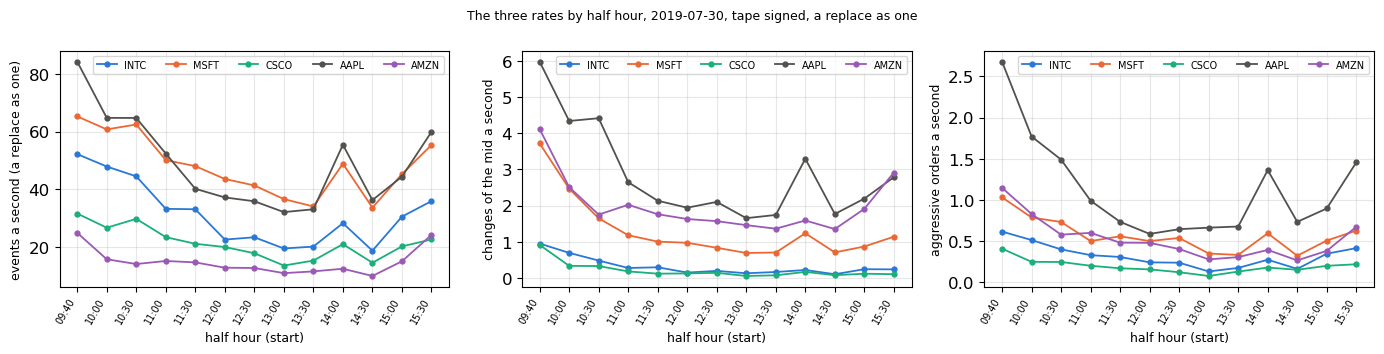


Section 2 again, the imbalance and the next move, the queue race and order flow imbalance, on 2019-07-30.

L 1, the queue imbalance at the touch: the next change of the mid against the sign of the first nonzero imbalance after
the last: 2019-07-30, session 09:40:00 to 15:50:00, tape signed, a replace as one.
Strict design (the first event that leaves the mid alone gives the reading), a next change within 30 s, by the spread at
the reading. Lifts in points over 50%, over the reversal rate (predict minus the last change) and over the better of the
two, which binds IN THE CLASS; a class under 200 readings is a count only. calls differ: the share of readings at which
the imbalance's call and the reversal call point in different directions; the hit rate and the reversal rate cannot
differ by more than that, so where it is small they are one measurement read twice and the lift over the reversal rate
is bounded by it. se: the lift's block-bootstrap standard error (1,000 draws, ASSUMING EXCHA

                one tick                                           wider                                    
            scored a run       hit %  reversal %    lift pp scored a run       hit %  reversal %     lift pp
ZI                 3,476  89.1 (0.2)  87.0 (0.3)  2.2 (0.1)        9,538  64.5 (0.1)  55.5 (0.1)   9.0 (0.2)
Hawkes ZI          2,936  90.1 (0.2)  88.3 (0.2)  1.9 (0.1)        8,780  65.6 (0.2)  56.3 (0.2)   9.3 (0.3)
MF 2008            1,300  84.3 (0.5)  82.0 (0.4)  2.3 (0.2)        3,443  60.3 (0.3)  53.4 (0.3)   6.9 (0.4)
Parlour            1,313  80.2 (0.3)  71.9 (0.6)  8.3 (0.4)        7,876  67.0 (0.2)  55.5 (0.2)  11.5 (0.3)
Informed ZI        3,696  90.6 (0.1)  88.5 (0.2)  2.1 (0.1)       12,615  65.7 (0.1)  56.4 (0.2)   9.3 (0.2)

The imbalance beyond the touch: the lift over the better baseline, by the spread at the reading: 2019-07-30, session
09:40:00 to 15:50:00, tape signed, a replace as one.
Levels 3, 5 and 10 with equal and touch weights (L 1 equal and tou

                           one tick          two ticks      three or more
INTC L 3 equal    -3.2 (rev, 3,145)   +7.3 (50, 2,871)              n = 2
     L 3 touch    +0.1 (rev, 3,145)  +10.2 (50, 2,871)              n = 2
     L 5 equal    -5.6 (rev, 3,145)   +5.6 (50, 2,871)              n = 2
     L 5 touch    +0.4 (rev, 3,145)  +10.3 (50, 2,871)              n = 2
     L 10 equal  -11.6 (rev, 3,145)   +6.1 (50, 2,871)              n = 2
     L 10 touch   +0.2 (rev, 3,145)  +10.5 (50, 2,871)              n = 2
MSFT L 3 equal   -1.1 (rev, 13,130)  +4.3 (50, 11,464)     +4.4 (50, 478)
     L 3 touch   +1.2 (rev, 13,130)  +7.2 (50, 11,469)     +6.7 (50, 478)
     L 5 equal   -3.4 (rev, 13,130)  +2.7 (50, 11,469)     +0.4 (50, 478)
     L 5 touch   +0.8 (rev, 13,130)  +6.9 (50, 11,469)     +5.2 (50, 478)
     L 10 equal  -8.0 (rev, 13,130)  +2.9 (50, 11,469)     +5.0 (50, 478)
     L 10 touch  +0.9 (rev, 13,130)  +6.8 (50, 11,469)     +6.1 (50, 478)
CSCO L 3 equal    -1.6 (rev, 1,948)   

              L 1 equal   L 1 touch   L 3 equal   L 3 touch   L 5 equal   L 5 touch  L 10 equal  L 10 touch late (T 30), L 1 inclusive L 1 inclusive touch L 10
ZI           17.3 (0.1)  17.3 (0.1)   8.4 (0.1)   8.2 (0.1)   8.3 (0.1)   8.2 (0.1)   8.2 (0.1)   8.2 (0.1)    0.000 (0.000)    10.2 (0.1)            0.0 (0.0)
Hawkes ZI    19.8 (0.3)  19.8 (0.3)  10.8 (0.2)  10.6 (0.2)  10.8 (0.2)  10.6 (0.2)  10.7 (0.2)  10.6 (0.2)    0.000 (0.000)    10.9 (0.2)            0.0 (0.0)
MF 2008      18.1 (0.2)  18.1 (0.2)  12.3 (0.2)  12.0 (0.1)  12.3 (0.1)  12.0 (0.1)  12.2 (0.1)  12.0 (0.1)    0.000 (0.000)     7.7 (0.1)            0.0 (0.0)
Parlour      52.8 (0.1)  52.8 (0.1)  40.8 (0.1)  39.5 (0.1)  40.3 (0.1)  39.4 (0.1)  40.3 (0.1)  39.4 (0.1)    0.000 (0.000)    25.9 (0.1)            0.0 (0.0)
Informed ZI  20.8 (0.2)  20.8 (0.2)  10.6 (0.1)  10.4 (0.1)  10.5 (0.1)  10.4 (0.1)  10.5 (0.1)  10.4 (0.1)    0.000 (0.000)    12.0 (0.1)            0.0 (0.0)

notebook 14, seeds 101 to 108, touch L 

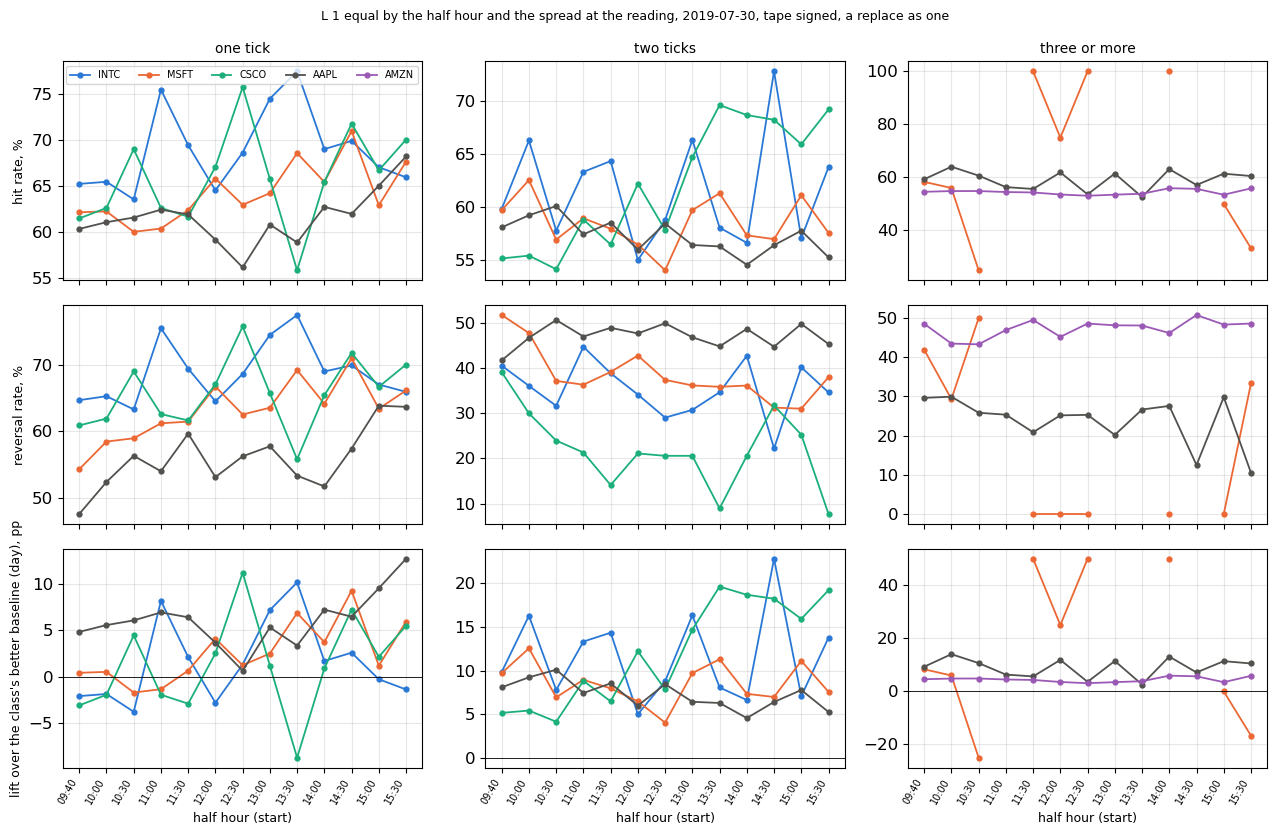


The queue race: the curve for independent queues fitted to the touch imbalance, by spread class: 2019-07-30, session
09:40:00 to 15:50:00, tape signed, a replace as one.
gain: the log-likelihood the curve gains over a constant hit rate (negative: it does worse). a (c = 1): the amplitude of
1/2 + a arctan(|I|) / (2 arctan 1); se and upper 95%: its block bootstrap (200 draws, ASSUMING EXCHANGEABLE BLOCKS), the
upper bound being the 95th percentile of the draws; a, c, both: a and c fitted together (c has no standard error: it
runs to a bound in most resamples). A class under 200 readings is a count only.
                         n hit % gain, c = 1 a (c = 1)    se upper 95% gain, a fitted a, both c, both
INTC one tick        3,145  67.4        -761      0.45  0.02      0.50             34    0.49    0.00
     two ticks       2,871  61.5          -5      0.71  0.08      0.87             18    0.54    2.71
     three or more       2     -           -         -     -         -              

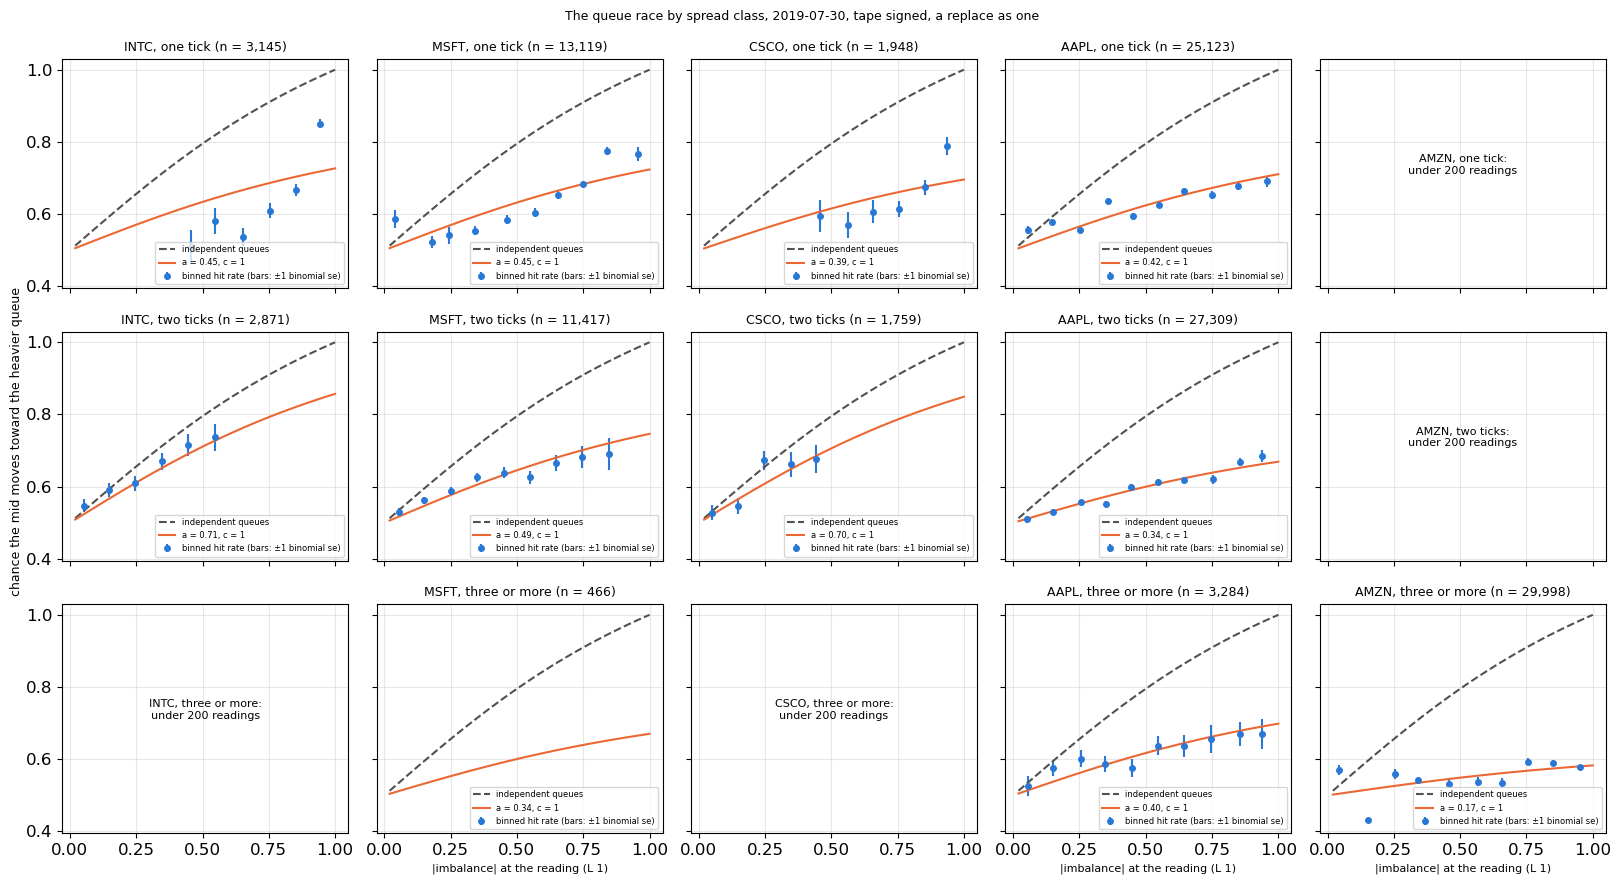


Order flow imbalance: the same-interval R2 of the mid's change on the interval's flow: 2019-07-30, session 09:40:00 to
15:50:00, tape signed, a replace as one.
One increment an event (the best-quote rule of Cont, Kukanov and Stoikov, summed in each interval). THE FIGURE is the
median of the half-hour R2s (13 half hours of the session, from 09:40:00), with its block-bootstrap standard error
(1,000 draws, ASSUMING EXCHANGEABLE BLOCKS) in brackets.
                1 s            5 s           10 s           50 s
INTC  0.717 (0.016)  0.812 (0.019)  0.836 (0.013)  0.903 (0.022)
MSFT  0.727 (0.012)  0.827 (0.016)  0.854 (0.010)  0.900 (0.024)
CSCO  0.726 (0.009)  0.812 (0.010)  0.847 (0.007)  0.895 (0.008)
AAPL  0.752 (0.020)  0.826 (0.028)  0.818 (0.029)  0.860 (0.052)
AMZN  0.577 (0.012)  0.660 (0.018)  0.699 (0.027)  0.695 (0.044)

Half hours with an R2 (of those the session touches):
     1 s 5 s 10 s 50 s
INTC  13  13   13   13
MSFT  13  13   13   13
CSCO  13  13   13   13
AAPL  13  13

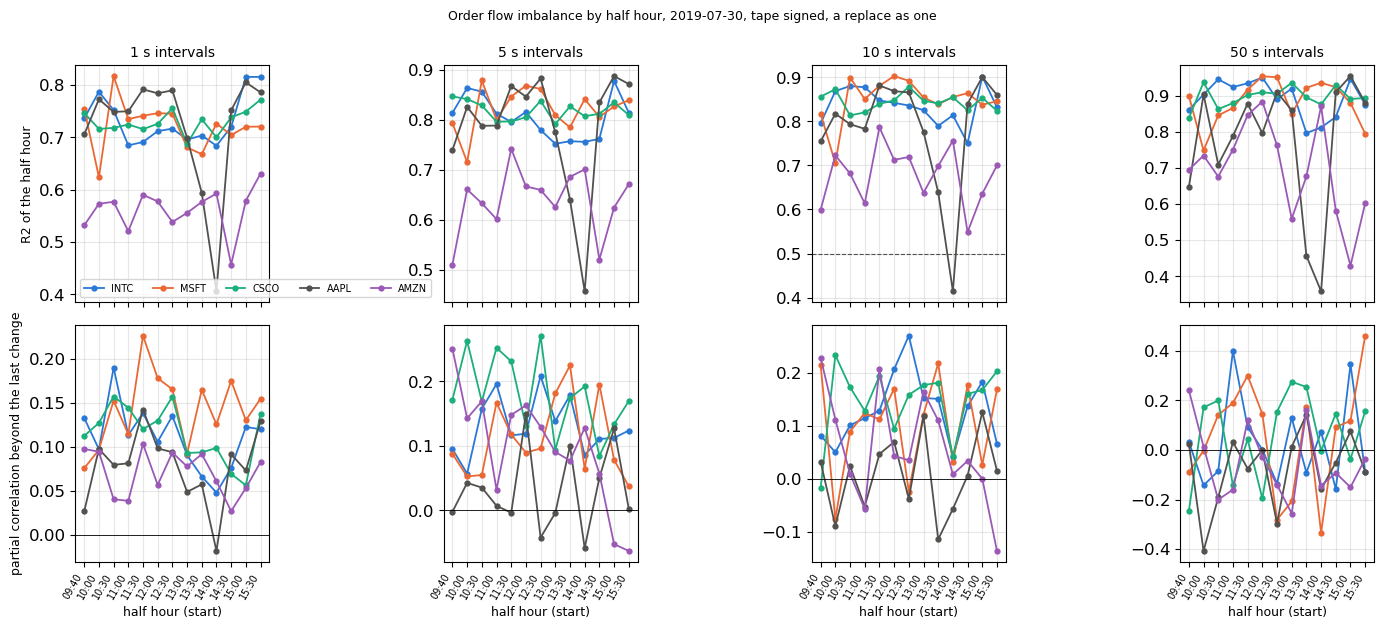

In [47]:
# Section 6: the second day's own tables, section by section, each printed by the function that printed the first
# day's (a function of a dict of results by stock and a day). This cell: the tape and the conversion's checks (section
# 1), the imbalance, the queue race and order flow imbalance (section 2's first half). Needs this section's machinery
# and run. With the data absent it prints one line.
if two_ready():
    say(f'\nSection 1 again, the tape, on {day_text(SECOND_DAY)}.')
    tape_show(two_measures, SECOND_DAY)
    tape_conversion(two_second['checks'], two_measures, SECOND_DAY)
    tape_figure(two_measures, SECOND_DAY)
    say(
        '\nSection 2 again, the imbalance and the next move, the queue race and order flow imbalance, on '
        f'{day_text(SECOND_DAY)}.'
    )
    imb_show_split(two_measures, day=SECOND_DAY)
    imb_show_beyond(two_measures, SECOND_DAY)
    imb_show_strips(two_measures, SECOND_DAY)
    imb_figure(two_measures, day=SECOND_DAY)
    imb_show_race(two_measures, SECOND_DAY)
    imb_race_figure(two_measures, SECOND_DAY)
    ofi_show(two_measures, SECOND_DAY)
    ofi_show_beyond(two_measures, SECOND_DAY)
    ofi_figure(two_measures, SECOND_DAY)


Section 2 again, VPIN, order-to-trade ratios and resilience, on 2019-07-30.

VPIN against its own nulls: 2019-07-30, session 09:40:00 to 15:50:00, tape signed, a replace as one.
displayed executions and the hidden ones a displayed run signs; the unsigned hidden volume never reaches it. V = 50 x the median of the first 200 fills, 50 buckets a window, bucket-weighted level over the buckets closed in the session; nulls on the same fills, 200 draws, seed 1.
                                                                      level fair coin (sd) excess over coin coin sds  shuffled (sd) excess over shuffled shuffled sds level, time-weighted
stock rule                                                                                                                                                                                
INTC  true sides                                                      0.432  0.381 (0.010)           +0.051     +5.0  0.384 (0.012)               +0.048         +4.2  

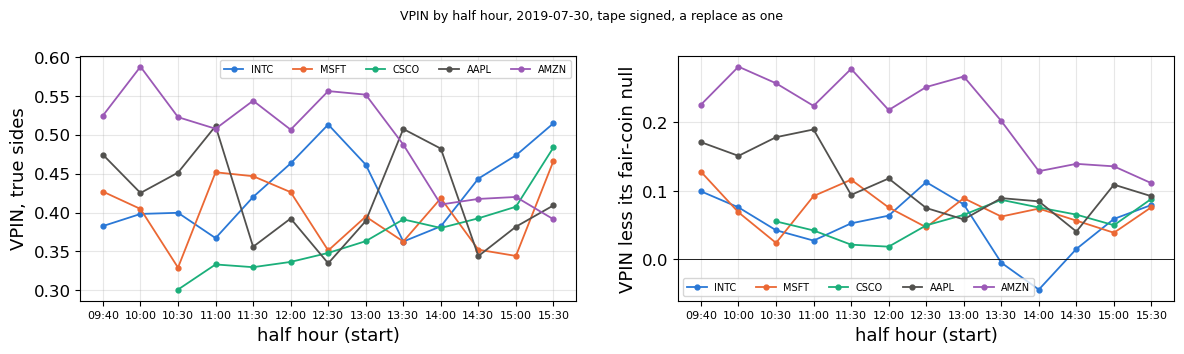


Order-to-trade ratios, messages per aggressive order: 2019-07-30, session 09:40:00 to 15:50:00, tape signed, a replace
as one.
The session's ratio of sums, a replace as one message and as two; "se (blocks)" is a block bootstrap over the half hours (1,000 draws) ASSUMING EXCHANGEABLE BLOCKS (they are not) and "strip se" the half-hour values' own.
     aggressive orders messages, a replace as one replaces OTR, a replace as one se (blocks) strip se OTR, a replace as two TTO, as one TTO, as two
INTC             6,875                    686,210   29,972                  99.8         3.6      4.7                 104.2      0.0359      0.0328
MSFT            12,316                  1,053,865   48,312                  85.6         3.3      3.4                  89.5      0.0348      0.0291
CSCO             4,165                    468,924   19,336                 112.6         5.5      6.7                 117.2      0.0230      0.0201
AAPL            23,971                  1,066,922   50,304 

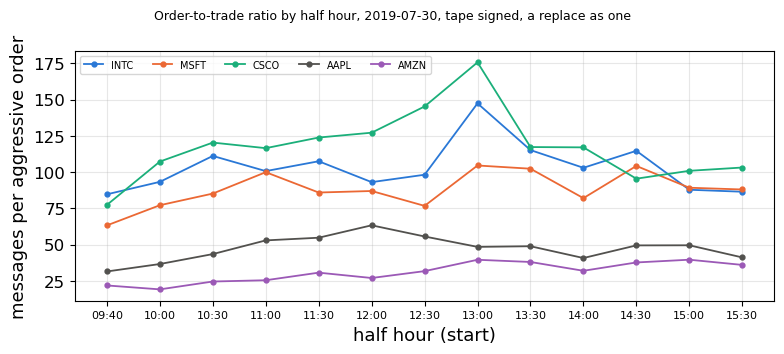


Resilience: recovery of the depth within K ticks of the touch: 2019-07-30, session 09:40:00 to 15:50:00, tape signed, a
replace as one.
K = 3 ticks, a tick a cent: "K in spreads" is K over the stock's median spread. An episode begins when a take or a cancel leaves the depth at the K prices from the side's best quote below half its baseline (the median of the last 100 unit samples); it keeps those prices as its anchor and ends recovered when the depth there is back at 0.9 of the baseline, or abandoned when the best quote has moved more than K ticks from the anchor or the side is empty ("abandoned at once": the share of the abandoned that ended in the instant they began). Onset "below" is the dashboard's; "crossing" counts only the falls through the line. The standard errors are a block bootstrap ASSUMING EXCHANGEABLE BLOCKS. Times are seconds.

Onset below the line:
     K in spreads episodes abandoned abandoned at once recovered a second median recovery (s) p90 (s) abandoned se median

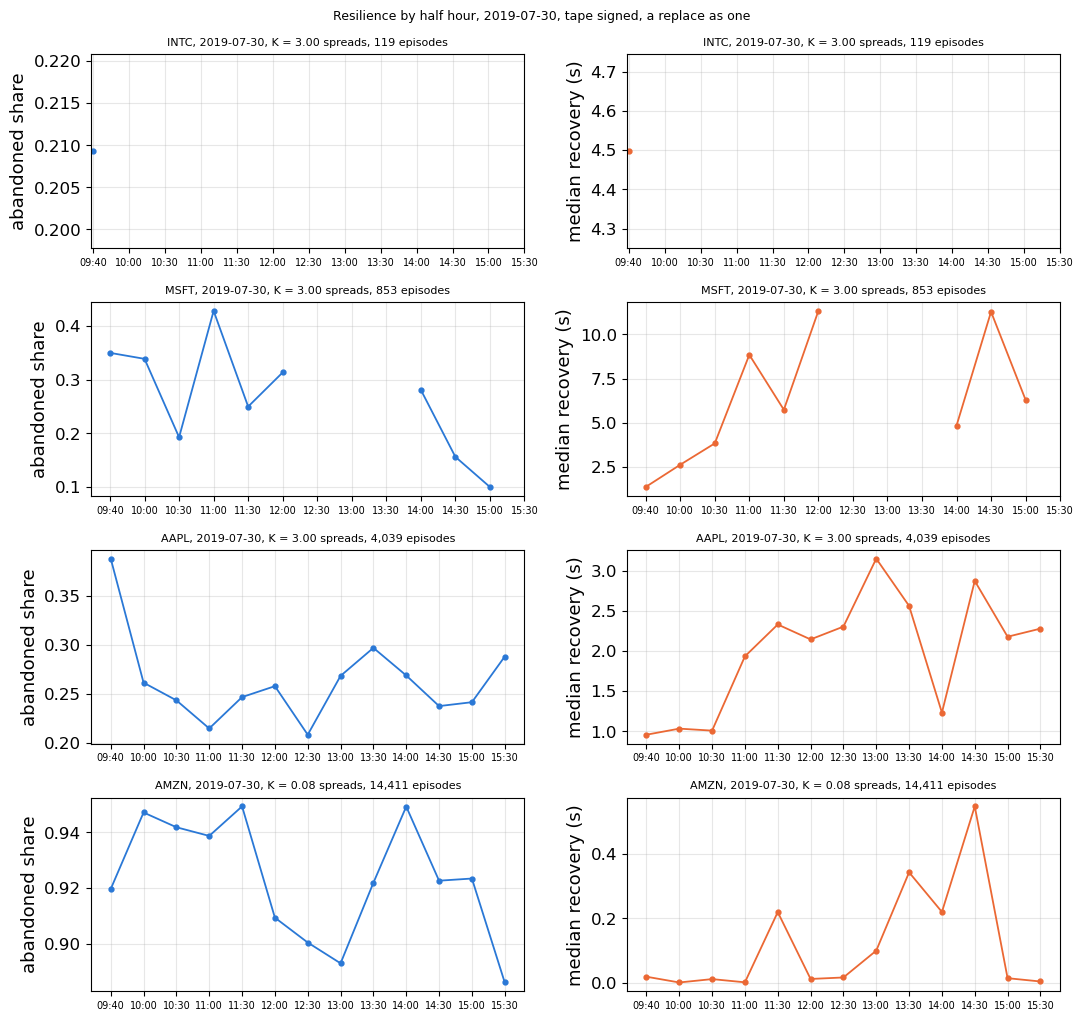


Section 3 again, what is the estimator's, on 2019-07-30.

The look-ahead trap: the sample of the imbalance paired with the change over the same unit and the next: 2019-07-30,
session 09:40:00 to 15:50:00, tape signed, a replace as one.
Sign agreement of the once-a-unit sample with the change of the mid, percent of the units with a change and a reading;
50% is what a sample that knows nothing gives.
                same unit: n same unit % next unit: n next unit % next minus same, pp
INTC L 1 equal         1,807        55.9        1,808        80.4                24.5
     L 10 touch        1,816        57.5        1,815        77.6                20.1
MSFT L 1 equal         6,895        44.4        6,922        68.6                24.2
     L 10 touch        7,122        45.0        7,121        67.7                22.7
CSCO L 1 equal         1,524        44.0        1,516        83.5                39.5
     L 10 touch        1,537        48.4        1,536        81.9                

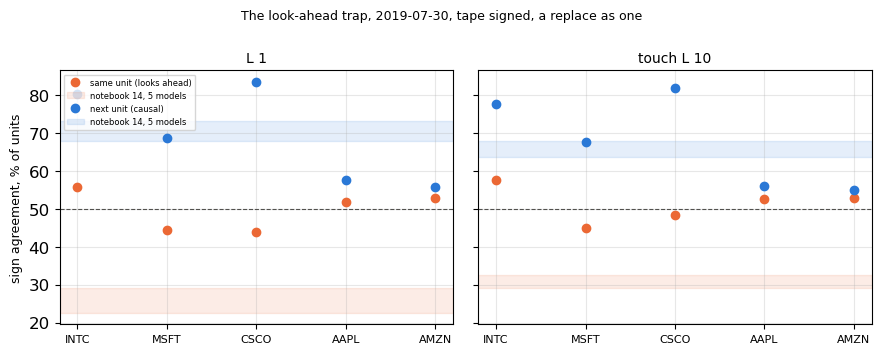


Signing accuracy, per aggressive order, % of displayed executions: 2019-07-30, session 09:40:00 to 15:50:00, tape signed
and none, a replace as one.
rows: the tape the figure is on ("signed": the stream as it is; "none": the same without the hidden executions, which changes the tick rule's price sequence); hidden and unsigned shares are of the shares executed in the session.
             tick rule quote rule, lag 0 quote rule, lag 1 quote rule, lag 5  orders hidden % of shares unsigned % of shares
stock tape                                                                                                                  
INTC  signed     70.43             97.83             88.68             76.81   6,875              10.52                 6.53
      none       69.13             97.82             88.67             76.79   6,875              10.52                 6.53
MSFT  signed     70.63             98.26             84.98             70.72  12,316              16.00                12

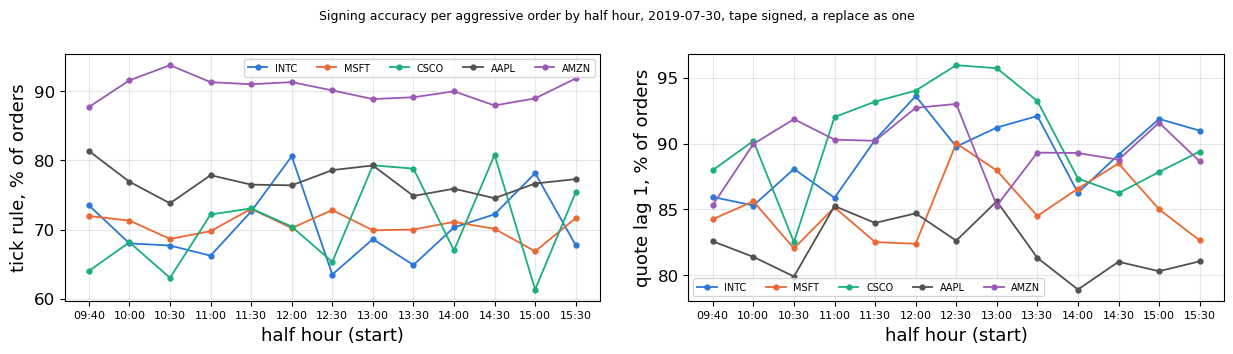


The prediction on signing: 2019-07-30, session 09:40:00 to 15:50:00, tape signed, a replace as one.
rule: the quote rule at lag 0 is exact (no miss at all: 100.00% is not enough) on displayed executions at their resting price, and the quote rule at lag 1 is at least as accurate per aggressive order as the tick rule.
INTC    passed: lag 0 at the resting price: 0 of 15,918 fills, 0 of 6,717 orders and 0.0000% of the lots missed; per order quote lag 1 88.68%, tick 70.43%
MSFT    passed: lag 0 at the resting price: 0 of 21,424 fills, 0 of 12,043 orders and 0.0000% of the lots missed; per order quote lag 1 84.98%, tick 70.63%
CSCO    passed: lag 0 at the resting price: 0 of 8,662 fills, 0 of 4,025 orders and 0.0000% of the lots missed; per order quote lag 1 89.68%, tick 69.42%
AAPL    passed: lag 0 at the resting price: 0 of 40,323 fills, 0 of 23,545 orders and 0.0000% of the lots missed; per order quote lag 1 81.86%, tick 77.05%
AMZN    not passed: lag 0 at the resting price: 0 of 14,251 

In [48]:
# Section 6: the second day's own tables, continued: VPIN, order-to-trade ratios and resilience (section 2's second
# half), the look-ahead trap, the rules that sign trades and bulk volume classification (section 3). Each is printed
# by the function that printed the first day's. Needs this section's machinery and run. With the data absent it prints
# one line.
if two_ready():
    say(f'\nSection 2 again, VPIN, order-to-trade ratios and resilience, on {day_text(SECOND_DAY)}.')
    vpin_report_levels(two_measures, SECOND_DAY)
    vpin_report_origins(two_measures, SECOND_DAY)
    vpin_report_strips(two_measures, SECOND_DAY)
    otr_report(two_measures, SECOND_DAY)
    resil_report(two_measures, SECOND_DAY)
    resil_report_strips(two_measures, SECOND_DAY)
    say(f'\nSection 3 again, what is the estimator\'s, on {day_text(SECOND_DAY)}.')
    trap_show(two_measures, SECOND_DAY)
    trap_figure(two_measures, SECOND_DAY)
    est_report_signing(two_measures, SECOND_DAY)
    est_report_apart(two_measures, SECOND_DAY)
    est_report_bvc(two_measures, SECOND_DAY)

In [49]:
# Section 6: the second day's own tables, continued: the ladder (section 4: the reference and three rungs, as for the
# reported stocks on the first day) and the calibration (section 5: the day's fit and the numbers its two tests read).
# The exploration's rungs and the sweep are not run on the second day, which reads the five reported stocks only. Needs
# this section's machinery and run. With the data absent it prints one line.
if two_ready():
    two_ladder = two_second['ladder']
    two_where = f'{convention("none")}, session {SESSION_START} to {SESSION_END}, unit {UNIT:g} s'
    say(
        f'\nSection 4 again, the ladder, on {day_text(SECOND_DAY)}: the reference and the rungs of {LAD_FIRST} and '
        f'{LAD_LAST} ms and of {LAD_LAST} ms with the trades {LAD_PLUS:+d} ms (a bound, not a venue\'s model); '
        f'{two_where}.'
    )
    print('\nRates a second on each rung:')
    print(shown(lad_rates_table(two_ladder), {'gross OFI a second': ',.0f'}))
    print('\nOrder flow imbalance on each rung, the median half-hour R2 (the figure) at each interval:')
    print(shown(lad_ofi_table(two_ladder)))
    print('\nThe quote rule and the tick rule per lot on each rung:')
    two_signing_frame = lad_signing_table(two_ladder)
    print(
        shown(
            two_signing_frame, {c: '.2f' for c in two_signing_frame.columns if two_signing_frame[c].dtype.kind == 'f'}
        )
    )
    print(f'\nThe ladder\'s prediction on the second day. Rule: {PREDICTIONS["ladder"].rule}.\n')
    print(shown(lad_inputs_table(two_ladder, judge=True)))
    two_cal = two_second['calibration']
    cal_heading('The calibration on the second day: calibrate_lobster for the day', two_cal, SECOND_DAY)
    print(shown(cal_day_table(two_cal)))
    cal_heading('The numbers the calibration\'s two tests read, and their verdicts', two_cal, SECOND_DAY)
    two_summary = pd.DataFrame({stock: cal_summary(detail) for stock, detail in two_cal.items()}).T
    print(
        shown(
            two_summary,
            {'b_at_bound': '', 'aggressive_ratio': '.1f', 'depth_ratio': '.1f', 'mid_changes_ratio': '.3f'}
            | {'spread_ratio': '.3f', 'cancel_ratio': '.1f'},
        )
    )
    print(
        '(cancel_ratio is the estimator\'s window effect, a half hour fitted as a file against the day\'s fit, '
        'and is in no verdict.)'
    )
    for two_test in ('calibration', 'calibration\'s mechanism'):
        print(f'\nRule: {PREDICTIONS[two_test].rule}.')
        for two_stock, two_one in two_judged_second.items():
            two_verdict = PREDICTIONS[two_test].judge(two_one)
            print(f'{two_stock:<8}{two_verdict.status}: {two_verdict.detail}')


Section 4 again, the ladder, on 2019-07-30: the reference and the rungs of 1 and 100 ms and of 100 ms with the trades
+50 ms (a bound, not a venue's model); tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.

Rates a second on each rung:
                  events a second mid changes a second aggressive orders a second gross OFI a second events below reference mid changes below reference
INTC reference             30.910                0.301                      0.310              3,346                   0/13                        0/13
     batch 1 ms            11.094                0.155                      0.310              1,928                  13/13                       13/13
     batch 100 ms           4.394                0.106                      0.310              1,244                  13/13                       13/13
MSFT reference             47.471                1.260                      0.555              2,360                   0/13            

**What this cannot show.**

- *That a finding is general.* Two days of five stocks are two draws of a market factor that the five stocks share. A prediction held on both days by all five stocks is a finding about these five stocks on these two days, and a count of stocks that pass is a count over stocks that move together and not five independent trials. No regime is named for either day, and no stock is said to differ from another.
- *Anything from pooling the days.* The two days are printed side by side and never averaged, summed or tested against each other: they are not one sample, and a standard error across two days would be a number about nothing. A day's own uncertainty is the thirteen half-hour values of each figure and the block bootstrap, which assumes that the half hours are exchangeable and they are not.
- *That a threshold is right.* The rules were chosen on two stocks (and the simulator) before the reported stocks were read, and were not changed for the second day. A figure near a rule's line on either day is as much a statement about the line as about the stock, and every verdict is printed with the figures it read for that reason. A `not judged` is not a pass and is not a failure: it is a rule that did not apply or a class with too few readings.
- *That the second day was read by the code that was audited, unless the deviations below say it was.* The freeze records a hash of every code cell and of `lob/itch.py`, `lob/feeds.py` and `lob/ladder.py`; a code cell changed after it is listed in the limitations with its figures before and after.
- *The exploration's rungs and sweep.* The second day runs the reference and three rungs of the ladder and the calibration of each reported stock; the sweep over batch length and the other rungs were run on NVDA and CMCSA only, on the first day, as what the code was built on, and are not read on the second.
- *Anything about NVDA or CMCSA.* They are not read on the second day, and nothing here is a result about them on either.

TODO(prose): Section 6 in a sentence or two: for each of the ten tests, by how many of the stocks judged on both days it was held, and which were not, as counts a prediction at a time (no count across predictions) and with the figures beside them; and that two days of five stocks say what they say about these days and these stocks.

## Section 7: Conclusions and limitations

The cell below prints, from what the sections above kept, the notebook's headline figures section by section (each stock's figure on the first day beside the same stock's on the second, never pooled), then every prediction's verdict on each stock and each day with the counts of stocks that passed on the first day, on the second and on both, and then the time and memory each part of the run took. It calls `check_namespace()` first: a cell that had assigned to a name of the setup cell would have changed what every figure above was computed with, and the notebook stops there and says so.

The conclusions that follow are written after the run, from these printed figures, and say what the notebook may say about these five stocks on these two days and what it may not say about a market. The limitations, which do not depend on the outputs, follow them.

In [50]:
# Section 7, what the notebook left, in one place. Needs the whole notebook before it: section 6's cells (81 to 83) and,
# through them, the first day's results of sections 1 to 5. Prints, in this order: the namespace check; the notebook's
# headline figures section by section, each stock's figure on the first day beside its figure on the second (never
# pooled); every prediction with its verdict on each stock and each day, and the counts; and the time and memory each
# part of the run took. Names this cell makes are prefixed end_. With either day's data absent it prints one line.
if two_ready():
    print(check_namespace())

    # 1. the headline figures, section by section
    say(
        f'\nThe headline figures, a section at a time: {day_text(DAY)} | {day_text(SECOND_DAY)} in each cell, session '
        f'{SESSION_START} to {SESSION_END}, {convention()}. The days are side by side and are never averaged.'
    )
    for end_section in dict.fromkeys(row[0] for row in TWO_HEADLINES):
        print(f'\nSection {end_section}:')
        print(two_headline_table(two_judged_first, two_judged_second, sections=(end_section,)).droplevel(0).to_string())
        if end_section == '2 resilience':
            print(
                '  K is fixed in ticks, a different reach in each stock\'s spreads: no stock\'s figure is set against '
                'another\'s.'
            )

    # 2. every prediction, a stock and a day, and the counts
    say('\nEvery prediction: its verdict on each stock and each day (P passed, F not passed, - not judged).')
    end_marks = {PASSED: 'P', FAILED: 'F', UNJUDGED: '-'}
    end_grid = pd.DataFrame(
        {
            (stock, name): table[stock].map(end_marks)
            for stock in two_table_first.columns
            for name, table in (('first day', two_table_first), ('second day', two_table_second))
        }
    )
    print(end_grid.to_string())
    say('\nThe figures each rule read, stock by stock and day by day:')
    two_show_verdicts(two_verdicts_first, two_verdicts_second, two_judged_first, two_judged_second)
    say('\nStocks that passed, of those judged, on the first day, on the second and on both (held on both days):')
    print(two_held.to_string())

    # 3. the time and memory of each part
    end_log = pd.DataFrame(RUN_LOG, columns=['part', 'stock', 'day', 'seconds', 'peak MB'])
    end_wall = pd.DataFrame(WALL_LOG, columns=['part', 'day', 'stocks', 'workers', 'wall seconds'])
    end_parts = (
        end_log.groupby(['part', 'day'])
        .agg(
            **{
                'stock-days': ('stock', 'count'),
                'core-minutes': ('seconds', lambda x: x.sum() / 60),
                'peak MB': ('peak MB', 'max'),
            }
        )
        .join(end_wall.groupby(['part', 'day']).agg(**{'wall minutes': ('wall seconds', lambda x: x.sum() / 60)}))
    )
    end_parts.index = end_parts.index.map(lambda key: (key[0], day_text(key[1])))
    say(f'\nThe time and the memory of each part of the run (run_stocks: a worker for each stock, {WORKERS} at once):')
    print(shown(end_parts, {'core-minutes': '.1f', 'wall minutes': '.1f', 'peak MB': ',.0f'}))
    print(
        f'\nIn all: {end_log.seconds.sum() / 60:.1f} core-minutes and {end_wall["wall seconds"].sum() / 60:.1f} '
        f'minutes of wall time in run_stocks; the largest worker peaked at {end_log["peak MB"].max():,.0f} MB, so '
        f'{WORKERS} workers at once hold about {WORKERS * end_log["peak MB"].max() / 1e3:,.1f} GB. (Section 0\'s '
        'eight runs of the simulator are not in this log, which is of the functions that run_stocks ran.)'
    )
    end_seconds = pd.DataFrame(
        {(day_text(day), stock): result['seconds'] for (day, stock), result in MEASURED.items()}
    ).T
    say('\nSeconds of each part of measure (frames, the pass, the studies, the grouping sensitivity), a stock-day:')
    print(shown(end_seconds, dict.fromkeys(end_seconds.columns, '.1f')))

291 names of the setup cell are as it defined them.

The headline figures, a section at a time: 2019-03-27 | 2019-07-30 in each cell, session 09:40:00 to 15:50:00, tape
signed, a replace as one. The days are side by side and are never averaged.

Section 1 tape:
                                         INTC           MSFT           CSCO           AAPL           AMZN
events a second                 57.54 | 30.91  86.37 | 47.47  44.86 | 21.12  78.73 | 48.06  49.51 | 14.52
mid changes a second            0.515 | 0.301  2.899 | 1.260  0.463 | 0.192  6.246 | 2.763  3.808 | 1.913
aggressive orders a second      0.425 | 0.310  1.121 | 0.555  0.434 | 0.188  1.481 | 1.080  0.684 | 0.505
time at one tick, %               99.8 | 99.5    89.8 | 79.9    99.6 | 99.2    20.7 | 54.2      0.0 | 0.0
hidden, % of executed shares       8.6 | 10.5     9.6 | 16.0    11.2 | 15.5    11.1 | 14.5    25.6 | 26.3
unsigned, % of executed shares      6.6 | 6.5     6.6 | 12.6     8.4 | 12.8     8.3 | 10.0    18.2 | 1

                                                         INTC         MSFT           CSCO         AAPL         AMZN
messages per aggressive order, a replace as one  135.2 | 99.8  77.1 | 85.6  103.4 | 112.6  53.2 | 44.5  72.4 | 28.8

Section 2 resilience:
                                                   INTC           MSFT           CSCO           AAPL             AMZN
reach, in the stock's own median spreads    3.00 | 3.00    3.00 | 3.00    3.00 | 3.00    1.50 | 3.00      0.06 | 0.08
episodes                                       66 | 119      907 | 853        82 | 69  8,792 | 4,039  32,085 | 14,411
abandoned share of ended episodes         0.182 | 0.193  0.260 | 0.295  0.110 | 0.188  0.315 | 0.272    0.918 | 0.926
  K is fixed in ticks, a different reach in each stock's spreads: no stock's figure is set against another's.

Section 3 signing:
                                                                 INTC             MSFT             CSCO             AAPL             AMZN
quote

TODO(prose): The conclusions, written after the run from the figures of the cell above and of the sections before it. For each of the ten tests (the hit rate, the reversal rate, the one-tick lift, the queue race, order flow imbalance, VPIN, signing, the calibration, the calibration's mechanism and the ladder): the stocks that passed on the first day, on the second and on both, as counts of the stocks judged, with the figure of each stock beside its verdict where it sits near its rule's line; and what that says about notebook 14's finding it was written from: whether the simulator's sign or ordering appeared on these five stocks on these two days (not for the rules the predictions cell calls near-certain on liquid one-tick stocks: there a pass is not a test of notebook 14's finding; and not for a one-tick verdict on a stock at one tick less than half the time, nor for a verdict printed as `not judged`, which is said as that and as why: refused by `lob.itch`, a class too small, a rule that does not apply). Nothing is called a match, and no figure is "the market's".

TODO(prose): Which of notebook 14's findings were the simulator's and which the estimator's, from sections 2 and 3: the findings that appeared on real books (said as counts of stocks and days) and those that did not; the identities that held on any stream (the lag-0 quote rule at the resting price, which had no miss on any stock on both days, or the notebook would have stopped: it is a check of the conversion and is evidence of nothing else; the look-ahead trap, which is a property of a join; bulk volume classification, which reads the changes of the mid and not the flow).

TODO(prose): What a price-level feed loses (section 4) and what the model would need to look like a real day (section 5), each in a sentence or two, as what these five stocks on these two days showed, with no direction claimed for feeds in general and no fitted set offered as a preset: the ladder's verdict count and the calibration's, and the facts that the fitted model did and did not reproduce.

TODO(prose): What the notebook may not say, restated once: that the simulator matches a market, that two stocks differ, that a pooled figure is a stock's, that VPIN is informed trading, or anything about NVDA or CMCSA as a result; and the time the run took (the last table of the cell above: core-minutes, wall time and the memory of a worker).

### Limitations

These do not depend on the outputs above, and each holds whatever the figures turned out to be.

- *One day, and then one more.* Everything in sections 1 to 5 is five stocks on one day, 2019-03-27, and section 6 is the same five stocks on one more, 2019-07-30. Two days are two draws of the market's day; they say nothing about how often a finding holds, in what kind of market, or on any other day, and no regime is named for either. A prediction held on both days is a statement about these two days.
- *Five stocks that share a day's market factor.* The five stocks were named before their order flow was read, and they are five large Nasdaq stocks that move together within a day. A count of stocks that pass is not a count of independent trials, a spread across stocks is a spread and is never called a standard error, and no two stocks are said to differ. Nothing is said about a small or a thinly traded stock, or about any stock outside the five.
- *Half-hour blocks that are not exchangeable.* The uncertainty within a day is the thirteen half-hour values of each figure and a block bootstrap of the half hours. The bootstrap assumes the half hours are exchangeable, and they are not: the first holds the open's burst at 1.3 to 1.8 times the day's message rate in the stocks the design was reviewed on, and the first and last half hours of the session are twenty minutes. Its standard error is printed beside the strip's own and is never the uncertainty of a stock.
- *Hidden volume is counted and not signed.* Trades against non-displayed orders carry a side byte that is not the aggressor's, so a hidden execution inside a displayed run takes that run's aggressor and a run of hidden executions alone stays unsigned. The hidden and the unsigned shares of the executed shares are printed beside every flow figure, no accuracy "against the true side" includes unsigned volume, and nothing here says who the aggressor of that volume was.
- *The reach of resilience is fixed in ticks.* K is three ticks, a different distance in each stock's own spreads, so resilience figures are each stock's own with its reach in spreads printed beside them; no resilience figure is compared between stocks, and a cancel rate or a refill rate read from them is not a property of a stock.
- *A calibration of one model.* Section 5 fits one model, `MikeFarmer2008Model`, to a day of each stock by maximum likelihood one part at a time, and reports where the fitted model fails: it has one order size, one cancellation hazard, one symmetric price law, Poisson arrivals, no hidden orders or replaces, and a stationary day. It says what that model would need to look like the day on average and not that any model looks like a real day; a fit at its bound is a statement about the likelihood and not a value; and no fitted set is offered as a preset.
- *What the ladder is and is not.* Section 4 degrades one exchange's order-by-order stream by deterministic rules (one event a changed level, batches of 1, 50 and 100 ms, trades shifted by a constant) and measures the same collectors on each. It is not a model of any venue's feed: the trades keep their true aggressor, grouping and nanosecond time on every rung, the shifted rungs are a bound and not a model, only the displayed tape is read, resilience and the order-to-trade ratio are not run on a rung, and the sweep over batch length is shown for the two exploration stocks only. Nothing in it is a direction for feeds in general, and no batched one-tick lift is a figure of any feed.
- *Thresholds chosen on two stocks.* The ten rules of the predictions cell were written from NVDA, CMCSA and the simulator before the reported stocks were read (some were changed on the judgment reader's advice before the freeze, which that cell lists); they are not shown to be the right thresholds, and a figure near one on a stock is as much a statement about the threshold as about the stock.
- *The simulator is not shown to match a market.* Notebook 14's figures are set beside the real ones to show what is compared and with what spread of its own; a figure near the simulator's is a description, and the section 0 reproduction shows that the imbalance, order flow imbalance and signing collectors give notebook 14's own figures on the simulator's own stream (VPIN, resilience and the order-to-trade ratio are not reproduced there), not that either describes a market.
- *A measurement and not a strategy.* There is no backtest, no cost model, no P&L and no queue position here, and nothing is said about toxicity against a truth or the informed share; VPIN measures how often a buy follows a buy at the scale of a bucket.
- *The conversion is checked against separate decoders on the two exploration stocks only.* The touch after every message was compared with two decoders written separately from `lob.itch`: it agrees across the three at every row of NVDA and, on CMCSA, across `lob.itch` and one other; both are exploration stocks and no reported stock was checked this way; for the reported stocks the notebook prints the conversion's own counts (every one required to be 0), which say the replayed book followed ITCH's rules and not that it is the exchange's book.
- *Downloaded data is untrusted input.* The notebook hands paths to `lob.itch`, which validates; no cell evaluates anything from a file, and the data is not in the repository.
- *What the conclusions may not say, whatever the run prints.* (1) That the hit rate, the reversal rate and the lift at one tick are separate confirmations, or that the imbalance beats the reversal rate at one tick: at one tick they are one measurement read three ways. (2) Any count across predictions, or "5 of 5 on both days" as ten confirmations. (3) That the pass of a near-certain rule tests notebook 14: the queue race's a under 1, the VPIN excess, order flow imbalance on stocks at one tick and the calibration's ratios. (4) That the simulator was wrong about signing on a stock whose mid changes a second lie outside the simulator's range (section 0 prints the simulator's rates a unit). (5) Any one-tick verdict as describing a stock that is at one tick less than half the time: it describes those states only. (6) A cancel-rate ratio as the stock's, or the calibration as having predicted anything beyond the model's structure. (7) A VPIN pass without its null standard deviations, or VPIN levels compared across days without V. (8) The ladder's lift, bulk volume classification, rates or sweep as results on the five, or any direction for feeds in general. (9) The lag-0 check as evidence of anything except the conversion.
- *A stock-day that is refused is reported, not replaced.* `lob.itch` refuses a stock-day it cannot read as a book (a halt, a broken trade, an unpaired non-printing execution, a touch off the cent grid), and a stock-day can fail in the notebook's own run. Either is printed with its reason, is `not judged` on every test, and is left out of every table; no other stock or day stands in for it, and the other stocks are judged as written.
- *The cancel-rate ratio is the estimator's window.* Section 5 prints it, and it is in no verdict: it compares a half hour fitted as a file of its own with the day's fit, says what that estimator does with a window, and says nothing about a stock's cancel rate.

**Deviations from the frozen code.** None. (A code cell changed after the freeze is entered here, with its figures before and after.)